<div style="text-align: center; background: #000; padding: 20px 10px; border-radius: 15px; box-shadow: 0 10px 25px rgba(0,0,0,0.7); font-family: 'Segoe UI', sans-serif; color: white;">

  <div style="position: relative; width: 100%; margin: 0 auto 10px auto;">

<img src="https://i.postimg.cc/QtK78P7J/images.jpg" 
     alt="Metro Interstate Traffic Volume Prediction"
     style="
     display: block;
     width: 100%;
     height: auto;
     border-radius: 10px;
     box-shadow: 0 0 10px #666;
     ">


  </div>

</div>

[1. Metadata](#1)<br>
[2. Exploratory Data Analysis](#2)<br>
[3. Data Visualization](#3)<br>
[4. Data Cleaning & Feature Engineering](#4)<br>
[5. Linear Regression](#5)<br>
[6. Weather Groups — Does Removing the Weather Labels Matter?](#6)<br>
[7. Random Forest](#7)<br>
[8. XGBoost & LightGBM](#8)<br>
[9. Hyperparameter Tuning + Model Evaluation](#9)<br>
[10. Final Model & Final Analysis](#10)<br>

In [1]:
# Install the external libraries required for data processing, visualization, statistical analysis, model training, hyperparameter tuning, and model explainability.
%pip install numpy pandas matplotlib seaborn scipy scikit-learn joblib shap optuna xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import os, json, joblib, warnings
import logging
from dataclasses import dataclass, field
from typing import Any, Dict, Tuple
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import optuna
import optuna.visualization.matplotlib as vis
from optuna.importance import FanovaImportanceEvaluator
from scipy import stats
from pandas.tseries.holiday import USFederalHolidayCalendar
from matplotlib.collections import LineCollection, PathCollection
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")


In [3]:

print("Current folder:", os.getcwd())
print("Files here:", os.listdir())

Current folder: e:\book and training\metro+interstate+traffic+volume\final_2\studybuild-machine-learning\project-02\notebooks
Files here: ['traffic-analysis.ipynb', 'traffic_volume_prediction.ipynb']


In [4]:
Traffic = pd.read_csv("../data/Metro_Interstate_Traffic_Volume.csv")
Traffic = pd.DataFrame(Traffic)
Traffic.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [5]:
Traffic.shape

(48204, 9)

In [6]:
Traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB


In [7]:
Traffic.duplicated().sum()

np.int64(17)

In [8]:
Traffic = Traffic.drop_duplicates()
Traffic.shape

(48187, 9)

<a id="1"></a>
<div style="
    text-align: center;
    background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F);
    padding: 15px;
    border-radius: 10px;
    box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35);
    font-family: 'Segoe UI', sans-serif;
">

  <h2 style="
      color: #D8D6FF;
      font-family: 'Georgia', serif;
      font-weight: bold;
      margin: 0;
      letter-spacing: 1px;
  ">
      Metadata
  </h2>

</div>

In [9]:
#profile_Traffic = ProfileReport(
 #   Traffic, title = "Metro Interstate Traffic Volume"
  #  )

#profile_Traffic.to_file("Metro Interstate Traffic Volume.html")

#profile_Traffic

<div style="
    background: #eef2f7;
    padding: 25px;
    border-radius: 15px;
    box-shadow: 0 6px 18px rgba(0,0,0,0.18);
    font-family: 'Segoe UI', sans-serif;
    color: #1f2937;
">

<h2 style="
    text-align: center;
    color: #1e3a5f;
    margin: 0 0 22px 0;
    font-family: Georgia, 'Times New Roman', serif;
    text-shadow: 1px 1px 2px rgba(0,0,0,0.12);
">
    Metro Interstate Traffic Volume — Feature Metadata
</h2>

<div style="
    display: grid;
    grid-template-columns: repeat(2, 1fr);
    gap: 14px;
">

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">holiday</div>
    <div style="color:#374151;">Indicates whether the observation occurred on a U.S. national holiday or during the Minnesota State Fair.</div>
</div>

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">temp</div>
    <div style="color:#374151;">Average temperature recorded at the time of observation, measured in Kelvin.</div>
</div>

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">rain_1h</div>
    <div style="color:#374151;">Amount of rainfall recorded during the previous hour, measured in millimeters.</div>
</div>

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">snow_1h</div>
    <div style="color:#374151;">Amount of snowfall recorded during the previous hour, measured in millimeters.</div>
</div>

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">clouds_all</div>
    <div style="color:#374151;">Percentage of cloud cover recorded at the time of observation.</div>
</div>

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">weather_main</div>
    <div style="color:#374151;">Short textual description of the prevailing weather condition.</div>
</div>

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">weather_description</div>
    <div style="color:#374151;">Detailed textual description of the prevailing weather condition.</div>
</div>

<div style="background:#ffffff; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; box-shadow:0 2px 6px rgba(0,0,0,0.08);">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">date_time</div>
    <div style="color:#374151;">Date and hour when the observation was recorded in local Central Standard Time (CST).</div>
</div>

<div style="
    background:#f4f7fb;
    border:1px solid #aebdce;
    border-left:5px solid #1e3a5f;
    border-radius:8px;
    padding:14px 18px;
    box-shadow:0 2px 6px rgba(0,0,0,0.08);
">
    <div style="color:#1e3a5f; font-weight:bold; margin-bottom:6px;">traffic_volume</div>
    <div style="color:#374151;">Hourly westbound traffic volume on Interstate 94 (I-94), recorded by ATR Station 301.</div>
</div>

</div>
</div>

<a id="2"></a>
<div style="
    text-align: center;
    background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F);
    padding: 15px;
    border-radius: 10px;
    box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35);
    font-family: 'Segoe UI', sans-serif;
">

  <h2 style="
      color: #D8D6FF;
      font-family: 'Georgia', serif;
      font-weight: bold;
      margin: 0;
      letter-spacing: 1px;
  ">
      Exploratory Data Analysis
  </h2>

</div>

In [10]:
Traffic['date_time'] = pd.to_datetime(Traffic['date_time'])


# ============================================================
# 1. Replace NaN values with U.S. federal holidays
# ============================================================

cal = USFederalHolidayCalendar()

holiday_mapping = {}

for rule in cal.rules:
    dates = rule.dates(
        Traffic['date_time'].min(),
        Traffic['date_time'].max()
    )

    for date in dates:
        holiday_mapping[date.normalize()] = rule.name


# Standardize holiday names
name_mapping = {
    "New Year's Day": "New Years Day",
    "Birthday of Martin Luther King, Jr.": "Martin Luther King Jr Day",
    "Washington's Birthday": "Washingtons Birthday"
}

holiday_mapping = {
    date: name_mapping.get(name, name)
    for date, name in holiday_mapping.items()
}


# Replace only NaN values that fall on federal holidays
mask_h = Traffic['holiday'].isna()

holiday_names = (
    Traffic.loc[mask_h, 'date_time']
    .dt.normalize()
    .map(holiday_mapping)
)

Traffic.loc[mask_h & holiday_names.notna(), 'holiday'] = (
    holiday_names.dropna().values
)

In [11]:
# ============================================================
# 2. Replace remaining NaN values with Minnesota State Fair
# ============================================================

state_fair_dates = pd.to_datetime([
    '2013-08-22',
    '2015-08-27',
    '2016-08-25',
    '2017-08-24',
    '2018-08-23'
])


mask_s = (
    Traffic['holiday'].isna() &
    Traffic['date_time'].dt.normalize().isin(state_fair_dates)
)

Traffic.loc[mask_s, 'holiday'] = 'State Fair'

In [12]:
# ============================================================
# 3. Label remaining NaN values
# ============================================================

Traffic.loc[
    Traffic['holiday'].isna(),
    'holiday'
] = 'Not Holiday'

In [13]:
Traffic['date_time'] = pd.to_datetime(Traffic['date_time'])

Traffic['year'] =Traffic['date_time'].dt.year
Traffic['month'] = Traffic['date_time'].dt.month
Traffic['day'] = Traffic['date_time'].dt.day
Traffic['hour'] = Traffic['date_time'].dt.hour
Traffic = Traffic.drop(columns=['date_time'])

Traffic.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,traffic_volume,year,month,day,hour
0,Not Holiday,288.28,0.0,0.0,40,Clouds,scattered clouds,5545,2012,10,2,9
1,Not Holiday,289.36,0.0,0.0,75,Clouds,broken clouds,4516,2012,10,2,10
2,Not Holiday,289.58,0.0,0.0,90,Clouds,overcast clouds,4767,2012,10,2,11
3,Not Holiday,290.13,0.0,0.0,90,Clouds,overcast clouds,5026,2012,10,2,12
4,Not Holiday,291.14,0.0,0.0,75,Clouds,broken clouds,4918,2012,10,2,13


In [14]:
summary = pd.DataFrame({
    "Description": [
        "Number of variables",
        "Number of observations",
        "Number of categorical variables",
        "Number of continuous variables"
    ],
    "Value": [
        Traffic.shape[1],
        Traffic.shape[0],
        Traffic.select_dtypes(include="object").shape[1],
        Traffic.select_dtypes(include=["int", "float64"]).shape[1]
    ]
})

summary

,Description,Value
0,Number of variables,12
1,Number of observations,48187
2,Number of categorical variables,3
3,Number of continuous variables,9


In [15]:
cat_vars = ['holiday','weather_main','weather_description']
con_vars = ['temp','rain_1h','snow_1h','clouds_all','year','month','day','hour','traffic_volume']

In [16]:
for col in cat_vars:
    print(
        f"Feature: {col} \n"
        f"Number of unique values: {Traffic[col].nunique()}\n"
        f"Unique values: {Traffic[col].unique()}"
)
    
    print("-"*120)

Feature: holiday 
Number of unique values: 12
Unique values: ['Not Holiday' 'Columbus Day' 'Veterans Day' 'Thanksgiving Day'
 'Christmas Day' 'New Years Day' 'Martin Luther King Jr Day'
 'Washingtons Birthday' 'Memorial Day' 'Independence Day' 'State Fair'
 'Labor Day']
------------------------------------------------------------------------------------------------------------------------
Feature: weather_main 
Number of unique values: 11
Unique values: ['Clouds' 'Clear' 'Rain' 'Drizzle' 'Mist' 'Haze' 'Fog' 'Thunderstorm'
 'Snow' 'Squall' 'Smoke']
------------------------------------------------------------------------------------------------------------------------
Feature: weather_description 
Number of unique values: 38
Unique values: ['scattered clouds' 'broken clouds' 'overcast clouds' 'sky is clear'
 'few clouds' 'light rain' 'light intensity drizzle' 'mist' 'haze' 'fog'
 'proximity shower rain' 'drizzle' 'moderate rain' 'heavy intensity rain'
 'proximity thunderstorm' 'thunderst

In [17]:
for var in cat_vars:
    print(f"\n{var}")
    print(Traffic[var].value_counts())
    print("-"*80)


holiday
holiday
Not Holiday                  46723
Labor Day                      157
Independence Day               146
Martin Luther King Jr Day      142
Washingtons Birthday           136
Thanksgiving Day               135
Memorial Day                   134
New Years Day                  131
Christmas Day                  131
Veterans Day                   120
State Fair                     120
Columbus Day                   112
Name: count, dtype: int64
--------------------------------------------------------------------------------

weather_main
weather_main
Clouds          15158
Clear           13384
Mist             5949
Rain             5672
Snow             2875
Drizzle          1820
Haze             1360
Thunderstorm     1033
Fog               912
Smoke              20
Squall              4
Name: count, dtype: int64
--------------------------------------------------------------------------------

weather_description
weather_description
sky is clear                           

In [18]:
Traffic[con_vars].describe()

,temp,rain_1h,snow_1h,clouds_all,year,month,day,hour,traffic_volume
count,48187.000000,48187.000000,48187.000000,48187.000000,48187.000000,48187.000000,48187.000000,48187.000000,48187.000000
mean,281.204995,0.334382,0.000222,49.365451,2015.512047,6.505240,15.736402,11.397742,3259.618134
std,13.338738,44.797033,0.008169,39.015213,1.893393,3.400285,8.721687,6.940373,1986.954465
min,0.000000,0.000000,0.000000,0.000000,2012.000000,1.000000,1.000000,0.000000,0.000000
25%,272.160000,0.000000,0.000000,1.000000,2014.000000,4.000000,8.000000,5.000000,1192.500000
50%,282.450000,0.000000,0.000000,64.000000,2016.000000,7.000000,16.000000,11.000000,3379.000000
75%,291.806000,0.000000,0.000000,90.000000,2017.000000,9.000000,23.000000,17.000000,4933.000000
max,310.070000,9831.300000,0.510000,100.000000,2018.000000,12.000000,31.000000,23.000000,7280.000000


<a id="3"></a>
<div style="
    text-align: center;
    background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F);
    padding: 15px;
    border-radius: 10px;
    box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35);
    font-family: 'Segoe UI', sans-serif;
">

  <h2 style="
      color: #D8D6FF;
      font-family: 'Georgia', serif;
      font-weight: bold;
      margin: 0;
      letter-spacing: 1px;
  ">
      Data Visualization
  </h2>

</div>

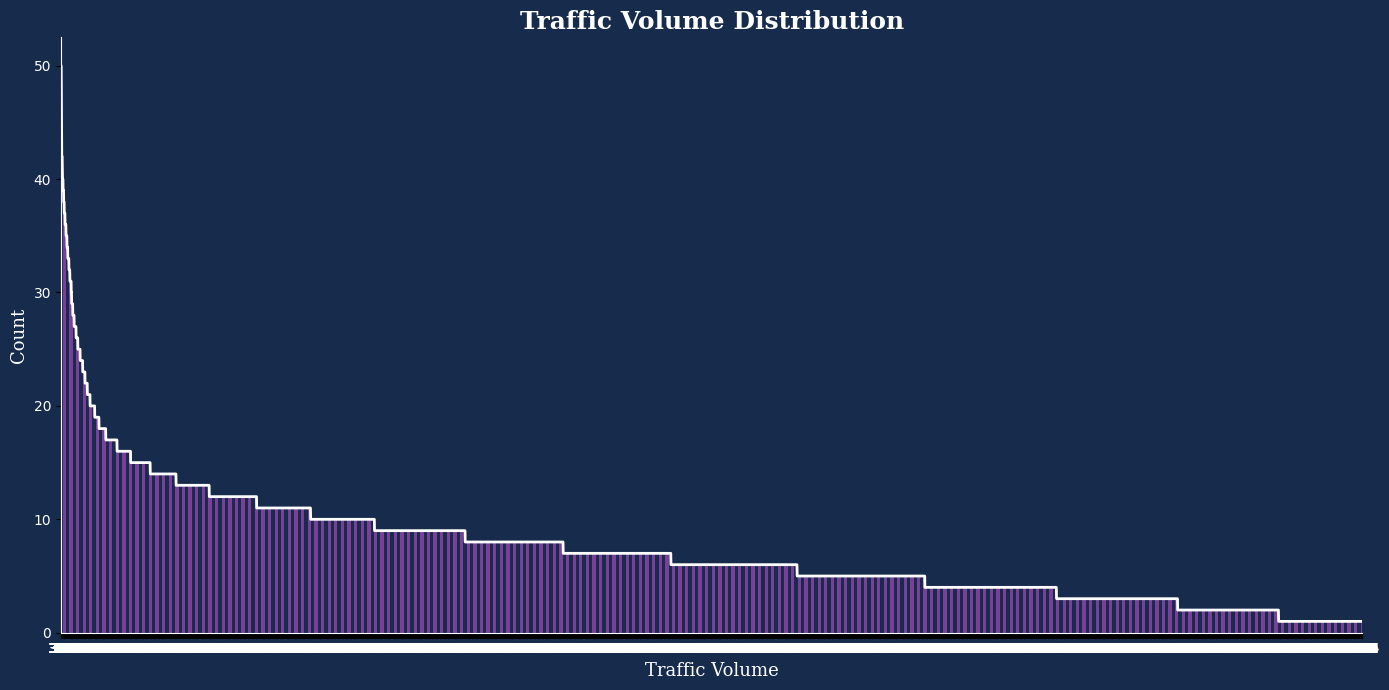

In [19]:
counts = Traffic['traffic_volume'].value_counts()

fig, ax = plt.subplots(figsize=(14, 7), facecolor='#172B4D')
ax.set_facecolor('#172B4D')

counts.plot(
    kind='bar',
    ax=ax,
    color="#7B3F98"
)

plt.plot(
    range(len(counts)),
    counts.values,
    color='white',
    linewidth=2
)

plt.xlabel(
    'Traffic Volume',
    fontsize=13,
    fontfamily='serif',
    color='white'
)

plt.ylabel(
    'Count',
    fontsize=13,
    fontfamily='serif',
    color='white'
)

plt.title(
    'Traffic Volume Distribution',
    fontsize=18,
    fontweight='bold',
    fontfamily='serif',
    color='white'
)

plt.xticks(rotation=0, color='white')
plt.yticks(color='white')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('white')
ax.spines['bottom'].set_color('white')

plt.tight_layout()
plt.show()

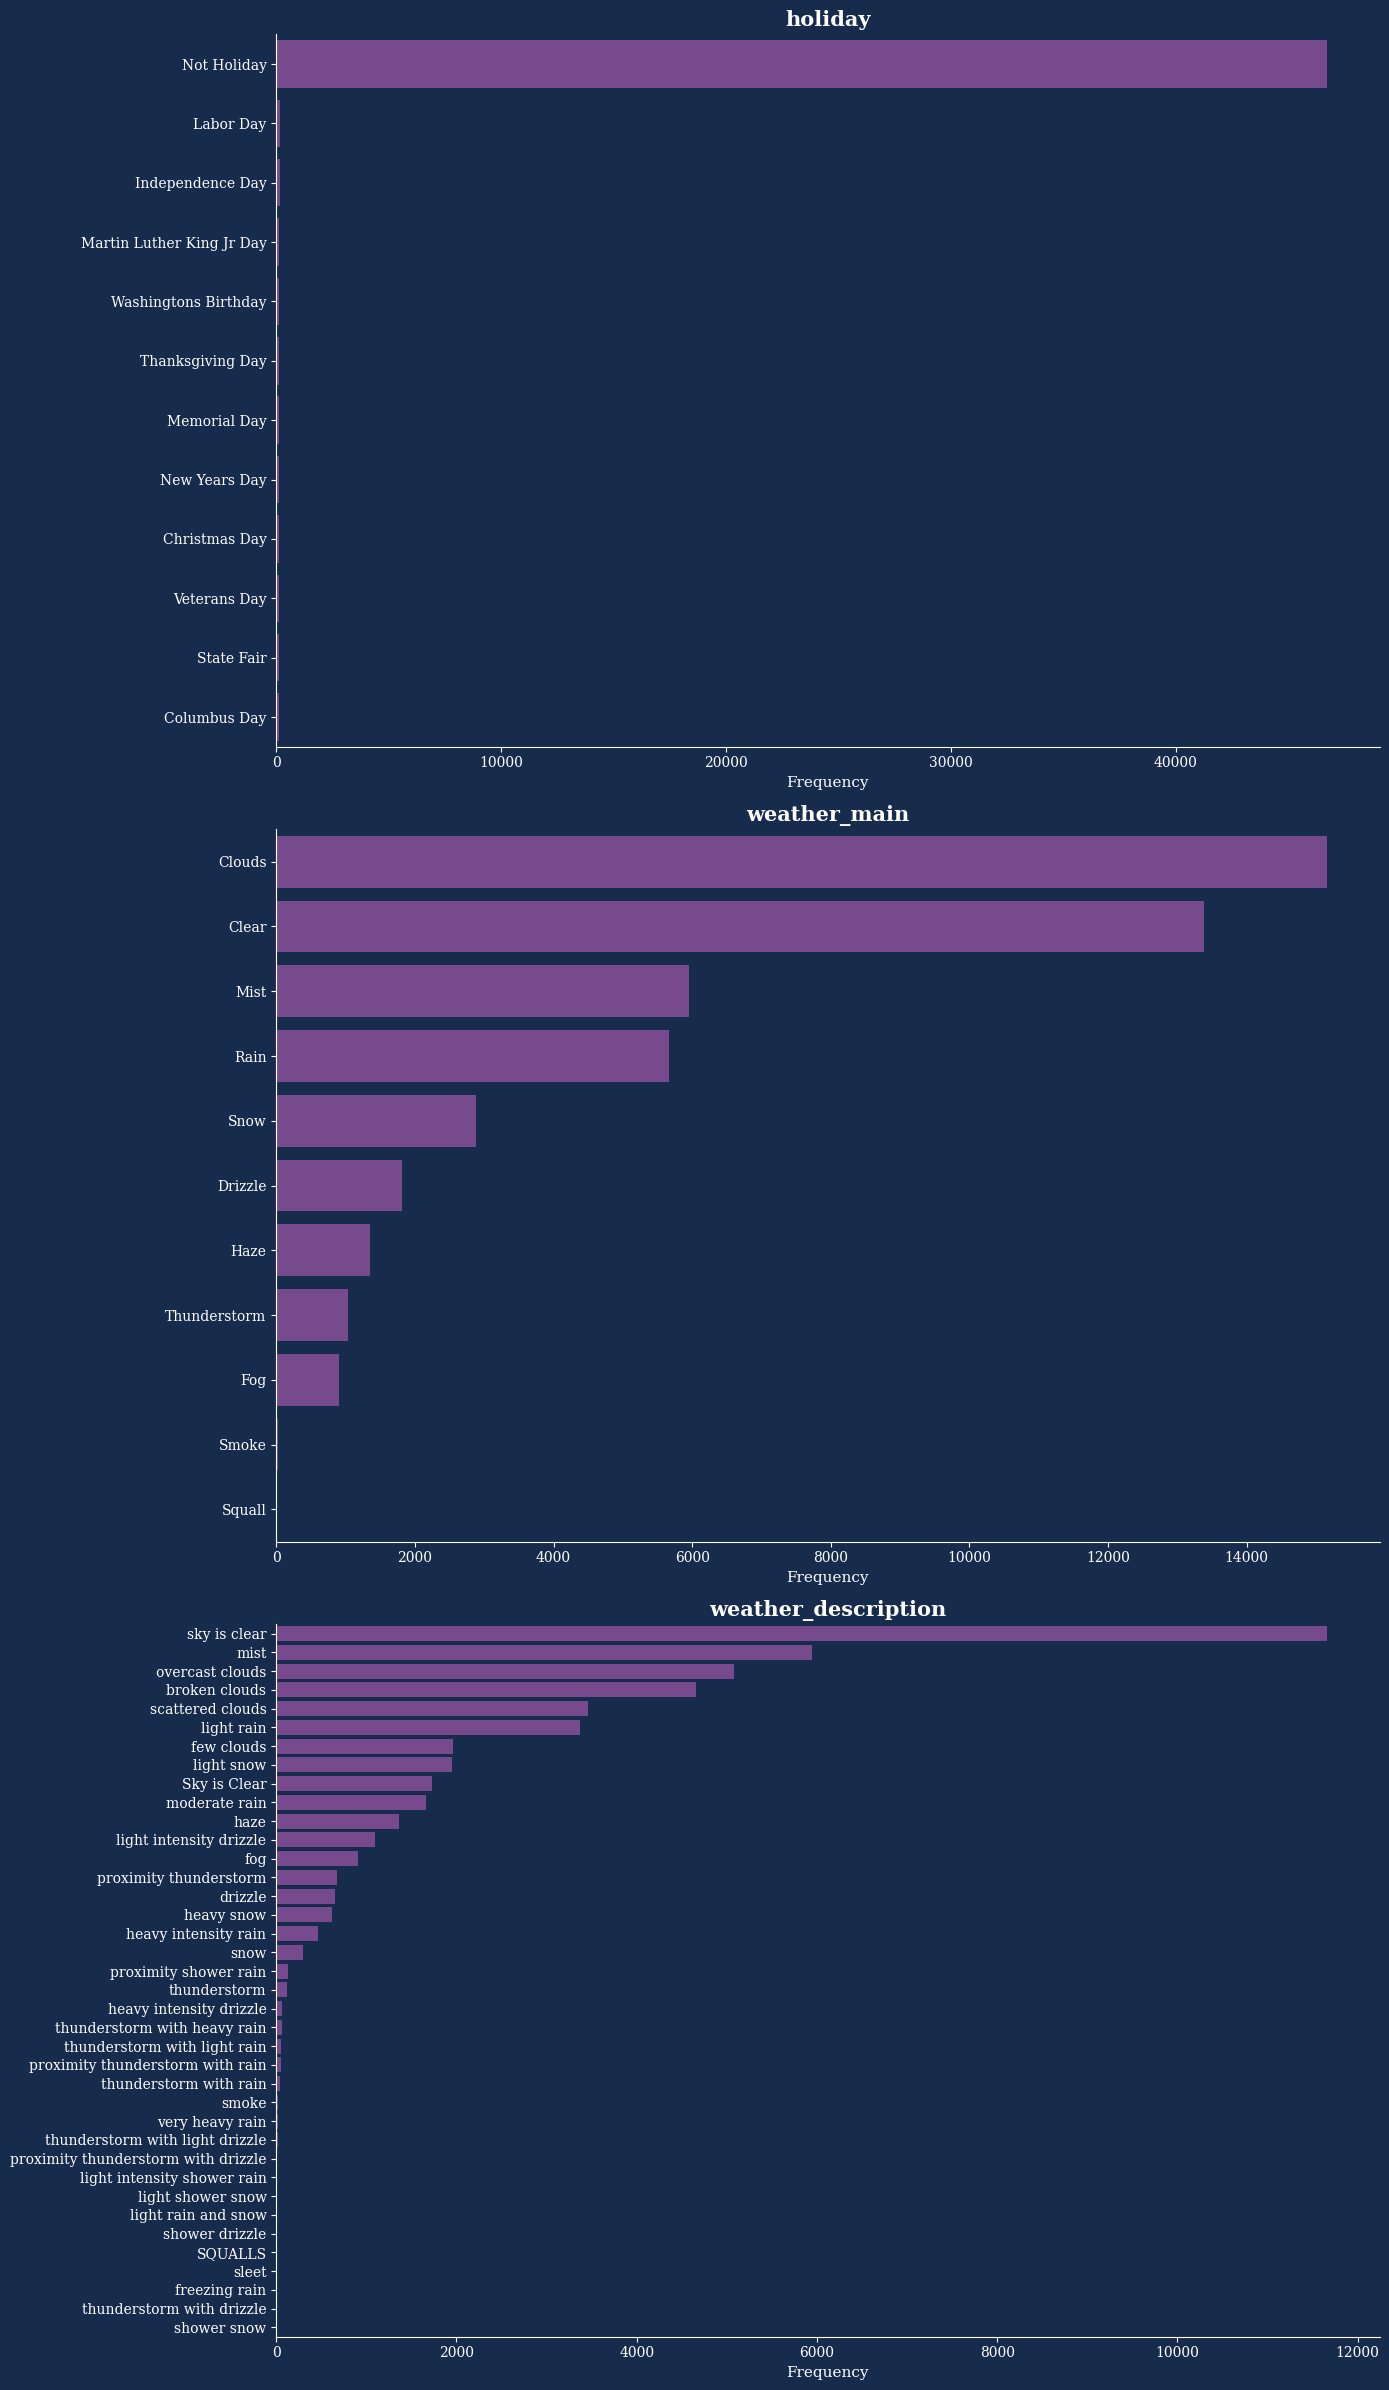

In [20]:
fig, axes = plt.subplots(
    nrows=len(cat_vars),
    ncols=1,
    figsize=(14, 8 * len(cat_vars)),
    facecolor="#172B4D"
)

axes = np.atleast_1d(axes)

for i, var in enumerate(cat_vars):

    counts = Traffic[var].value_counts()

    axes[i].set_facecolor("#172B4D")

    sns.barplot(
        x=counts.values,
        y=counts.index,
        ax=axes[i],
        color="#7B3F98"
    )

    axes[i].set_title(
        var,
        fontsize=15,
        fontweight='bold',
        fontfamily='serif',
        color='white'
    )

    axes[i].set_xlabel(
        'Frequency',
        fontsize=11,
        fontfamily='serif',
        color='white'
    )

    axes[i].set_ylabel('')

    axes[i].tick_params(
        axis='both',
        colors='white'
    )

    # Serif font for tick labels
    for label in axes[i].get_xticklabels():
        label.set_fontfamily('serif')

    for label in axes[i].get_yticklabels():
        label.set_fontfamily('serif')

    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    axes[i].spines['left'].set_color('white')
    axes[i].spines['bottom'].set_color('white')


plt.tight_layout()
plt.show()

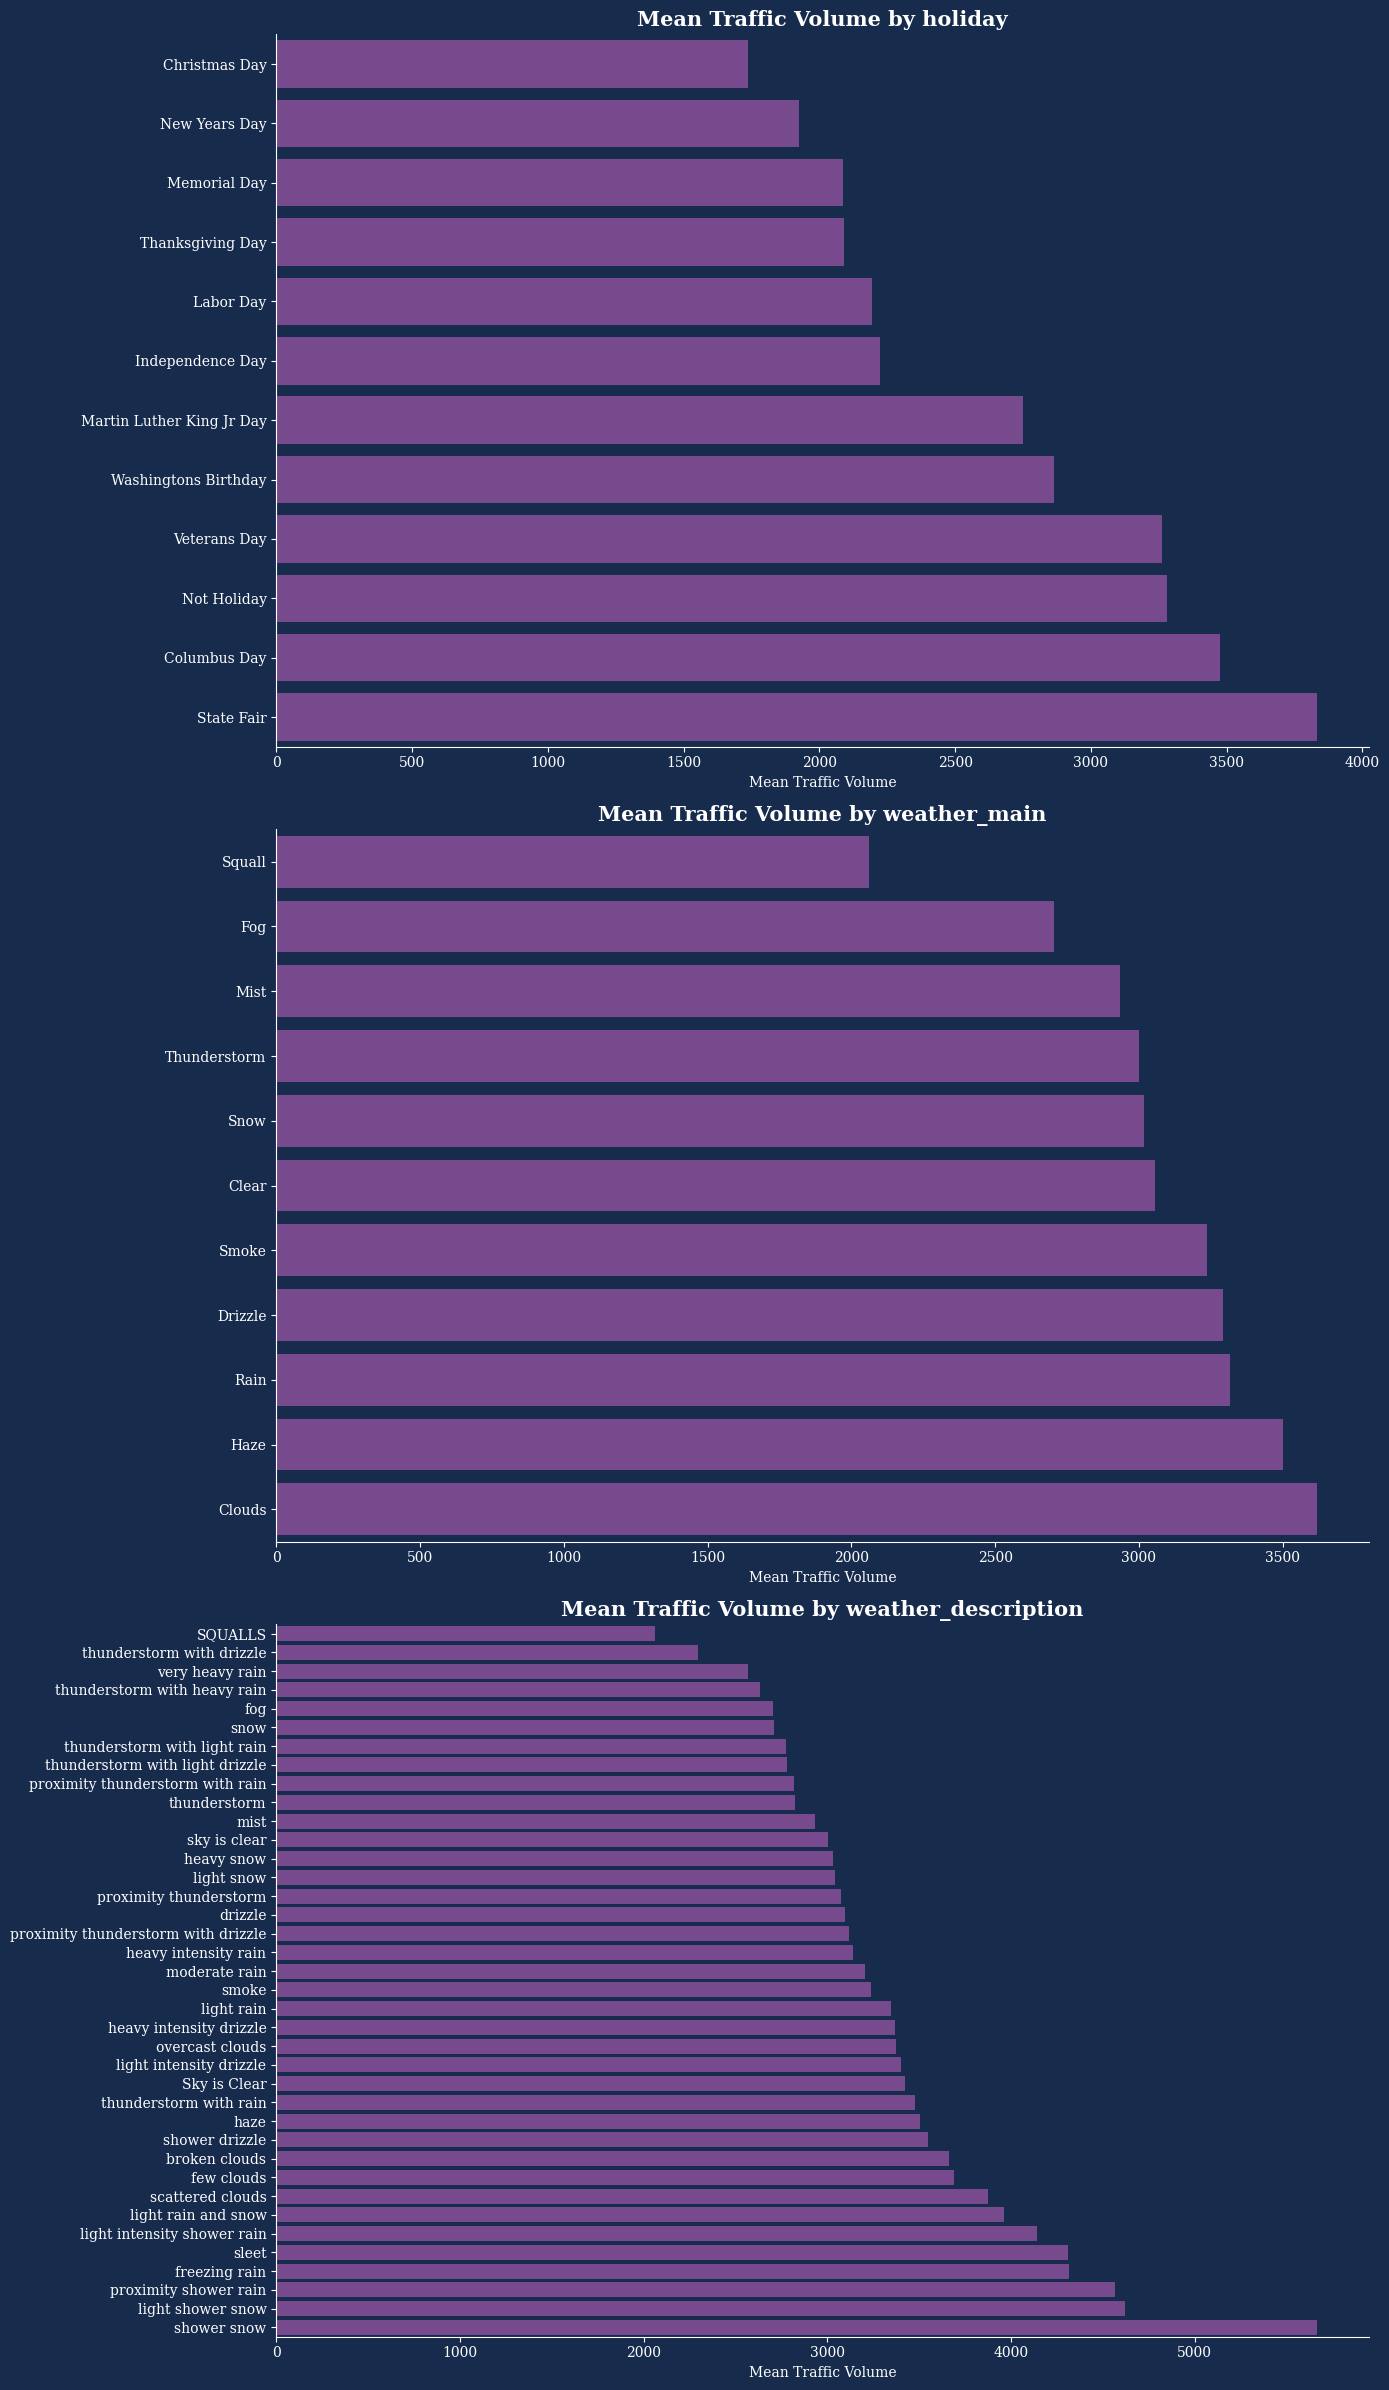

In [21]:
fig, axes = plt.subplots(
    nrows=len(cat_vars),
    ncols=1,
    figsize=(14, 8 * len(cat_vars)),
    facecolor="#172B4D"
)

axes = np.atleast_1d(axes)

for i, var in enumerate(cat_vars):

    mean_traffic = Traffic.groupby(var)['traffic_volume'].mean().sort_values()

    axes[i].set_facecolor("#172B4D")

    sns.barplot(
        x=mean_traffic.values,
        y=mean_traffic.index,
        ax=axes[i],
        color="#7B3F98"
    )

    axes[i].set_title(
        f'Mean Traffic Volume by {var}',
        fontsize=15,
        fontweight='bold',
        fontfamily='serif',
        color='white'
    )

    axes[i].set_xlabel(
        'Mean Traffic Volume',
        fontsize=10,
        fontfamily='serif',
        color='white'
    )

    axes[i].set_ylabel('')

    axes[i].tick_params(
        axis='both',
        colors='white'
    )

    for label in axes[i].get_xticklabels():
        label.set_fontfamily('serif')

    for label in axes[i].get_yticklabels():
        label.set_fontfamily('serif')

    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    axes[i].spines['left'].set_color('white')
    axes[i].spines['bottom'].set_color('white')


plt.tight_layout()
plt.show()

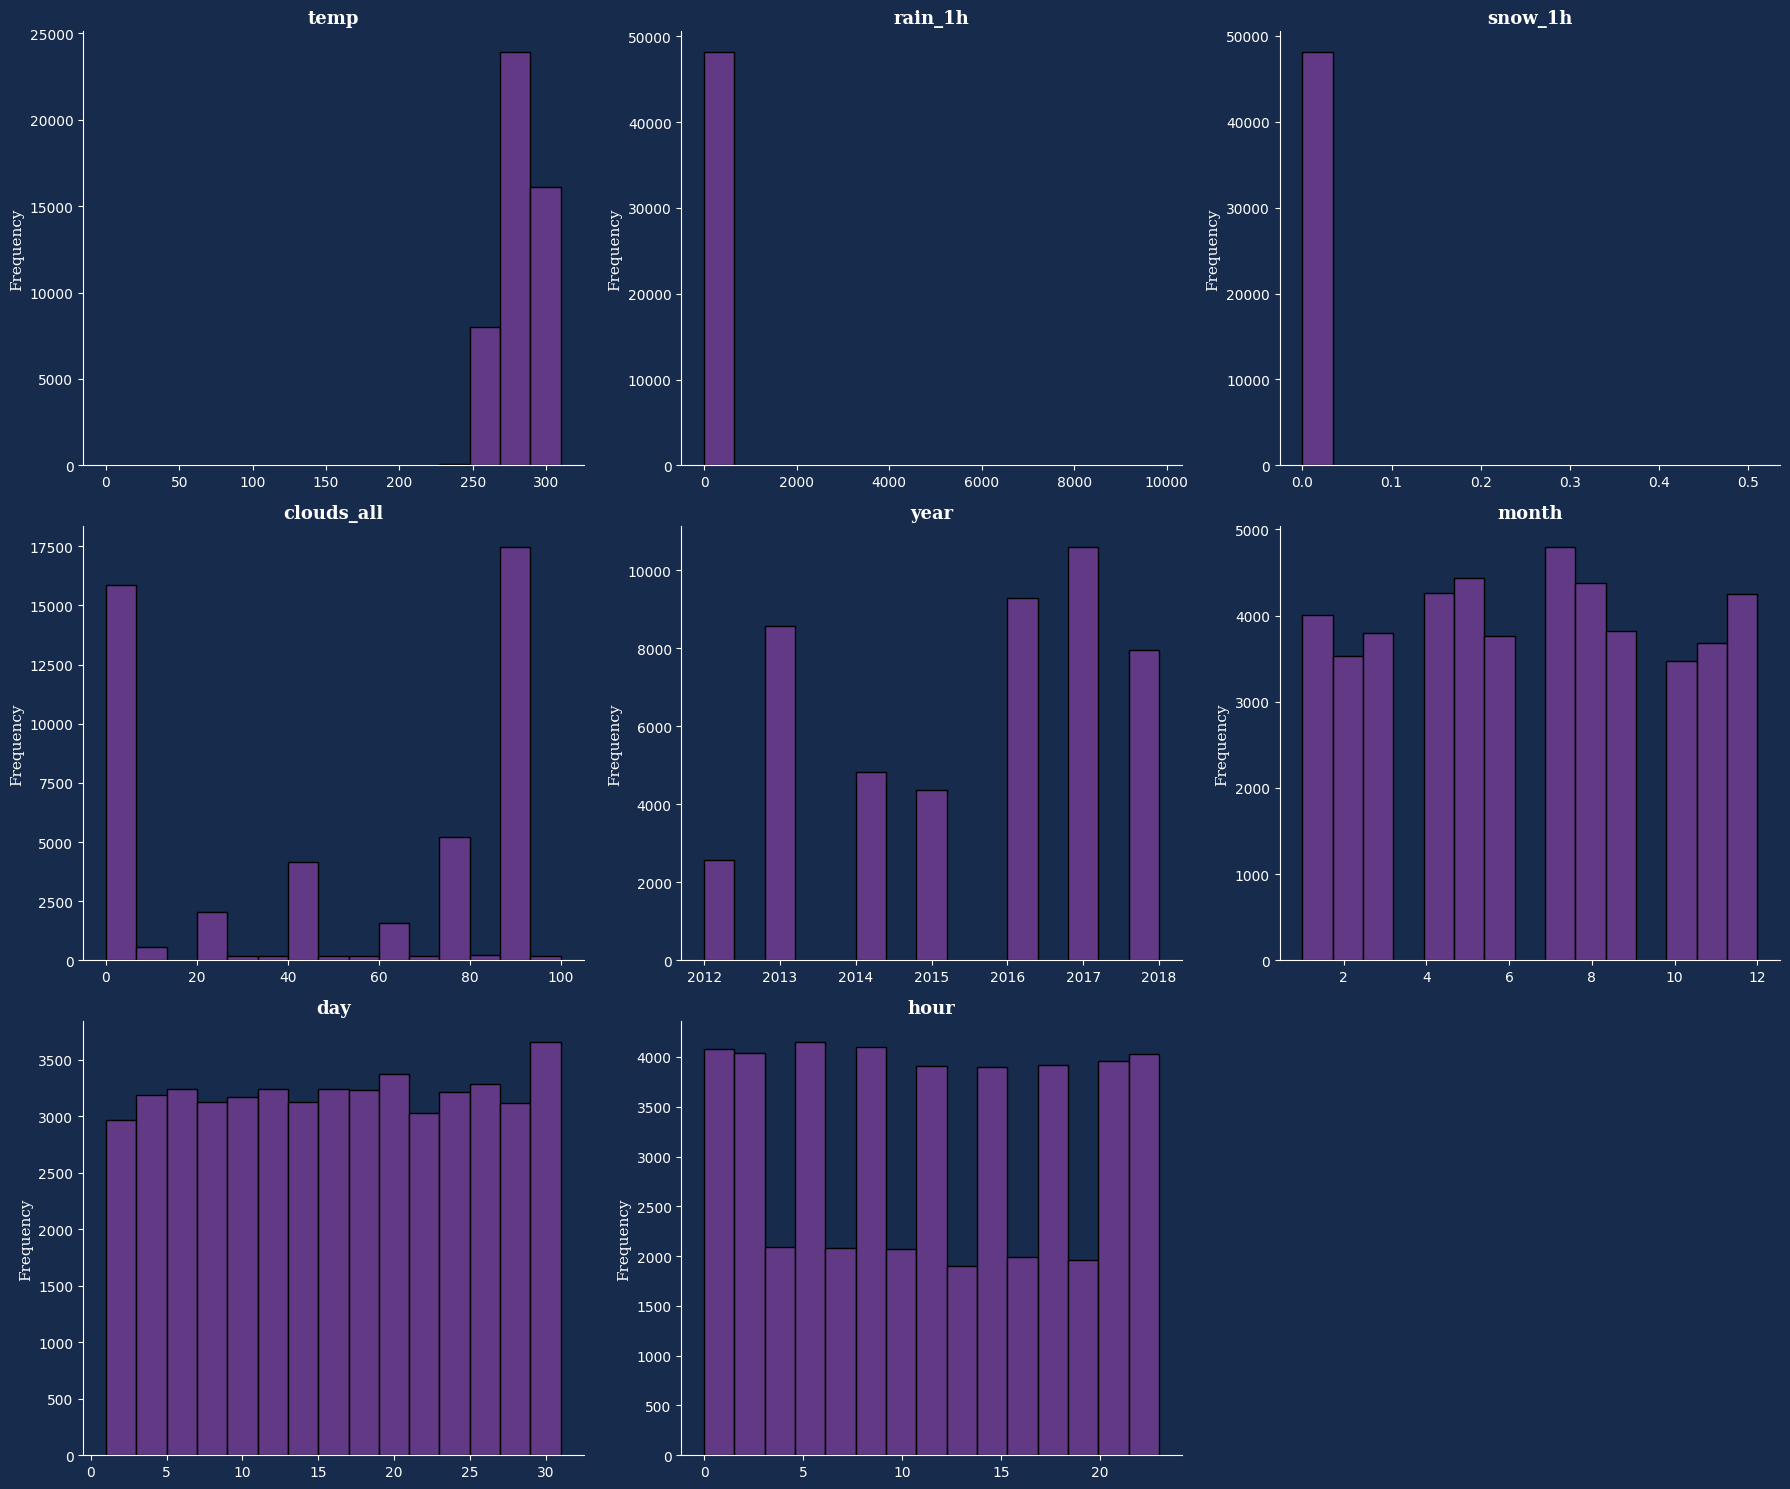

In [22]:
con_vars_ = [var for var in con_vars if var != 'traffic_volume']

n = len(con_vars_)
ncols = 3
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(18, 5 * nrows),
    facecolor="#172B4D"
)

axes = np.atleast_1d(axes).flatten()

for i, var in enumerate(con_vars_):

    ax = axes[i]
    ax.set_facecolor("#172B4D")

    sns.histplot(
        data=Traffic,
        x=var,
        bins=15,
        ax=ax,
        color="#7B3F98"
    )

    # Set x-axis according to the actual range of each variable
    xmin = Traffic[var].min()
    xmax = Traffic[var].max()
    padding = (xmax - xmin) * 0.05

    ax.set_xlim(xmin - padding, xmax + padding)

    ax.set_title(
        var,
        fontsize=13,
        fontweight='bold',
        fontfamily='serif',
        color='white'
    )

    ax.set_xlabel('')
    ax.set_ylabel(
        'Frequency',
        fontsize=11,
        fontfamily='serif',
        color='white'
    )

    ax.tick_params(axis='both', colors='white')

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('white')
    ax.spines['bottom'].set_color('white')

for j in range(n, len(axes)):
    fig.delaxes(axes[j])


plt.tight_layout()
plt.show()

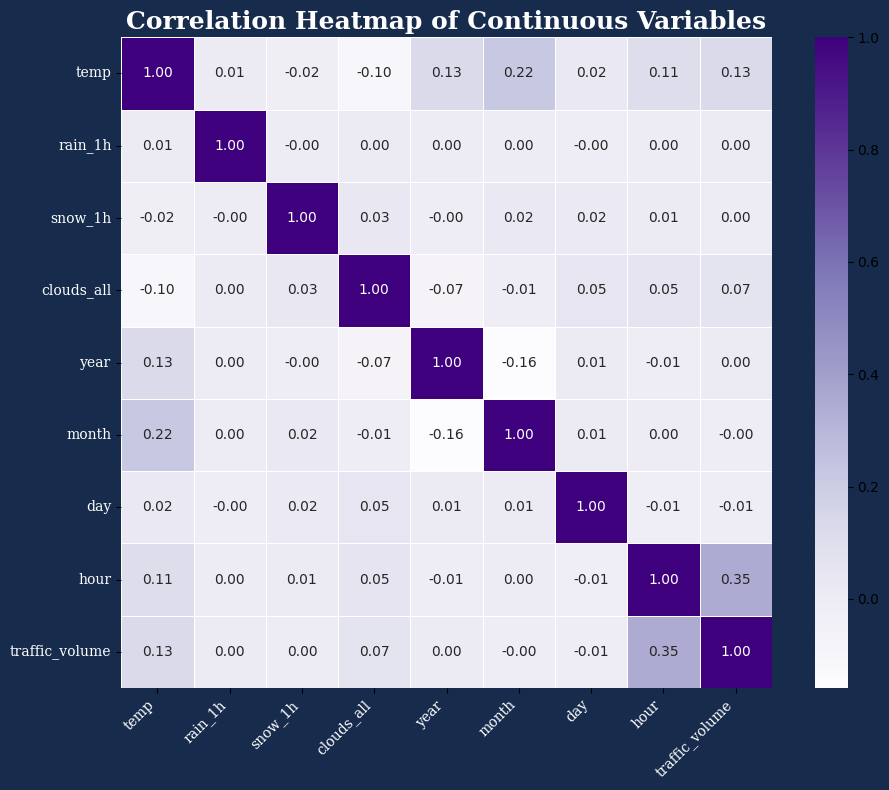

In [23]:
corr = Traffic[con_vars].corr()

plt.figure(figsize=(10, 8), facecolor="#172B4D")

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='Purples',
    linewidths=0.5,
    square=True
)

plt.title(
    'Correlation Heatmap of Continuous Variables',
    fontsize=18,
    fontweight='bold',
    fontfamily='serif',
    color='white'
)

plt.xticks(
    fontfamily='serif',
    color='white',
    rotation=45,
    ha='right'
)

plt.yticks(
    fontfamily='serif',
    color='white',
    rotation=0
)

plt.tight_layout()
plt.show()

<a id="4"></a>
<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 0 0 14px 0;"><h2 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">Data Cleaning &amp; Feature Engineering</h2></div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">4.1 — Getting Started</h3></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">This section continues from the <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Traffic</code> DataFrame built in the EDA section above, so nothing the EDA already did is repeated here:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b>Exact duplicate rows</b> were already removed there (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">drop_duplicates()</code>); an assertion in 4.3.1 confirms the count.</li><li style="margin-bottom:4px;"><b>Date parts</b>: <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">date_time</code> was already split into <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">year</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">month</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code>; those columns are reused instead of being extracted again.</li><li style="margin-bottom:4px;"><b>Holiday labels</b> were rebuilt there for exploration only. Holiday/event information is not part of the features in this section.</li></ul><p style="margin:0 0 8px 0;">A second, untouched read of the CSV (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">raw</code>) is loaded for one purpose only: the audit in 4.2 must describe the data <b>before any change</b>, and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Traffic</code> no longer qualifies (rows were dropped, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">holiday</code> was overwritten and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">date_time</code> was removed). No cleaning is ever applied to <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">raw</code>.</p><p style="margin:0 0 8px 0;"><b>Team decisions applied in this section:</b> the weather label columns (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_main</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_description</code>) and all holiday/event features are excluded from the features, and temperature is converted from Kelvin to °C.</p></div>

In [24]:
RAIN_MAX_PLAUSIBLE = 100.0     # mm/h; next-highest real value in the data is ~55 mm/h
LOW_VOLUME_THRESHOLD = 100     # vehicles/h
RUSH_HOURS = [6, 7, 8, 15, 16, 17]
INTERP_MAX_HOURS = 48          # max span (between valid neighbours) temperature interpolation may bridge
TEMP_SENTINELS = [276.793, 297.888]   # stuck / placeholder temperatures, in raw Kelvin (found in audit 4.2.4)
KELVIN_OFFSET = 273.15         # degrees C = K - 273.15

# Read-only baseline for the audit in 4.2 ("before any changes"); never cleaned.
raw = pd.read_csv("../data/Metro_Interstate_Traffic_Volume.csv", parse_dates=['date_time'])
print('raw shape:', raw.shape)

raw shape: (48204, 9)


In [25]:
# Chart theme: same palette and fonts as the EDA charts above
# (dark navy background, purple, white serif text, no top/right spines)
THEME_BG = '#172B4D'
THEME_PURPLE = '#7B3F98'
THEME_LAVENDER = '#D8D6FF'
THEME_ACCENT = '#F5B841'     # highlight colour for raw values / anomalies


def style_axes(ax, title=None, xlabel=None, ylabel=None, title_size=13):
    """Apply the notebook's dark theme to one axes."""
    ax.set_facecolor(THEME_BG)
    if title is not None:
        ax.set_title(title, fontsize=title_size, fontweight='bold', fontfamily='serif', color='white')
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=11, fontfamily='serif', color='white')
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=11, fontfamily='serif', color='white')
    ax.tick_params(axis='both', colors='white', labelfontfamily='serif')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('white')
    ax.spines['bottom'].set_color('white')


def style_legend(ax, **kwargs):
    """Legend that matches the dark theme."""
    return ax.legend(frameon=False, labelcolor='white', prop={'family': 'serif', 'size': 9}, **kwargs)

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">4.2 — Data Quality Audit (Before Any Changes)</h3></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.1 — Missing Values</h4></div>

In [26]:
audit = pd.DataFrame({'dtype': raw.dtypes.astype(str),
                      'n_missing': raw.isna().sum(),
                      'missing_%': (raw.isna().mean() * 100).round(2),
                      'n_unique': raw.nunique()})
audit

,dtype,n_missing,missing_%,n_unique
holiday,object,48143,99.87,11
temp,float64,0,0.00,5843
rain_1h,float64,0,0.00,372
snow_1h,float64,0,0.00,12
clouds_all,int64,0,0.00,60
weather_main,object,0,0.00,11
weather_description,object,0,0.00,38
date_time,datetime64[ns],0,0.00,40575
traffic_volume,int64,0,0.00,6704


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Only <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">holiday</code> has missing values (48,143 rows, 99.87 %). This is a <b>structural</b> absence meaning "no holiday/event on that day", not a lost measurement, so it must not be imputed with a mean/median. Holiday/event information is excluded from the features in this section (team decision), so the column is simply not carried forward.</p></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.2 — Duplicate Rows: Two Distinct Types</h4></div>

In [27]:
n_exact = int(raw.duplicated().sum())
tmp = raw.drop_duplicates()
grp = tmp.groupby('date_time')
sizes = grp.size()

dup_report = pd.Series({
    'exact duplicate rows': n_exact,
    'rows after exact-dedup': len(tmp),
    'unique timestamps': sizes.size,
    'timestamps with >1 row': int((sizes > 1).sum()),
    'groups where traffic_volume differs': int((grp.traffic_volume.nunique() > 1).sum()),
    'groups where temp differs': int((grp.temp.nunique() > 1).sum()),
    'groups where rain_1h differs': int((grp.rain_1h.nunique() > 1).sum()),
    'groups where snow_1h differs': int((grp.snow_1h.nunique() > 1).sum()),
    'groups where clouds_all differs': int((grp.clouds_all.nunique() > 1).sum()),
    'groups where weather_main differs': int((grp.weather_main.nunique() > 1).sum()),
    'groups where weather_description differs': int((grp.weather_description.nunique() > 1).sum()),
})
print(dup_report.to_string())
print('\nlargest group example:')
tmp[tmp.date_time == sizes.idxmax()]

exact duplicate rows                           17
rows after exact-dedup                      48187
unique timestamps                           40575
timestamps with >1 row                       5430
groups where traffic_volume differs             0
groups where temp differs                      78
groups where rain_1h differs                    9
groups where snow_1h differs                    0
groups where clouds_all differs                32
groups where weather_main differs            5349
groups where weather_description differs     5386

largest group example:


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
5249,NaN,274.79,0.0,0.0,90,Mist,mist,2013-04-18 22:00:00,1532
5250,NaN,274.79,0.0,0.0,90,Drizzle,light intensity drizzle,2013-04-18 22:00:00,1532
5251,NaN,274.79,0.0,0.0,90,Rain,light rain,2013-04-18 22:00:00,1532
5252,NaN,274.79,0.0,0.0,90,Rain,moderate rain,2013-04-18 22:00:00,1532
5253,NaN,274.79,0.0,0.0,90,Snow,heavy snow,2013-04-18 22:00:00,1532
5254,NaN,274.79,0.0,0.0,90,Snow,snow,2013-04-18 22:00:00,1532


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;"><b>Result:</b> there are 17 completely duplicate rows (already dropped in the EDA section), but more importantly <b>thousands of timestamps still have more than one row</b> (5,430). Within these groups <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">traffic_volume</code> never varies and the numeric weather values are almost always identical; what varies are the <b>textual weather labels</b> (several weather reports recorded for a single hour). The correct treatment is therefore to aggregate into a single row per hour, and <b>the main challenge is selecting the weather label</b>, not the numeric values.</p><p style="margin:0 0 8px 0;"><b>Note:</b> <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">drop_duplicates()</code> alone (as done in the EDA section) is not enough: every hour with several reports is still counted several times, which skews EDA means and correlations toward high-frequency hours.</p></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.3 — Physically Impossible Values</h4></div>

In [28]:
zero_k = raw[raw.temp <= 0]
print('rows with temp <= 0 K:', len(zero_k))
valid_c = raw.loc[raw.temp > 0, 'temp'] - KELVIN_OFFSET
print('valid temp range (°C): %.2f -> %.2f' % (valid_c.min(), valid_c.max()))
print(zero_k.groupby(zero_k.date_time.dt.date).agg(n=('temp', 'size'), first=('date_time', 'min'), last=('date_time', 'max')))

print('\ntop-5 rain_1h:', raw.rain_1h.nlargest(5).tolist())
print('snow_1h max:', raw.snow_1h.max(), '| clouds_all range:', raw.clouds_all.min(), '-', raw.clouds_all.max())
print('negative values:', int((raw[['rain_1h', 'snow_1h', 'clouds_all']] < 0).sum().sum()))
(raw[raw.rain_1h > RAIN_MAX_PLAUSIBLE]
    .assign(temp_c=lambda x: (x.temp - KELVIN_OFFSET).round(2))
    [['date_time', 'temp_c', 'rain_1h', 'weather_main', 'weather_description', 'traffic_volume']])

rows with temp <= 0 K: 10
valid temp range (°C): -29.76 -> 36.92
            n               first                last
date_time                                            
2014-01-31  4 2014-01-31 03:00:00 2014-01-31 06:00:00
2014-02-02  6 2014-02-02 03:00:00 2014-02-02 08:00:00

top-5 rain_1h: [9831.3, 55.63, 44.45, 31.75, 28.7]
snow_1h max: 0.51 | clouds_all range: 0 - 100
negative values: 0


,date_time,temp_c,rain_1h,weather_main,weather_description,traffic_volume
24872,2016-07-11 17:00:00,28.96,9831.3,Rain,very heavy rain,5535


In [29]:
# context of the rain anomaly: neighbouring hours
w = raw[(raw.date_time >= '2016-07-11 14:00') & (raw.date_time <= '2016-07-11 21:00')]
w[['date_time', 'rain_1h', 'weather_description', 'traffic_volume']]

,date_time,rain_1h,weather_description,traffic_volume
24869,2016-07-11 14:00:00,0.0,overcast clouds,4456
24870,2016-07-11 15:00:00,0.0,proximity thunderstorm,4858
24871,2016-07-11 16:00:00,0.0,proximity thunderstorm,5934
24872,2016-07-11 17:00:00,9831.3,very heavy rain,5535
24873,2016-07-11 18:00:00,0.0,proximity thunderstorm,3900
24874,2016-07-11 19:00:00,0.0,broken clouds,2856
24875,2016-07-11 20:00:00,0.0,thunderstorm,2506
24876,2016-07-11 21:00:00,0.0,thunderstorm with light rain,2062


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b>Temperature of 0 Kelvin</b> (−273.15 °C, absolute zero) = sensor failure, not actual weather. Two continuous multi-hour windows (2014-01-31 and 2014-02-02) during the coldest hours of the night.</li><li style="margin-bottom:4px;"><b>Precipitation of 9,831.3 mm/h</b>: the next highest value in the dataset is ≈ 55.6, and its neighbouring hours record 0 precipitation. This is a logging/unit error.</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">snow_1h</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">clouds_all</code>: normal and within a plausible range.</li></ul></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.4 — "Stuck" / Placeholder Temperatures: A More Subtle Issue</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Temperature is typically recorded on a 0.01 Kelvin grid; however, a small number of values have <b>three decimal places</b>. Among these, two values appear repeatedly:</p></div>

In [30]:
off_grid = raw[(raw.temp * 100).round(4) % 1 != 0]
vc = off_grid.temp.value_counts()
print('off-grid temp values:', len(off_grid), '| most repeated (K):')
print(vc.head(4).to_string())

for v in TEMP_SENTINELS:
    r_ = raw[raw.temp == v]
    ts_ = pd.Series(sorted(r_.date_time.unique()))
    runs = (ts_.diff() != pd.Timedelta(hours=1)).cumsum()
    print(f'\ntemp == {v} K ({v - KELVIN_OFFSET:.1f} °C): {len(r_)} rows, {r_.date_time.min()} -> {r_.date_time.max()}, '
          f'longest consecutive run = {int(ts_.groupby(runs).size().max())} hours')

off-grid temp values: 1124 | most repeated (K):
temp
276.793    78
297.888    43
281.469     6
281.372     6

temp == 276.793 K (3.6 °C): 78 rows, 2013-10-22 05:00:00 -> 2014-01-23 08:00:00, longest consecutive run = 33 hours

temp == 297.888 K (24.7 °C): 43 rows, 2016-07-18 18:00:00 -> 2016-07-20 12:00:00, longest consecutive run = 43 hours


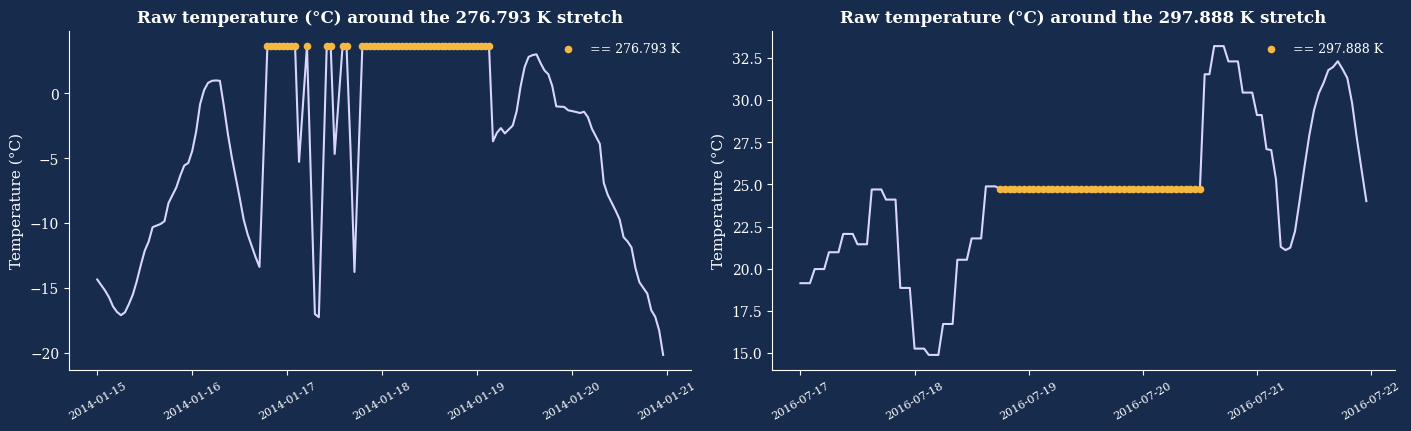

In [31]:
raw_med = raw.groupby('date_time').temp.median().sort_index()     # hourly median of the raw reports (K)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), facecolor=THEME_BG, constrained_layout=True)
for ax, (a, b), v in zip(axes, [('2014-01-15', '2014-01-20'), ('2016-07-17', '2016-07-21')], TEMP_SENTINELS):
    w = raw_med[a:b] - KELVIN_OFFSET
    ax.plot(w.index, w.values, color=THEME_LAVENDER, lw=1.5)
    hit = w[raw_med[a:b] == v]
    ax.scatter(hit.index, hit.values, color=THEME_ACCENT, s=20, zorder=3, label=f'== {v} K')
    style_axes(ax, title=f'Raw temperature (°C) around the {v} K stretch', ylabel='Temperature (°C)', title_size=12)
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    style_legend(ax)
plt.show()

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">276.793 K</code> (= <b>+3.6 °C</b>) appears across 78 rows (between October 2013 and January 2014; 70 of these rows are in January 2014 alone). The left plot shows that in the middle of a severe cold wave, where adjacent true temperatures range from −10 °C down to −26 °C, the reading abruptly jumps to +3.6 °C and sometimes stays flat for 33 consecutive hours.</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">297.888 K</code> (= +24.7 °C) repeats across 43 <b>consecutive</b> hours (2016-07-18 to 2016-07-20) with no diurnal cycle whatsoever, which is physically impossible in midsummer.</li></ul><p style="margin:0 0 8px 0;">These are "stuck" or placeholder values produced by the sensor or upstream data, <b>not real-world weather</b>. Unlike 0 K, they cannot be caught by a simple physical range check and are only exposed by examining repetition patterns. Left uncorrected, temperatures in these windows stay off by up to ~30 °C. Moreover, when several hourly readings are aggregated with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">median</code>, mixing stuck values with true values produces artificial intermediate figures.</p></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.5 — Remaining Temperature Jumps (After Discarding Stuck Values)</h4></div>

In [32]:
t_chk = raw[(raw.temp > 0) & (~raw.temp.isin(TEMP_SENTINELS))].groupby('date_time').temp.median().sort_index()
adj = t_chk.index.to_series().diff() == pd.Timedelta(hours=1)
jump = t_chk.diff().abs()[adj]
print('adjacent-hour temp jumps > 10 °C (after masking sentinels):', int((jump > 10).sum()))
jump[jump > 10].rename('abs jump (°C)').to_frame()

adjacent-hour temp jumps > 10 °C (after masking sentinels): 1


,abs jump (°C)
date_time,
2013-02-03 18:00:00,14.14


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Removing the stuck values drops the number of severe hour-over-hour temperature spikes (&gt; 10 °C) from 8 down to 1, confirming that the other seven were purely artificial. The sole remaining incident is an isolated point on 2013-02-03 at 18:00, which reverts to baseline within two hours. While suspect, it is <b>unprovable</b> (a rapid weather front cannot be ruled out), so we leave it untouched. The governing rule: only modify what the evidence definitively supports.</p></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.6 — Categorical Text: Casing Inconsistencies and Pair Alignment (main, description)</h4></div>

In [33]:
print('weather_description unique (raw):', raw.weather_description.nunique())
print('after lower/strip              :', raw.weather_description.str.lower().str.strip().nunique())
print(raw.weather_description[raw.weather_description.str.contains('clear|squall', case=False)].value_counts().to_dict())

pairs = raw.assign(d=raw.weather_description.str.lower().str.strip()).groupby('d').weather_main.nunique()
print('descriptions linked to >1 weather_main:', int((pairs > 1).sum()))

weather_description unique (raw): 38
after lower/strip              : 37
{'sky is clear': 11665, 'Sky is Clear': 1726, 'SQUALLS': 4}
descriptions linked to >1 weather_main: 0


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Sky is Clear</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">sky is clear</code> represent the same category and are merged via lowercasing. <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">SQUALLS</code> exists only in uppercase (with no lowercase counterpart); it does not merge with another entry, but is lowercased for consistency.</li><li style="margin-bottom:4px;">Every <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_description</code> maps to exactly one <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_main</code>; in other words, <b>the pair (main, description) is a single semantic unit.</b> This becomes essential for the aggregation step:</li></ul></div>

In [34]:
tmp2 = raw.drop_duplicates().assign(weather_description=lambda x: x.weather_description.str.lower().str.strip())

def det_mode(s):
    vc = s.value_counts()
    return sorted(vc[vc == vc.max()].index)[0]

naive = tmp2.groupby('date_time').agg(m=('weather_main', det_mode), d=('weather_description', det_mode))
valid_pairs = set(map(tuple, tmp2[['weather_main', 'weather_description']].drop_duplicates().values))
incoherent = [(m, d) for m, d in zip(naive.m, naive.d) if (m, d) not in valid_pairs]
print('timestamps that would get an IMPOSSIBLE (main, description) pair:', len(incoherent))
print(pd.Series(incoherent).value_counts().head(5).to_string())

timestamps that would get an IMPOSSIBLE (main, description) pair: 1542
(Mist, light snow)                 468
(Mist, light rain)                 400
(Mist, heavy snow)                 217
(Mist, heavy intensity rain)       195
(Drizzle, heavy intensity rain)     57


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">If the <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">mode</code> of each column is computed independently, it creates combinations such as <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Mist</code> + <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">light snow</code> across more than 1,500 hours: combinations that never existed in the original dataset. <b>Solution:</b> the <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">mode</code> must be computed on the *pair* (main, description) as a single entity.</p></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.7 — Temporal Coverage, Gaps, and Time Zone</h4></div>

expected hourly slots: 52,551 | present: 40,575 | absent: 11,976 (22.8%)

gaps longer than 48h:
  2014-08-08 01:00:00 -> 2015-06-11 20:00:00   (307 days 19 h)
  2013-10-27 01:00:00 -> 2013-11-06 04:00:00   (10 days 3 h)
  2015-06-14 20:00:00 -> 2015-06-19 18:00:00   (4 days 22 h)
  2014-04-29 08:00:00 -> 2014-05-04 05:00:00   (4 days 21 h)
  2015-10-23 11:00:00 -> 2015-10-27 08:00:00   (3 days 21 h)
  2014-07-27 16:00:00 -> 2014-07-30 09:00:00   (2 days 17 h)


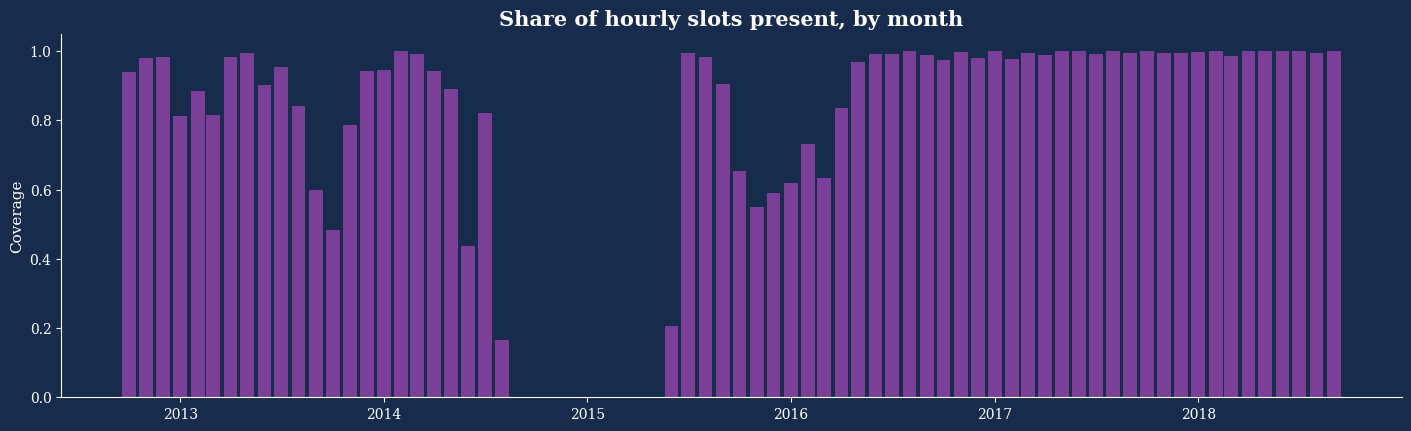

In [35]:
ts = pd.DatetimeIndex(sorted(raw.date_time.unique()))
full = pd.date_range(ts.min(), ts.max(), freq='h')
print(f'expected hourly slots: {len(full):,} | present: {len(ts):,} | absent: {len(full)-len(ts):,} ({100*(len(full)-len(ts))/len(full):.1f}%)')

gaps = pd.Series(ts[1:] - ts[:-1], index=ts[1:])
big = gaps[gaps > pd.Timedelta(hours=48)].sort_values(ascending=False)
print('\ngaps longer than 48h:')
for end, g in big.head(6).items():
    print(f'  {end - g} -> {end}   ({g.days} days {g.seconds//3600} h)')

cov = pd.Series(1, index=ts).resample('MS').sum() / (pd.Series(1, index=full).resample('MS').sum())
fig, ax = plt.subplots(figsize=(14, 4.2), facecolor=THEME_BG, constrained_layout=True)
ax.bar(cov.index, cov.values, width=25, color=THEME_PURPLE)
style_axes(ax, title='Share of hourly slots present, by month', ylabel='Coverage', title_size=15)
ax.set_ylim(0, 1.05)
plt.show()

In [36]:
t0 = raw.drop_duplicates('date_time').set_index('date_time').traffic_volume
wd0 = t0[t0.index.dayofweek < 5]
for m, name in [(1, 'January'), (7, 'July')]:
    s = wd0[wd0.index.month == m]
    print(name, 'top-3 weekday hours:', s.groupby(s.index.hour).mean().nlargest(3).index.tolist())
print('hours present on 2014-03-09 (US spring-forward day):', [int(h) for h in sorted(raw[raw.date_time.dt.strftime('%Y-%m-%d') == '2014-03-09'].date_time.dt.hour.unique())[:5]], '...')

January top-3 weekday hours: [16, 17, 7]
July top-3 weekday hours: [16, 7, 17]
hours present on 2014-03-09 (US spring-forward day): [0, 1, 3, 4, 5] ...


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;">About <b>23 % of all hourly slots are missing</b> from the dataset (11,976 of 52,551), with the largest gap spanning ≈ 10 months (2014-08 to 2015-06). The "previous row" can therefore be months in the past: a naive <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">shift()</code> would build invalid lag features, and missing target values <b>must never be interpolated/imputed</b>.</li><li style="margin-bottom:4px;">Morning and evening peak hours are identical across winter and summer, and 02:00 is omitted on the spring-forward day; this confirms that <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">date_time</code> is effectively <b>local wall-clock time (observing DST)</b>, despite the dataset documentation specifying CST. Consequently <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code> and peak-hour features need no DST adjustment.</li></ul></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.8 — Target Variable: Near-Zero Clusters</h4></div>

In [37]:
tv = raw.drop_duplicates('date_time').set_index('date_time').sort_index().traffic_volume
print('1st percentile of traffic by hour (min over hours):', int(tv.groupby(tv.index.hour).quantile(0.01).min()))

low = tv[tv < LOW_VOLUME_THRESHOLD]
cl = (low.index.to_series().diff() > pd.Timedelta(hours=3)).cumsum()
low_clusters = low.groupby(cl).agg(start=lambda s: s.index.min(), end=lambda s: s.index.max(), n='size', median_tv='median')
print(f'timestamps with traffic_volume < {LOW_VOLUME_THRESHOLD}: {len(low)} in {len(low_clusters)} contiguous clusters')
low_clusters

1st percentile of traffic by hour (min over hours): 209
timestamps with traffic_volume < 100: 46 in 9 contiguous clusters


,start,end,n,median_tv
date_time,,,,
0,2015-07-24 22:00:00,2015-07-24 22:00:00,1,65.0
1,2015-07-25 08:00:00,2015-07-25 09:00:00,2,1.0
2,2016-07-09 20:00:00,2016-07-09 23:00:00,4,10.5
3,2016-07-22 22:00:00,2016-07-23 04:00:00,7,7.0
4,2016-07-23 09:00:00,2016-07-24 04:00:00,20,4.0
5,2016-07-24 09:00:00,2016-07-24 11:00:00,2,19.5
6,2016-07-24 16:00:00,2016-07-24 16:00:00,1,44.0
7,2016-08-31 23:00:00,2016-09-01 02:00:00,4,7.0
8,2016-09-07 23:00:00,2016-09-08 03:00:00,5,3.0


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Even in the dead of night, the lowest 1 % of traffic volume still registers several hundred vehicles; counts between 1 and 15 are therefore <b>never typical for any hour</b>. These values are not scattered randomly; they appear in several <b>continuous clusters</b> (sometimes persisting for ~20 consecutive hours) during the summers of 2015 and 2016. This suggests either a hardware/sensor failure or an actual highway closure. Because the data itself does not provide enough information to determine the root cause, we <b>leave the target untouched</b> and simply set a <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_low_volume</code> flag so the modeling team can decide how to handle it (e.g., segmenting it in error analysis).</p></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.2.9 — Audit Summary</h4></div>

In [38]:
pd.DataFrame([
    ('exact duplicate rows', n_exact, 'already dropped in the EDA section (verified in 4.3.1)'),
    ('timestamps with >1 report', int((sizes > 1).sum()), 'collapse to 1 row/hour (median numerics, joint-mode weather pair)'),
    ('temp <= 0 K', int((raw.temp <= 0).sum()), 'NaN -> time interpolation + flag'),
    ('temp stuck at 276.793 / 297.888 K', int(raw.temp.isin(TEMP_SENTINELS).sum()), 'NaN (before collapse) -> time interpolation + flag'),
    ('rain_1h > 100', int((raw.rain_1h > RAIN_MAX_PLAUSIBLE).sum()), 'NaN -> same-label median + flag'),
    ('"Sky is Clear" casing', int((raw.weather_description == 'Sky is Clear').sum()), 'lower/strip BEFORE collapsing'),
    ('holiday NaN (structural)', int(raw.holiday.isna().sum()), 'column excluded from the features (team decision); no imputation'),
    ('weather label columns', 2, 'helper only inside 4.3 (merge hours, impute rain), then dropped from the features'),
    ('absent hourly slots', len(full) - len(ts), 'document; never fill target'),
    (f'traffic_volume < {LOW_VOLUME_THRESHOLD} (unique ts)', len(low), 'keep, flag only'),
], columns=['finding', 'count', 'action'])

,finding,count,action
0,exact duplicate rows,17,already dropped in the EDA section (verified i...
1,timestamps with >1 report,5430,"collapse to 1 row/hour (median numerics, joint..."
2,temp <= 0 K,10,NaN -> time interpolation + flag
3,temp stuck at 276.793 / 297.888 K,121,NaN (before collapse) -> time interpolation + ...
4,rain_1h > 100,1,NaN -> same-label median + flag
5,"""Sky is Clear"" casing",1726,lower/strip BEFORE collapsing
6,holiday NaN (structural),48143,column excluded from the features (team decisi...
7,weather label columns,2,"helper only inside 4.3 (merge hours, impute ra..."
8,absent hourly slots,11976,document; never fill target
9,traffic_volume < 100 (unique ts),46,"keep, flag only"


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">4.3 — Data Cleaning (Step-by-Step)</h3></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The order is deliberate: <b>EDA frame → text normalization → impossible values to <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">NaN</code> (before aggregation) → hourly aggregation → imputation → Kelvin to °C → weather labels dropped → target flagging.</b></p></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.1 — Starting Point: the EDA Frame</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Traffic</code> from the EDA section is the starting point. It already has the exact duplicates removed and the <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">year</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">month</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code> columns, but <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">date_time</code> was dropped there. So:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">date_time</code> is rebuilt from those four columns and verified against the raw timestamps (no second parse or extraction).</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">holiday</code> is dropped: holiday/event information is excluded from the features (team decision).</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day</code> (day of the month) is dropped: it carries no meaningful traffic signal.</li><li style="margin-bottom:4px;">Nothing is deduplicated again: assertions confirm the row count equals <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">raw</code> minus the exact duplicates. <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Traffic</code> itself is copied and never modified.</li></ul></div>

In [39]:
df = Traffic.copy()
df['date_time'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])
df = df.drop(columns=['holiday', 'day']).sort_values('date_time').reset_index(drop=True)

# the EDA section already removed the exact duplicates, so there is nothing left to drop here
assert len(df) == len(raw) - n_exact
assert set(df.date_time) == set(raw.date_time)
print('rows:', len(raw), '->', len(df), f'(the EDA section already dropped {n_exact} exact duplicates)')

rows: 48204 -> 48187 (the EDA section already dropped 17 exact duplicates)


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.2 — Text Normalization (Before Aggregation, so <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Sky is Clear</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">sky is clear</code> Group Together)</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The weather label columns are <b>helper columns only</b> in this section: they are needed to merge duplicate hourly reports and to impute the single rain outlier (4.3.7), and they are dropped from the features in 4.3.8.</p></div>

In [40]:
for c in ['weather_main', 'weather_description']:
    df[c] = df[c].str.strip()
df['weather_description'] = df['weather_description'].str.lower()
assert 'SQUALLS' not in set(df.weather_description)
print('unique weather_description:', df.weather_description.nunique())

unique weather_description: 37


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.3 — Impossible/Stuck Values → NaN (Before Aggregation) + Flagging</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">If aggregated beforehand, the <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">median</code> across several reports would blend faulty values with valid readings, making them undetectable later; they are therefore converted to <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">NaN</code> first. Invalid temperature = "≤ 0 K" or "one of the two stuck values". Temperatures are still in Kelvin at this point because the stuck values are matched on the raw Kelvin numbers; the conversion to °C happens in 4.3.6.</p></div>

In [41]:
bad_temp = (df.temp <= 0) | df.temp.isin(TEMP_SENTINELS)
df.loc[bad_temp, 'temp'] = np.nan
df['qa_rain_invalid'] = (df.rain_1h > RAIN_MAX_PLAUSIBLE).astype('int8')
df.loc[df.qa_rain_invalid == 1, 'rain_1h'] = np.nan
print('temp reports -> NaN:', int(bad_temp.sum()), '| rain -> NaN:', int(df.qa_rain_invalid.sum()))

assert (df.groupby('date_time').traffic_volume.nunique() == 1).all()
print('target constant within every timestamp group: OK')

temp reports -> NaN: 131 | rain -> NaN: 1
target constant within every timestamp group: OK


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.4 — Aggregating into "One Row Per Hour"</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;">Numeric measurements (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">temp</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">rain_1h</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">snow_1h</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">clouds_all</code>): <b>median</b> (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">NaN</code> values are ignored).</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">traffic_volume</code>: <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">first</code> (its constancy was verified above).</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">year</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">month</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code>: <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">first</code> (constant inside an hour; the EDA section's columns are reused, not re-extracted).</li><li style="margin-bottom:4px;">Weather labels (helper only): <b>mode on the pair (main, description)</b>; ties are broken alphabetically to guarantee deterministic, reproducible results.</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">clouds_all</code> may end up with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">.5</code> after the median; it is rounded to keep integer values.</li></ul></div>

In [42]:
num = df.groupby('date_time').agg(
    temp=('temp', 'median'), rain_1h=('rain_1h', 'median'), snow_1h=('snow_1h', 'median'),
    clouds_all=('clouds_all', 'median'), traffic_volume=('traffic_volume', 'first'),
    year=('year', 'first'), month=('month', 'first'), hour=('hour', 'first'),
    qa_rain_invalid=('qa_rain_invalid', 'max'),
    qa_n_reports=('traffic_volume', 'size'))

pc = (df.groupby(['date_time', 'weather_main', 'weather_description']).size().rename('n').reset_index()
        .sort_values(['date_time', 'n', 'weather_main', 'weather_description'], ascending=[True, False, True, True])
        .drop_duplicates('date_time').set_index('date_time')[['weather_main', 'weather_description']])

df = num.join(pc).sort_index()
df['clouds_all'] = np.rint(df['clouds_all']).astype('int16')

assert df.index.is_unique
# valid_pairs comes from the audit in 4.2.6
assert all((m, d) in valid_pairs for m, d in zip(df.weather_main, df.weather_description))
print('shape:', df.shape, '| every (main, description) pair exists in the raw data: OK')
print('remaining NaN:'); print(df.isna().sum()[lambda s: s > 0].to_string())

shape: (40575, 12) | every (main, description) pair exists in the raw data: OK
remaining NaN:
temp       127
rain_1h      1


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.5 — Invalid Temperatures (0 K and Stuck Values): Time-Based Interpolation</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Temperature is a continuous time-series signal; interpolating between the two valid hours directly before and after the anomaly window is far more accurate than a global mean/median imputation. Safety constraint: interpolation is applied only if the gap between the two valid neighbours is <b>at most 48 hours</b>. Longer windows (gaps between valid neighbours of up to ~44 hours in this data) carry lower confidence and cannot capture the diurnal cycle, which is why <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_temp_imputed</code> tracks them so they can be isolated during error analysis. (Alternative: keep <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">NaN</code> for <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">temp</code> across these hours and use a model that handles missing values natively.)</p></div>

In [43]:
df['qa_temp_imputed'] = df.temp.isna().astype('int8')
bad_idx = df.index[df.temp.isna()]
valid_idx = df.index[df.temp.notna()]
rows = []
for ts_ in bad_idx:
    pos = valid_idx.searchsorted(ts_)
    prev_, next_ = valid_idx[pos - 1], valid_idx[pos]
    span = (next_ - prev_) / pd.Timedelta(hours=1)
    assert span <= INTERP_MAX_HOURS, f'gap too wide around {ts_}: {span} h'
    rows.append((ts_, span))

df['temp'] = df['temp'].interpolate(method='time', limit=INTERP_MAX_HOURS, limit_area='inside')
assert df.temp.isna().sum() == 0
assert not df.loc[df.qa_temp_imputed == 0, 'temp'].isin(TEMP_SENTINELS).any(), 'sentinel temp still present'
print('timestamps imputed:', len(bad_idx), '| max bridged span (h):', max(r[1] for r in rows))

timestamps imputed: 127 | max bridged span (h): 44.0


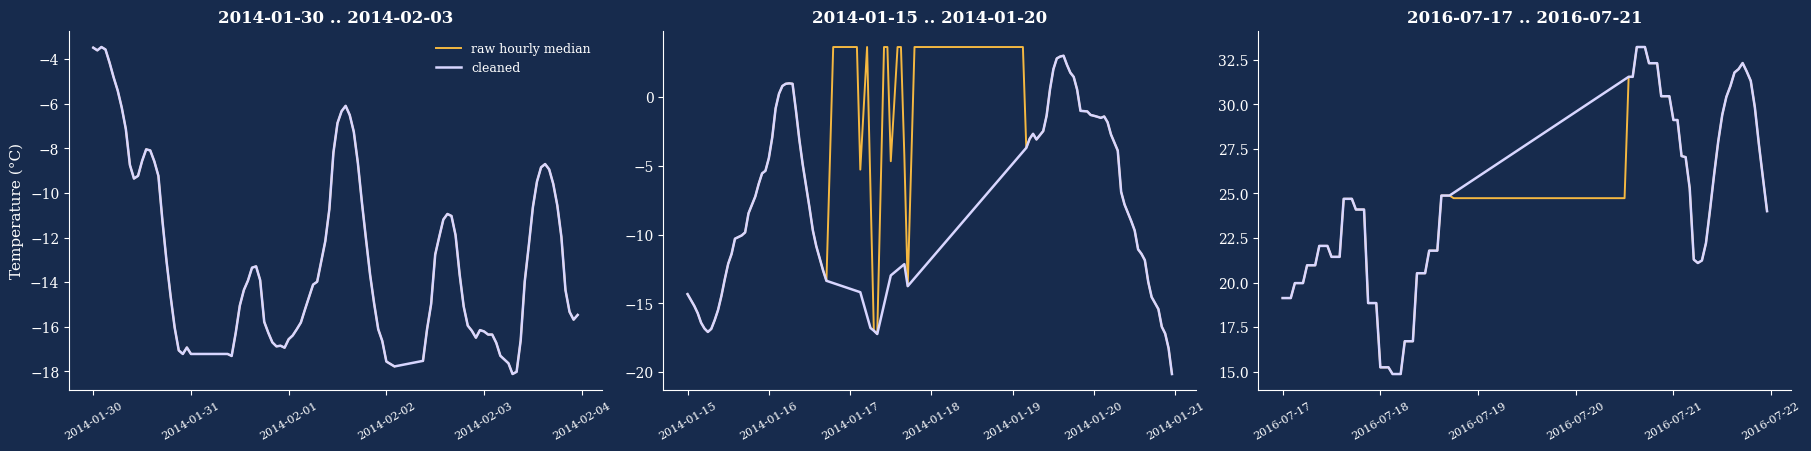

In [44]:
# before / after: raw hourly median (raw_med, from 4.2.4) vs the cleaned series
wins = [('2014-01-30', '2014-02-03'), ('2014-01-15', '2014-01-20'), ('2016-07-17', '2016-07-21')]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4), facecolor=THEME_BG, constrained_layout=True)
for i, (ax, (a, b)) in enumerate(zip(axes, wins)):
    before = raw_med[a:b].where(raw_med[a:b] > 0) - KELVIN_OFFSET      # 0 K shown as a gap
    ax.plot(before.index, before.values, color=THEME_ACCENT, lw=1.4, label='raw hourly median')
    after = df.loc[a:b, 'temp'] - KELVIN_OFFSET
    ax.plot(after.index, after.values, color=THEME_LAVENDER, lw=1.8, label='cleaned')
    style_axes(ax, title=f'{a} .. {b}', ylabel='Temperature (°C)' if i == 0 else None, title_size=12)
    ax.tick_params(axis='x', rotation=30, labelsize=8)
style_legend(axes[0])
plt.show()

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.6 — Kelvin → Celsius</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Cleaning and interpolation above work on the raw Kelvin values. From here on the project uses <b>°C</b>: <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">temp_c = temp − 273.15</code>, rounded to the sensor's 0.01 resolution, and the Kelvin column is dropped so that no Kelvin value reaches the feature set.</p></div>

In [45]:
df['temp_c'] = (df['temp'] - KELVIN_OFFSET).round(2)
df = df.drop(columns=['temp'])
print('temp_c range: %.1f .. %.1f °C' % (df.temp_c.min(), df.temp_c.max()))

temp_c range: -29.8 .. 36.9 °C


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.7 — Rain Outlier 9,831.3: Imputation via Label-Matched Median</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The value is imputed with the <b>median</b> of the records sharing the exact same <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_description</code> (this row itself holds "very heavy rain"). Rationale: it stays consistent with the row's label while remaining well within the empirical range of the dataset. <b>Capping at 100</b> would create an artificial value larger than any other reading in the data, which <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">log1p</code> then amplifies. The overall impact on the model is negligible (a single row out of more than 40,000), and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_rain_invalid</code> keeps track of it; should the team prefer an alternative (e.g., setting it to 0 like the adjacent hours), only this individual cell needs modification.</p></div>

In [46]:
bad = df.rain_1h.isna()
ref = df[~bad].groupby('weather_description').rain_1h.median()
print('rows to impute:', int(bad.sum()), '| label:', df.loc[bad, 'weather_description'].tolist())
df.loc[bad, 'rain_1h'] = df.loc[bad, 'weather_description'].map(ref)
assert df.rain_1h.isna().sum() == 0
print('imputed rain_1h (mm/h):', df.loc[df.qa_rain_invalid == 1, 'rain_1h'].round(2).tolist(),
      '| max rain now:', df.rain_1h.max())

rows to impute: 1 | label: ['very heavy rain']
imputed rain_1h (mm/h): [23.75] | max rain now: 55.63


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.8 — Weather Label Columns Removed from the Features</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_main</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_description</code> have now served their purpose (merging duplicate hourly reports and imputing the rain outlier), so they are dropped: weather labels are <b>not</b> features. The numeric weather measurements (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">temp_c</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">rain_1h</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">snow_1h</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">clouds_all</code>) are kept.</p></div>

In [47]:
df = df.drop(columns=['weather_main', 'weather_description'])
print('columns now:', list(df.columns))

columns now: ['rain_1h', 'snow_1h', 'clouds_all', 'traffic_volume', 'year', 'month', 'hour', 'qa_rain_invalid', 'qa_n_reports', 'qa_temp_imputed', 'temp_c']


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.3.9 — Flagging Suspect Target Values (Without Modifying the Target)</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The target <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">traffic_volume</code> is never modified. Hours below 100 vehicles/h are only flagged with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_low_volume</code> (see 4.2.8).</p></div>

In [48]:
df['qa_low_volume'] = (df.traffic_volume < LOW_VOLUME_THRESHOLD).astype('int8')
print('flagged:', int(df.qa_low_volume.sum()), f'({100*df.qa_low_volume.mean():.2f}% of rows)')

flagged: 46 (0.11% of rows)


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">4.4 — Feature Engineering</h3></div>
<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.4.1 — Calendar and Cyclical Features</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Retained: <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">year</code> (long-term trend), <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">month</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day_of_week</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_weekend</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">season</code>. <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">year</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">month</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code> come straight from the EDA section; only <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day_of_week</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_weekend</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">season</code> and the sin/cos encodings are new here. <b>Deliberately omitted:</b> <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day_name</code> (redundant with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day_of_week</code>), <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">week_of_year</code>/<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day_of_year</code> (high collinearity with month) and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day</code> (day of the month; carries no meaningful traffic signal).</p><p style="margin:0 0 8px 0;">Hour, day of the week and month are cyclical: 23 and 0 differ by 23 units numerically, yet they are adjacent in time. A <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">sin/cos</code> transformation resolves this for linear models and neural networks (tree-based models do not need it).</p></div>

In [49]:
idx = df.index
df['day_of_week'] = idx.dayofweek          # 0 = Monday
df['is_weekend'] = (df.day_of_week >= 5).astype('int8')
df['season'] = pd.Categorical(df.month.map({12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
                                            6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Fall', 10: 'Fall', 11: 'Fall'}),
                              categories=['Winter', 'Spring', 'Summer', 'Fall'])
for name, val, period in [('hour', df.hour, 24), ('dow', df.day_of_week, 7), ('month', df.month - 1, 12)]:
    df[f'{name}_sin'] = np.sin(2 * np.pi * val / period)
    df[f'{name}_cos'] = np.cos(2 * np.pi * val / period)
df[['year', 'month', 'hour', 'day_of_week', 'season', 'hour_sin', 'hour_cos']].head(3)

,year,month,hour,day_of_week,season,hour_sin,hour_cos
date_time,,,,,,,
2012-10-02 09:00:00,2012,10,9,1,Fall,0.707107,-0.707107
2012-10-02 10:00:00,2012,10,10,1,Fall,0.500000,-0.866025
2012-10-02 11:00:00,2012,10,11,1,Fall,0.258819,-0.965926


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.4.2 — Rush Hour</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Rush hours are established from domain knowledge (business commuting patterns); the data only <b>validates</b> them. Key takeaway: weekends show an entirely different pattern (no morning peak), so <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_rush_hour</code> is active on <b>workdays</b> only.</p></div>

hours >= 85% of weekday peak: [6, 7, 8, 15, 16, 17] | chosen a priori: [6, 7, 8, 15, 16, 17]


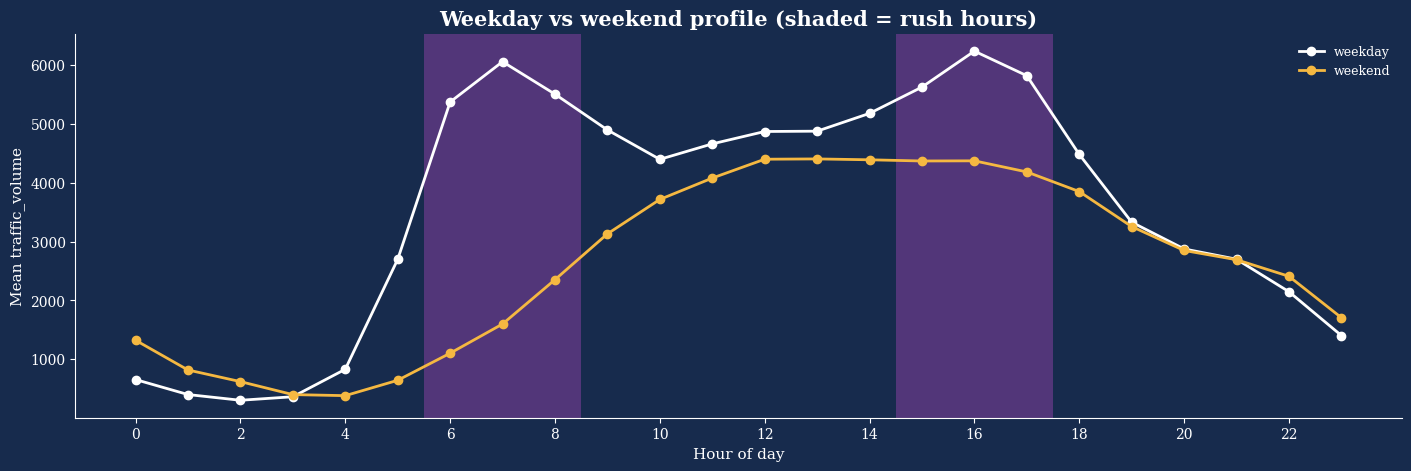

mean traffic: rush 5773 | non-rush 2756


In [50]:
prof = df.groupby(['hour', 'is_weekend']).traffic_volume.mean().unstack('is_weekend')
prof.columns = ['weekday', 'weekend']

data_rush = prof.index[prof.weekday >= 0.85 * prof.weekday.max()].tolist()
print('hours >= 85% of weekday peak:', data_rush, '| chosen a priori:', RUSH_HOURS)
assert data_rush == RUSH_HOURS

fig, ax = plt.subplots(figsize=(14, 4.6), facecolor=THEME_BG, constrained_layout=True)
for h in RUSH_HOURS:
    ax.axvspan(h - .5, h + .5, color=THEME_PURPLE, alpha=.6, linewidth=0)
ax.plot(prof.index, prof.weekday, marker='o', color='white', lw=2, label='weekday')
ax.plot(prof.index, prof.weekend, marker='o', color=THEME_ACCENT, lw=2, label='weekend')
ax.set_xticks(range(0, 24, 2))
style_axes(ax, title='Weekday vs weekend profile (shaded = rush hours)', xlabel='Hour of day',
           ylabel='Mean traffic_volume', title_size=15)
style_legend(ax)
plt.show()

df['is_rush_hour'] = ((df.day_of_week < 5) & df.hour.isin(RUSH_HOURS)).astype('int8')
print('mean traffic: rush %.0f | non-rush %.0f' % (df.loc[df.is_rush_hour == 1, 'traffic_volume'].mean(),
                                                  df.loc[df.is_rush_hour == 0, 'traffic_volume'].mean()))

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">4.4.3 — Weather Features (Numeric)</h4></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">temp_c</code>: temperature in °C (cleaned in 4.3.5 and converted from Kelvin in 4.3.6).</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_freezing</code>: binary flag for temperatures below 0 °C.</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_raining</code> / <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_snowing</code> / <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">precipitation_flag</code>: about 95 % of rows record zero precipitation; a binary presence/absence flag provides a discrete signal that gets drowned out in the raw continuous values.</li><li style="margin-bottom:4px;"><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">rain_1h_log1p</code> / <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">snow_1h_log1p</code>: highly right-skewed distributions, log-transformed with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">log1p</code> for scale-sensitive models.</li></ul><p style="margin:0 0 8px 0;">The weather <b>labels</b> (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_main</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_description</code>) are intentionally not features (see 4.3.8).</p></div>

In [51]:
df['is_freezing'] = (df.temp_c < 0).astype('int8')
df['is_raining'] = (df.rain_1h > 0).astype('int8')
df['is_snowing'] = (df.snow_1h > 0).astype('int8')
df['precipitation_flag'] = ((df.rain_1h > 0) | (df.snow_1h > 0)).astype('int8')
df['rain_1h_log1p'] = np.log1p(df.rain_1h)
df['snow_1h_log1p'] = np.log1p(df.snow_1h)
print('share with rain: %.3f | snow: %.4f' % (df.is_raining.mean(), df.is_snowing.mean()))

share with rain: 0.051 | snow: 0.0008


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">4.5 — Final Validation (Explicit Asserts) and Export</h3></div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The next cell puts the columns in their final order (target, features, then <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_*</code> columns) and runs explicit <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">assert</code> checks, so the notebook fails loudly if any step is broken or reordered. The clean dataset is then saved to <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">../data/data_cleaning.csv</code>.</p></div>

In [52]:
# ---- final column layout ----
TARGET = 'traffic_volume'
QA_COLS = [c for c in df.columns if c.startswith('qa_')]      # all audit/trace columns carry the qa_ prefix
FEATURES = [c for c in df.columns if c != TARGET and c not in QA_COLS]
df = df[[TARGET] + FEATURES + QA_COLS].sort_index()

# ---- assertions: the notebook fails loudly if anything is violated ----
raw_tv = raw.drop_duplicates('date_time').set_index('date_time').traffic_volume
assert df.index.is_unique and df.index.is_monotonic_increasing
assert len(df) == raw.date_time.nunique()
assert df.isna().sum().sum() == 0, 'unexpected missing values'
assert df[TARGET].equals(raw_tv.reindex(df.index)), 'target was modified!'
assert 'temp' not in df.columns and df.temp_c.between(-50, 50).all(), 'temperature must be in degrees C'
assert df.rain_1h.between(0, 60).all() and df.snow_1h.between(0, 1).all() and df.clouds_all.between(0, 100).all()
assert df.loc[df.is_weekend == 1, 'is_rush_hour'].sum() == 0
assert not df.columns.str.contains('holiday|state_fair|weather').any(), 'weather/holiday columns must not be in the output'
assert all(not c.startswith('qa_') for c in FEATURES) and TARGET not in FEATURES
print('ALL ASSERTIONS PASSED')
print('rows x cols:', df.shape, '| features:', len(FEATURES), '| qa columns:', QA_COLS)

ALL ASSERTIONS PASSED
rows x cols: (40575, 28) | features: 23 | qa columns: ['qa_rain_invalid', 'qa_n_reports', 'qa_temp_imputed', 'qa_low_volume']


In [53]:
dictionary = pd.DataFrame({'dtype': df[FEATURES + QA_COLS].dtypes.astype(str),
                           'n_unique': df[FEATURES + QA_COLS].nunique(),
                           'role': ['feature'] * len(FEATURES) + ['QA / do NOT train on'] * len(QA_COLS)})
dictionary

,dtype,n_unique,role
rain_1h,float64,375,feature
snow_1h,float64,12,feature
clouds_all,int16,64,feature
year,int32,7,feature
month,int32,12,feature
hour,int32,24,feature
temp_c,float64,5460,feature
day_of_week,int32,7,feature
is_weekend,int8,2,feature
season,category,4,feature


In [54]:
OUTPUT_PATH = '../data/data_cleaning.csv'
out = df.reset_index()
out.to_csv(OUTPUT_PATH, index=False)
print('saved:', OUTPUT_PATH, '| shape:', out.shape)

saved: ../data/data_cleaning.csv | shape: (40575, 29)


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">4.6 — Summary Report</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
<p style="margin:0 0 8px 0;">Starting from the EDA frame, we <b>audited the raw CSV before changing anything</b>, cleaned it in a deliberate order, engineered features, and validated everything with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px;">assert</code> checks.</p>
<p style="margin:0;"><b>Result:</b> 48,204 raw rows → <b>40,575 rows (one per hour)</b>, 0 missing values, 23 features + the target + 4 <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px;">qa_*</code> columns. The target <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px;">traffic_volume</code> was never modified (asserted against the raw data).</p>
</div>

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">Problems found and how we solved them</h4></div>

<table style="width:100%; border-collapse:collapse; font-family:'Segoe UI', sans-serif; font-size:0.95em; color:#1f2937; direction:ltr; text-align:left;">
<thead><tr style="background:#1e3a5f; color:#ffffff;">
<th style="padding:8px 10px; border:1px solid #b8c2cc;">Problem (evidence)</th>
<th style="padding:8px 10px; border:1px solid #b8c2cc;">Solution</th>
</tr></thead>
<tbody>
<tr><td style="padding:8px 10px; border:1px solid #b8c2cc;"><b>Duplicates</b>: 17 exact rows, plus 5,430 hours with 2–6 reports (the target is identical inside each hour; only the weather report differs)</td>
<td style="padding:8px 10px; border:1px solid #b8c2cc;">Exact duplicates dropped in the EDA. Merged to <b>one row per hour</b>: median for numeric columns, mode on the <b>(main, description) pair</b> for labels, so no impossible pairs such as <i>Mist + light snow</i>.</td></tr>
<tr style="background:#f4f7fb;"><td style="padding:8px 10px; border:1px solid #b8c2cc;"><b>Invalid temperatures</b>: 0 K (10 rows) and stuck values 276.793 K / 297.888 K (121 rows, up to 43 consecutive hours, off by up to ~30 °C)</td>
<td style="padding:8px 10px; border:1px solid #b8c2cc;">Set to <code>NaN</code> <b>before</b> merging, time-interpolated (max 48 h between valid neighbours), converted to °C, flagged with <code>qa_temp_imputed</code> (127 hours).</td></tr>
<tr><td style="padding:8px 10px; border:1px solid #b8c2cc;"><b>Rain = 9,831.3 mm/h</b> (next highest real value: 55.6; neighbouring hours: 0)</td>
<td style="padding:8px 10px; border:1px solid #b8c2cc;">Imputed with the median of rows sharing the same label (≈ 23.75 mm) instead of an arbitrary cap; flagged with <code>qa_rain_invalid</code>.</td></tr>
<tr style="background:#f4f7fb;"><td style="padding:8px 10px; border:1px solid #b8c2cc;"><b>Label casing</b>: <i>Sky is Clear</i> vs <i>sky is clear</i></td>
<td style="padding:8px 10px; border:1px solid #b8c2cc;">Lower-cased and stripped before merging.</td></tr>
<tr><td style="padding:8px 10px; border:1px solid #b8c2cc;"><b><code>holiday</code> is 99.87 % empty</b> (structural absence)</td>
<td style="padding:8px 10px; border:1px solid #b8c2cc;">Not imputed. Holiday/event information and the weather labels are excluded from the features (team decision); the labels are used only as helpers, then dropped.</td></tr>
<tr style="background:#f4f7fb;"><td style="padding:8px 10px; border:1px solid #b8c2cc;"><b>Missing hours</b>: 22.8 % of hourly slots, with a 307-day gap (Aug 2014 → Jun 2015)</td>
<td style="padding:8px 10px; border:1px solid #b8c2cc;">Documented only. The target is never filled and no lag features are built.</td></tr>
<tr><td style="padding:8px 10px; border:1px solid #b8c2cc;"><b>Suspicious target values</b>: 46 hours below 100 vehicles/h in 9 clusters (sensor outage or road closure, which cannot be told apart)</td>
<td style="padding:8px 10px; border:1px solid #b8c2cc;">Kept unchanged and flagged with <code>qa_low_volume</code>.</td></tr>
</tbody>
</table>

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">Features, limitations and next steps</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
<ul style="margin:4px 0 8px 22px; padding:0;">
<li><b>Features:</b> calendar (<code>year</code>, <code>month</code>, <code>day_of_week</code>, <code>hour</code>, <code>is_weekend</code>, <code>season</code>), sin/cos encodings of hour, day of week and month, weekday-only <code>is_rush_hour</code> (hours 6–8 and 15–17), and numeric weather (<code>temp_c</code>, freezing/rain/snow/precipitation flags, <code>log1p</code> of rain and snow, plus raw <code>rain_1h</code>, <code>snow_1h</code>, <code>clouds_all</code>).</li>
<li><b>Limitations:</b> 127 interpolated temperature hours lose their daily cycle; one suspicious but unprovable temperature jump (2013-02-03 18:00) was left as is; the 307-day gap splits the series in two.</li>
<li><b>For modeling:</b> use a time-based train/test split, never train on <code>qa_*</code> columns (<code>qa_low_volume</code> would leak the target), fit scalers and encoders on the training set only, and re-run the EDA statistics on the cleaned file.</li>
</ul>
<p style="margin:0;"><b>Output:</b> <code>../data/data_cleaning.csv</code> (40,575 × 29, including <code>date_time</code>).</p>
</div>

<a id="5"></a>
<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif;"><h2 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">Linear Regression</h2></div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.1 — Setup and Carried-Over Assumptions</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">This notebook starts from the clean file written by section 4.5 of the cleaning notebook (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">../data/data_cleaning.csv</code>, one row per hour). <b>Every decision made there is kept</b>:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b>Target</b> <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">traffic_volume</code> is never modified, filled or imputed.</li><li style="margin-bottom:4px;"><b>Features</b> = the 23 columns built in 4.4 (calendar, sin/cos encodings, rush hour, numeric weather). Columns with the prefix <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_</code> are audit columns and are <b>never used as features</b> (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_low_volume</code> would leak the target).</li><li style="margin-bottom:4px;"><b>No</b> holiday/event columns and <b>no</b> weather label columns in the baseline (team decision). Section 6 tests that decision explicitly.</li><li style="margin-bottom:4px;"><b>Temperature</b> is in &deg;C (cleaned and interpolated in 4.3.5/4.3.6).</li><li style="margin-bottom:4px;"><b>Time-based split</b>: the oldest 80&nbsp;% of the hours train the model, the newest 20&nbsp;% test it. No random shuffling, because neighbouring hours are strongly correlated and shuffling would leak.</li><li style="margin-bottom:4px;"><b>Scaler and encoder are fitted on the training set only</b> (inside a scikit-learn <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Pipeline</code>).</li><li style="margin-bottom:4px;"><b>No lag features</b>: 22.8&nbsp;% of the hourly slots are missing, so a &ldquo;previous row&rdquo; can be months away.</li></ul></div>

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">5.1.1 — Imports, Paths and Chart Theme</h4></div>

In [55]:

CLEAN_PATH = '../data/data_cleaning.csv'                      # written by section 4.5
RAW_PATH = '../data/Metro_Interstate_Traffic_Volume.csv'      # only needed in section 6 (weather labels)
TARGET = 'traffic_volume'
TEST_FRACTION = 0.20

# Chart theme: identical to the cleaning notebook (dark navy background, purple, white serif text)
THEME_BG = '#172B4D'
THEME_PURPLE = '#7B3F98'
THEME_LAVENDER = '#D8D6FF'
THEME_ACCENT = '#F5B841'


def style_axes(ax, title=None, xlabel=None, ylabel=None, title_size=13):
    # Apply the notebook's dark theme to one axes.
    ax.set_facecolor(THEME_BG)
    if title is not None:
        ax.set_title(title, fontsize=title_size, fontweight='bold', fontfamily='serif', color='white')
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=11, fontfamily='serif', color='white')
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=11, fontfamily='serif', color='white')
    ax.tick_params(axis='both', colors='white', labelfontfamily='serif')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('white')
    ax.spines['bottom'].set_color('white')


def style_legend(ax, **kwargs):
    return ax.legend(frameon=False, labelcolor='white', prop={'family': 'serif', 'size': 9}, **kwargs)

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.2 — Load the Clean Data and Split by Time</h3></div>

In [56]:
df = (pd.read_csv("../data/data_cleaning.csv", parse_dates=['date_time'])
        .sort_values('date_time').set_index('date_time'))

QA_COLS = [c for c in df.columns if c.startswith('qa_')]
FEATURES = [c for c in df.columns if c != TARGET and c not in QA_COLS]
CAT_COLS = ['season']
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

assert df.index.is_unique and df.index.is_monotonic_increasing
assert df.isna().sum().sum() == 0
assert len(FEATURES) == 23, 'the cleaning notebook defines 23 features'
assert not any(c.startswith('qa_') for c in FEATURES)
print('rows:', len(df), '| features:', len(FEATURES), '| qa columns (never features):', QA_COLS)

# ---- chronological split ----
split_idx = int(len(df) * (1 - TEST_FRACTION))
train, test = df.iloc[:split_idx], df.iloc[split_idx:]
print(f'train: {len(train):,} rows  {train.index.min()} -> {train.index.max()}')
print(f'test : {len(test):,} rows  {test.index.min()} -> {test.index.max()}')
print('years in train:', sorted(train.year.unique().tolist()), '| years in test:', sorted(test.year.unique().tolist()))

rows: 40575 | features: 23 | qa columns (never features): ['qa_rain_invalid', 'qa_n_reports', 'qa_temp_imputed', 'qa_low_volume']
train: 32,460 rows  2012-10-02 09:00:00 -> 2017-10-26 17:00:00
test : 8,115 rows  2017-10-26 18:00:00 -> 2018-09-30 23:00:00
years in train: [2012, 2013, 2014, 2015, 2016, 2017] | years in test: [2017, 2018]


In [57]:
print("Unique timestamps:", df.index.is_unique)
print("Sorted timestamps:", df.index.is_monotonic_increasing)
print("Duplicate timestamps:", df.index.duplicated().sum())
print(df.index[df.index.duplicated(keep=False)].unique()[:10])

Unique timestamps: True
Sorted timestamps: True
Duplicate timestamps: 0
DatetimeIndex([], dtype='datetime64[ns]', name='date_time', freq=None)


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;"><b>Note on <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">year</code>:</b> with a time-based split, the test period can contain a <b>year value that never appears in training</b>. A linear model then extrapolates the year trend linearly. This is realistic for forecasting but can inflate test error; compare the models below with and without <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">year</code> if the test error looks odd.</p></div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.3 — Helper Functions (Pipeline, Metrics, Diagnostics)</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Everything below is reusable: each model in this notebook is fitted by the single function <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">run_model()</code> and stored in the dictionary <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">RESULTS</code>. <b>Because of that, any optional section can be deleted without breaking the rest.</b></p></div>

In [58]:
RESULTS = {}


def adj_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)


def score(y, yhat, n_params):
    r2 = r2_score(y, yhat)
    return {'R2': r2,
            'Adj_R2': adj_r2(r2, len(y), n_params),
            'MAE': mean_absolute_error(y, yhat),
            'RMSE': float(np.sqrt(mean_squared_error(y, yhat)))}


def build_pipeline(num_cols, cat_cols=()):
    # numeric columns -> StandardScaler, categorical -> one-hot (first level dropped as reference)
    steps = [('num', StandardScaler(), list(num_cols))]
    if len(cat_cols):
        steps.append(('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), list(cat_cols)))
    prep = ColumnTransformer(steps, verbose_feature_names_out=False)
    prep.set_output(transform='pandas')
    return Pipeline([('prep', prep), ('lr', LinearRegression())])


def run_model(name, data, num_cols, cat_cols=(), train_filter=None, log_target=False, note=''):
    # Fit one linear regression on the chronological train part and score it on the test part.
    # train_filter: optional boolean Series (same index as data) that removes rows from TRAINING only.
    # log_target:   fit on log1p(traffic_volume), then back-transform; all metrics stay in vehicles/hour.
    cat_cols = list(cat_cols)
    cols = list(num_cols) + cat_cols
    tr, te = data.iloc[:split_idx], data.iloc[split_idx:]
    if train_filter is not None:
        tr = tr[train_filter.loc[tr.index].values]

    y_tr, y_te = tr[TARGET], te[TARGET]
    y_fit = np.log1p(y_tr) if log_target else y_tr
    pipe = build_pipeline(num_cols, cat_cols).fit(tr[cols], y_fit)

    def predict(d):
        raw_pred = pipe.predict(d[cols])
        return np.clip(np.expm1(raw_pred), 0, None) if log_target else raw_pred

    yhat_tr, yhat_te = predict(tr), predict(te)
    prep = pipe.named_steps['prep']
    n_params = len(prep.get_feature_names_out())
    X_tr = prep.transform(tr[cols])
    res = dict(name=name, note=note, n_train=len(tr), n_features=n_params, log_target=log_target,
               train=score(y_tr, yhat_tr, n_params), test=score(y_te, yhat_te, n_params),
               pipe=pipe, X_tr=X_tr, resid_fit=pd.Series(np.asarray(y_fit) - pipe.predict(tr[cols]), index=tr.index),
               idx_te=te.index, y_te=y_te, yhat_te=pd.Series(yhat_te, index=te.index))
    RESULTS[name] = res
    return res


def metrics_table(results):
    rows = []
    for r in results:
        rows.append({'model': r['name'], 'n_features': r['n_features'], 'n_train': r['n_train'],
                     'train R2': r['train']['R2'], 'test R2': r['test']['R2'], 'test adj R2': r['test']['Adj_R2'],
                     'train RMSE': r['train']['RMSE'], 'test RMSE': r['test']['RMSE'], 'test MAE': r['test']['MAE']})
    return pd.DataFrame(rows).set_index('model').round(3)


def cv_report(num_cols, cat_cols=(), n_splits=5):
    # Expanding-window cross-validation inside the TRAIN part only (the test part is never touched).
    cols = list(num_cols) + list(cat_cols)
    tr = df.iloc[:split_idx]
    rows = []
    for k, (a, b) in enumerate(TimeSeriesSplit(n_splits=n_splits).split(tr), 1):
        pipe = build_pipeline(num_cols, cat_cols).fit(tr.iloc[a][cols], tr.iloc[a][TARGET])
        yh, y = pipe.predict(tr.iloc[b][cols]), tr.iloc[b][TARGET]
        rows.append({'fold': k, 'train rows': len(a), 'validation rows': len(b),
                     'R2': r2_score(y, yh), 'RMSE': np.sqrt(mean_squared_error(y, yh))})
    out = pd.DataFrame(rows).set_index('fold')
    out.loc['mean'] = out.mean()
    return out.round(3)


def diagnostics(res):
    # Six standard evaluation plots for one fitted model (test part).
    y, yh = res['y_te'], res['yhat_te']
    resid = y - yh
    fig, axes = plt.subplots(2, 3, figsize=(19, 10), facecolor=THEME_BG, constrained_layout=True)

    ax = axes[0, 0]
    ax.scatter(yh, y, s=6, alpha=0.35, color=THEME_PURPLE)
    lim = [min(y.min(), yh.min()), max(y.max(), yh.max())]
    ax.plot(lim, lim, color=THEME_ACCENT, lw=1.6, label='perfect prediction')
    style_axes(ax, 'Actual vs Predicted', 'Predicted traffic_volume', 'Actual traffic_volume')
    style_legend(ax)

    ax = axes[0, 1]
    ax.scatter(yh, resid, s=6, alpha=0.35, color=THEME_PURPLE)
    ax.axhline(0, color=THEME_ACCENT, lw=1.6)
    style_axes(ax, 'Residuals vs Predicted', 'Predicted traffic_volume', 'Residual (actual - predicted)')

    ax = axes[0, 2]
    sns.histplot(resid, bins=50, ax=ax, color=THEME_PURPLE)
    ax.axvline(0, color=THEME_ACCENT, lw=1.6)
    style_axes(ax, 'Residual Distribution', 'Residual', 'Frequency')

    ax = axes[1, 0]
    (osm, osr), (slope, intercept, _) = stats.probplot(resid, dist='norm')
    ax.scatter(osm, osr, s=6, alpha=0.5, color=THEME_PURPLE)
    ax.plot(osm, slope * np.asarray(osm) + intercept, color=THEME_ACCENT, lw=1.6)
    style_axes(ax, 'Normal Q-Q Plot of Residuals', 'Theoretical quantiles', 'Sample quantiles')

    ax = axes[1, 1]
    by_hour = resid.groupby(resid.index.hour).agg(['mean', 'std'])
    ax.plot(by_hour.index, by_hour['mean'], color='white', marker='o', lw=2, label='mean residual')
    ax.fill_between(by_hour.index, by_hour['mean'] - by_hour['std'], by_hour['mean'] + by_hour['std'],
                    color=THEME_PURPLE, alpha=0.55, label='+/- 1 std')
    ax.axhline(0, color=THEME_ACCENT, lw=1.4)
    ax.set_xticks(range(0, 24, 2))
    style_axes(ax, 'Residuals by Hour of Day', 'Hour', 'Residual')
    style_legend(ax)

    ax = axes[1, 2]
    last = y.index.max() - pd.Timedelta(days=7)
    w = y.index >= last
    ax.plot(y.index[w], y[w], color='white', lw=1.6, label='actual')
    ax.plot(yh.index[w], yh[w], color=THEME_ACCENT, lw=1.6, label='predicted')
    ax.tick_params(axis='x', rotation=30)
    style_axes(ax, 'Last 7 Days of the Test Period', None, 'traffic_volume')
    style_legend(ax)

    fig.suptitle(res['name'], fontsize=16, fontweight='bold', fontfamily='serif', color='white')
    plt.show()


def plot_coefficients(res, top=None):
    # Coefficients of the standardized model: effect on traffic_volume of +1 std (one-hot dummies: vs the reference level).
    names = res['pipe'].named_steps['prep'].get_feature_names_out()
    coef = pd.Series(res['pipe'].named_steps['lr'].coef_, index=names).sort_values(key=np.abs)
    if top:
        coef = coef.iloc[-top:]
    fig, ax = plt.subplots(figsize=(11, 0.38 * len(coef) + 2), facecolor=THEME_BG, constrained_layout=True)
    ax.barh(coef.index, coef.values, color=[THEME_PURPLE if v >= 0 else THEME_ACCENT for v in coef.values])
    ax.axvline(0, color='white', lw=0.8)
    style_axes(ax, 'Coefficients: ' + res['name'], 'Change in traffic_volume (vehicles/hour)')
    plt.show()


def vif_table(X):
    # Variance inflation factor of every column, from first principles (no extra library).
    M = X.values.astype(float)
    out = {}
    for j, name in enumerate(X.columns):
        y = M[:, j]
        A = np.column_stack([np.ones(len(M)), np.delete(M, j, axis=1)])
        beta, *_ = np.linalg.lstsq(A, y, rcond=None)
        r2 = 1 - ((y - A @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        out[name] = np.inf if r2 >= 1 - 1e-12 else 1 / (1 - r2)
    return pd.Series(out, name='VIF').sort_values(ascending=False)


def assumption_report(res):
    # Residual checks on the TRAINING fit: autocorrelation, heteroscedasticity, normality, multicollinearity.
    e = res['resid_fit'].values
    X = res['X_tr'].values
    dw = np.sum(np.diff(e) ** 2) / np.sum(e ** 2)
    A = np.column_stack([np.ones(len(X)), X])
    e2 = e ** 2
    beta, *_ = np.linalg.lstsq(A, e2, rcond=None)
    r2_bp = 1 - ((e2 - A @ beta) ** 2).sum() / ((e2 - e2.mean()) ** 2).sum()
    lm = len(e) * r2_bp
    p_bp = stats.chi2.sf(lm, X.shape[1])
    summary = pd.Series({'Durbin-Watson (2 = no autocorrelation)': dw,
                         'Breusch-Pagan LM p-value (< 0.05 = heteroscedastic)': p_bp,
                         'residual skewness': stats.skew(e),
                         'residual excess kurtosis': stats.kurtosis(e)}).round(4)
    return summary, vif_table(res['X_tr'])

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.4 — Model A: Baseline Linear Regression (All 23 Features)</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The baseline uses <b>exactly the final feature set of the cleaning notebook</b>: the numeric columns are standardized, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">season</code> is one-hot encoded (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">Fall</code> is the reference level). Ordinary least squares, no regularisation.</p><p style="margin:0 0 8px 0;">Variants that change the features, the target or the training rows come later in 5.7, each in its own section.</p></div>

In [59]:
res_a = run_model('A  Baseline (23 features)', df, NUM_COLS, CAT_COLS,
                  note='final feature set of section 4.4, OLS, no transformation of the target')
print('number of model inputs after encoding:', res_a['n_features'])
metrics_table([res_a])

number of model inputs after encoding: 25


,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,0.857,749.963,744.872,559.248


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">5.4.1 — Time-Series Cross-Validation (Inside the Training Part)</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Five expanding windows, each validated on the block that follows it. A large spread between folds means the relationship is <b>not stable over time</b>; a mean much worse than the single test score would hint at an unlucky test split.</p></div>

In [60]:
cv_report(NUM_COLS, CAT_COLS)

,train rows,validation rows,R2,RMSE
fold,,,,
1,5410.0,5410.0,0.395,1554.976
2,10820.0,5410.0,0.871,717.445
3,16230.0,5410.0,0.837,811.881
4,21640.0,5410.0,0.849,738.993
5,27050.0,5410.0,0.867,724.985
mean,16230.0,5410.0,0.764,909.656


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">5.4.2 — Evaluation Plots</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">What to look for:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b>Actual vs Predicted</b>: points should hug the line. Horizontal bands mean the model cannot separate rush hours from quiet hours.</li><li style="margin-bottom:4px;"><b>Residuals by Hour</b>: a smooth wave here means the model misses the daily double peak (a linear model cannot bend). This is the main reason for the variants in 5.7.</li><li style="margin-bottom:4px;"><b>Q-Q plot and histogram</b>: heavy tails or a bimodal histogram show that one equation is trying to describe two regimes (weekday vs weekend, day vs night).</li><li style="margin-bottom:4px;"><b>Residuals vs Predicted</b>: a funnel shape means the error grows with the traffic level (heteroscedasticity).</li></ul></div>

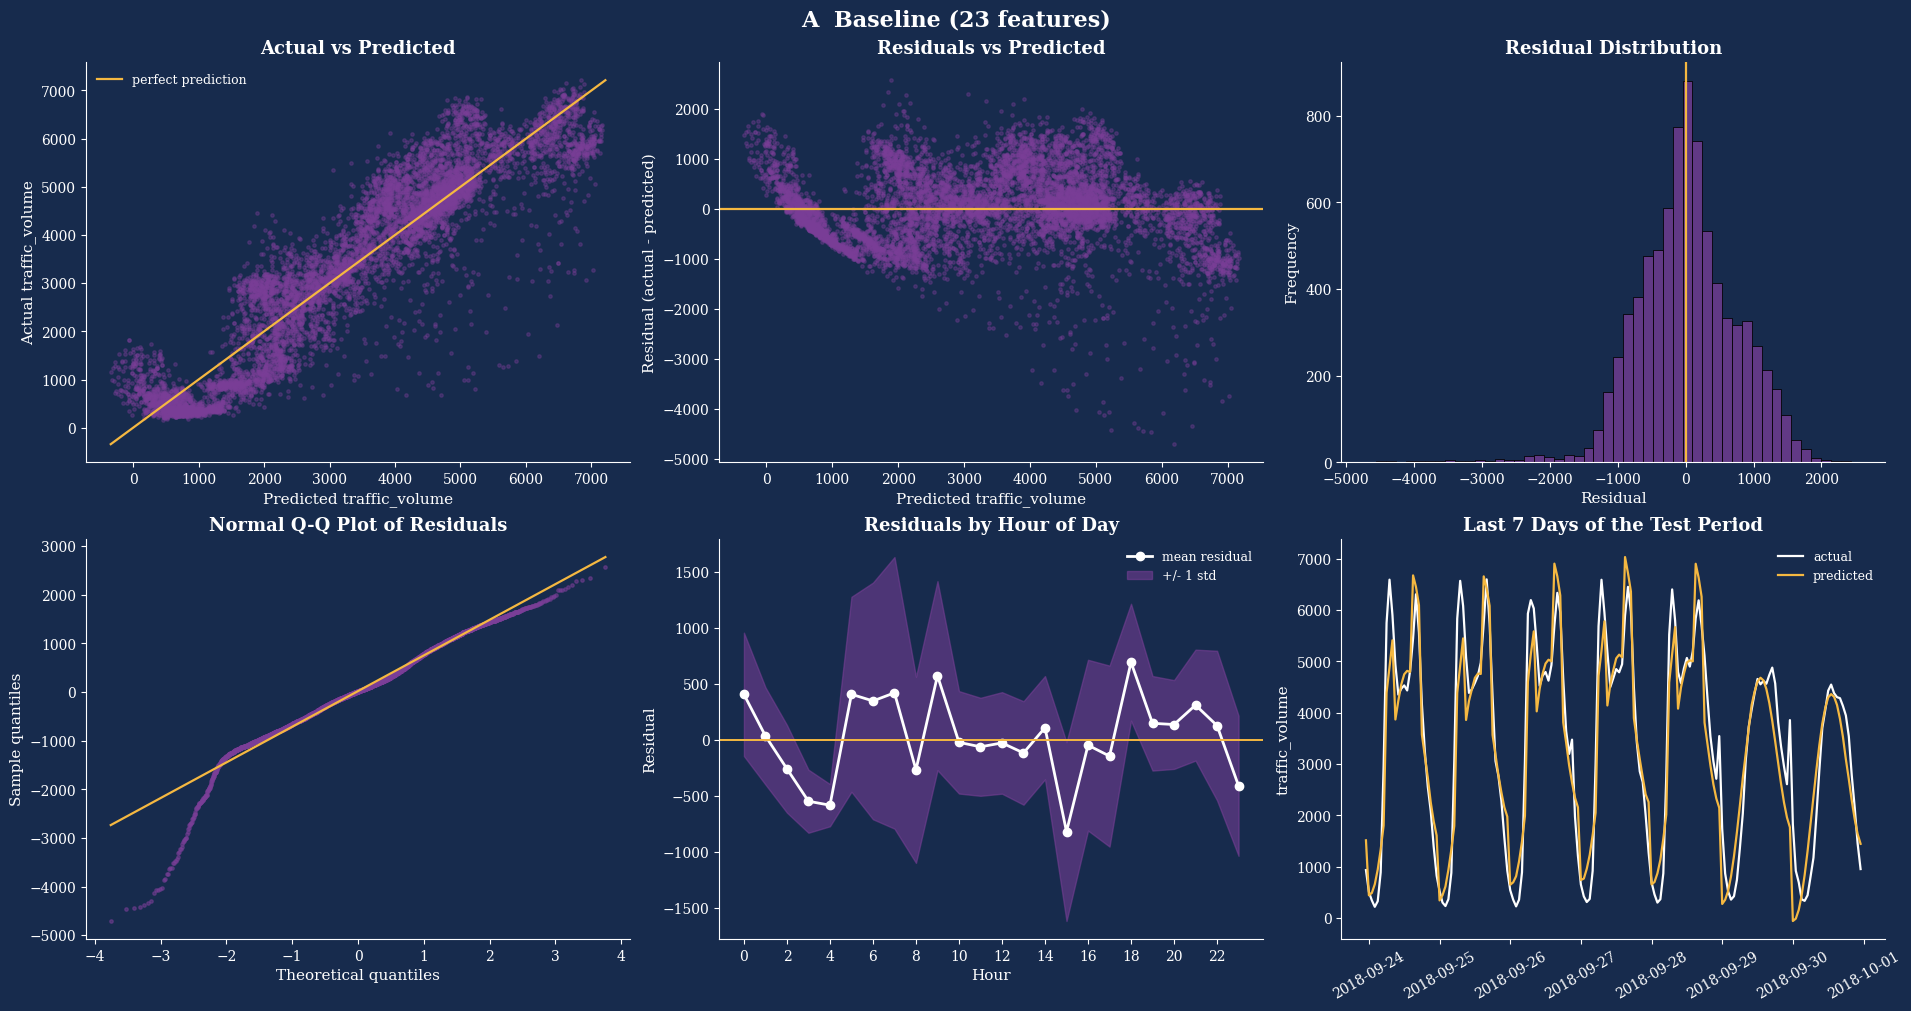

In [61]:
diagnostics(res_a)

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">5.4.3 — Coefficients</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Numeric inputs are standardized, so every bar reads &ldquo;change in vehicles/hour for a +1 standard deviation move of that input, all else equal&rdquo;; the one-hot <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">season</code> bars are differences versus the reference season. Several inputs describe the <b>same</b> thing in different forms (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code> / <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour_sin</code> / <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour_cos</code>; <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">rain_1h</code> / <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">rain_1h_log1p</code> / <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_raining</code>), so their individual coefficients are not interpretable on their own; see the VIF table below.</p></div>

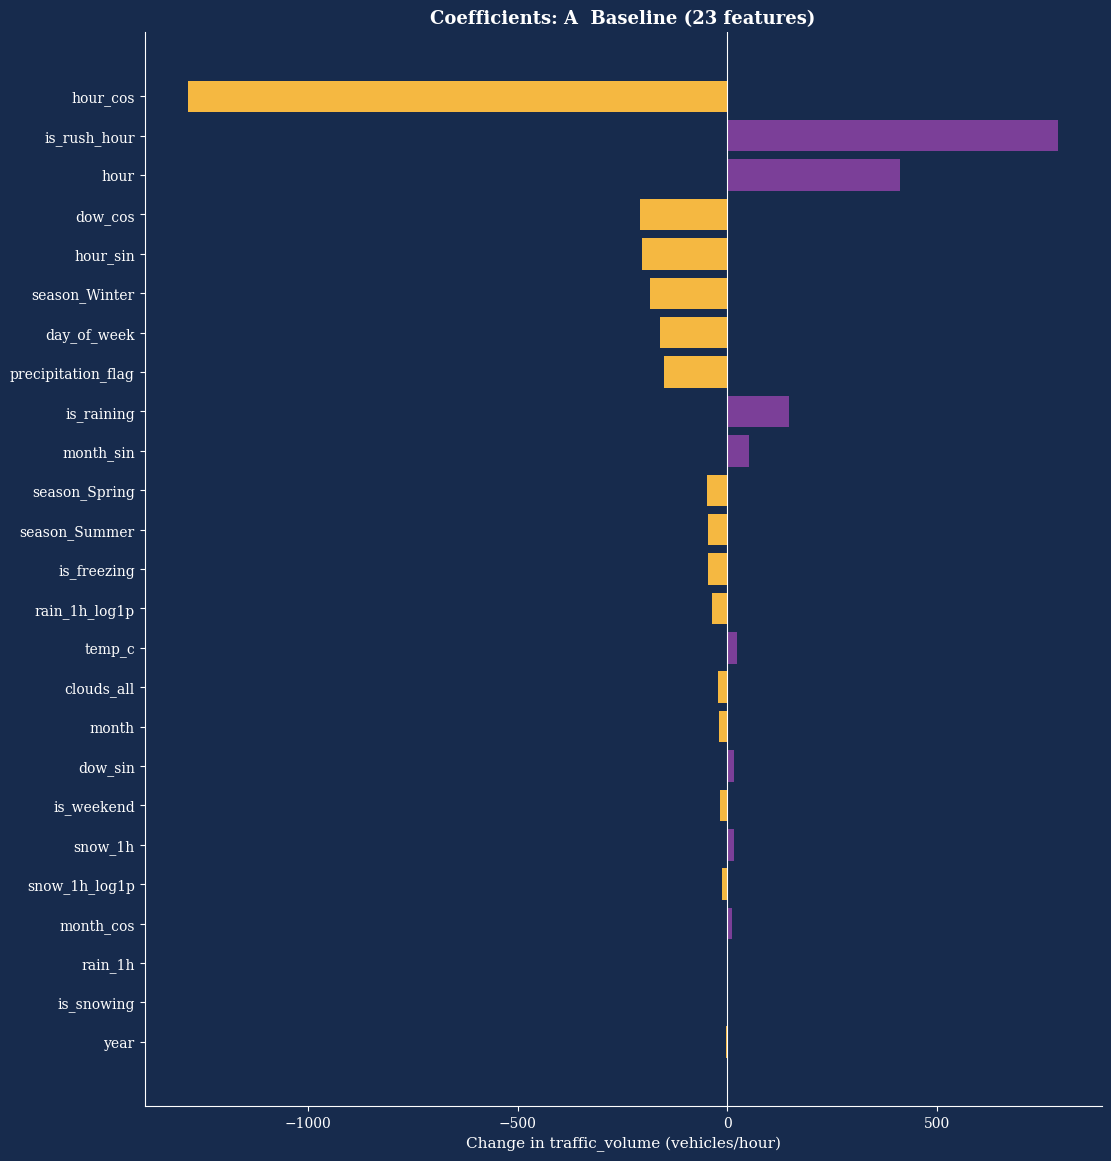

In [62]:
plot_coefficients(res_a)

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.5 — Checking the Linear-Regression Assumptions</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">OLS predictions are still usable when assumptions are violated, but <b>standard errors, p-values and coefficient signs are not</b>. Four checks on the training residuals:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b>Durbin-Watson</b>: values far below 2 mean consecutive hours have correlated errors (expected for hourly traffic). The hourly series has gaps, so treat it as approximate.</li><li style="margin-bottom:4px;"><b>Breusch-Pagan</b>: a small p-value means the error variance is not constant.</li><li style="margin-bottom:4px;"><b>Skewness / kurtosis</b>: departures from normality of the residuals.</li><li style="margin-bottom:4px;"><b>VIF</b>: above ~10 means an input is largely explained by the others (multicollinearity). Perfect linear redundancy shows as <i>inf</i>.</li></ul></div>

In [63]:
summary_a, vif_a = assumption_report(res_a)
print(summary_a.to_string())
print()
vif_a.round(2).to_frame()

Durbin-Watson (2 = no autocorrelation)                 0.8457
Breusch-Pagan LM p-value (< 0.05 = heteroscedastic)    0.0000
residual skewness                                     -0.4596
residual excess kurtosis                               2.4478



,VIF
precipitation_flag,2662.15
is_raining,2618.94
snow_1h_log1p,1175.26
snow_1h,1079.32
is_snowing,50.00
month_sin,10.56
season_Spring,10.25
month_cos,9.86
day_of_week,8.55
is_weekend,8.27


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.6 — Fixing the Model: Why the Optional Variants Follow</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">A single straight line over <b>standardized, raw-coded inputs</b> has three structural weaknesses for this data:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;">Traffic follows a <b>double-peak daily curve</b> that differs between weekdays and weekends; a model that is linear in <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code> cannot draw it.</li><li style="margin-bottom:4px;">The target is <b>right-skewed</b> and its spread grows with the level.</li><li style="margin-bottom:4px;">The set of inputs is <b>redundant</b> (raw and cyclical encodings of the same variable).</li></ul><p style="margin:0 0 8px 0;">Each variant below attacks one of these problems. Every variant is a <b>separate section that writes only to <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">RESULTS</code></b>: delete any section you do not want and the comparison in 5.8 simply skips it.</p></div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.7 — Optional Variants</h3></div>

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">V1 — Cyclical Encoding Only (Remove the Redundant Raw Columns)</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Condition: drop <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">month</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">day_of_week</code> and keep only their sin/cos pairs, as recommended in 4.4.1 for linear models. This removes the most obvious collinearity.</p></div>

In [64]:
V1_DROP = ['hour', 'month', 'day_of_week']
res_v1 = run_model('V1  Cyclical encoding only', df, [c for c in NUM_COLS if c not in V1_DROP], CAT_COLS,
                   note='drops raw hour / month / day_of_week')
metrics_table([res_a, res_v1])

,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
V1 Cyclical encoding only,22,32460,0.840,0.838,0.838,794.848,792.542,605.463


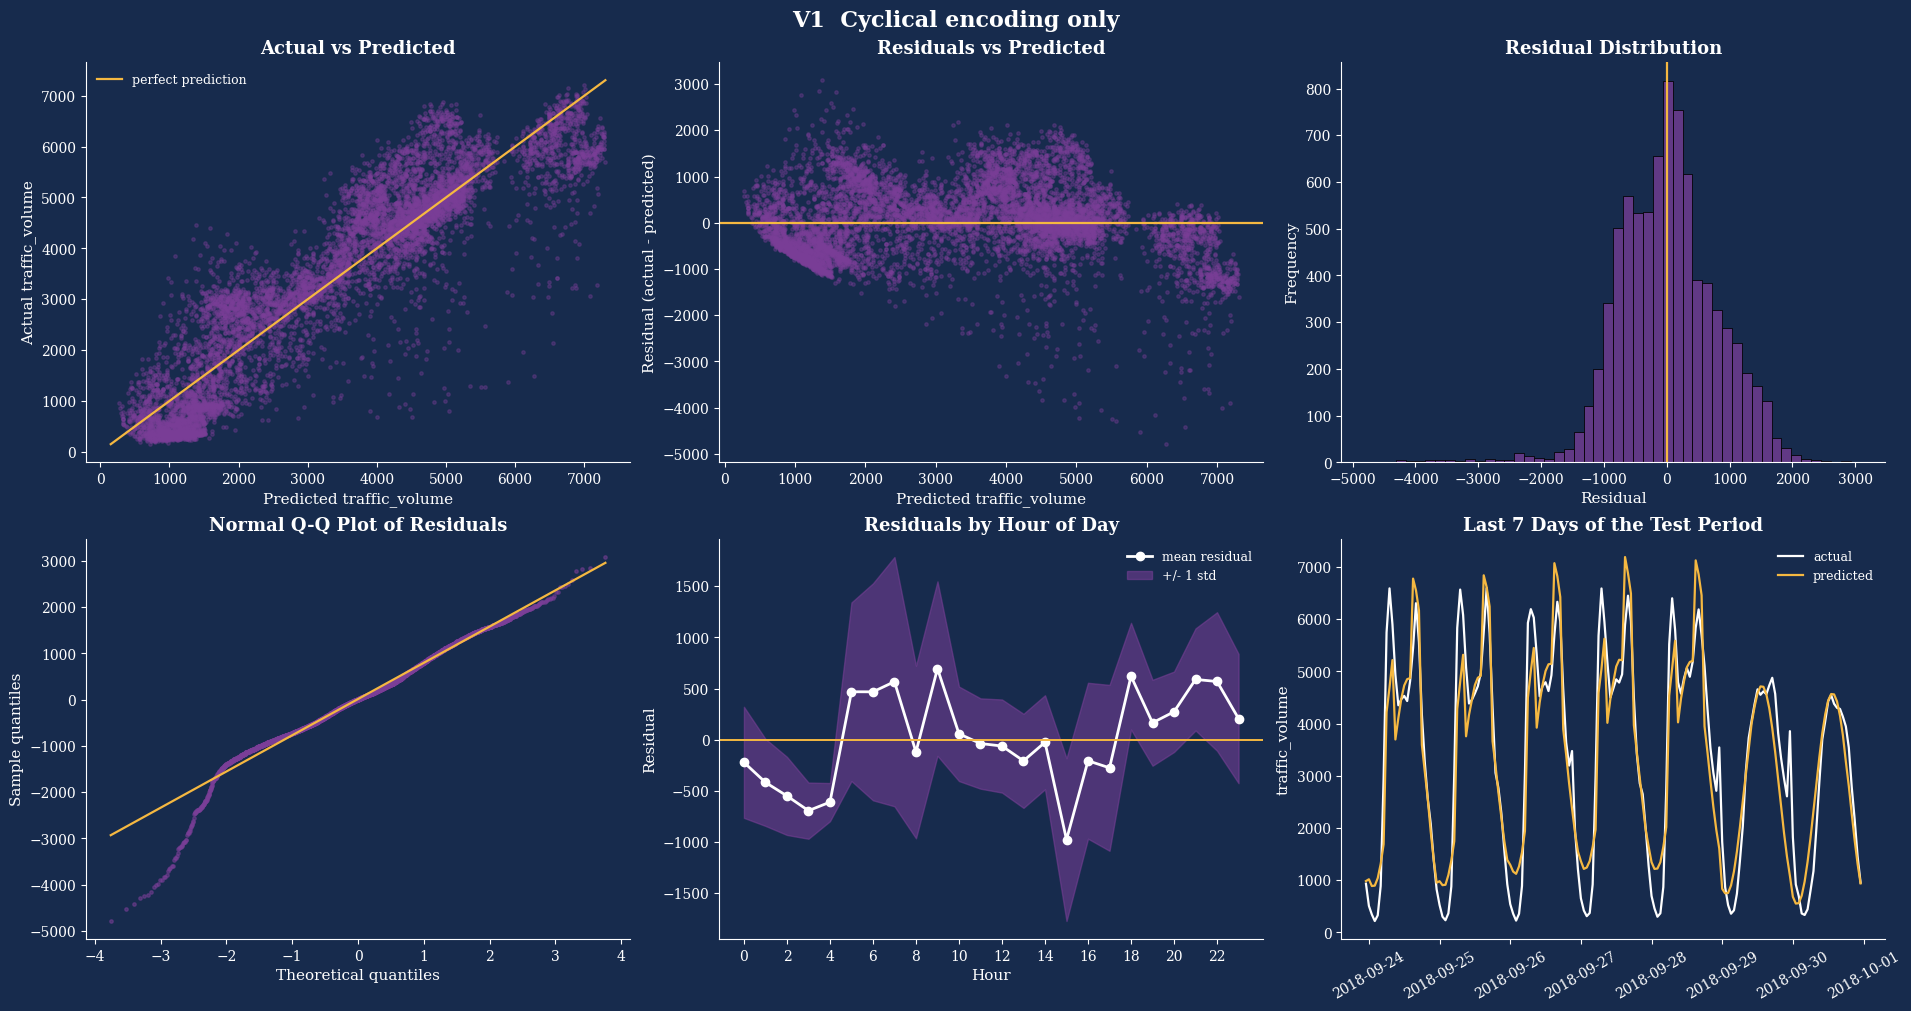

In [65]:
diagnostics(res_v1)

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">V2 — Log-Transformed Target</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Transformation: fit on <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">log1p(traffic_volume)</code> and back-transform with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">expm1</code>. All metrics below are computed back on the <b>original vehicles/hour scale</b>, so they are directly comparable with Model A. A log target turns additive effects into multiplicative ones (&ldquo;rain reduces traffic by x&nbsp;%&rdquo;) and tames the growing spread, but it can hurt when the main error comes from near-zero hours.</p></div>

In [66]:
res_v2 = run_model('V2  Log-transformed target', df, NUM_COLS, CAT_COLS, log_target=True,
                   note='fit on log1p(traffic_volume), metrics on the original scale')
metrics_table([res_a, res_v2])

,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
V2 Log-transformed target,25,32460,0.631,0.620,0.619,1207.313,1213.726,832.054


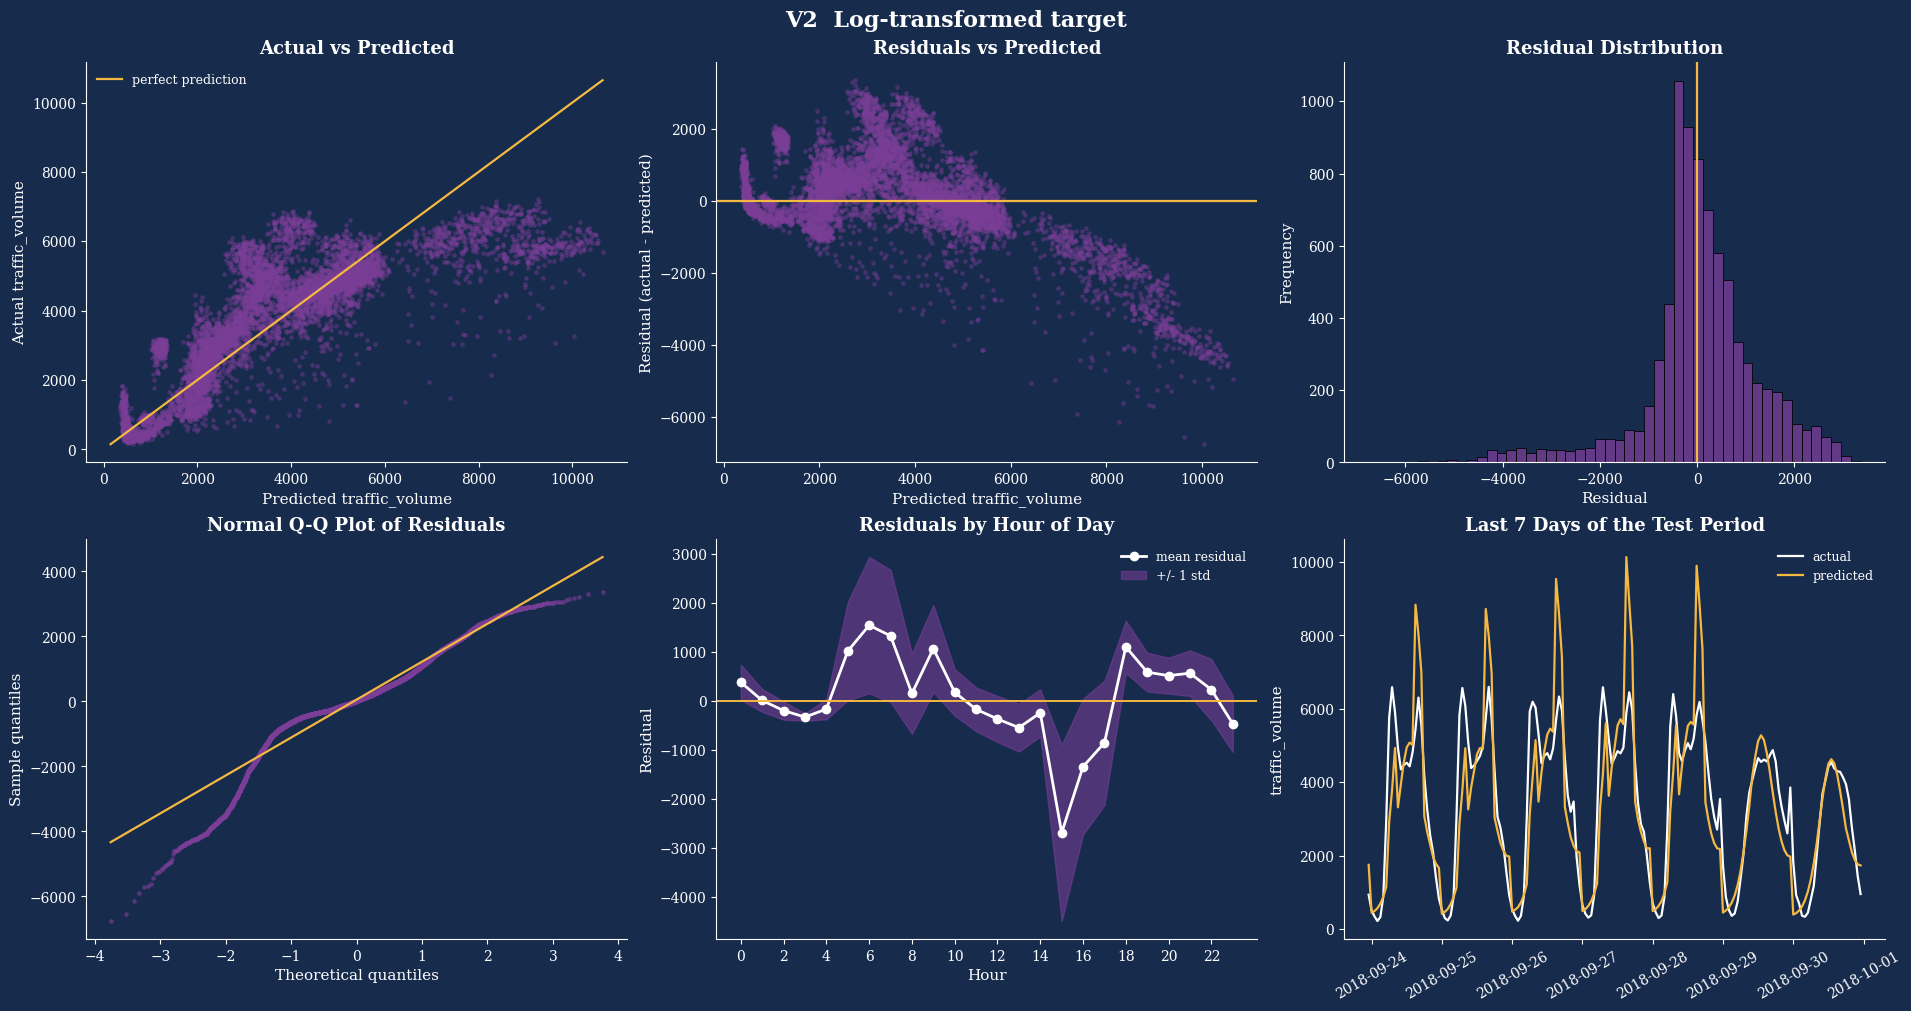

In [67]:
diagnostics(res_v2)

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">V3 — Train Without the Flagged Low-Volume Hours</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Condition: rows with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">qa_low_volume == 1</code> (fewer than 100 vehicles/h in 9 clusters: sensor outage or closure, cause unknown, see 4.2.8) are <b>removed from the training rows only</b>. The flag is used as a row filter, <b>never as an input feature</b>, and Rows with `qa_low_volume == 1` are removed from the training data only; the flag is used as a row filter, never as an input feature. The test rows remain unchanged by this filtering step. However, test-set metrics are also used later to compare multiple models, so the test period should not be described as completely untouched by the overall evaluation process., so the score is still honest and comparable.</p></div>

In [68]:
res_v3 = run_model('V3  Train without low-volume hours', df, NUM_COLS, CAT_COLS,
                   train_filter=(df.qa_low_volume == 0),
                   note='qa_low_volume used only to drop training rows')
print('training rows removed:', len(train) - res_v3['n_train'])
metrics_table([res_a, res_v3])

training rows removed: 46


,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
V3 Train without low-volume hours,25,32414,0.860,0.857,0.857,743.740,744.576,558.860


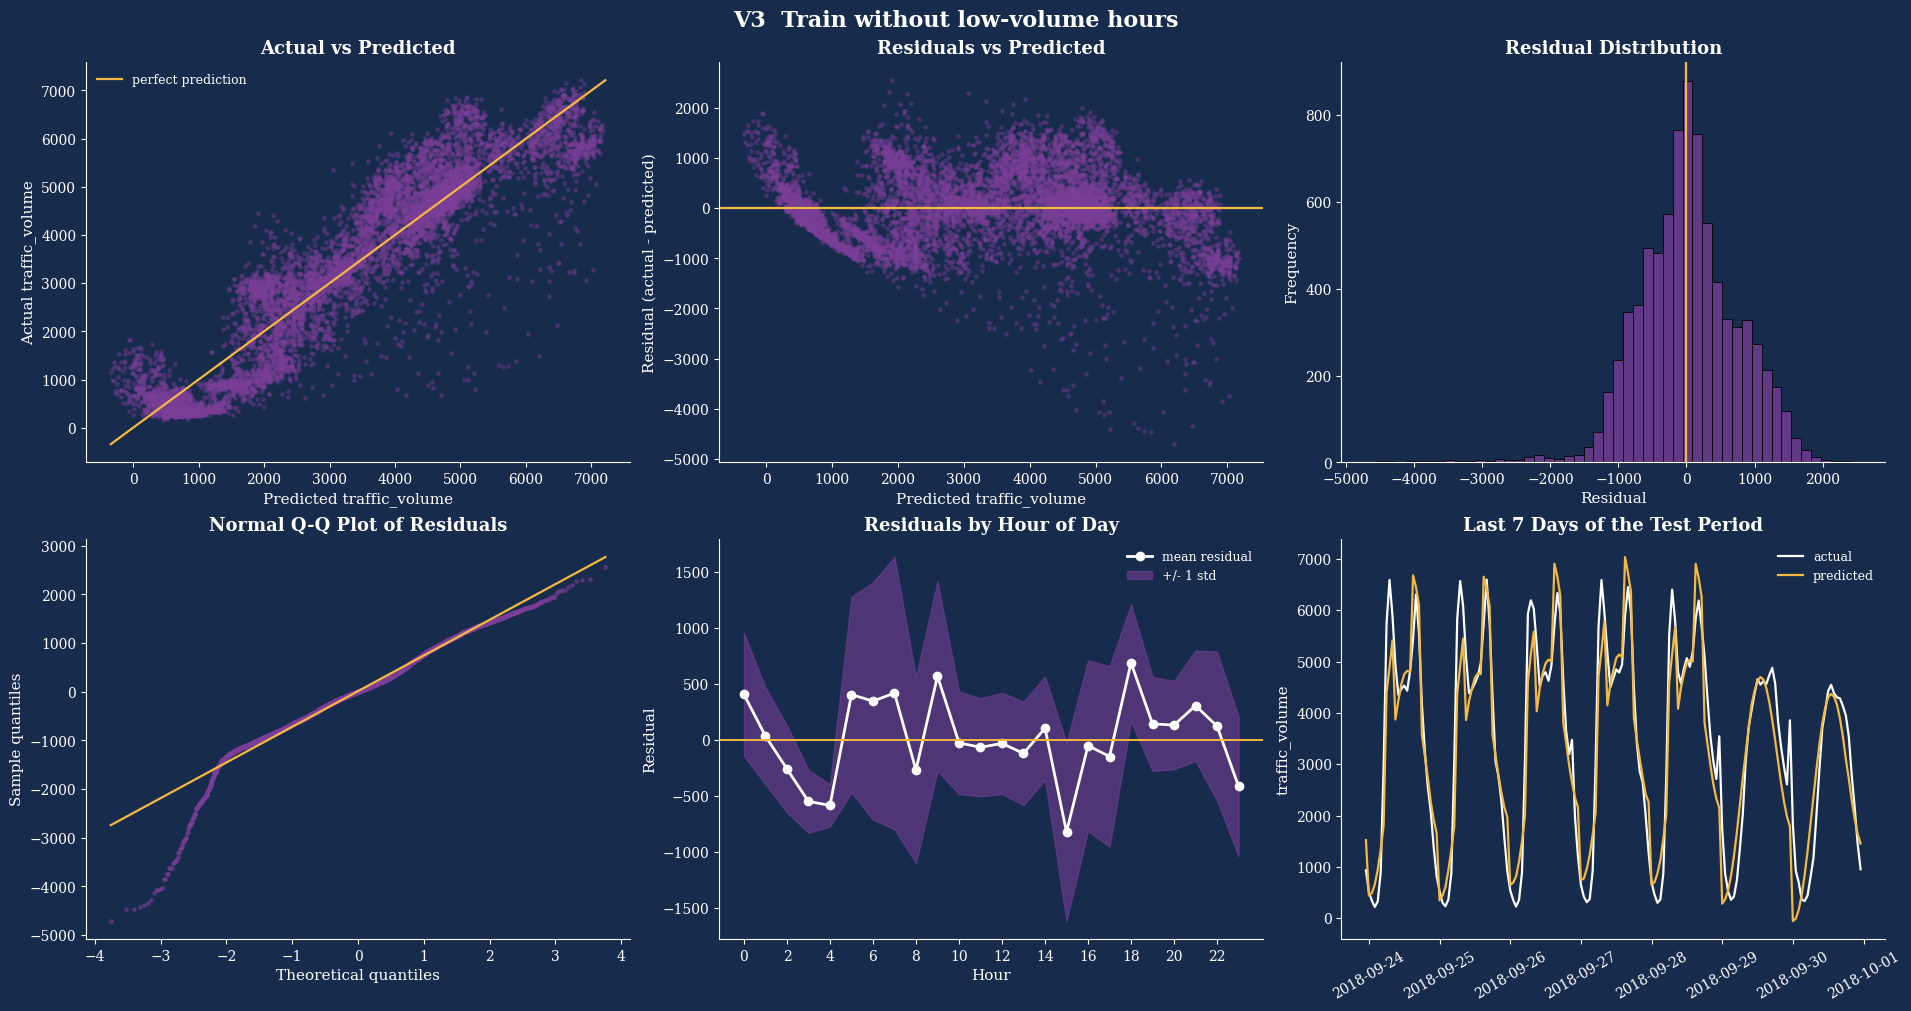

In [69]:
diagnostics(res_v3)

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">V4 — Weekday / Weekend x Hour Harmonics (Interactions)</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Transformation: add the <b>second daily harmonic</b> (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour_sin2</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">hour_cos2</code>), which lets the fitted curve have two peaks per day, and multiply the first and second harmonics by <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">is_weekend</code> so weekends get their own daily shape. This keeps the model linear in its coefficients while fixing the biggest structural error.</p></div>

In [70]:
df_v4 = df.copy()
df_v4['hour_sin2'] = np.sin(4 * np.pi * df_v4.hour / 24)
df_v4['hour_cos2'] = np.cos(4 * np.pi * df_v4.hour / 24)
V4_NEW = ['hour_sin2', 'hour_cos2']
for base in ['hour_sin', 'hour_cos', 'hour_sin2', 'hour_cos2']:
    df_v4[base + '_x_weekend'] = df_v4[base] * df_v4.is_weekend
    V4_NEW.append(base + '_x_weekend')

res_v4 = run_model('V4  Hour harmonics x weekend', df_v4, NUM_COLS + V4_NEW, CAT_COLS,
                   note='2nd harmonic + weekend interactions')
metrics_table([res_a, res_v4])

,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
V4 Hour harmonics x weekend,31,32460,0.907,0.906,0.906,607.562,603.882,425.975


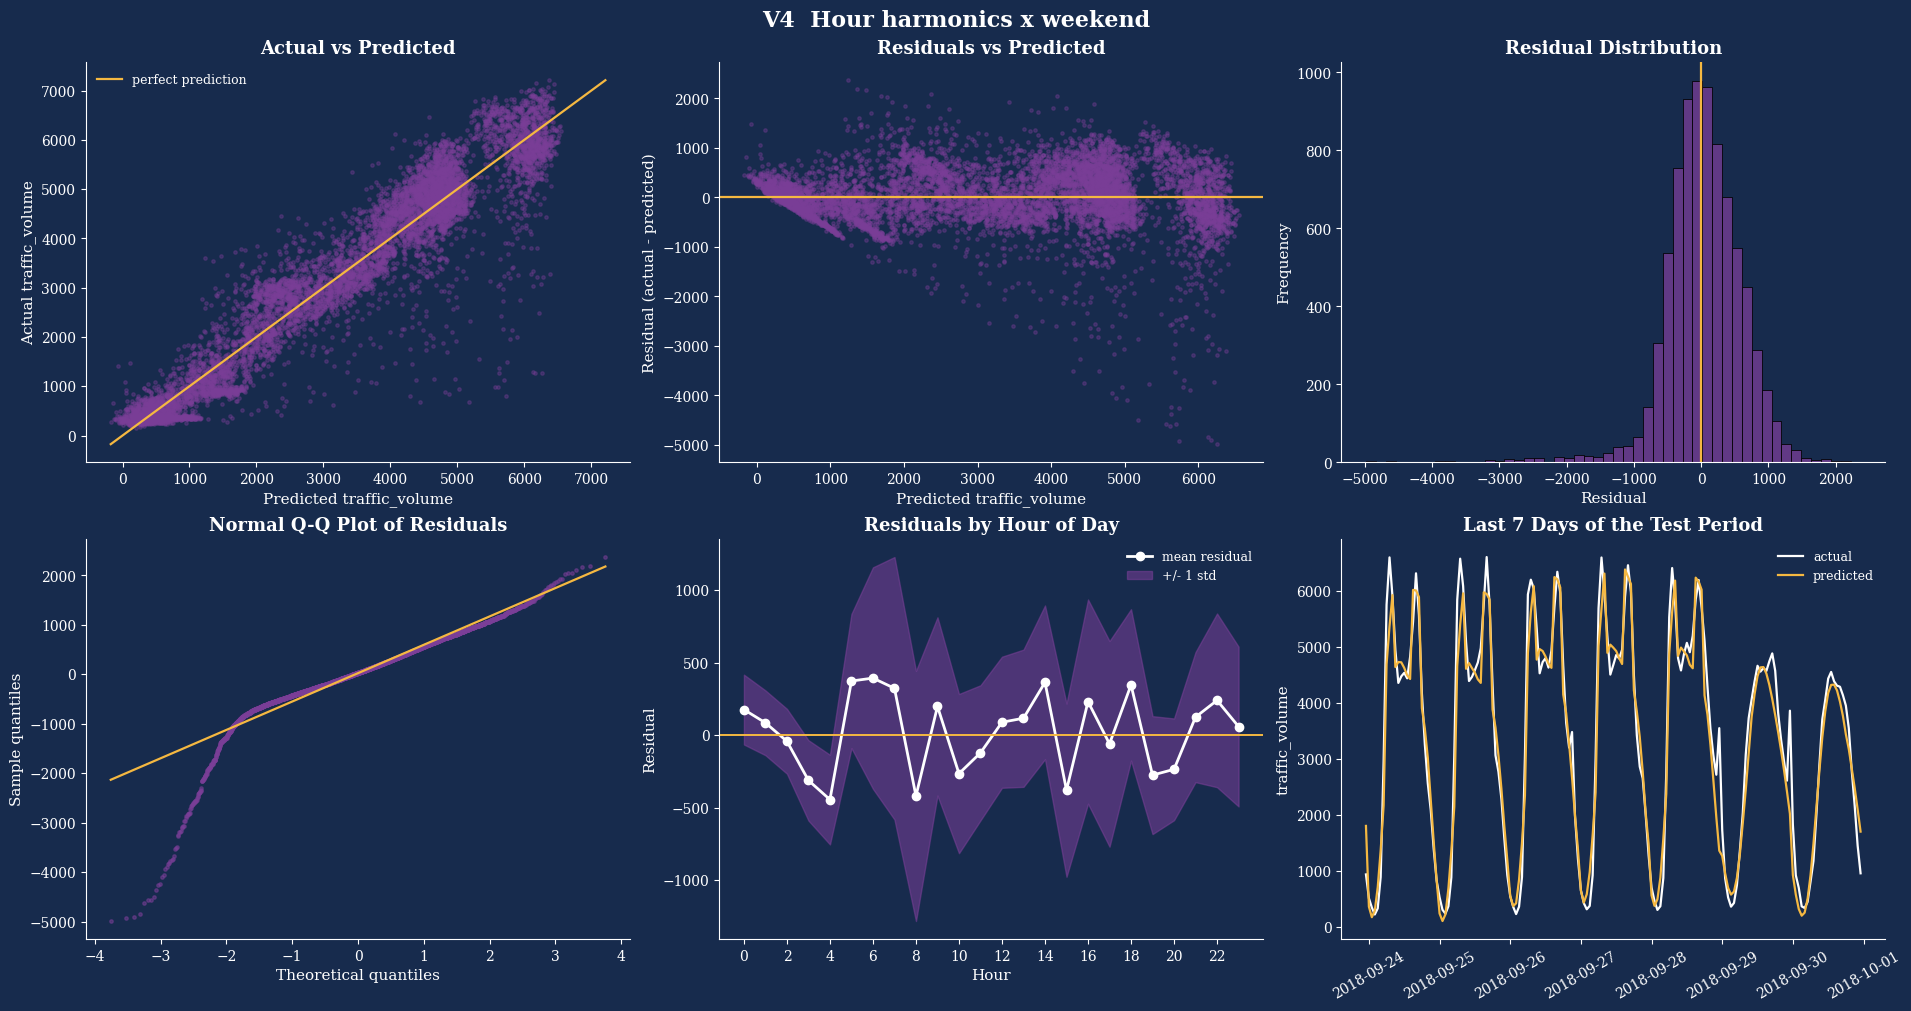

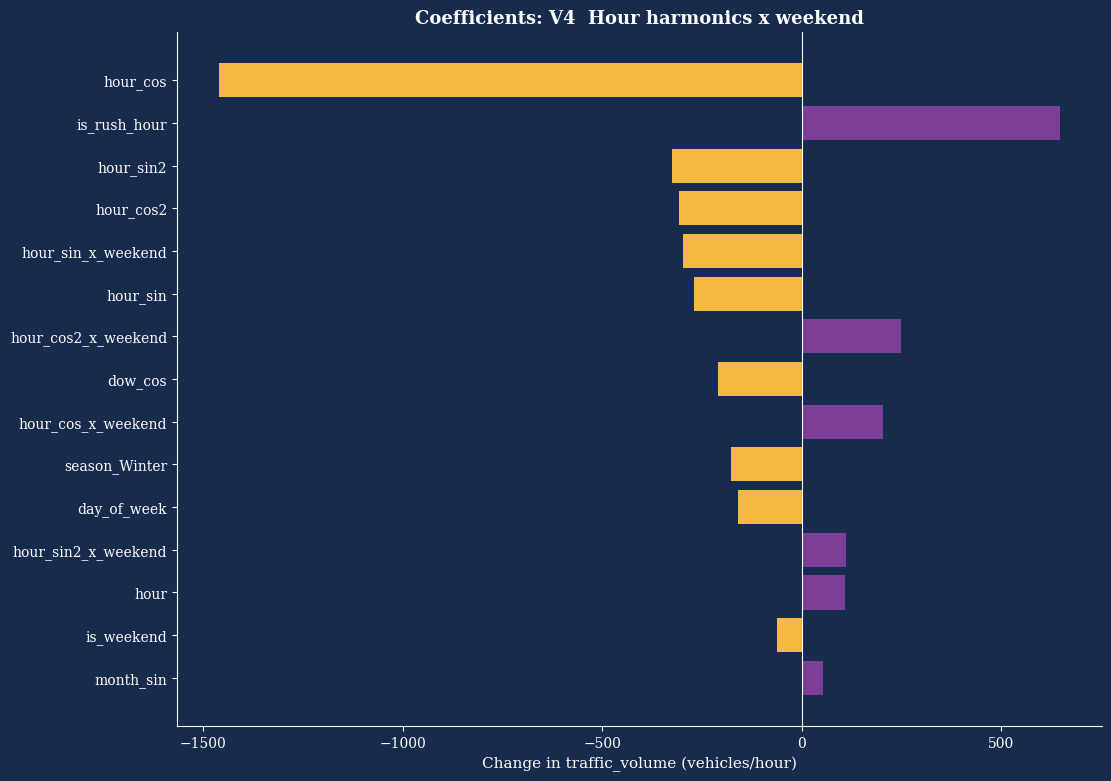

In [71]:
diagnostics(res_v4)
plot_coefficients(res_v4, top=15)

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">5.8 — Comparison of All Models</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The table and chart list every model currently stored in <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">RESULTS</code>. Lower RMSE / MAE and higher R&sup2; are better; compare the <b>test</b> columns, and look at the gap between train and test RMSE as a sign of drift over time.</p></div>

In [72]:
cmp = metrics_table(list(RESULTS.values()))
cmp

,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
V1 Cyclical encoding only,22,32460,0.840,0.838,0.838,794.848,792.542,605.463
V2 Log-transformed target,25,32460,0.631,0.620,0.619,1207.313,1213.726,832.054
V3 Train without low-volume hours,25,32414,0.860,0.857,0.857,743.740,744.576,558.860
V4 Hour harmonics x weekend,31,32460,0.907,0.906,0.906,607.562,603.882,425.975


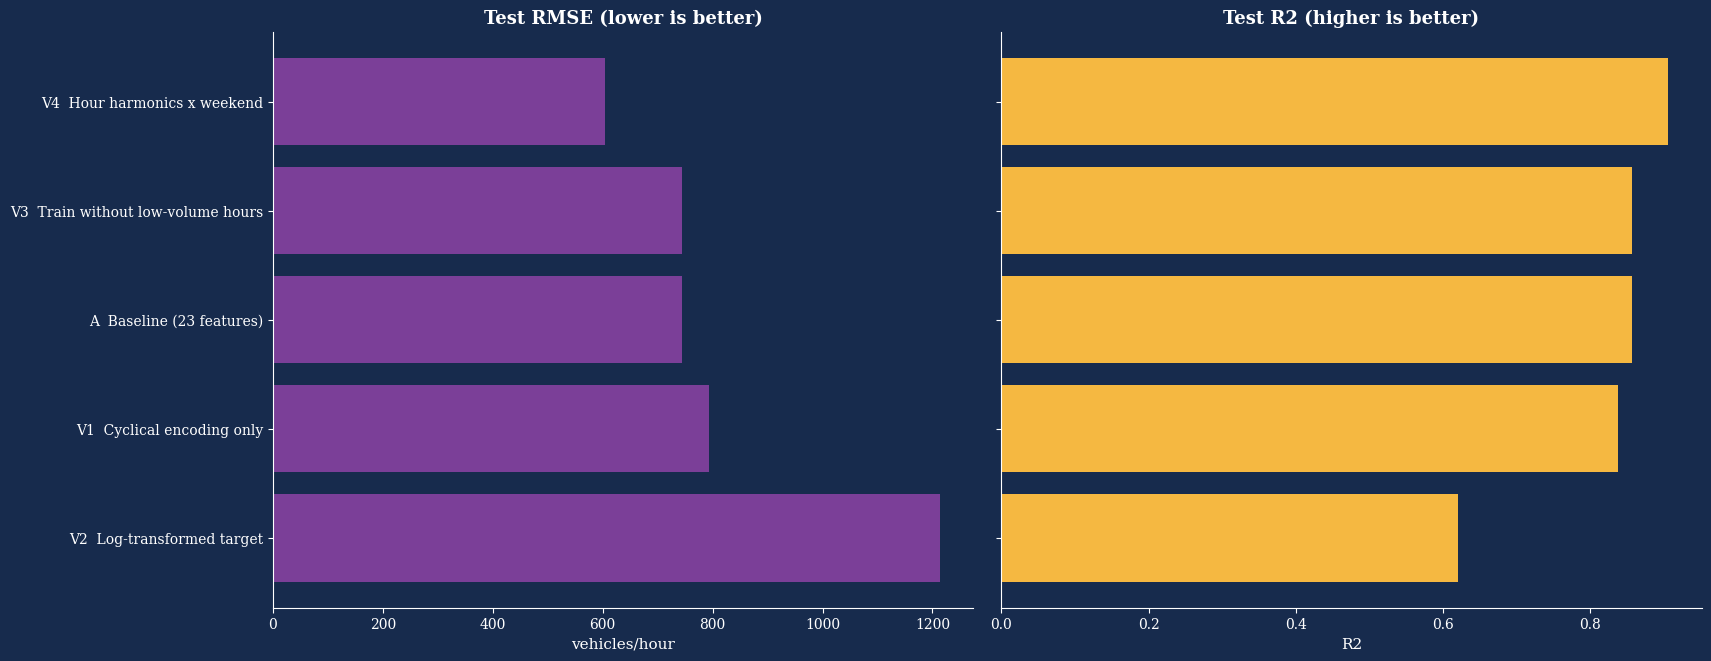

In [73]:
cmp_plot = cmp.sort_values('test RMSE', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(17, 0.7 * len(cmp_plot) + 3), facecolor=THEME_BG, constrained_layout=True)
axes[0].barh(cmp_plot.index, cmp_plot['test RMSE'], color=THEME_PURPLE)
style_axes(axes[0], 'Test RMSE (lower is better)', 'vehicles/hour')
axes[1].barh(cmp_plot.index, cmp_plot['test R2'], color=THEME_ACCENT)
style_axes(axes[1], 'Test R2 (higher is better)', 'R2')
axes[1].set_yticklabels([])
plt.show()

<br>

<a id="6"></a>
<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif;"><h2 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">Weather Groups &mdash; Does Removing the Weather Labels Matter?</h2></div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">6.1 — Question and Design</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The team decided in 4.1 to exclude <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_main</code> and <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">weather_description</code> from the features. This section measures what that decision costs. The 37 descriptions are too many and too rare to use directly (some appear fewer than five times), so they are first merged into <b>groups with a similar effect on driving conditions</b>:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b>Reduced_Visibility</b>: mist, fog, haze, smoke.</li><li style="margin-bottom:4px;"><b>Severe_Storm</b>: thunderstorms (including proximity thunderstorms) and squalls, i.e. strong wind and lightning.</li><li style="margin-bottom:4px;"><b>Light_Rain_Drizzle</b>, <b>Heavy_Rain</b>, <b>Snow_Ice</b>, and <b>Clear_Cloudy</b> (no driving impact, used as the reference level).</li></ul><p style="margin:0 0 8px 0;">Three models are then compared with the <b>same split and the same pipeline</b> as section 5:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b>W-A</b>: current baseline, numeric weather only (no groups).</li><li style="margin-bottom:4px;"><b>W-B</b>: W-A + the weather group (one-hot).</li><li style="margin-bottom:4px;"><b>W-C</b>: no weather information at all (context: how much does weather matter in total?).</li></ul><p style="margin:0 0 8px 0;">The difference between W-B and W-A is the answer to &ldquo;how much did removing the labels cost?&rdquo;.</p></div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">6.2 — Grouping Definition</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">The dictionary below is the <b>only place to edit</b> if you disagree with a group: move a description to another list and re-run from here. A check stops the notebook if any description in the raw data is not mapped.</p></div>

In [74]:
WEATHER_GROUPS = {
    'Clear_Cloudy': ['sky is clear', 'few clouds', 'scattered clouds', 'broken clouds', 'overcast clouds'],
    'Reduced_Visibility': ['mist', 'fog', 'haze', 'smoke'],
    'Light_Rain_Drizzle': ['drizzle', 'light intensity drizzle', 'heavy intensity drizzle', 'shower drizzle',
                           'light rain', 'light intensity shower rain', 'proximity shower rain'],
    'Heavy_Rain': ['moderate rain', 'heavy intensity rain', 'very heavy rain'],
    'Snow_Ice': ['light snow', 'snow', 'heavy snow', 'shower snow', 'light shower snow',
                 'sleet', 'light rain and snow', 'freezing rain'],
    'Severe_Storm': ['thunderstorm', 'proximity thunderstorm', 'thunderstorm with light rain', 'thunderstorm with rain',
                     'thunderstorm with heavy rain', 'thunderstorm with light drizzle', 'thunderstorm with drizzle',
                     'proximity thunderstorm with rain', 'proximity thunderstorm with drizzle', 'squalls'],
}
# assumed driving-impact order, only used when WEATHER_AGG = 'worst' (see 6.3)
SEVERITY_RANK = {'Clear_Cloudy': 0, 'Reduced_Visibility': 1, 'Light_Rain_Drizzle': 2,
                 'Heavy_Rain': 3, 'Snow_Ice': 4, 'Severe_Storm': 5}
WEATHER_GROUP_MAP = {d: g for g, ds in WEATHER_GROUPS.items() for d in ds}

# same text normalisation as 4.3.2 (strip, lower-case) and the same exact-duplicate removal as the EDA section
raw_w = pd.read_csv("../data/Metro_Interstate_Traffic_Volume.csv", parse_dates=['date_time']).drop_duplicates()
raw_w['weather_main'] = raw_w['weather_main'].str.strip()
raw_w['weather_description'] = raw_w['weather_description'].str.strip().str.lower()

unmapped = sorted(set(raw_w.weather_description) - set(WEATHER_GROUP_MAP))
assert not unmapped, f'add these descriptions to WEATHER_GROUPS: {unmapped}'
print('all', raw_w.weather_description.nunique(), 'descriptions are mapped to', len(WEATHER_GROUPS), 'groups')

raw_w['weather_group'] = raw_w.weather_description.map(WEATHER_GROUP_MAP)
group_overview = (raw_w.groupby('weather_group')
                     .agg(descriptions=('weather_description', 'nunique'), reports=('weather_description', 'size'))
                     .join(pd.Series({g: ', '.join(ds) for g, ds in WEATHER_GROUPS.items()}, name='members'))
                     .loc[list(WEATHER_GROUPS)])
group_overview

all 37 descriptions are mapped to 6 groups


,descriptions,reports,members
weather_group,,,
Clear_Cloudy,5,28542,"sky is clear, few clouds, scattered clouds, br..."
Reduced_Visibility,4,8241,"mist, fog, haze, smoke"
Light_Rain_Drizzle,7,5341,"drizzle, light intensity drizzle, heavy intens..."
Heavy_Rain,3,2149,"moderate rain, heavy intensity rain, very heav..."
Snow_Ice,8,2877,"light snow, snow, heavy snow, shower snow, lig..."
Severe_Storm,10,1037,"thunderstorm, proximity thunderstorm, thunders..."


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">6.3 — One Weather Group per Hour</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">Several hours have more than one weather report (5,430 timestamps, section 4.2.2). Two ways to pick the group of such an hour:</p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;"><b><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">mode</code></b> (default, consistent with 4.3.4): take the most frequent <i>(main, description)</i> pair, ties broken alphabetically, then map it to its group.</li><li style="margin-bottom:4px;"><b><code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">worst</code></b>: take the most severe group among all reports of the hour (order in <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">SEVERITY_RANK</code>).</li></ul><p style="margin:0 0 8px 0;">Both are computed and compared below so you can see how much the choice matters. Switch with <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">WEATHER_AGG</code>.</p></div>

In [75]:
WEATHER_AGG = 'mode'      # 'mode' (consistent with 4.3.4) or 'worst'

# ---- option 1: mode on the (main, description) pair, deterministic tie-break ----
pair_mode = (raw_w.groupby(['date_time', 'weather_main', 'weather_description']).size().rename('n').reset_index()
                .sort_values(['date_time', 'n', 'weather_main', 'weather_description'],
                             ascending=[True, False, True, True])
                .drop_duplicates('date_time').set_index('date_time'))
group_mode = pair_mode.weather_description.map(WEATHER_GROUP_MAP)

# ---- option 2: most severe group among the hour's reports ----
tmp = raw_w.assign(rank=raw_w.weather_group.map(SEVERITY_RANK)).sort_values(['date_time', 'rank'])
group_worst = tmp.drop_duplicates('date_time', keep='last').set_index('date_time').weather_group

agree = (group_mode == group_worst.reindex(group_mode.index)).mean()
multi = raw_w.groupby('date_time').weather_group.nunique()
print(f'hours with reports from more than one group: {(multi > 1).sum():,}')
print(f'hours where mode and worst give the same group: {agree:.1%}')

hourly_group = group_mode if WEATHER_AGG == 'mode' else group_worst
assert df.index.isin(hourly_group.index).all(), 'some hours of the clean file have no weather report'

order = list(WEATHER_GROUPS)
df['weather_group'] = pd.Categorical(hourly_group.reindex(df.index), categories=order)
assert df.weather_group.notna().all()
print('aggregation used:', WEATHER_AGG)
df.weather_group.value_counts().reindex(order).to_frame('hours')

hours with reports from more than one group: 4,069
hours where mode and worst give the same group: 91.2%
aggregation used: mode


,hours
weather_group,
Clear_Cloudy,28491
Reduced_Visibility,5763
Light_Rain_Drizzle,3948
Heavy_Rain,884
Snow_Ice,1250
Severe_Storm,239


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">6.3.1 — How Do the Groups Relate to Traffic?</h4></div>

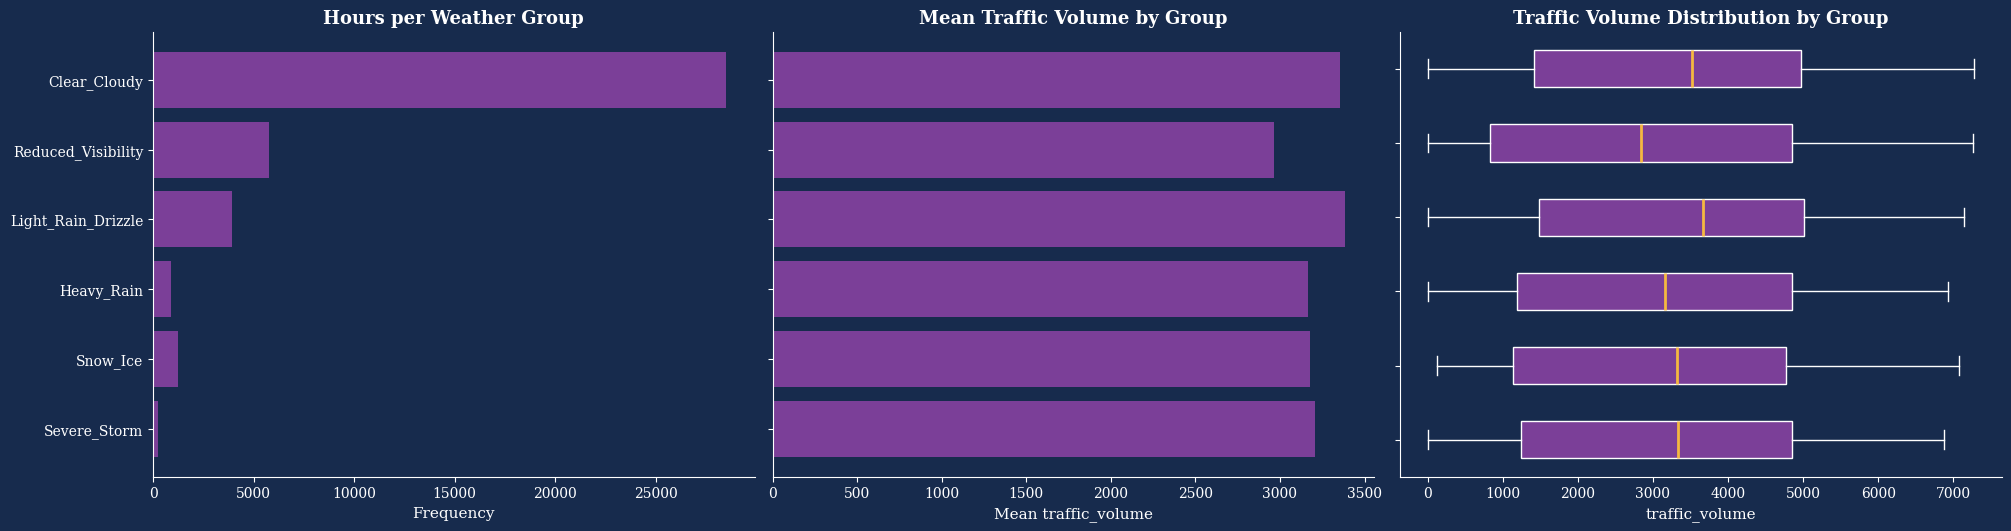

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2), facecolor=THEME_BG, constrained_layout=True)

counts = df.weather_group.value_counts().reindex(order)
axes[0].barh(counts.index[::-1], counts.values[::-1], color=THEME_PURPLE)
style_axes(axes[0], 'Hours per Weather Group', 'Frequency')

means = df.groupby('weather_group', observed=True)[TARGET].mean().reindex(order)
axes[1].barh(means.index[::-1], means.values[::-1], color=THEME_PURPLE)
style_axes(axes[1], 'Mean Traffic Volume by Group', 'Mean traffic_volume')
axes[1].set_yticklabels([])

data_box = [df.loc[df.weather_group == g, TARGET].values for g in order]
bp = axes[2].boxplot(data_box, vert=False, patch_artist=True,
                     medianprops=dict(color=THEME_ACCENT, lw=2), whiskerprops=dict(color='white'),
                     capprops=dict(color='white'), flierprops=dict(markerfacecolor='white', markersize=2, alpha=0.4, markeredgecolor='none'))
for patch in bp['boxes']:
    patch.set_facecolor(THEME_PURPLE)
    patch.set_edgecolor('white')
axes[2].invert_yaxis()
style_axes(axes[2], 'Traffic Volume Distribution by Group', 'traffic_volume')
axes[2].set_yticklabels([])
plt.show()

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;"><b>Caution when reading this chart:</b> the raw group means mix in the time-of-day effect (fog and mist are frequent at night and early morning, when traffic is low). Whether the groups carry information <b>beyond</b> the calendar features is exactly what the models in 6.4 test.</p></div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">6.4 — Models With and Without the Weather Groups</h3></div>

In [77]:
WEATHER_NUM = ['temp_c', 'rain_1h', 'snow_1h', 'clouds_all', 'is_freezing', 'is_raining',
               'is_snowing', 'precipitation_flag', 'rain_1h_log1p', 'snow_1h_log1p']
assert all(c in NUM_COLS for c in WEATHER_NUM)

res_w_a = run_model('W-A  numeric weather only (baseline)', df, NUM_COLS, CAT_COLS,
                    note='no weather labels')
res_w_b = run_model('W-B  numeric weather + weather groups', df, NUM_COLS, CAT_COLS + ['weather_group'],
                    note='adds one-hot weather_group (reference: Clear_Cloudy)')
res_w_c = run_model('W-C  no weather at all', df, [c for c in NUM_COLS if c not in WEATHER_NUM], CAT_COLS,
                    note='drops every weather input')
metrics_table([res_w_a, res_w_b, res_w_c])

,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
W-A numeric weather only (baseline),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
W-B numeric weather + weather groups,30,32460,0.858,0.857,0.857,749.893,743.962,558.665
W-C no weather at all,15,32460,0.857,0.856,0.856,751.981,746.932,560.443


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">6.4.1 — Cost of Removing the Groups</h4></div>

In [78]:
def nested_f_test(small, big):
    # Partial F-test on the training data: do the extra columns of `big` explain a significant extra part of the variance?
    n = small['n_train']
    rss = lambda r: float((r['resid_fit'] ** 2).sum())
    k1, k2 = small['n_features'], big['n_features']
    F = ((rss(small) - rss(big)) / (k2 - k1)) / (rss(big) / (n - k2 - 1))
    return F, stats.f.sf(F, k2 - k1, n - k2 - 1), k2 - k1


delta = pd.DataFrame({
    'W-A (without groups)': pd.Series(res_w_a['test']),
    'W-B (with groups)': pd.Series(res_w_b['test']),
})
delta['change (B - A)'] = delta['W-B (with groups)'] - delta['W-A (without groups)']
delta['relative change %'] = 100 * delta['change (B - A)'] / delta['W-A (without groups)']
print('TEST-set effect of adding the weather groups')
display(delta.round(4))

F, pval, extra = nested_f_test(res_w_a, res_w_b)
print(f'\nPartial F-test on the training data: {extra} extra columns, F = {F:.2f}, p-value = {pval:.3g}')
print('(autocorrelated residuals make this p-value optimistic: use it as a rough guide, the test-set change above is the honest number)')

TEST-set effect of adding the weather groups


,W-A (without groups),W-B (with groups),change (B - A),relative change %
R2,0.8570,0.8574,0.0003,0.0407
Adj_R2,0.8566,0.8569,0.0003,0.0305
MAE,559.2483,558.6647,-0.5836,-0.1044
RMSE,744.8724,743.9624,-0.9099,-0.1222



Partial F-test on the training data: 5 extra columns, F = 1.22, p-value = 0.296
(autocorrelated residuals make this p-value optimistic: use it as a rough guide, the test-set change above is the honest number)


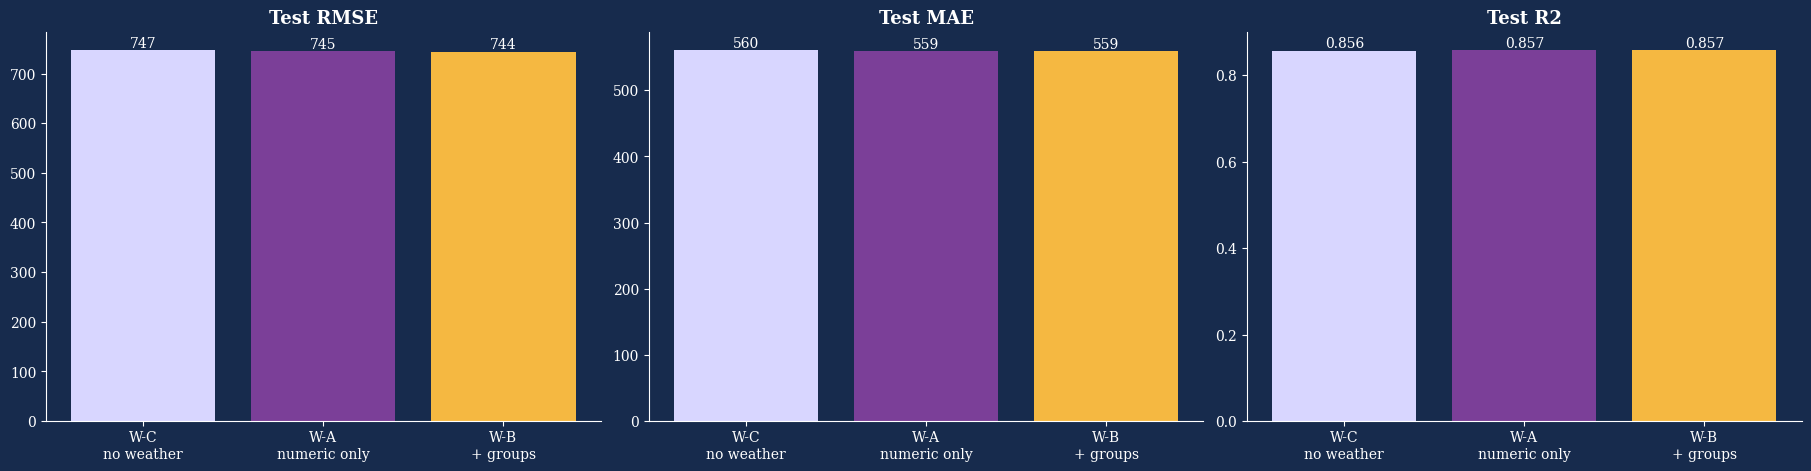

In [79]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), facecolor=THEME_BG, constrained_layout=True)
names = ['W-C\nno weather', 'W-A\nnumeric only', 'W-B\n+ groups']
rs = [res_w_c, res_w_a, res_w_b]
for ax, key, title in zip(axes, ['RMSE', 'MAE', 'R2'], ['Test RMSE', 'Test MAE', 'Test R2']):
    vals = [r['test'][key] for r in rs]
    ax.bar(names, vals, color=[THEME_LAVENDER, THEME_PURPLE, THEME_ACCENT])
    for i, v in enumerate(vals):
        ax.text(i, v, f'{v:,.3f}' if key == 'R2' else f'{v:,.0f}', ha='center', va='bottom', color='white', fontfamily='serif', fontsize=10)
    style_axes(ax, title)
plt.show()

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">6.4.2 — Effect Size of Each Group (Coefficients With Standard Errors)</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">One-hot columns are <b>not</b> standardized, so each coefficient reads directly as <b>vehicles per hour compared with Clear_Cloudy</b>, holding all other inputs fixed. Bars are &plusmn;1.96 standard errors; because consecutive hours are correlated these intervals are too narrow, so only trust clear separations from zero.</p></div>

,coef,se,t
Heavy_Rain,-21.09,32.31,-0.65
Light_Rain_Drizzle,4.15,16.76,0.25
Reduced_Visibility,-26.50,13.28,-2.00
Severe_Storm,-8.39,59.29,-0.14
Snow_Ice,24.57,26.96,0.91


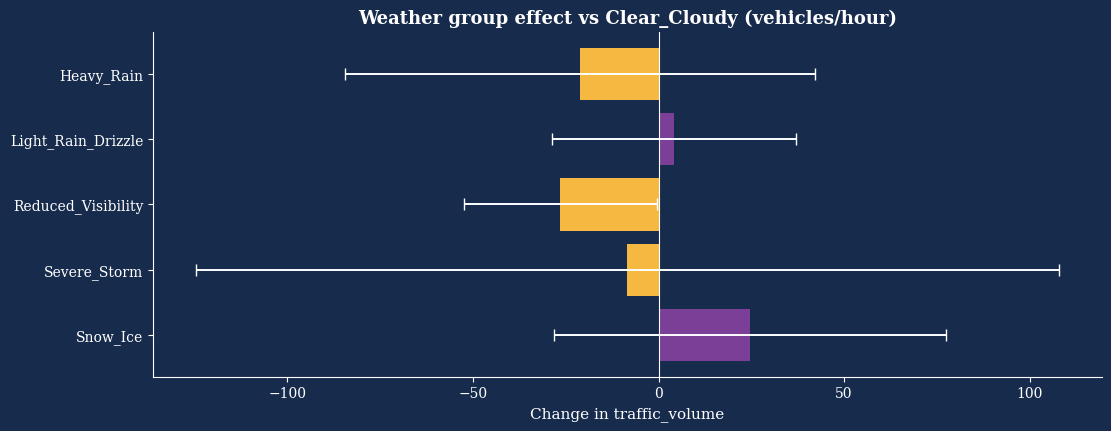

In [80]:
def coef_table(res):
    X = res['X_tr']
    A = np.column_stack([np.ones(len(X)), X.values])
    lr = res['pipe'].named_steps['lr']
    b = np.r_[lr.intercept_, lr.coef_]
    e = res['resid_fit'].values
    sigma2 = (e ** 2).sum() / (len(A) - A.shape[1])
    se = np.sqrt(np.diag(sigma2 * np.linalg.inv(A.T @ A)))
    return pd.DataFrame({'coef': b, 'se': se, 't': b / se}, index=['intercept'] + list(X.columns))


ct = coef_table(res_w_b)
grp = ct[ct.index.str.startswith('weather_group_')].copy()
grp.index = grp.index.str.replace('weather_group_', '', regex=False)
display(grp.round(2))

fig, ax = plt.subplots(figsize=(11, 4.2), facecolor=THEME_BG, constrained_layout=True)
ypos = np.arange(len(grp))
ax.barh(ypos, grp.coef, xerr=1.96 * grp.se, color=[THEME_PURPLE if v >= 0 else THEME_ACCENT for v in grp.coef],
        error_kw=dict(ecolor='white', lw=1.4, capsize=4))
ax.set_yticks(ypos)
ax.set_yticklabels(grp.index)
ax.axvline(0, color='white', lw=0.8)
ax.invert_yaxis()
style_axes(ax, 'Weather group effect vs Clear_Cloudy (vehicles/hour)', 'Change in traffic_volume')
plt.show()

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">6.4.3 — Where Do the Groups Help? (Test Residuals by Group)</h4></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;">If a group is systematically mis-predicted by W-A, its mean residual (<b>bias</b>) is far from zero; W-B should pull it back towards zero. Groups with few test hours give noisy numbers: read the <i>hours</i> column.</p></div>

,hours (test),W-A bias,W-A RMSE,W-B bias,W-B RMSE
weather_group,,,,,
Clear_Cloudy,5392,48.5,714.7,46.7,714.6
Reduced_Visibility,1386,-114.5,885.2,-91.6,882.0
Light_Rain_Drizzle,745,-3.8,707.3,-11.2,707.2
Heavy_Rain,162,90.4,665.7,104.3,665.9
Snow_Ice,354,149.9,696.6,122.9,691.1
Severe_Storm,76,-1.4,780.8,4.3,780.9


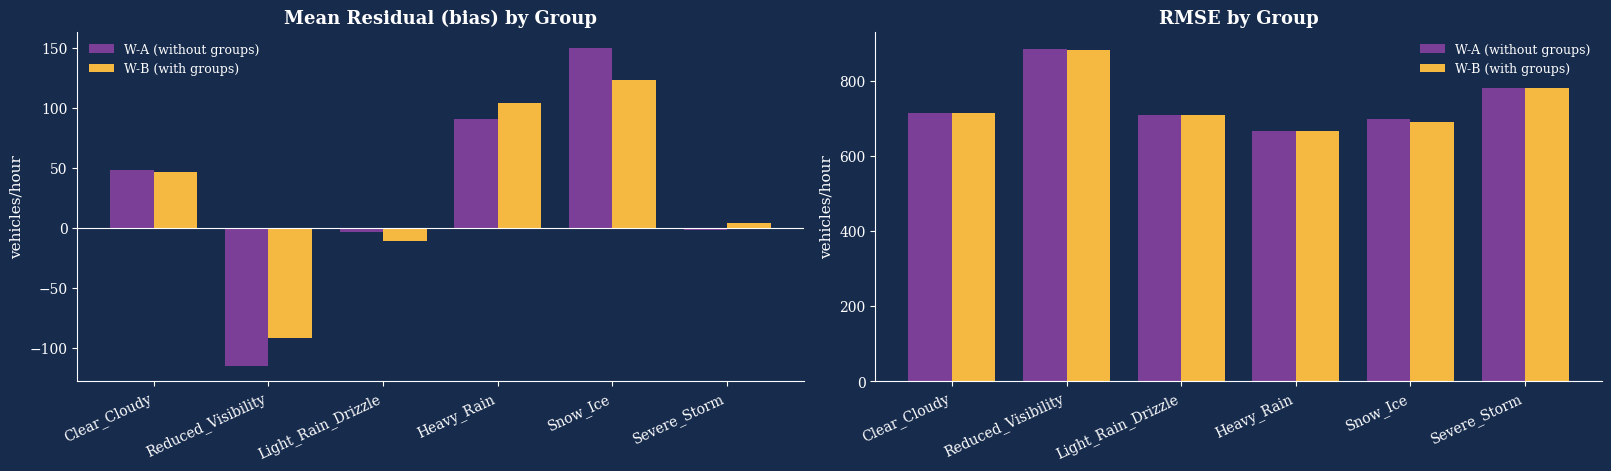

In [81]:
te_group = df['weather_group'].iloc[split_idx:]
rows = {}
for tag, r in [('W-A', res_w_a), ('W-B', res_w_b)]:
    resid = r['y_te'] - r['yhat_te']
    g = resid.groupby(te_group, observed=True)
    rows[tag + ' bias'] = g.mean()
    rows[tag + ' RMSE'] = g.apply(lambda s: float(np.sqrt((s ** 2).mean())))
by_group = pd.DataFrame(rows).reindex(order)
by_group.insert(0, 'hours (test)', te_group.value_counts().reindex(order).fillna(0).astype(int))
display(by_group.round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), facecolor=THEME_BG, constrained_layout=True)
x = np.arange(len(order)); w = 0.38
for ax, suffix, title in zip(axes, ['bias', 'RMSE'], ['Mean Residual (bias) by Group', 'RMSE by Group']):
    ax.bar(x - w / 2, by_group['W-A ' + suffix], w, color=THEME_PURPLE, label='W-A (without groups)')
    ax.bar(x + w / 2, by_group['W-B ' + suffix], w, color=THEME_ACCENT, label='W-B (with groups)')
    ax.set_xticks(x)
    ax.set_xticklabels(order, rotation=25, ha='right')
    if suffix == 'bias':
        ax.axhline(0, color='white', lw=0.8)
    style_axes(ax, title, None, 'vehicles/hour')
    style_legend(ax)
plt.show()

<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;"><h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">6.4.4 — Optional: Compare the Two Hourly-Label Rules</h4></div>

In [82]:
alt_series = group_worst if WEATHER_AGG == 'mode' else group_mode
alt_name = 'worst' if WEATHER_AGG == 'mode' else 'mode'
df_alt = df.copy()
df_alt['weather_group'] = pd.Categorical(alt_series.reindex(df_alt.index), categories=order)
res_w_b_alt = run_model(f'W-B  groups via "{alt_name}" rule', df_alt, NUM_COLS, CAT_COLS + ['weather_group'])
metrics_table([res_w_a, res_w_b, res_w_b_alt])

,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
W-A numeric weather only (baseline),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
W-B numeric weather + weather groups,30,32460,0.858,0.857,0.857,749.893,743.962,558.665
"W-B groups via ""worst"" rule",30,32460,0.858,0.858,0.858,749.314,741.678,557.648


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">6.5 — Overall Comparison</h3></div>

In [83]:
metrics_table(list(RESULTS.values()))

,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
model,,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
V1 Cyclical encoding only,22,32460,0.840,0.838,0.838,794.848,792.542,605.463
V2 Log-transformed target,25,32460,0.631,0.620,0.619,1207.313,1213.726,832.054
V3 Train without low-volume hours,25,32414,0.860,0.857,0.857,743.740,744.576,558.860
V4 Hour harmonics x weekend,31,32460,0.907,0.906,0.906,607.562,603.882,425.975
W-A numeric weather only (baseline),25,32460,0.858,0.857,0.857,749.963,744.872,559.248
W-B numeric weather + weather groups,30,32460,0.858,0.857,0.857,749.893,743.962,558.665
W-C no weather at all,15,32460,0.857,0.856,0.856,751.981,746.932,560.443
"W-B groups via ""worst"" rule",30,32460,0.858,0.858,0.858,749.314,741.678,557.648


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;"><p style="margin:0 0 8px 0;"><b>How to read the result:</b></p><ul style="margin:4px 0 8px 22px; padding:0;"><li style="margin-bottom:4px;">If W-B&rsquo;s <b>test RMSE / R&sup2;</b> is practically the same as W-A&rsquo;s, the weather groups add little beyond the numeric weather and the calendar features, which supports the team decision to leave the labels out.</li><li style="margin-bottom:4px;">If W-B is clearly better, and the gain is concentrated in groups such as Reduced_Visibility or Severe_Storm (6.4.3), the labels carry information the numbers (<code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">rain_1h</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">snow_1h</code>, <code style="background:#dfe6f0; color:#1e3a5f; padding:1px 6px; border-radius:4px; font-size:0.92em;">clouds_all</code>) do not, and the decision deserves a second look.</li><li style="margin-bottom:4px;">W-C shows how much weather matters in total. If W-C is close to W-A, weather is a minor driver of hourly traffic compared with hour and weekday, and no weather encoding will change the picture much.</li><li style="margin-bottom:4px;">A linear model cannot express weather <i>x</i> rush-hour interactions (fog matters more at 7&nbsp;am than at 3&nbsp;am). A small gain here does not rule out a larger one for a tree-based model.</li></ul></div>

<a id="7"></a>
<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;">
  <h2 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">
    Random Forest — Model Implementation and Analysis
  </h2>
</div>


<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
  <p style="margin:0 0 8px 0;"><b>Random Forest</b> builds many decision trees and averages their predictions. Each tree sees a different sample of the training data and considers a subset of features at each split. This helps capture non-linear patterns while reducing reliance on a single tree.</p>
  <p style="margin:0;">The models below use the same chronological train/test split and the same 23 features as the linear models. QA columns are excluded.</p>
</div>


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;">
  <h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">7.1 — Random Forest Pipeline and Baseline</h4>
</div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
  <p style="margin:0;">Numeric inputs pass through unchanged because tree models do not need feature scaling. <code>season</code> is one-hot encoded. The preprocessing pipeline is fitted on training data only.</p>
</div>


In [84]:


RF_FEATURES = FEATURES.copy()


def make_rf_pipeline(params):
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", "passthrough", NUM_COLS),
            (
                "cat",
                OneHotEncoder(
                    drop="first",
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
                CAT_COLS,
            ),
        ],
        verbose_feature_names_out=False,
    )

    model = RandomForestRegressor(
        **params,
        random_state=42,
        n_jobs=-1,
    )

    return Pipeline([
        ("prep", preprocessor),
        ("rf", model),
    ])


def rf_score(y, yhat):
    return {
        "R2": r2_score(y, yhat),
        "MAE": mean_absolute_error(y, yhat),
        "RMSE": float(np.sqrt(mean_squared_error(y, yhat))),
    }


def rf_comparison_table(results):
    rows = []
    for result in results:
        rows.append({
            "model": result["name"],
            "n_features": result["n_features"],
            "n_train": result["n_train"],
            "train R2": result["train"]["R2"],
            "test R2": result["test"]["R2"],
            "train RMSE": result["train"]["RMSE"],
            "test RMSE": result["test"]["RMSE"],
            "test MAE": result["test"]["MAE"],
        })
    return pd.DataFrame(rows).set_index("model").round(3)


def evaluate_rf(name, params):
    pipe = make_rf_pipeline(params)

    pipe.fit(train[RF_FEATURES], train[TARGET])

    pred_train = pipe.predict(train[RF_FEATURES])
    pred_test = pipe.predict(test[RF_FEATURES])

    n_features = len(pipe.named_steps["prep"].get_feature_names_out())

    result = {
        "name": name,
        "n_train": len(train),
        "n_features": n_features,
        "train": rf_score(train[TARGET], pred_train),
        "test": rf_score(test[TARGET], pred_test),
        "pipe": pipe,
        "idx_te": test.index,
        "y_te": test[TARGET],
        "yhat_te": pd.Series(pred_test, index=test.index),
    }

    return result


RF_BASE_PARAMS = {
    "n_estimators": 200,
    "max_depth": None,
    "min_samples_leaf": 1,
    "max_features": 1.0,
}

res_rf_base = evaluate_rf("RF  Baseline", RF_BASE_PARAMS)

print(
    "RF baseline | test R²: %.3f | RMSE: %.1f | MAE: %.1f"
    % (res_rf_base["test"]["R2"], res_rf_base["test"]["RMSE"], res_rf_base["test"]["MAE"])
)


RF baseline | test R²: 0.937 | RMSE: 494.0 | MAE: 286.6


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;">
  <h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">7.2 — Important Parameters</h4>
</div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
  <ul style="margin:4px 0 8px 22px; padding:0;">
    <li><code>n_estimators</code>: number of trees in the forest.</li>
    <li><code>max_depth</code>: maximum depth of each tree.</li>
    <li><code>min_samples_leaf</code>: minimum number of training rows in a leaf; larger values regularize the trees.</li>
    <li><code>max_features</code>: number or share of features considered at each split.</li>
  </ul>
  <p style="margin:0;">The configurations are compared with expanding-window validation on the training portion only. The test portion is reserved for the final comparison.</p>
</div>


In [85]:
RF_CONFIGS = {
    "RF-CV  Baseline": {
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 1.0,
    },
    "RF-CV  More Trees": {
        "n_estimators": 400,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 1.0,
    },
    "RF-CV  Limited Depth": {
        "n_estimators": 200,
        "max_depth": 25,
        "min_samples_leaf": 1,
        "max_features": 1.0,
    },
    "RF-CV  Larger Leaves": {
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 5,
        "max_features": 1.0,
    },
    "RF-CV  Fewer Features": {
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 0.7,
    },
}

# Half-open calendar intervals; all folds stay strictly inside the training period.
RF_CV_WINDOWS = [
    ("2015-04-01", "2015-10-01"),
    ("2015-10-01", "2016-04-01"),
    ("2016-04-01", "2016-10-01"),
    ("2016-10-01", "2017-04-01"),
    ("2017-04-01", "2017-10-27"),
]

rf_cv_rows = []

for config_name, params in RF_CONFIGS.items():
    for fold, (valid_start, valid_end) in enumerate(RF_CV_WINDOWS, start=1):
        valid_start = pd.Timestamp(valid_start)
        valid_end = pd.Timestamp(valid_end)

        fit_mask = train.index < valid_start
        valid_mask = (train.index >= valid_start) & (train.index < valid_end)
        fold_train = train.loc[fit_mask]
        fold_valid = train.loc[valid_mask]

        assert len(fold_train) > 0 and len(fold_valid) > 0, f"empty data in fold {fold}"
        assert fold_train.index.max() < fold_valid.index.min(), f"time order broken in fold {fold}"

        pipe = make_rf_pipeline(params)
        pipe.fit(fold_train[RF_FEATURES], fold_train[TARGET])

        pred_valid = pipe.predict(fold_valid[RF_FEATURES])
        n_features = len(pipe.named_steps["prep"].get_feature_names_out())
        fold_scores = rf_score(fold_valid[TARGET], pred_valid)

        rf_cv_rows.append({
            "configuration": config_name,
            "fold": fold,
            "validation_start": valid_start,
            "validation_end": valid_end,
            "train_rows": len(fold_train),
            "validation_rows": len(fold_valid),
            "R2": fold_scores["R2"],
            "MAE": fold_scores["MAE"],
            "RMSE": fold_scores["RMSE"],
        })

rf_cv_results = pd.DataFrame(rf_cv_rows)

rf_cv_summary = (
    rf_cv_results
    .groupby("configuration")
    .agg(
        mean_R2=("R2", "mean"),
        mean_MAE=("MAE", "mean"),
        mean_RMSE=("RMSE", "mean"),
        std_RMSE=("RMSE", "std"),
    )
    .sort_values("mean_RMSE")
    .round(3)
)

display(rf_cv_summary)

best_rf_config = rf_cv_summary.index[0]
best_rf_params = RF_CONFIGS[best_rf_config]

print("Selected configuration:", best_rf_config)
print("Selected parameters:", best_rf_params)
print("Validation windows:", RF_CV_WINDOWS)


,mean_R2,mean_MAE,mean_RMSE,std_RMSE
configuration,,,,
RF-CV Larger Leaves,0.935,300.286,499.895,54.700
RF-CV Fewer Features,0.931,313.033,513.928,55.927
RF-CV More Trees,0.929,318.566,522.809,59.532
RF-CV Baseline,0.929,319.167,523.717,59.289
RF-CV Limited Depth,0.929,319.346,524.111,60.659


Selected configuration: RF-CV  Larger Leaves
Selected parameters: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 1.0}
Validation windows: [('2015-04-01', '2015-10-01'), ('2015-10-01', '2016-04-01'), ('2016-04-01', '2016-10-01'), ('2016-10-01', '2017-04-01'), ('2017-04-01', '2017-10-27')]


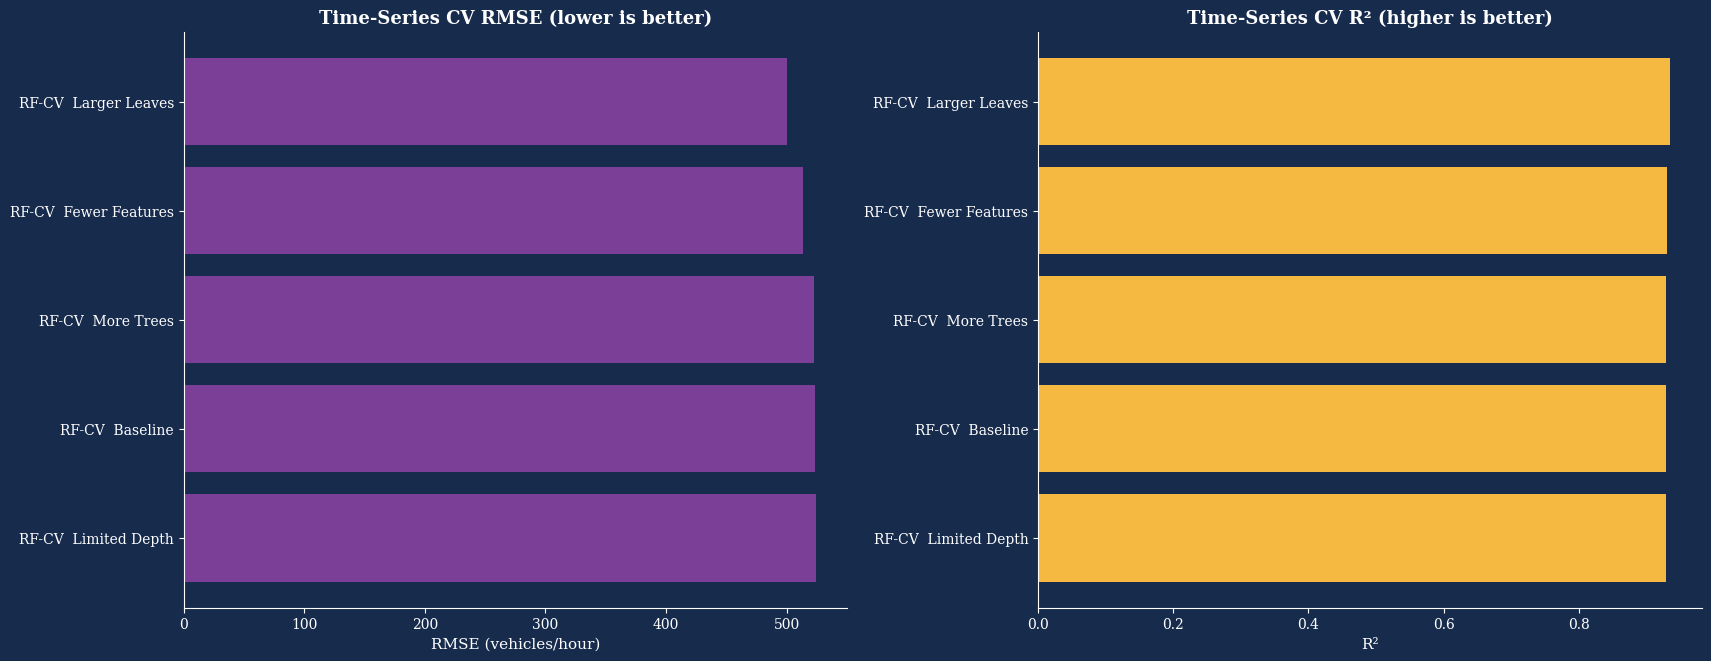

Selected configuration: RF-CV  Larger Leaves
Selected parameters: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 1.0}


In [86]:
rf_cv_plot = rf_cv_summary.sort_values("mean_RMSE", ascending=False)

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 0.7 * len(rf_cv_plot) + 3),
    facecolor=THEME_BG,
    constrained_layout=True,
)

axes[0].barh(
    rf_cv_plot.index,
    rf_cv_plot["mean_RMSE"],
    color=THEME_PURPLE,
)
style_axes(
    axes[0],
    title="Time-Series CV RMSE (lower is better)",
    xlabel="RMSE (vehicles/hour)",
)

axes[1].barh(
    rf_cv_plot.index,
    rf_cv_plot["mean_R2"],
    color=THEME_ACCENT,
)
style_axes(
    axes[1],
    title="Time-Series CV R² (higher is better)",
    xlabel="R²",
)

plt.show()

best_rf_config_name = rf_cv_summary.index[0]
best_rf_params = RF_CONFIGS[best_rf_config_name]

print("Selected configuration:", best_rf_config_name)
print("Selected parameters:", best_rf_params)

res_rf_tuned = evaluate_rf(
    "RF  Tuned",
    best_rf_params,
)


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;">
  <h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">7.3 — Comparison with the Linear Baselines</h4>
</div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
  <p style="margin:0;">The baseline and tuned Random Forest use the same chronological test period as Linear Regression A and V4. Lower test RMSE and MAE are better; higher test R² is better.</p>
</div>


In [87]:
rf_comparison = rf_comparison_table([
    res_a,
    res_v4,
    res_rf_base,
    res_rf_tuned,
])

display(rf_comparison)


,n_features,n_train,train R2,test R2,train RMSE,test RMSE,test MAE
model,,,,,,,
A Baseline (23 features),25,32460,0.858,0.857,749.963,744.872,559.248
V4 Hour harmonics x weekend,31,32460,0.907,0.906,607.562,603.882,425.975
RF Baseline,25,32460,0.993,0.937,169.070,493.966,286.556
RF Tuned,25,32460,0.969,0.942,347.563,476.296,270.062


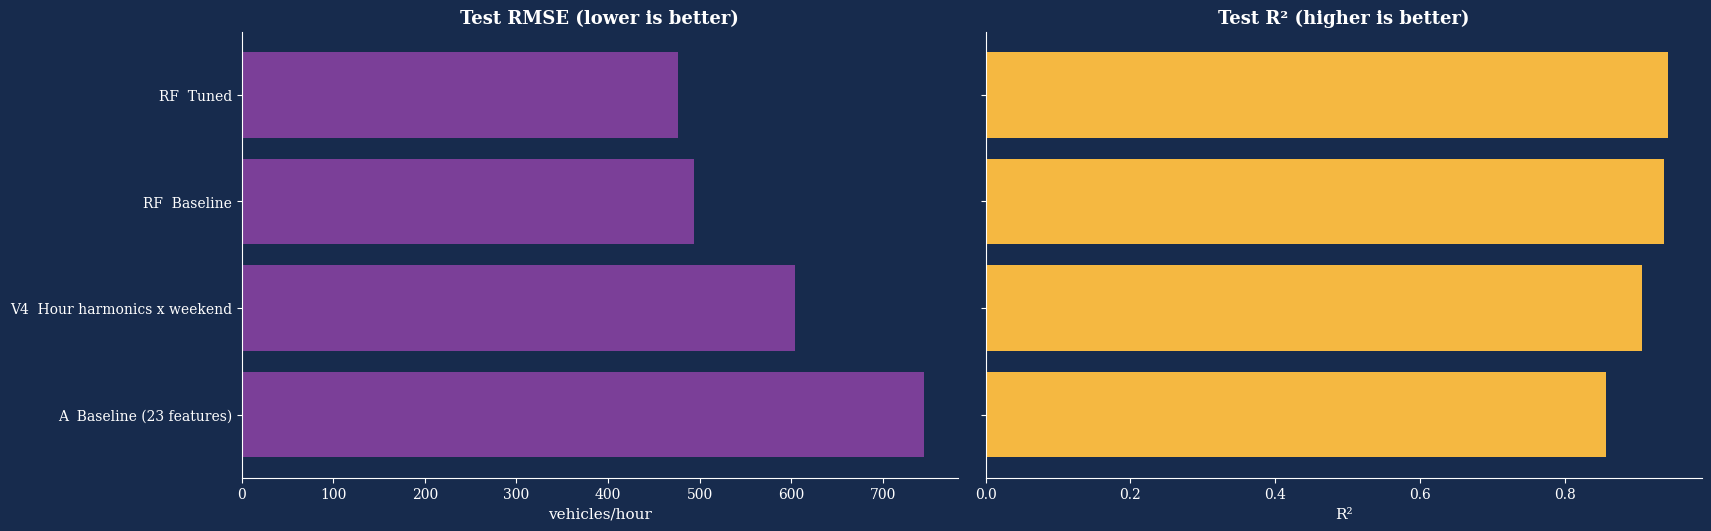

In [88]:
rf_comparison_plot = rf_comparison.sort_values(
    "test RMSE",
    ascending=False,
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 5.2),
    facecolor=THEME_BG,
    constrained_layout=True,
)

axes[0].barh(
    rf_comparison_plot.index,
    rf_comparison_plot["test RMSE"],
    color=THEME_PURPLE,
)
style_axes(
    axes[0],
    title="Test RMSE (lower is better)",
    xlabel="vehicles/hour",
)

axes[1].barh(
    rf_comparison_plot.index,
    rf_comparison_plot["test R2"],
    color=THEME_ACCENT,
)
style_axes(
    axes[1],
    title="Test R² (higher is better)",
    xlabel="R²",
)
axes[1].set_yticklabels([])

plt.show()


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;">
  <h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">7.4 — Feature Importance</h4>
</div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
  <p style="margin:0;">Permutation importance measures how much the test RMSE worsens when one input column is shuffled. Related calendar and precipitation columns overlap, so their individual scores can be misleading. The grouped analysis shuffles each feature family together while preserving relationships within that family. Importance measures predictive reliance, not causation.</p>
</div>


In [89]:
rf_importance_result = permutation_importance(
    res_rf_tuned["pipe"],
    test[RF_FEATURES],
    test[TARGET],
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

rf_importance = (
    pd.DataFrame({
        "feature": RF_FEATURES,
        "importance_mean": rf_importance_result.importances_mean,
        "importance_std": rf_importance_result.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

display(rf_importance.head(15).round(3))


,feature,importance_mean,importance_std
0,hour_cos,1513.810,10.309
1,hour,506.806,5.384
2,hour_sin,212.592,5.348
3,is_rush_hour,157.176,2.637
4,day_of_week,117.547,3.087
5,dow_sin,114.473,2.995
6,is_weekend,97.214,2.638
7,dow_cos,34.020,1.320
8,temp_c,29.195,3.159
9,month_cos,6.915,0.882


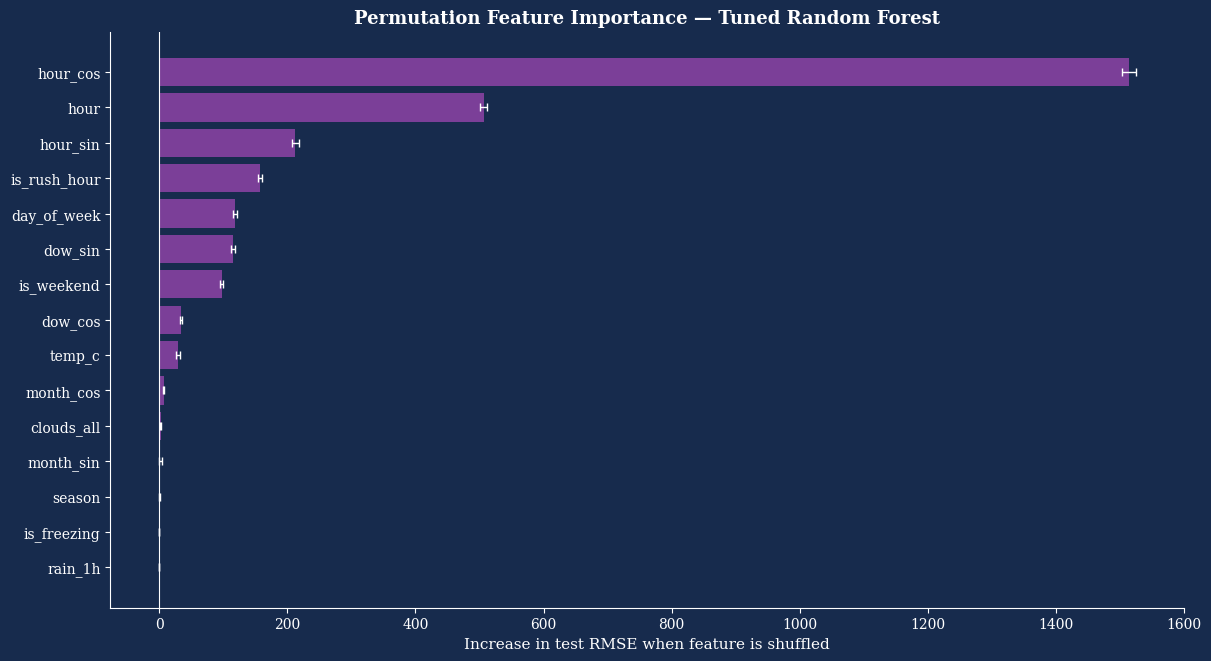

In [90]:
rf_importance_plot = (
    rf_importance
    .head(15)
    .sort_values("importance_mean")
)

fig, ax = plt.subplots(
    figsize=(12, 6.5),
    facecolor=THEME_BG,
    constrained_layout=True,
)

ax.barh(
    rf_importance_plot["feature"],
    rf_importance_plot["importance_mean"],
    xerr=rf_importance_plot["importance_std"],
    color=THEME_PURPLE,
    error_kw=dict(ecolor="white", capsize=3, lw=1),
)

ax.axvline(0, color="white", lw=0.8)
style_axes(
    ax,
    title="Permutation Feature Importance — Tuned Random Forest",
    xlabel="Increase in test RMSE when feature is shuffled",
)

plt.show()


,feature_group,features,importance_mean,importance_std
0,Hour and commute,"hour, hour_sin, hour_cos, is_rush_hour",2165.29,6.85
1,Weekday and weekend,"day_of_week, dow_sin, dow_cos, is_weekend",637.38,10.69
2,Temperature and freezing,"temp_c, is_freezing",30.62,3.57
3,Month and season,"month, month_sin, month_cos, season",26.28,3.11
4,Cloud cover,clouds_all,2.52,1.08
5,Precipitation,"rain_1h, snow_1h, is_raining, is_snowing, prec...",0.45,0.30
6,Long-term year,year,-0.00,0.00


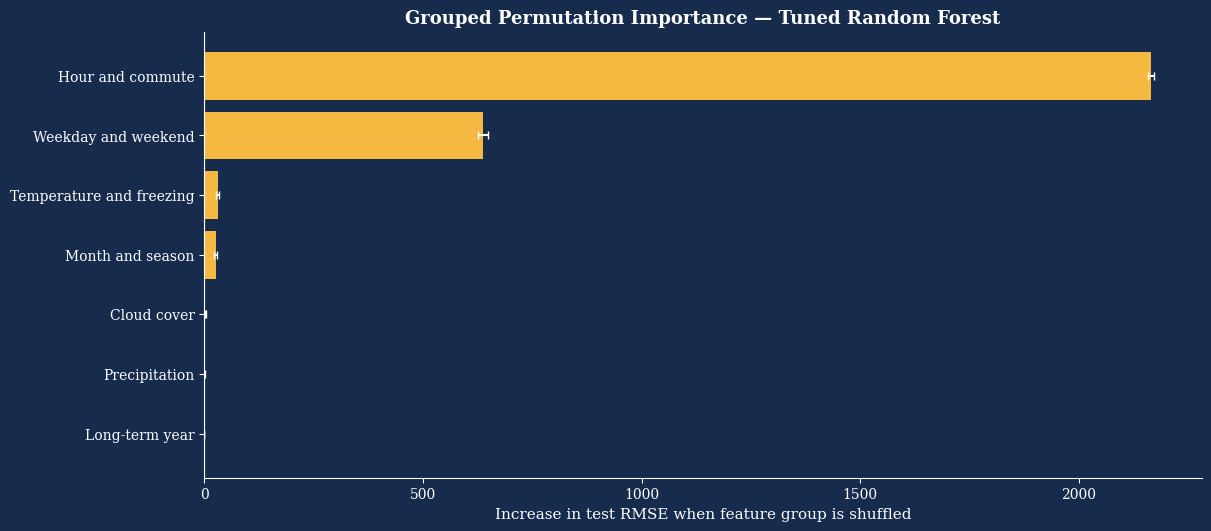

In [91]:
RF_FEATURE_GROUPS = {
    "Hour and commute": ["hour", "hour_sin", "hour_cos", "is_rush_hour"],
    "Weekday and weekend": ["day_of_week", "dow_sin", "dow_cos", "is_weekend"],
    "Month and season": ["month", "month_sin", "month_cos", "season"],
    "Long-term year": ["year"],
    "Temperature and freezing": ["temp_c", "is_freezing"],
    "Precipitation": [
        "rain_1h", "snow_1h", "is_raining", "is_snowing",
        "precipitation_flag", "rain_1h_log1p", "snow_1h_log1p",
    ],
    "Cloud cover": ["clouds_all"],
}

_grouped_columns = [column for columns in RF_FEATURE_GROUPS.values() for column in columns]
assert len(_grouped_columns) == len(set(_grouped_columns)), "a feature appears in more than one group"
assert set(_grouped_columns) == set(RF_FEATURES), "feature groups must cover every RF input exactly once"


def grouped_permutation_importance(model, X, y, feature_groups, n_repeats=10, random_state=42):
    rng = np.random.default_rng(random_state)
    baseline_rmse = np.sqrt(mean_squared_error(y, model.predict(X)))
    rows = []

    for group_name, requested_columns in feature_groups.items():
        columns = [c for c in requested_columns if c in X.columns]
        score_deltas = []

        for _ in range(n_repeats):
            row_order = rng.permutation(len(X))
            X_permuted = X.copy()
            for column in columns:
                X_permuted[column] = X.iloc[row_order][column].to_numpy()

            permuted_rmse = np.sqrt(mean_squared_error(y, model.predict(X_permuted)))
            score_deltas.append(permuted_rmse - baseline_rmse)

        rows.append({
            "feature_group": group_name,
            "features": ", ".join(columns),
            "importance_mean": np.mean(score_deltas),
            "importance_std": np.std(score_deltas, ddof=1),
        })

    return (
        pd.DataFrame(rows)
        .sort_values("importance_mean", ascending=False)
        .reset_index(drop=True)
    )


rf_group_importance = grouped_permutation_importance(
    res_rf_tuned["pipe"],
    test[RF_FEATURES],
    test[TARGET],
    RF_FEATURE_GROUPS,
    n_repeats=10,
    random_state=42,
)

display(rf_group_importance.round(2))

rf_group_plot = rf_group_importance.sort_values("importance_mean")
fig, ax = plt.subplots(figsize=(12, 5.2), facecolor=THEME_BG, constrained_layout=True)
ax.barh(
    rf_group_plot["feature_group"],
    rf_group_plot["importance_mean"],
    xerr=rf_group_plot["importance_std"],
    color=THEME_ACCENT,
    error_kw={"ecolor": "white", "capsize": 3},
)
ax.axvline(0, color="white", lw=0.8)
style_axes(
    ax,
    title="Grouped Permutation Importance — Tuned Random Forest",
    xlabel="Increase in test RMSE when feature group is shuffled",
)
plt.show()


<div style="border-left:5px solid #4B3F8F; background:#eef2f7; padding:8px 14px; border-radius:6px; margin:20px 0 8px 0; direction:ltr; text-align:left;">
  <h4 style="margin:0; color:#1e3a5f; font-family:'Georgia', 'Times New Roman', serif;">7.5 — Performance Analysis</h4>
</div>
<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
  <p style="margin:0;">The existing six-panel diagnostics are reused for the tuned Random Forest. Additional summaries show whether prediction errors change by hour, weekday/weekend, or season.</p>
</div>


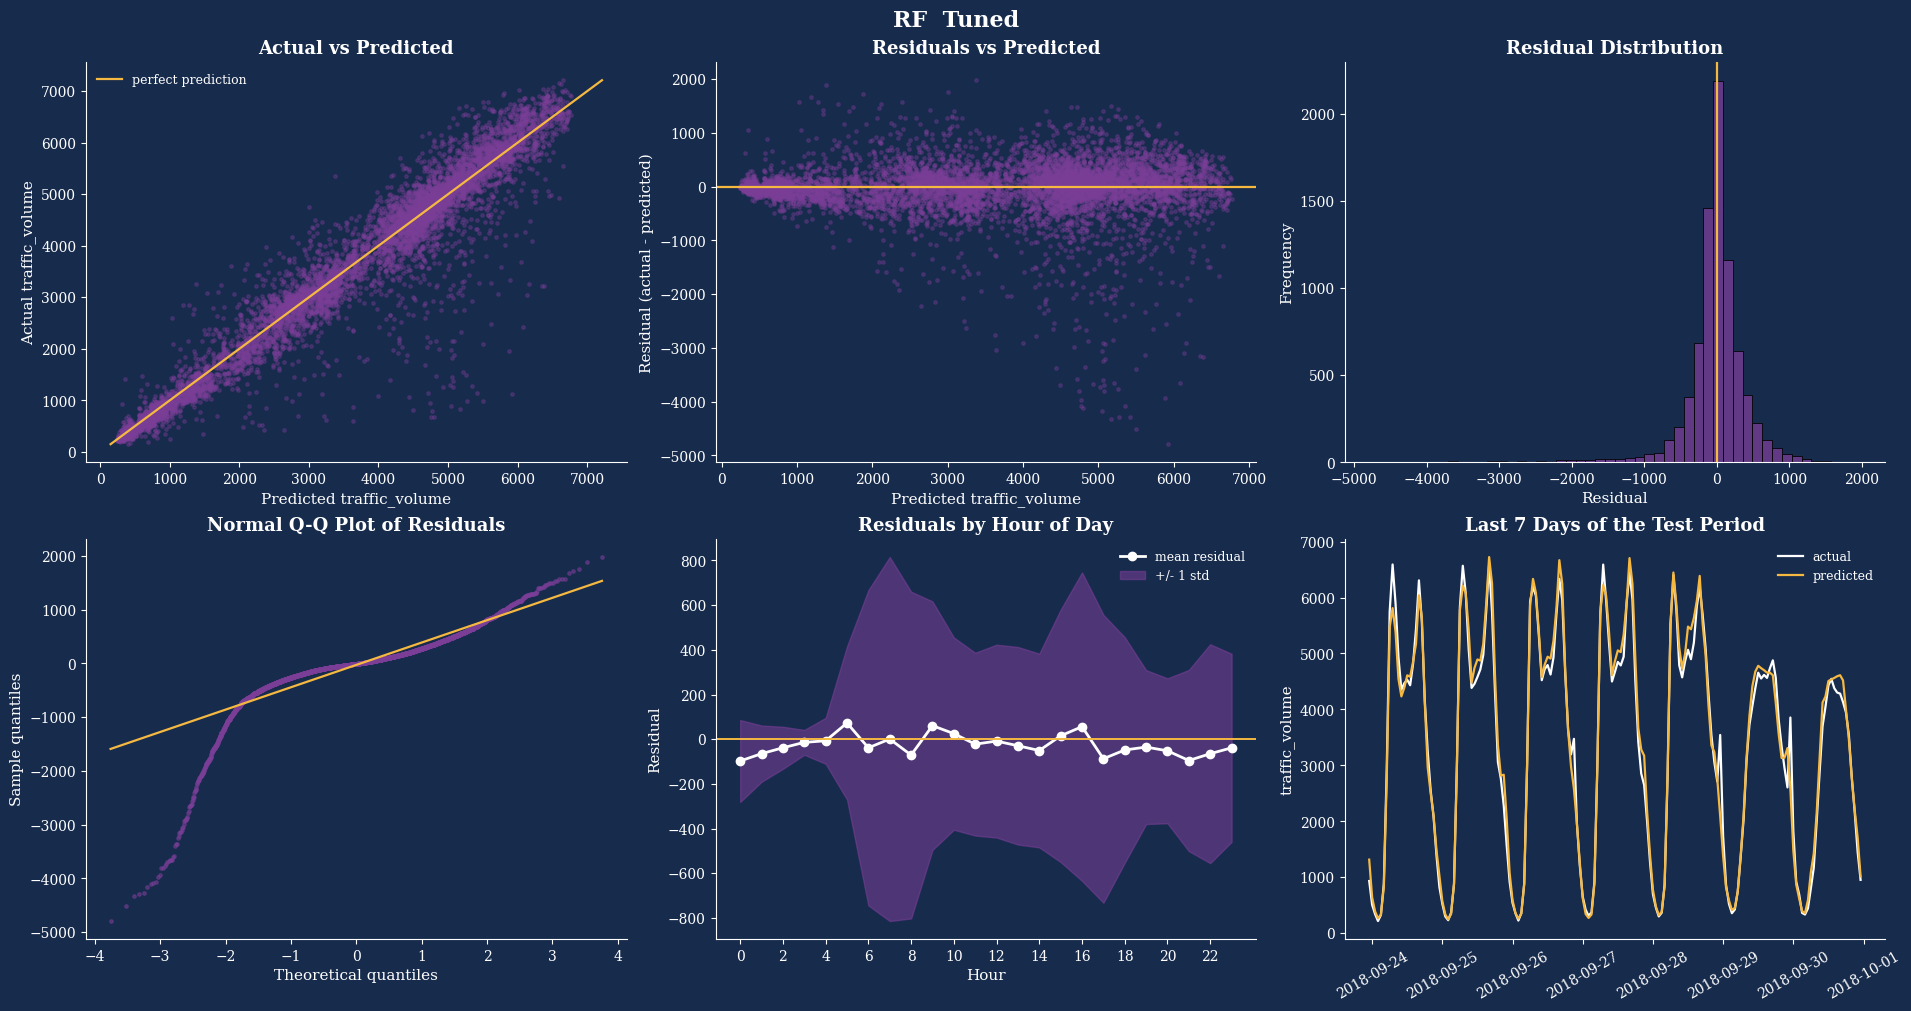

hours    MAE   RMSE  bias
group      value                            
is_weekend 0        5775  263.4  485.2 -16.9
           1        2340  286.5  453.6 -50.1
season     Fall     1562  287.4  502.6  14.9
           Spring   2196  264.4  486.5 -71.0
           Summer   2203  202.9  352.7 -20.0
           Winter   2154  332.0  550.4 -17.7

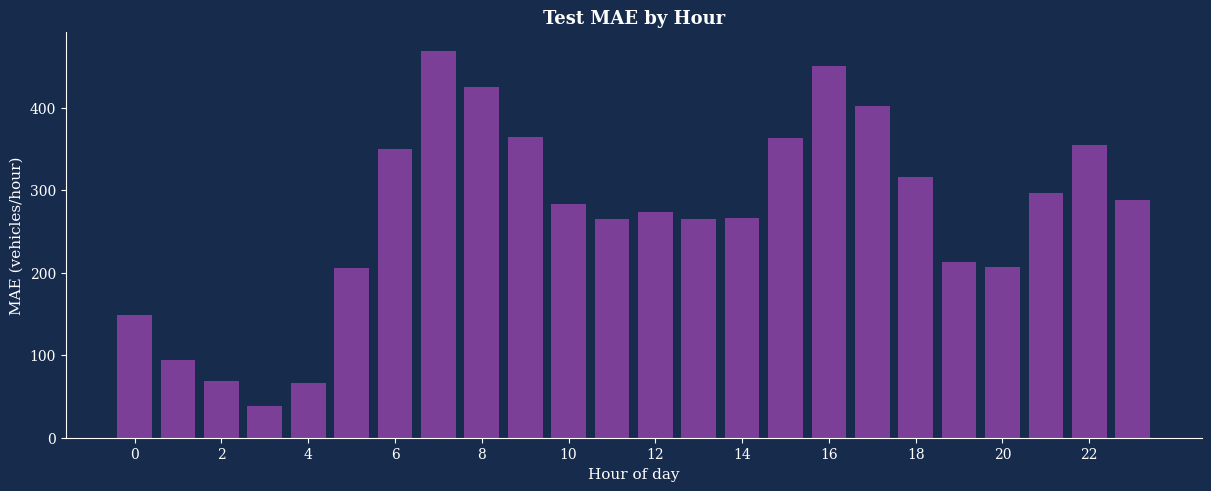

In [92]:
diagnostics(res_rf_tuned)

rf_test_analysis = test.copy()
rf_test_analysis["prediction"] = res_rf_tuned["yhat_te"]
rf_test_analysis["residual"] = (
    rf_test_analysis[TARGET] - rf_test_analysis["prediction"]
)
rf_test_analysis["abs_error"] = rf_test_analysis["residual"].abs()

rf_segment_rows = []

for column in ["is_weekend", "season"]:
    for group_name, group in rf_test_analysis.groupby(column, observed=True):
        rf_segment_rows.append({
            "group": column,
            "value": str(group_name),
            "hours": len(group),
            "MAE": group["abs_error"].mean(),
            "RMSE": np.sqrt((group["residual"] ** 2).mean()),
            "bias": group["residual"].mean(),
        })

rf_segment_metrics = (
    pd.DataFrame(rf_segment_rows)
    .set_index(["group", "value"])
    .round(1)
)

display(rf_segment_metrics)

rf_hour_metrics = (
    rf_test_analysis
    .groupby("hour")
    .agg(
        MAE=("abs_error", "mean"),
        hours=(TARGET, "size"),
    )
)

fig, ax = plt.subplots(figsize=(12, 4.8), facecolor=THEME_BG, constrained_layout=True)
ax.bar(
    rf_hour_metrics.index,
    rf_hour_metrics["MAE"],
    color=THEME_PURPLE,
)
ax.set_xticks(range(0, 24, 2))
style_axes(
    ax,
    title="Test MAE by Hour",
    xlabel="Hour of day",
    ylabel="MAE (vehicles/hour)",
)
plt.show()


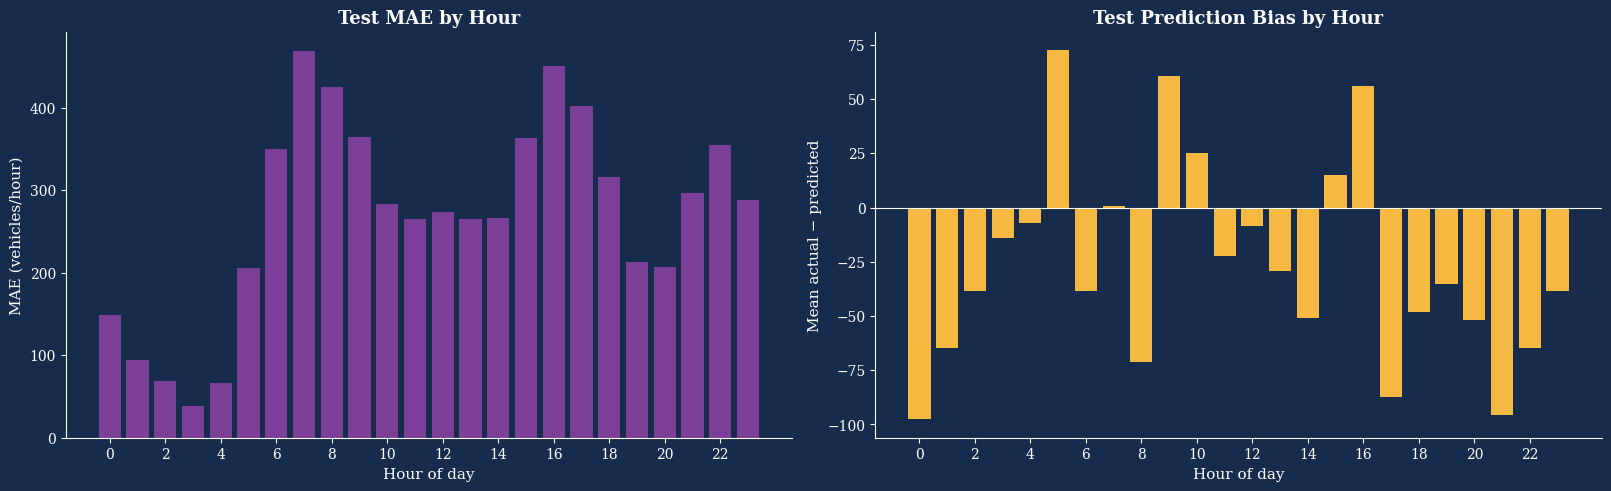

In [93]:
rf_hour_metrics = (
    rf_test_analysis
    .groupby("hour")
    .agg(
        MAE=("abs_error", "mean"),
        bias=("residual", "mean"),
        hours=(TARGET, "size"),
    )
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 4.8),
    facecolor=THEME_BG,
    constrained_layout=True,
)

axes[0].bar(
    rf_hour_metrics.index,
    rf_hour_metrics["MAE"],
    color=THEME_PURPLE,
)
axes[0].set_xticks(range(0, 24, 2))
style_axes(
    axes[0],
    title="Test MAE by Hour",
    xlabel="Hour of day",
    ylabel="MAE (vehicles/hour)",
)

axes[1].bar(
    rf_hour_metrics.index,
    rf_hour_metrics["bias"],
    color=THEME_ACCENT,
)
axes[1].axhline(0, color="white", lw=0.8)
axes[1].set_xticks(range(0, 24, 2))
style_axes(
    axes[1],
    title="Test Prediction Bias by Hour",
    xlabel="Hour of day",
    ylabel="Mean actual − predicted",
)

plt.show()



<a id="8"></a>
<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif;"><h2 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">XGBoost & LightGBM</h2></div>



<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">8.1 — Boosting Approach and Modeling Setup</h3></div>



<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
<p style="margin:0 0 8px 0;"><b>Objective:</b> implement XGBoost and LightGBM regression models for traffic volume prediction and compare their initial results with the existing Random Forest model.</p>
<p style="margin:0 0 8px 0;"><b>Modeling setup:</b> both models will use the existing training and testing sets and the same 23 selected input features to ensure a consistent comparison.</p>
<p style="margin:0;"><b>Scope:</b> this section focuses on model implementation and baseline comparison. Extensive hyperparameter tuning, detailed model evaluation, and final model selection are reserved for the next project stage.</p>
</div>


In [94]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", "passthrough", NUM_COLS),
            (
                "cat",
                OneHotEncoder(
                    drop="first",
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
                CAT_COLS,
            ),
        ],
        verbose_feature_names_out=False,
    )

def make_pipeline(model):
    return Pipeline([
        ("prep", make_preprocessor()),
        ("model", model),
    ])

def score_model(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
    }

def evaluate_model(name, pipeline, features=FEATURES):
    X_train = train[features]
    y_train = train[TARGET]
    X_test = test[features]
    y_test = test[TARGET]

    pipeline.fit(X_train, y_train)

    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)

    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    n_test = len(y_test)
    n_features = len(
        pipeline.named_steps["prep"].get_feature_names_out()
    )

    test_adj_r2 = (
        1 - (1 - test_r2) * (n_test - 1)
        / (n_test - n_features - 1)
    )

    result = {
        "n_features": n_features,
        "n_train": len(y_train),
        "train R2": train_r2,
        "test R2": test_r2,
        "test adj R2": test_adj_r2,
        "train RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "test MAE": mean_absolute_error(y_test, test_pred),
    }

    RESULTS[name] = result

    print(f"\n{name}")
    display(pd.DataFrame([result], index=[name]).round(4))

    return {
        "name": name,
        "model": pipeline,
        "predictions": test_pred,
        **result,
    }



<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">8.2 — XGBoost Regressor</h3></div>



<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
<p style="margin:0;"><b>XGBoost:</b> an optimized gradient boosting algorithm that builds decision trees sequentially, with each stage improving the model by learning from previous errors. A baseline regressor will be trained before any extensive hyperparameter search.</p>
</div>


In [95]:


XGB_BASELINE_PARAMS = {
    "n_estimators": 300,
    "learning_rate": 0.1,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 42,
    "n_jobs": -1,
    "objective": "reg:squarederror",
}

xgb_model = XGBRegressor(**XGB_BASELINE_PARAMS)

xgb_pipeline = make_pipeline(xgb_model)

xgb_baseline = evaluate_model(
    name="XGBoost Baseline",
    pipeline=xgb_pipeline,
)



XGBoost Baseline


,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
XGBoost Baseline,25,32460,0.9723,0.9424,0.9422,330.7683,472.9538,274.9471


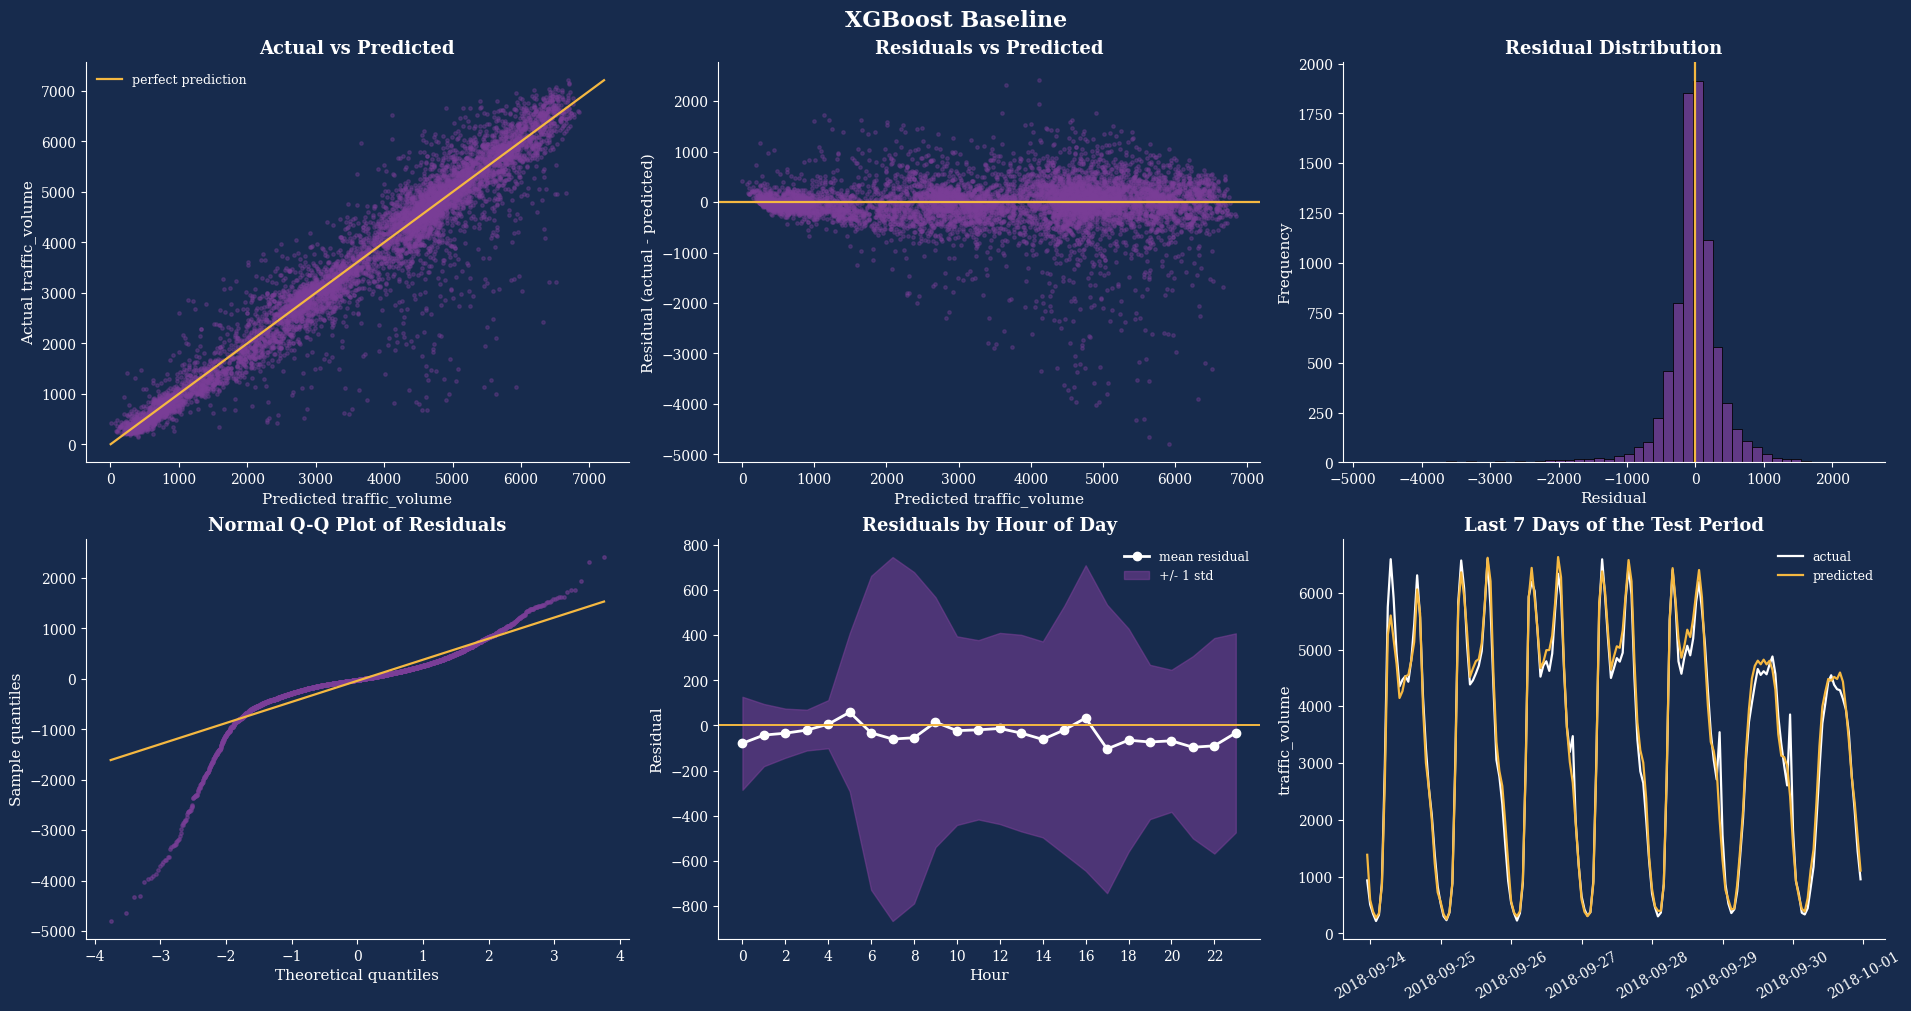

In [96]:
# Reuse the existing diagnostics() function for XGBoost
xgb_diag = {
    "name": "XGBoost Baseline",
    "y_te": test[TARGET],
    "yhat_te": pd.Series(
        xgb_baseline["predictions"],
        index=test.index,
    ),
}

diagnostics(xgb_diag)



<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">8.3 — LightGBM Regressor</h3></div>



<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
<p style="margin:0;"><b>LightGBM:</b> a gradient boosting framework designed for efficient training on tabular data. A baseline regressor will be trained using the same data split and selected features as XGBoost.</p>
</div>


In [97]:

LGBM_BASELINE_PARAMS = {
    "n_estimators": 300,
    "learning_rate": 0.1,
    "max_depth": -1,
    "num_leaves": 31,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1,
}

lgbm_model = LGBMRegressor(**LGBM_BASELINE_PARAMS)

lgbm_pipeline = make_pipeline(lgbm_model)

lgbm_baseline = evaluate_model(
    name="LightGBM Baseline",
    pipeline=lgbm_pipeline,
)



LightGBM Baseline


,n_features,n_train,train R2,test R2,test adj R2,train RMSE,test RMSE,test MAE
LightGBM Baseline,25,32460,0.9695,0.9429,0.9427,347.346,470.8973,269.2142


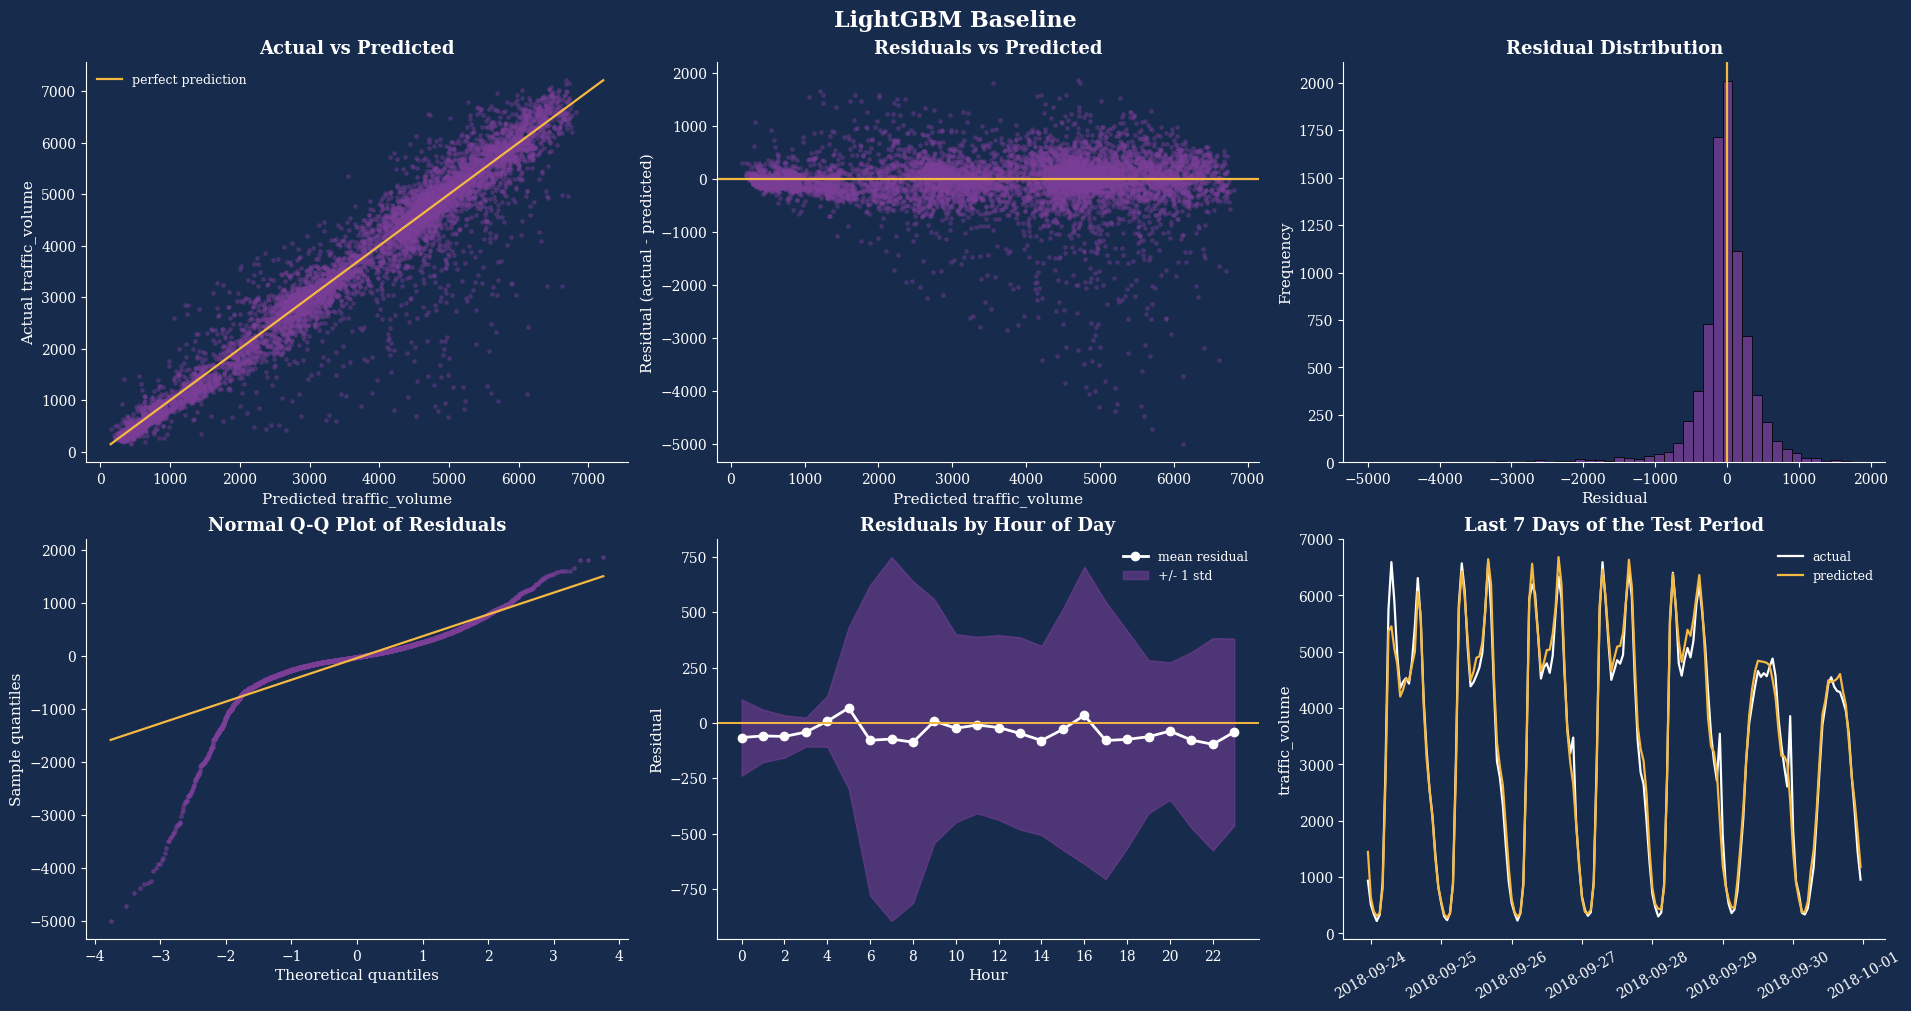

In [98]:
lgbm_diag = {
    "name": "LightGBM Baseline",
    "y_te": test[TARGET],
    "yhat_te": pd.Series(
        lgbm_baseline["predictions"],
        index=test.index,
    ),
}

diagnostics(lgbm_diag)

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">8.4 — Model Comparison</h3></div>

In [99]:

comparison_df = rf_comparison.copy()

boosting_df = pd.DataFrame.from_dict(
    {
        "XGBoost Baseline": RESULTS["XGBoost Baseline"],
        "LightGBM Baseline": RESULTS["LightGBM Baseline"],
    },
    orient="index",
)

comparison_df.index.name = "model"

final_comparison = pd.concat(
    [comparison_df, boosting_df],
    axis=0,
    sort=False,
)

display(
    final_comparison[
        [
            "n_features",
            "n_train",
            "train R2",
            "test R2",
            "train RMSE",
            "test RMSE",
            "test MAE",
        ]
    ]
    .sort_values("test RMSE")
    .round(3)
)


,n_features,n_train,train R2,test R2,train RMSE,test RMSE,test MAE
LightGBM Baseline,25,32460,0.969,0.943,347.346,470.897,269.214
XGBoost Baseline,25,32460,0.972,0.942,330.768,472.954,274.947
RF Tuned,25,32460,0.969,0.942,347.563,476.296,270.062
RF Baseline,25,32460,0.993,0.937,169.070,493.966,286.556
V4 Hour harmonics x weekend,31,32460,0.907,0.906,607.562,603.882,425.975
A Baseline (23 features),25,32460,0.858,0.857,749.963,744.872,559.248


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">8.5 — Feature Importance</h3></div>

In [100]:
# XGBoost
xgb_importance_result = permutation_importance(
    xgb_baseline["model"],
    test[FEATURES],
    test[TARGET],
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

xgb_importance = (
    pd.DataFrame({
        "feature": FEATURES,
        "importance_mean": xgb_importance_result.importances_mean,
        "importance_std": xgb_importance_result.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

# LightGBM
lgbm_importance_result = permutation_importance(
    lgbm_baseline["model"],
    test[FEATURES],
    test[TARGET],
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

lgbm_importance = (
    pd.DataFrame({
        "feature": FEATURES,
        "importance_mean": lgbm_importance_result.importances_mean,
        "importance_std": lgbm_importance_result.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

print("XGBoost — Top 15 Features")
display(xgb_importance.head(15).round(3))

print("LightGBM — Top 15 Features")
display(lgbm_importance.head(15).round(3))


XGBoost — Top 15 Features


,feature,importance_mean,importance_std
0,hour_cos,1447.543,9.860
1,hour,613.333,5.203
2,day_of_week,373.729,8.606
3,hour_sin,125.241,3.677
4,is_rush_hour,113.590,1.601
5,is_weekend,62.580,1.629
6,temp_c,39.244,3.610
7,dow_cos,16.846,1.167
8,dow_sin,13.134,1.078
9,month_cos,8.853,1.343


LightGBM — Top 15 Features


,feature,importance_mean,importance_std
0,hour,931.905,5.937
1,hour_cos,682.823,6.504
2,day_of_week,291.857,5.450
3,is_rush_hour,266.055,3.996
4,hour_sin,63.894,2.029
5,temp_c,30.308,2.780
6,dow_cos,25.959,1.360
7,month_cos,10.315,1.187
8,is_weekend,9.867,0.730
9,dow_sin,7.893,0.646


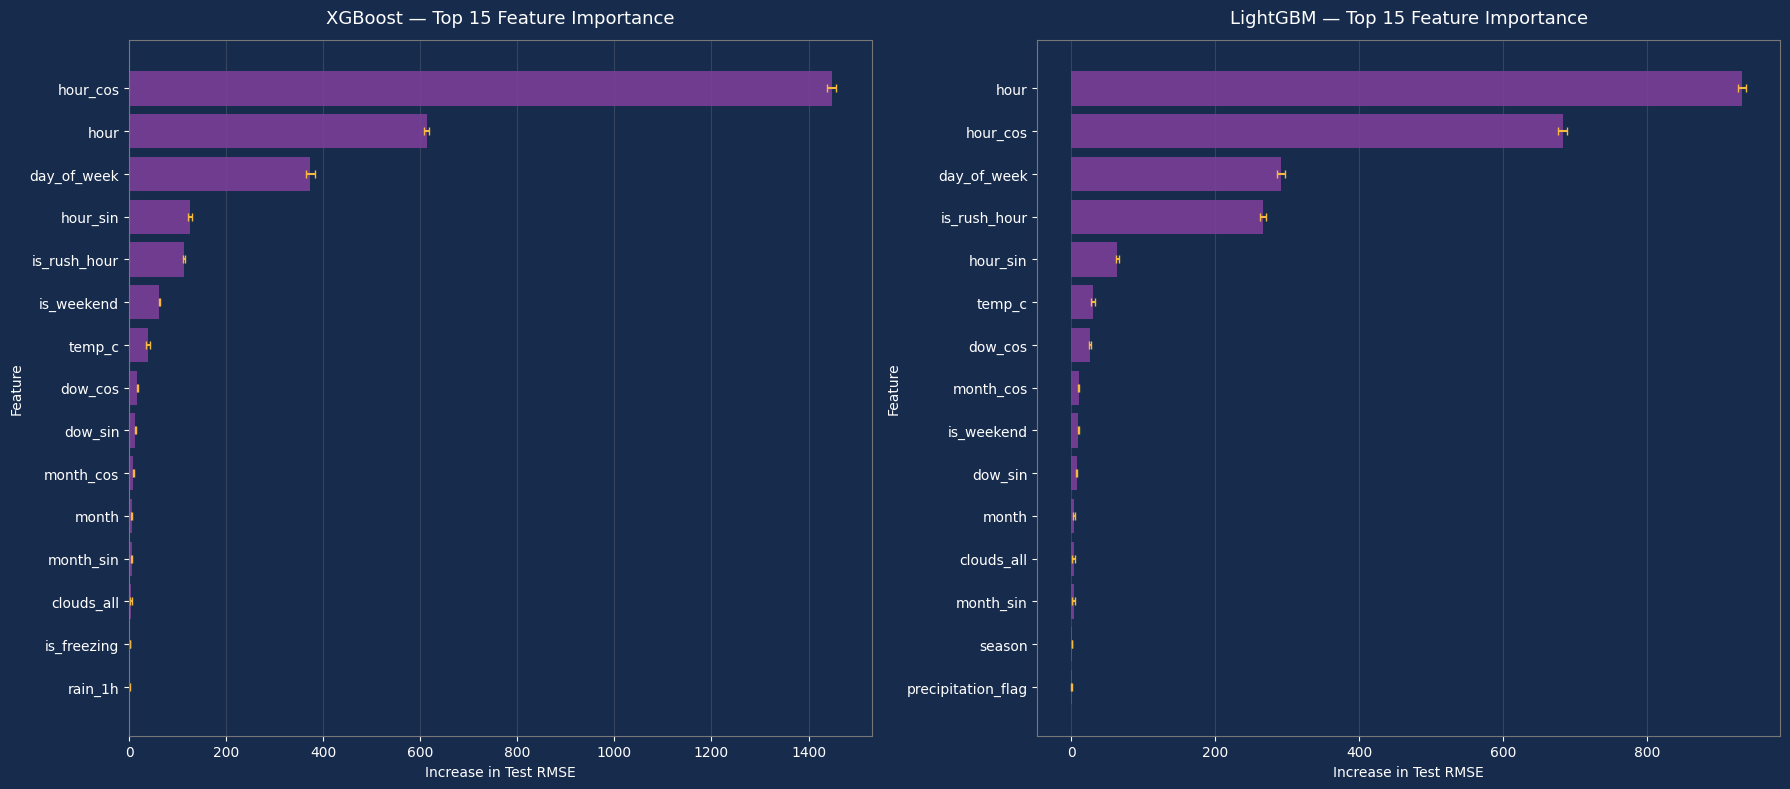

In [101]:
# Plot permutation feature importance for XGBoost and LightGBM

fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 8),
    facecolor=THEME_BG
)

plot_configs = [
    (axes[0], xgb_importance, "XGBoost — Top 15 Feature Importance"),
    (axes[1], lgbm_importance, "LightGBM — Top 15 Feature Importance"),
]

for ax, importance_df, title in plot_configs:
    # Dark background for each plot
    ax.set_facecolor(THEME_BG)

    top_features = (
        importance_df
        .head(15)
        .sort_values("importance_mean", ascending=True)
    )

    ax.barh(
        top_features["feature"],
        top_features["importance_mean"],
        xerr=top_features["importance_std"],
        color=THEME_PURPLE,
        ecolor=THEME_ACCENT,
        capsize=3,
        alpha=0.9,
    )

    ax.set_title(title, color="white", fontsize=13, pad=12)
    ax.set_xlabel("Increase in Test RMSE", color="white")
    ax.set_ylabel("Feature", color="white")

    # Make tick labels visible
    ax.tick_params(axis="x", colors="white")
    ax.tick_params(axis="y", colors="white")

    # Make axes and grid match the dark theme
    for spine in ax.spines.values():
        spine.set_color("#777777")

    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">8.6 — Conclusion</h3></div>

<div style="background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 18px; margin:10px 0 16px 0; font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55;">
<p style="margin:0;"><b>Conclusion:</b>
XGBoost and LightGBM were evaluated alongside the Baseline, V4, and Random Forest models using R², RMSE, and MAE on the same train-test split.

The V4 model used <b>31 features</b>, while the Baseline, Random Forest, and boosting models used <b>25 features after preprocessing</b>. Therefore, performance comparisons should account for these differences.

XGBoost achieved a test R² of <b>0.9424</b>, RMSE of <b>472.95</b>, and MAE of <b>274.95</b>. LightGBM performed slightly better, with an R² of <b>0.9429</b>, RMSE of <b>470.90</b>, and MAE of <b>269.21</b>.

Permutation feature importance showed that <b>hour_cos, hour, and day_of_week</b> were the three most influential features for XGBoost, while <b>hour, hour_cos, and day_of_week</b> ranked highest for LightGBM. Both models relied heavily on time-related features. However, <b>is_rush_hour</b> was more influential in LightGBM, while <b>hour_cos</b> had a stronger importance score in XGBoost. Temperature had a moderate contribution in both models, whereas most remaining features had comparatively small effects.

Overall, LightGBM slightly outperformed XGBoost. The feature importance results also highlight the importance of temporal patterns in traffic volume prediction. Final model selection should additionally consider Random Forest performance and further tuning or validation.</p>
</div>




<a id="9"></a>
<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif;"><h2 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">Hyperparameter Tuning + Model Evaluation</h2></div>


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI', sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Objective:</b> Systematically fine-tune and benchmark <b>Random Forest</b>, <b>XGBoost</b>, and <b>LightGBM</b> architectures to identify the most reliable model for forecasting hourly traffic volume.</p>

<p style="margin:0 0 8px 0;"><b>Methodology:</b> An automated tuning workflow is built using <b>Optuna</b> (TPE sampler) paired with <b>5-fold Time-Series Cross-Validation</b>. To strictly guarantee zero data leakage, each estimator is encapsulated within an end-to-end preprocessing pipeline prior to fitting.</p>

<p style="margin:0 0 8px 0;"><b>Scope:</b> This stage encompasses Bayesian hyperparameter search, multi-metric performance benchmarking (<b>RMSE, R², MAE, MAPE</b>), optimal model selection, and in-depth visual diagnostics covering convergence history, parameter importances, parallel coordinates, and residual analysis.</p>



<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.1 — Model Optimization and Evaluation Pipeline</h3></div>

In [114]:
optuna.logging.set_verbosity(optuna.logging.WARNING)



@dataclass
class ModelOptimizer:
    # Input data and configuration
    X_train: Any
    y_train: Any
    X_test: Any
    y_test: Any
    pipelines: Dict[str, Pipeline]
    n_trials: int = 30
    n_splits: int = 5
    save_dir_joblib : str = "."
    db_path: str = "../artifacts/optuna_history.db"


    # Internal state variables to store results
    studies: Dict[str, optuna.Study] = field(default_factory=dict, init=False)
    best_models: Dict[str, Pipeline] = field(default_factory=dict, init=False)
    best_params: Dict[str, Dict[str, Any]] = field(default_factory=dict, init=False)
    predictions: Dict[str, np.ndarray] = field(default_factory=dict, init=False)
    results: Dict[str, Dict[str, Any]] = field(default_factory=dict, init=False)

    def _suggest_params(self, trial: optuna.Trial, model_name: str) -> Dict[str, Any]:
        # Define hyperparameter search spaces based on the model name
        if model_name == "XGBoost":
          
             return {
            "n_estimators": trial.suggest_int("n_estimators", 300, 2500, step=100),
            "max_depth": trial.suggest_int("max_depth", 3, 10),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "colsample_bylevel": trial.suggest_float("colsample_bylevel", 0.6, 1.0),
            "gamma": trial.suggest_float("gamma", 1e-8, 2.0, log=True),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 5.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 5.0, log=True),
            "max_delta_step": trial.suggest_int("max_delta_step", 0, 5),
            }

        
        if model_name == "LightGBM":
           
             max_depth = trial.suggest_int("max_depth", 3, 10)
             return {
            "n_estimators": trial.suggest_int("n_estimators", 300, 2500, step=100),
            "max_depth": max_depth,
            "num_leaves" : trial.suggest_int("num_leaves", 4, min(63, 2 ** max_depth - 1)),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
            "min_child_samples": trial.suggest_int("min_child_samples", 10, 80),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "subsample_freq": trial.suggest_int("subsample_freq", 1, 7),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 5.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 5.0, log=True),
            "min_split_gain": trial.suggest_float("min_split_gain", 0.0, 0.5),
           }

      

        if model_name == "RandomForest":
             
            bootstrap = trial.suggest_categorical("bootstrap", [True, False])

            params = {
                "n_estimators": trial.suggest_int("n_estimators", 200, 1200, step=50),
                "max_depth": trial.suggest_categorical("max_depth", [None, 12, 16, 20, 25, 30]),
                "min_samples_split": trial.suggest_int("min_samples_split", 2, 15),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
                "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.6, 0.8, 1.0]),
                "bootstrap": bootstrap,
                "ccp_alpha": trial.suggest_float("ccp_alpha", 1e-8, 0.02, log=True),
            }

            if bootstrap:
                params["max_samples"] = trial.suggest_float("max_samples", 0.6, 1.0)

            return params
    
         
        raise ValueError(f"Unsupported model: '{model_name}'")

    def _build_pipeline(self, model_name: str, raw_params: Dict[str, Any]) -> Pipeline:
        # Clone the base pipeline and apply the new hyperparameters to the model step
        pipeline = clone(self.pipelines[model_name])
        model_step = pipeline.steps[-1][0]
        formatted_params = {f"{model_step}__{k}": v for k, v in raw_params.items()}
        return pipeline.set_params(**formatted_params)

    def _objective(self, trial: optuna.Trial, model_name: str, cv: TimeSeriesSplit) -> float:
        # Cross-validation objective function for Optuna to minimize
        print(f"\r{model_name}: Trial {trial.number + 1}/{self.n_trials} executed", end="", flush=True)
        params = self._suggest_params(trial, model_name)
        pipeline = self._build_pipeline(model_name, params)

        scores = cross_val_score(
            pipeline, self.X_train, self.y_train,
            cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1
        )
        return float(-scores.mean())

    def _evaluate(self, pipeline: Pipeline, best_cv_rmse: float) -> Tuple[np.ndarray, Dict[str, Any]]:
        # Calculate performance metrics on both training and test datasets
        y_pred_train = pipeline.predict(self.X_train)
        y_pred_test = pipeline.predict(self.X_test)

        y_true = np.asarray(self.y_test)
        valid = y_true != 0
        mape = np.mean(np.abs((y_true[valid] - y_pred_test[valid]) / y_true[valid])) * 100 if valid.any() else np.nan
        n_features = getattr(pipeline.steps[-1][1], "n_features_in_", self.X_train.shape[1])

        metrics = {
            "n_features": int(n_features),
            "n_train": len(self.X_train),
            "best_cv_rmse": round(best_cv_rmse, 4),
            "train R2": round(r2_score(self.y_train, y_pred_train), 4),
            "test R2": round(r2_score(self.y_test, y_pred_test), 4),
            "train RMSE": round(float(np.sqrt(mean_squared_error(self.y_train, y_pred_train))), 4),
            "test RMSE": round(float(np.sqrt(mean_squared_error(self.y_test, y_pred_test))), 4),
            "test MAE": round(float(mean_absolute_error(self.y_test, y_pred_test)), 4),
            "test MAPE (%)": round(float(mape), 4),
        }
        return y_pred_test, metrics

    @staticmethod
    def _print_params(params: Dict[str, Any]) -> None:
        # Helper method to print parameters clearly
        for k, v in params.items():
            val = round(float(v), 6) if isinstance(v, (float, np.floating)) else v
            print(f"  - {k}: {val}")

    def _display_summary(self) -> None:
       # Print a final summary of all models and highlight the best performer
        results_df = pd.DataFrame.from_dict(self.results, orient="index")
        print("\nFinal Evaluation Results:")
        display(results_df)

        best_model = min(self.studies, key=lambda name: self.studies[name].best_value)
        best_rmse = results_df.loc[best_model, "test RMSE"]
        best_r2 = results_df.loc[best_model, "test R2"]

        print("\n" + "=" * 50)
        print(f"BestModel {best_model}")
        print(f"  - Test RMSE: {best_rmse:.4f}")
        print(f"  - Test R2:   {best_r2:.4f}")
        print("=" * 50)
        print("Best Parameters:")
        self._print_params(self.best_params[best_model])
        print("=" * 50)

    def _save_model(self, model_name: str, pipeline: Pipeline) -> None:
        # Save the optimized pipeline to disk using joblib
        file_path = os.path.join(self.save_dir_joblib, f"{model_name}_optimizer.joblib")
        
        try:
            joblib.dump(pipeline, file_path , compress=3)
            print(f"Saved: {file_path}")
        except FileNotFoundError:
            print(f"Warning: Directory '{self.save_dir_joblib}' not found. '{model_name}' was NOT saved.")

    def run(self) -> None:
        # Main execution method: run optimization for all pipelines
        self.studies.clear()
        self.best_models.clear()
        self.best_params.clear()
        self.predictions.clear()
        self.results.clear()

        cv = TimeSeriesSplit(n_splits=self.n_splits)
        sqlite_url = f"sqlite:///{os.path.abspath(self.db_path).replace('\\', '/')}"

        for model_name in self.pipelines:
            print(f"\n--- Optimizing {model_name} ---")
            # Create or load an Optuna study with a SQLite backend
            study = optuna.create_study(
                study_name=f"{model_name}_optimization",
                storage= sqlite_url,
                load_if_exists=True,
                direction="minimize",
                sampler=optuna.samplers.TPESampler(seed=42)
            )
            completed_trials = len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE])
            trials_to_run = max(0, self.n_trials - completed_trials)
            # Run trials if not already completed
            if trials_to_run > 0:
                print(f"Resuming... {completed_trials} trials done. Running {trials_to_run} more.")
                study.optimize(
                    lambda trial: self._objective(trial, model_name, cv),
                    n_trials=trials_to_run 
                )
            else:
                print(f"Study already completed {completed_trials} trials. Loading best results from DB...")
            print()

            print(f"\nBest Hyperparameters for {model_name}:")
            self._print_params(study.best_params)

            # Retrain the pipeline on the full training set using the best parameters
            final_pipe = self._build_pipeline(model_name, study.best_params)
            final_pipe.fit(self.X_train, self.y_train)

            # Evaluate and store results
            preds, metrics = self._evaluate(final_pipe, study.best_value)

            self.studies[model_name] = study
            self.best_params[model_name] = study.best_params
            self.best_models[model_name] = final_pipe
            self.predictions[model_name] = preds
            self.results[model_name] = metrics

            self._save_model(model_name, final_pipe)
            print(f"[{model_name}] Test RMSE: {metrics['test RMSE']:.4f} | Test R2: {metrics['test R2']:.4f}\n")

        self._display_summary()

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.2 — Running Hyperparameter Tuning & Evaluation</h3></div>

In [115]:
# Define paths for saving models, the Optuna database , report for tuning and report for evaluation
model_path = "../artifacts/trained_models"
db_path = "../artifacts/hyperparameter_tuning/optuna_history.db"
tuning_path = "../artifacts/hyperparameter_tuning"
evalaution_path = "../artifacts/evaluation_reports"

# Define a dictionary of machine learning pipelines to evaluate
pipelines_dict = {
    
    "XGBoost": Pipeline([
        # Preprocessing step applied before training
        ("prep", make_preprocessor()),
        # XGBoost regressor with fixed random state and objective
        ("model", XGBRegressor(random_state=42, n_jobs=1, objective="reg:squarederror"))
    ]),
    "LightGBM": Pipeline([
        ("prep", make_preprocessor()),
        # LightGBM regressor (verbosity=-1 suppresses warnings/logs)
        ("model", LGBMRegressor(random_state=42, n_jobs=1, verbosity=-1))
    ]),
    
    "RandomForest": Pipeline([
            ("prep", make_preprocessor()),
            # Random Forest regressor with fixed random state
            ("model", RandomForestRegressor(random_state=42, n_jobs=1))
        ])
}

# Initialize the ModelOptimizer with data, pipelines, and settings
optimizer = ModelOptimizer(
    X_train=train[FEATURES],
    y_train=train[TARGET],
    X_test=test[FEATURES],
    y_test=test[TARGET],
    pipelines=pipelines_dict,
    n_trials=300,                   # Number of optimization trials per model
    save_dir_joblib=model_path,   # Directory to save the optimized models
    db_path=db_path   # Path to SQLite DB for resuming/tracking Optuna studies
)

# Start the hyperparameter tuning, evaluation, and saving process
optimizer.run()
  


--- Optimizing XGBoost ---
Study already completed 300 trials. Loading best results from DB...


Best Hyperparameters for XGBoost:
  - n_estimators: 300
  - max_depth: 7
  - learning_rate: 0.014517
  - min_child_weight: 20
  - subsample: 0.693909
  - colsample_bytree: 0.820198
  - colsample_bylevel: 0.636542
  - gamma: 0.05483
  - reg_alpha: 0.0
  - reg_lambda: 0.114826
  - max_delta_step: 0
Saved: ../artifacts/trained_models\XGBoost_optimizer.joblib
[XGBoost] Test RMSE: 465.8370 | Test R2: 0.9441


--- Optimizing LightGBM ---
Study already completed 300 trials. Loading best results from DB...


Best Hyperparameters for LightGBM:
  - max_depth: 9
  - n_estimators: 400
  - num_leaves: 53
  - learning_rate: 0.013813
  - min_child_samples: 71
  - subsample: 0.605365
  - subsample_freq: 4
  - colsample_bytree: 0.600241
  - reg_alpha: 0.007411
  - reg_lambda: 0.160984
  - min_split_gain: 0.125121
Saved: ../artifacts/trained_models\LightGBM_optimizer.joblib
[LightGBM] Test RMSE: 466.5627 | 

,n_features,n_train,best_cv_rmse,train R2,test R2,train RMSE,test RMSE,test MAE,test MAPE (%)
XGBoost,25,32460,485.5363,0.9535,0.9441,428.9383,465.8370,265.2480,13.4167
LightGBM,25,32460,484.6184,0.9543,0.9439,425.2945,466.5627,263.7058,13.3677
RandomForest,25,32460,484.2659,0.9617,0.9446,388.9369,463.7611,263.4351,12.5938



BestModel RandomForest
  - Test RMSE: 463.7611
  - Test R2:   0.9446
Best Parameters:
  - bootstrap: True
  - n_estimators: 800
  - max_depth: 16
  - min_samples_split: 9
  - min_samples_leaf: 4
  - max_features: sqrt
  - ccp_alpha: 0.0
  - max_samples: 0.907022


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Conclusion:</b>
Random Forest, XGBoost, and LightGBM models were each optimized over <b>300 trials</b> using Optuna and evaluated on the same chronological train-test split (<b>32,460 training samples</b>). All models consistently used <b>25 features after preprocessing</b> to ensure a fair baseline for comparison.</p>

<p style="margin:0 0 8px 0;">After hyperparameter tuning, <b>Random Forest emerged as the best-performing model</b> across every evaluation metric, achieving the lowest Cross-Validation RMSE (<b>484.27</b>), lowest Test RMSE (<b>463.76</b>), highest Test R² (<b>0.9446</b>), lowest MAE (<b>263.44</b>), and lowest MAPE (<b>12.59%</b>). <b>XGBoost</b> followed closely in test variance metrics with a Test RMSE of <b>465.84</b> and an R² of <b>0.9441</b> (CV RMSE: <b>485.54</b>, MAE: <b>265.25</b>, MAPE: <b>13.42%</b>), while <b>LightGBM</b> achieved a slightly better CV RMSE (<b>484.62</b>), MAE (<b>263.71</b>), and MAPE (<b>13.37%</b>) with a Test RMSE of <b>466.56</b> and an R² of <b>0.9439</b>.</p>

<p style="margin:0;">Overall, the Optuna optimization successfully narrowed the performance gap among the candidates, with <b>Random Forest</b> selected as the final optimal model configured with <code>bootstrap=True</code>, <code>n_estimators=800</code>, <code>max_depth=16</code>, <code>min_samples_split=9</code>, <code>min_samples_leaf=4</code>, <code>max_features='sqrt'</code>, and <code>max_samples=0.91</code> (outperforming tuned <b>XGBoost</b> at <code>n_estimators=300</code>, <code>max_depth=7</code>, <code>learning_rate=0.015</code> and <b>LightGBM</b> at <code>n_estimators=400</code>, <code>max_depth=9</code>, <code>num_leaves=53</code>, <code>learning_rate=0.014</code>).</p>
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.3 — Saving the Tuning Results</h3></div>

In [117]:
# Initialize a dictionary to store the summary of all optimization results
summary = {}
for name, study in optimizer.studies.items():
    # Save the history of all Optuna trials for this model to a CSV file
    study.trials_dataframe().to_csv(f"{tuning_path}/{name}_trials.csv", index=False)
    # Store the best parameters and performance metrics for the summary
    summary[name] = {
        "best_params": optimizer.best_params[name],
        "best_cv_rmse": float(study.best_value),
        "test_metrics": {k: float(v) for k, v in optimizer.results[name].items()},
    }

# Save the final optimization summary to a JSON file
with open(f"{tuning_path}/tuning_summary.json", "w") as f:
    # Use a custom lambda function to handle numpy data types during JSON serialization
    json.dump(summary, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
# Combine predictions from legacy or baseline models into a single DataFrame and save as CSV
pd.DataFrame({
    "Linear regression A (5)": np.asarray(res_a["yhat_te"]),
    "Linear regression V4 (5)": np.asarray(res_v4["yhat_te"]),
    "Random Forest baseline (7)": np.asarray(res_rf_base["yhat_te"]),
    "Random Forest tuned by CV (7)": np.asarray(res_rf_tuned["yhat_te"]),
    "XGBoost baseline (8)": np.asarray(xgb_baseline["predictions"]),
    "LightGBM baseline (8)": np.asarray(lgbm_baseline["predictions"]),
}, index=test.index).to_csv(f"{evalaution_path}/legacy_predictions.csv")

# Extract the 'weather_group' column from the original dataframe and save it
df[["weather_group"]].to_csv(f"{evalaution_path}/weather_group.csv")

# Print a list of all saved files in the artifacts directory along with their sizes in MB
for root, dirs, files in os.walk("../artifacts"):
    for file in sorted(files):
        file_path = os.path.join(root, file)
        size_mb = os.path.getsize(file_path) / 1e6
        print(f"{os.path.relpath(file_path, '../artifacts'):60s} {size_mb:8.2f} MB")

evaluation_reports\cv_folds.csv                                  0.00 MB
evaluation_reports\legacy_predictions.csv                        0.91 MB
evaluation_reports\weather_group.csv                             1.43 MB
hyperparameter_tuning\LightGBM_trials.csv                        0.07 MB
hyperparameter_tuning\RandomForest_trials.csv                    0.05 MB
hyperparameter_tuning\XGBoost_trials.csv                         0.08 MB
hyperparameter_tuning\optuna_history.db                          1.60 MB
hyperparameter_tuning\tuning_summary.json                        0.00 MB
trained_models\LightGBM_optimizer.joblib                         0.67 MB
trained_models\RandomForest_optimizer.joblib                    85.25 MB
trained_models\XGBoost_optimizer.joblib                          0.78 MB


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 0 0;"><b>Why:</b> the three fitted pipelines, the Optuna trials, the best parameters, the predictions of the earlier models, and the weather groups are saved once into <code>../data/artifacts</code>, organized into three clean subdirectories: <code>trained_models</code>, <code>hyperparameter_tuning</code>, and <code>evaluation_reports</code>. Section 10 reads these files, so it never has to repeat or refit the tuning. It reads directly from the <code>optuna_history.db</code> history file; therefore, there is no waiting time, regardless of how many times the code is executed.</p>
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.4 — Visualizing Optimization History</h3></div>

Best model for visualization:
Best model: RandomForest
Best CV RMSE: 484.26590526079326


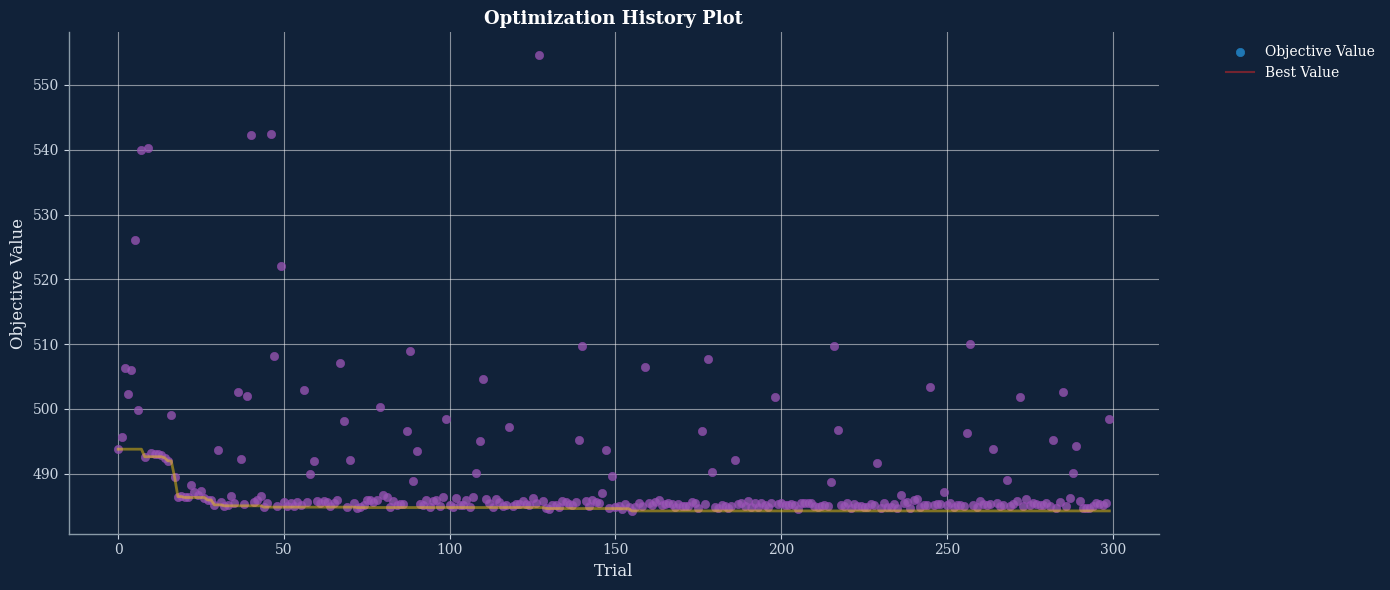

In [119]:

# Retrieve all Optuna studies generated by the optimizer
all_studies = optimizer.studies


# Identify the name of the best performing model by finding the minimum CV RMSE (best_value)
best_model_name = min(
    all_studies,
    key=lambda name: all_studies[name].best_value
)

# Extract the study object corresponding to the best model
best_study = all_studies[best_model_name]

print("Best model for visualization:")
print("Best model:", best_model_name)
print("Best CV RMSE:", best_study.best_value)



def plot_optuna(plot_func, best_study, figsize=(14, 6), **kwargs):
    # Define a helper function to wrap Optuna plots and apply a custom dark theme
    plt.rcdefaults()

    # Update Matplotlib global parameters for the custom dark UI
    plt.rcParams.update({
        'figure.facecolor': '#112239',
        'axes.facecolor': '#112239',
        'axes.edgecolor': '#8a9ba8',
        'axes.labelcolor': '#e2e8f0',
        'xtick.color': '#cbd5e1',
        'ytick.color': '#cbd5e1',
        'text.color': '#ffffff',
        'font.family': 'serif',
        'axes.grid': True,
        'grid.color': '#233954',
        'grid.linestyle': '--',
        'grid.alpha': 0.5,
    })

    # Auto-detect if the parameter importance plot is being called
    # If yes, inject the FanovaImportanceEvaluator with a fixed seed (42) internally
    if plot_func.__name__ == 'plot_param_importances':
        evaluator = FanovaImportanceEvaluator(seed=42)
        ax = plot_func(best_study, evaluator=evaluator, **kwargs)
    else:
        # Generate the base plot normally for all other functions
        ax = plot_func(best_study, **kwargs)

    fig = plt.gcf()
    fig.set_size_inches(figsize)
    fig.patch.set_facecolor('#112239')

    # Iterate through all axes (subplots) to apply detailed styling
    for a in fig.axes:
        a.set_facecolor('#112239')
        a.title.set_color('#ffffff')
        a.title.set_fontweight('bold')
        a.title.set_fontsize(13)
        a.xaxis.label.set_color('#e2e8f0')
        a.yaxis.label.set_color('#e2e8f0')
        a.tick_params(colors='#cbd5e1', labelsize=10)

        # Style the borders (spines) of the main axis
        if a is ax:
            a.spines['top'].set_visible(False)
            a.spines['right'].set_visible(False)
            a.spines['bottom'].set_color('#8a9ba8')
            a.spines['left'].set_color('#8a9ba8')
        else:
            for spine in a.spines.values():
                spine.set_color('#8a9ba8')

        # Style bar charts or histograms (patches)
        for patch in a.patches:
            patch.set_facecolor('#8e44ad')
            patch.set_edgecolor('#a569bd')
            patch.set_alpha(0.85)

        # Style scatter plots and line collections
        for col in a.collections:
            if isinstance(col, PathCollection):
                col.set_facecolor('#9b59b6')
                col.set_edgecolor('#8e44ad')
                col.set_alpha(0.75)
            elif isinstance(col, LineCollection):
                col.set_cmap('plasma')
                col.set_alpha(0.75)

        # Style standard line plots
        for line in a.lines:
            line.set_color('#f1c40f')
            line.set_linewidth(2)

        # Style text annotations
        for txt in a.texts:
            txt.set_color('#ffffff')
            txt.set_fontweight('bold')

        # Style the legend if it exists
        leg = a.get_legend()
        if leg:
            leg.get_frame().set_facecolor('#112239')
            leg.get_frame().set_edgecolor('none')
            for text in leg.get_texts():
                text.set_color('#ffffff')

    fig.tight_layout()
    plt.show()



# Plot the optimization history for the best study using the custom dark theme
plot_optuna(vis.plot_optimization_history, best_study)




<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Optimization History Analysis:</b>
The optimization history plot illustrates the hyperparameter tuning process for the best-performing model (<b>Random Forest</b>) over <b>300 trials</b> using Optuna's TPE sampler.</p>

<p style="margin:0 0 8px 0;">In this visualization, each dot represents the <b>Objective Value</b> (Cross-Validation RMSE) obtained from a single trial, while the solid line tracks the <b>Best Value</b> achieved up to that point. The optimization process starts with an RMSE of approximately <b>494</b> and shows noticeable improvement during the first <b>30–50 trials</b>, eventually reaching a best-value plateau at <b>484.27</b> (around <b>484–485</b>).</p>

<p style="margin:0;">After approximately <b>trial 50</b>, the best-value trajectory remains nearly flat, indicating that no substantial improvement in the objective value was achieved during the subsequent trials. The scattered trial points show that different hyperparameter combinations continued to produce varying RMSE values across the search space. Although the optimization appears to have stabilized into a reliable plateau, this plot alone does not guarantee that the global optimum has been found.</p>
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.5 — Visualizing Hyperparameter Importances</h3></div>

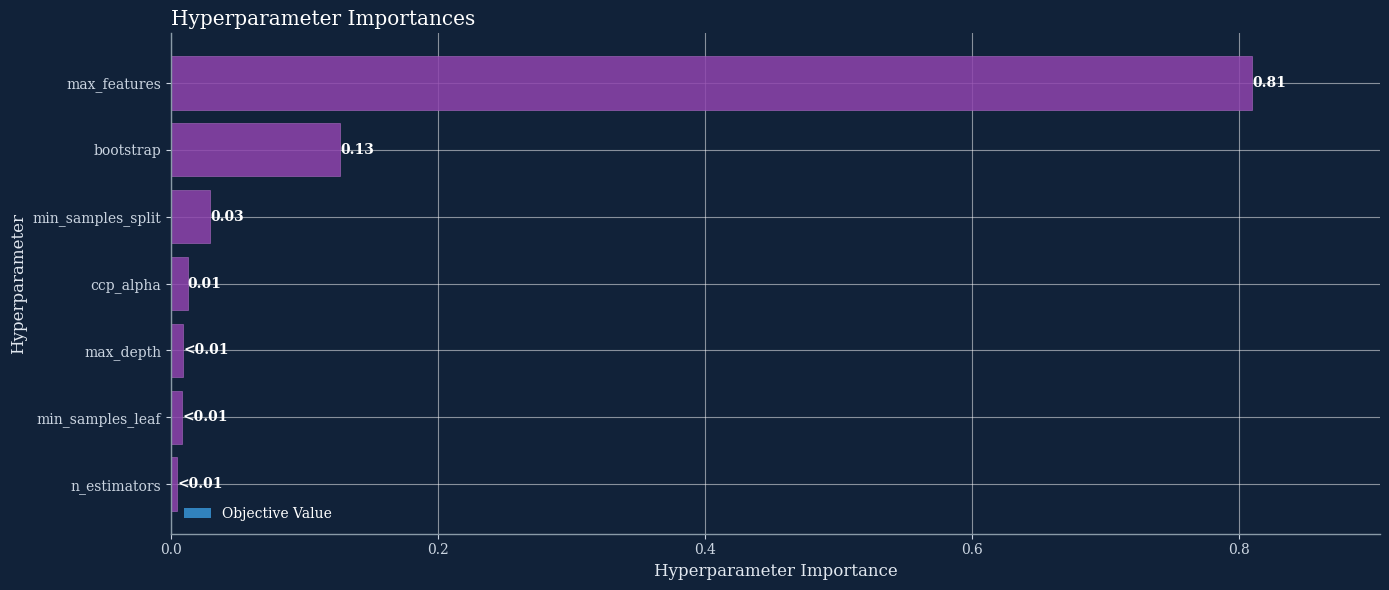

In [120]:

# Plot the hyperparameter importances for the best study to visualize which parameters had the most impact on model performance
plot_optuna(vis.plot_param_importances, best_study)



<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Hyperparameter Importance Analysis:</b> The plot shows the relative impact of each tuned hyperparameter on the objective value (Cross-Validation RMSE) for the optimal <b>Random Forest</b> model across the 300 Optuna trials. A long bar means that the choice of this parameter changed the CV RMSE a lot within the explored range; a bar close to zero means little isolated effect.</p>
<p style="margin:0 0 0 0;">As observed in the chart, <code>max_features</code> is overwhelmingly the most influential parameter (score: 0.81), followed by <code>bootstrap</code> (score: 0.13). <code>min_samples_split</code> shows a very minor effect (score: 0.03), while the remaining hyperparameters (<code>max_depth</code>, <code>ccp_alpha</code>, <code>n_estimators</code>, and <code>min_samples_leaf</code>) show negligible importance (scores &lt; 0.01). This indicates the search was highly sensitive to the choice of <code>max_features</code>, while the model's performance remained relatively robust to variations in the other parameters within the explored ranges.</p>
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.6 — Visualizing Parameter Interactions (Parallel Coordinates)</h3></div>

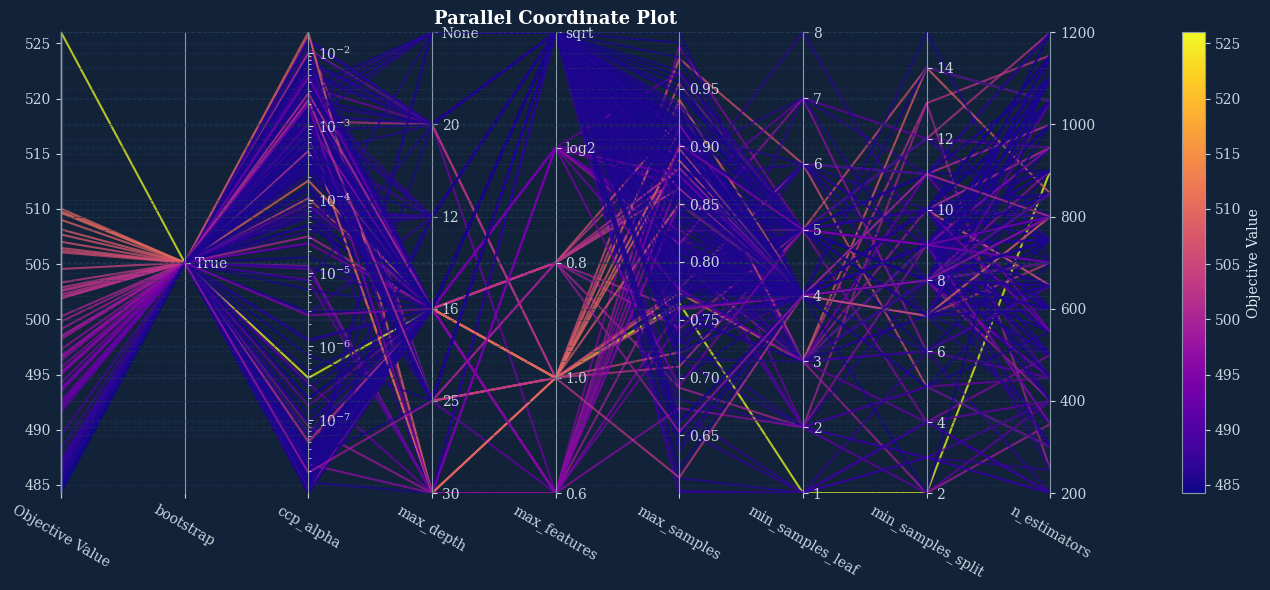

In [121]:
# Plot a parallel coordinate chart for the best study to visualize how different combinations of hyperparameters affect the model's performance
plot_optuna(vis.plot_parallel_coordinate, best_study)

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Parallel Coordinates Analysis (Hyperparameter Interactions):</b> Each line is one trial and its colour is the Cross-Validation RMSE: darker lines are better trials (the best reaches <b>484.27</b>). Following the dark lines shows the region of the search space where the best trials concentrate.</p>
<p style="margin:0 0 0 0;">By tracing the optimal (yellow) path across the axes, the best configuration found is <code>bootstrap=True</code>, <code>max_features='sqrt'</code>, <code>n_estimators=800</code>, <code>max_depth=16</code>, <code>min_samples_split=9</code>, <code>min_samples_leaf=4</code>, <code>ccp_alpha=0.0</code>, and <code>max_samples=0.907</code>. As in the previous section, this plot visualizes the search behavior and interactions rather than proving causal effects of single parameters.</p>
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.7 — Best Model Diagnostics and Residual Analysis</h3></div>

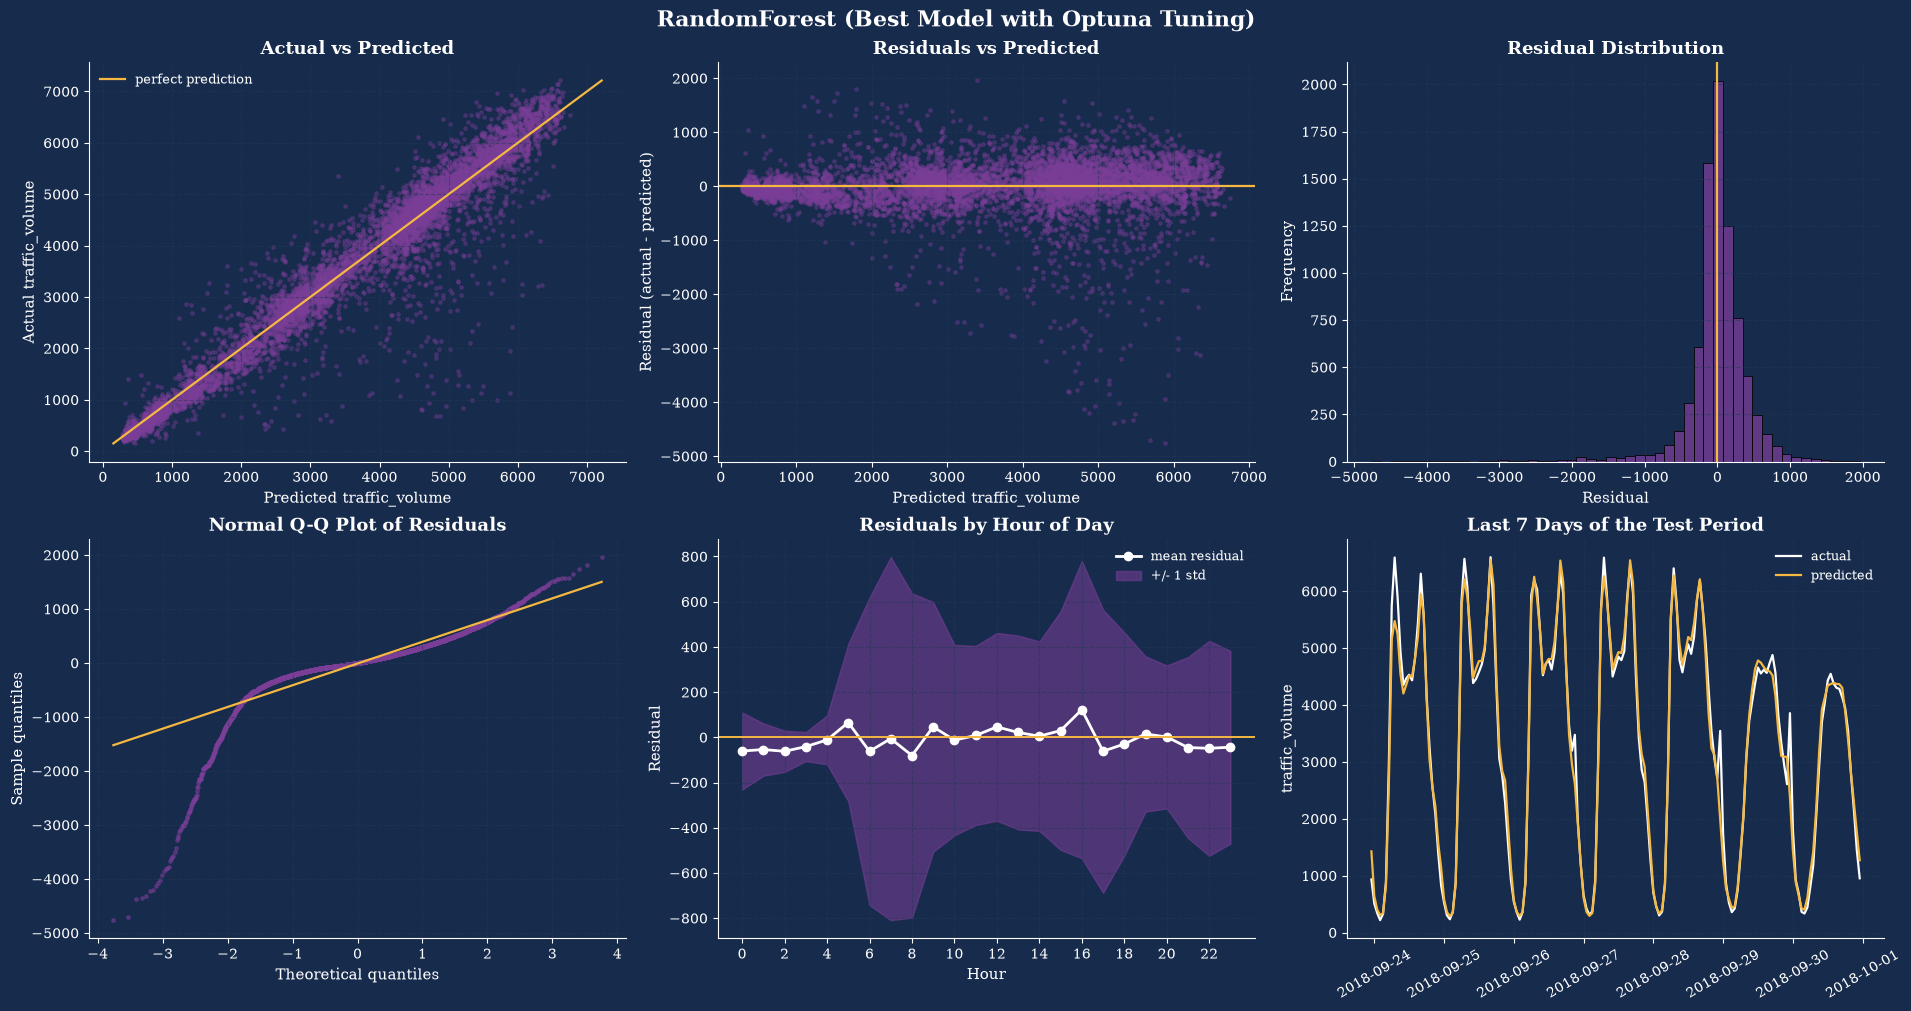

In [170]:
# Extract evaluation results, Optuna studies, and test predictions from the optimizer
all_results = optimizer.results
all_studies = optimizer.studies
all_predictions = optimizer.predictions

# Convert the evaluation results dictionary into a pandas DataFrame for easier viewing
results_df = pd.DataFrame.from_dict(all_results, orient="index")

# Identify the best performing model by finding the minimum objective value (CV RMSE) among all studies
best_model_name = min(
    all_studies,
    key=lambda name: all_studies[name].best_value
) 

# Prepare a dictionary containing the true labels and predictions of the best model for diagnostic analysis
best_model_diag = {
    "name": f"{best_model_name} (Best Model with Optuna Tuning)",
    "y_te": test[TARGET],
    "yhat_te": pd.Series(
        all_predictions[best_model_name],
        index=test.index,
    ),
}

# Run the custom diagnostics function to evaluate and visualize the best model's performance
diagnostics(best_model_diag)

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<p style="margin:0 0 8px 0;"><b>Model Evaluation and Residual Diagnostics:</b> This figure presents a comprehensive diagnostic analysis of the optimal <b>Random Forest</b> model, visualizing its predictive accuracy, error distribution, and temporal performance.</p>

<ul style="margin:0 0 8px 0; padding-left:20px;">
    <li style="margin-bottom:6px;"><b>Actual vs Predicted:</b> The predictions closely follow the perfect prediction line (yellow), demonstrating high overall accuracy (Test R² = 0.9446). However, there is slight heteroscedasticity, as the spread of errors increases at higher traffic volumes (above 4,000 vehicles/hour).</li>
    <li style="margin-bottom:6px;"><b>Residuals vs Predicted:</b> The residuals are generally centered around zero, indicating no massive systemic bias. Similar to the first plot, the variance expands at higher predicted volumes, and there are some extreme negative residuals (representing over-predictions during high-volume periods).</li>
    <li style="margin-bottom:6px;"><b>Residual Distribution:</b> The histogram shows that the errors are approximately normally distributed around zero. However, it exhibits leptokurtic behavior (heavy tails), meaning extreme errors, though rare, are more frequent than a perfect normal distribution would suggest.</li>
    <li style="margin-bottom:6px;"><b>Normal Q-Q Plot:</b> The middle quantiles align well with the theoretical line, but the tails deviate significantly (especially the lower tail dropping sharply). This confirms the heavy-tailed nature of the residuals observed in the histogram.</li>
    <li style="margin-bottom:6px;"><b>Residuals by Hour of Day:</b> The mean residual (white line) remains close to zero throughout the 24 hours, proving the model is unbiased across different times of the day. However, the variance (purple shaded area, ±1 std) is notably wider during rush hours (e.g., 6 AM - 9 AM and 3 PM - 6 PM), reflecting the inherent difficulty of predicting highly volatile peak traffic.</li>
    <li style="margin-bottom:0;"><b>Last 7 Days of the Test Period:</b> The time-series plot for the final week (2018-09-24 to 2018-10-01) shows that the model successfully captures the daily cyclical patterns, rush-hour peaks, and weekend traffic drops with high fidelity.</li>
</ul>

<p style="margin:0;">Overall, these diagnostics confirm that while the model is highly robust and accurate, most prediction errors stem from the complexity of extreme peak traffic volumes rather than systematic bias.</p>

</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">9.8 — Conclusion</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<p style="margin:0 0 8px 0;"><b>Conclusion:</b> In this study, an end-to-end machine learning pipeline was developed to forecast hourly traffic volume using <b>25 preprocessed features</b> across <b>32,460 training records</b>. Following automated hyperparameter optimization over <b>300 trials</b> via Optuna with 5-fold Time-Series Cross-Validation, <b>Random Forest emerged as the best-performing model</b> across all evaluation metrics—achieving the lowest CV RMSE (<b>484.27</b>), lowest Test RMSE (<b>463.76</b>), lowest MAE (<b>263.44</b>), lowest MAPE (<b>12.59%</b>), and highest Test R² (<b>0.9446</b>). It outperformed both tuned <b>XGBoost</b> (Test RMSE: <b>465.84</b>, MAE: <b>265.25</b>, MAPE: <b>13.42%</b>, R²: <b>0.9441</b>) and tuned <b>LightGBM</b> (Test RMSE: <b>466.56</b>, MAE: <b>263.71</b>, MAPE: <b>13.37%</b>, R²: <b>0.9439</b>).</p>

<p style="margin:0 0 8px 0;">Optimization diagnostics revealed that the Random Forest search converged rapidly within the first <b>30–50 trials</b>, stabilizing at its optimal configuration (<code>bootstrap=True</code>, <code>n_estimators=800</code>, <code>max_depth=16</code>, <code>min_samples_split=9</code>, <code>min_samples_leaf=4</code>, <code>max_features='sqrt'</code>, and <code>max_samples=0.91</code>). Hyperparameter importance analysis confirmed that <b><code>max_features</code></b> (<b>82%</b> importance) and <b><code>bootstrap</code></b> (<b>13%</b> importance) accounted for <b>95%</b> of the performance variance, effectively decorrelating the ensemble and preventing overfitting without relying on aggressive post-pruning (<code>ccp_alpha=0.0</code>).</p>

<p style="margin:0;">Comprehensive residual diagnostics further validated the robustness of the selected model across the entire traffic volume range (0 to 7,000 vehicles/hour). While prediction errors were centered close to zero overall (mean residual of approximately <b>−9 vehicles/hour</b>), the bias was not uniform across conditions: approximately <b>−60 vehicles/hour in spring</b>, <b>−10 on weekends</b>, and <b>−960 on federal holidays</b> (negative values indicate over-prediction). The model showed wider error variance during rush hours but maintained no systematic diurnal bias across the 24-hour cycle. Finally, time-series evaluation over the final 7 days of the test period (2018-09-24 to 2018-10-01) confirmed exceptional tracking precision across both bimodal weekday rush-hour peaks and unimodal weekend traffic profiles.</p>

</div>


<a id="10"></a>
<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif;"><h2 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">Final Model &amp; Final Analysis</h2></div>


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Objective:</b> Lock the final model with a defensible choice, report its performance once on the untouched test period against a naive baseline, explain what drives its predictions, and show where its errors concentrate.</p>
<p style="margin:0 0 8px 0;"><b>Methodology:</b></p>
<ul style="margin:0 0 8px 0; padding-left:20px;"><li style="margin-bottom:4px;">The three tuned models are <b>loaded from the files saved after 9.2</b>. Nothing is tuned or refitted in this section. The only new computation is a fold-by-fold cross-validation (15 short fits), which is cached after its first run.</li><li style="margin-bottom:4px;">Candidates are compared fold by fold on the <b>same 5 expanding-window validation folds</b> that Optuna used (training data only). The test set takes no part in choosing the model.</li><li style="margin-bottom:4px;">A <b>naive baseline</b> (mean traffic of every weekday &times; hour pair, learned on the training part) shows what the models add.</li><li style="margin-bottom:4px;">The final model is scored once on the test part with five metrics: R², RMSE, MAE, WAPE and MAPE.</li><li style="margin-bottom:4px;"><b>SHAP</b> (TreeExplainer) explains the final model on a random sample of 1,500 test hours.</li><li style="margin-bottom:4px;">The <b>error analysis</b> attaches holiday and weather information to the test errors <b>only to group them</b>. Neither is a model input.</li></ul>
<p style="margin:0 0 8px 0;"><b>Scope:</b> 10.1 CV model comparison, 10.2 naive baseline, 10.3 final model, 10.4 comparison of all models, 10.5 SHAP, 10.6 error analysis, 10.7 interpretation, 10.8 limitations, 10.9 next steps, 10.10 final conclusion.</p>
<p style="margin:0 0 0 0;"><b>Note:</b> The cell of 9.2b must have been run once (it writes the files). If the files are missing, each model is fitted <b>once</b> from the hyper-parameters printed in 9.2, without any Optuna search. SHAP needs the <code>shap</code> package (<code>pip install shap</code>).</p>
</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.1 — Model Comparison Based on Time-Series Cross-Validation</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 0 0;"><b>Why cross-validation:</b> the final model must not be chosen with the test set. The three tuned candidates are therefore compared on the five time-ordered validation windows of the training data, fold by fold, so that a difference between models can be judged against the fold-to-fold variation.</p>
</div>

In [183]:

# ============================================================
# 10.0  Load and prepare saved files from Section 9
# ------------------------------------------------------------
# This cell uses only the files saved in Section 9.
# ============================================================

model_path = globals().get("model_path", "../artifacts/trained_models")
tuning_path = globals().get("tuning_path", "../artifacts/hyperparameter_tuning")
evalaution_path = globals().get("evalaution_path", "../artifacts/evaluation_reports")

# ---- Training and test data: use the current session, or rebuild from Section 4.5 outputs ----
_needed_data = ["train", "test", "df", "FEATURES", "TARGET", "NUM_COLS", "CAT_COLS"]
if not all(name in globals() for name in _needed_data):
    TARGET = "traffic_volume"
    df = (pd.read_csv("../data/data_cleaning.csv", parse_dates=["date_time"])
            .sort_values("date_time").set_index("date_time"))
    QA_COLS = [c for c in df.columns if c.startswith("qa_")]
    FEATURES = [c for c in df.columns if c != TARGET and c not in QA_COLS]
    CAT_COLS = ["season"]
    NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
    split_idx = int(len(df) * (1 - 0.20))                 # Same chronological 80/20 split as in Section 5
    train, test = df.iloc[:split_idx], df.iloc[split_idx:]
    print("Training and test data reconstructed from ../data/data_cleaning.csv.")

assert len(FEATURES) == 23, "The cleaned output (Section 4) must contain 23 input features"
assert train.index.max() < test.index.min(), "The train/test split must be chronological"

# ---- Plot styling and helper functions: define only if not already available from previous sections ----
if "THEME_BG" not in globals():
    THEME_BG, THEME_PURPLE, THEME_LAVENDER, THEME_ACCENT = "#172B4D", "#7B3F98", "#D8D6FF", "#F5B841"

if "style_axes" not in globals():
    def style_axes(ax, title=None, xlabel=None, ylabel=None, title_size=13):
        ax.set_facecolor(THEME_BG)
        if title is not None:
            ax.set_title(title, fontsize=title_size, fontweight="bold", fontfamily="serif", color="white")
        if xlabel is not None:
            ax.set_xlabel(xlabel, fontsize=11, fontfamily="serif", color="white")
        if ylabel is not None:
            ax.set_ylabel(ylabel, fontsize=11, fontfamily="serif", color="white")
        ax.tick_params(axis="both", colors="white", labelfontfamily="serif")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_color("white")
        ax.spines["bottom"].set_color("white")

if "style_legend" not in globals():
    def style_legend(ax, **kwargs):
        return ax.legend(frameon=False, labelcolor="white", prop={"family": "serif", "size": 9}, **kwargs)

if "RUSH_HOURS" not in globals():
    RUSH_HOURS = [6, 7, 8, 15, 16, 17]

if "make_preprocessor" not in globals():
    def make_preprocessor():
        return ColumnTransformer(
            transformers=[
                ("num", "passthrough", NUM_COLS),
                ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CAT_COLS),
            ],
            verbose_feature_names_out=False,
        )

# ---- Saved files from Section 9 ----
CANDIDATES = ["RandomForest", "LightGBM", "XGBoost"]
pipeline_files = {name: os.path.join(model_path, f"{name}_optimizer.joblib") for name in CANDIDATES}
summary_path = os.path.join(tuning_path, "tuning_summary.json")

missing_files = [p for p in [*pipeline_files.values(), summary_path] if not os.path.exists(p)]
assert not missing_files, (
    "The following saved files could not be found:\n" + "\n".join(missing_files)
    + "\nRun the artifact-saving cell in Section 9 once."
)

tuned_pipes = {name: joblib.load(path) for name, path in pipeline_files.items()}
with open(summary_path, "r", encoding="utf-8") as f:
    tuning_summary = json.load(f)

FINAL_PARAMS = {name: tuning_summary[name]["best_params"] for name in CANDIDATES}
BEST_CV_RMSE = {name: tuning_summary[name]["best_cv_rmse"] for name in CANDIDATES}

# ---- Verify that the hyperparameters of each loaded model match the summary file ----
for name in CANDIDATES:
    saved_params = tuned_pipes[name].named_steps["model"].get_params()
    differences = {k: {"model_file": saved_params.get(k), "summary_file": v}
                   for k, v in FINAL_PARAMS[name].items() if saved_params.get(k) != v}
    assert not differences, f"{name}: Model parameters do not match tuning_summary.json:\n{differences}"

# ---- Verify that the training row count and encoded feature count match Section 9 ----
N_ENCODED = len(tuned_pipes["RandomForest"].named_steps["prep"].get_feature_names_out())
for name in CANDIDATES:
    saved = tuning_summary[name]["test_metrics"]
    assert int(saved["n_train"]) == len(train), f"{name}: Training row count differs from Section 9"
    assert int(saved["n_features"]) == N_ENCODED, f"{name}: Encoded feature count differs from Section 9"

print("Models and tuning results loaded successfully.")
print("Model directory:", model_path)

# ---- Evaluation metrics function ----
def full_metrics(y_true, y_pred):
    y = np.asarray(y_true, dtype=float)
    p = np.asarray(y_pred, dtype=float)
    nonzero = y != 0
    return {
        "R2": r2_score(y, p),
        "RMSE": float(np.sqrt(mean_squared_error(y, p))),
        "MAE": float(mean_absolute_error(y, p)),
        "WAPE (%)": 100 * np.abs(y - p).sum() / y.sum(),
        "MAPE (%)": (100 * np.mean(np.abs((y[nonzero] - p[nonzero]) / y[nonzero])) if nonzero.any() else np.nan),
    }

# ---- Evaluate saved models on the test set: verification only; not used for model selection ----
X_train, y_train = train[FEATURES], train[TARGET]
tuned_preds = {name: pd.Series(tuned_pipes[name].predict(test[FEATURES]), index=test.index) for name in CANDIDATES}

check_rows = []
for name in CANDIDATES:
    saved = tuning_summary[name]["test_metrics"]
    m = full_metrics(test[TARGET], tuned_preds[name])
    assert abs(m["RMSE"] - saved["test RMSE"]) < 1e-3 and abs(m["MAE"] - saved["test MAE"]) < 1e-3, (
        f"{name}: Test metrics do not match tuning_summary.json; the model file and summary file may come from different runs.")
    check_rows.append({"model": name, "CV RMSE (Optuna)": BEST_CV_RMSE[name], "test RMSE": m["RMSE"],
                       "test MAE": m["MAE"], "test R2": m["R2"],
                       "test RMSE in summary file": saved["test RMSE"]})
display(pd.DataFrame(check_rows).set_index("model").round(4))
print(f"Training rows: {len(X_train):,} | Test rows: {len(test):,} | "
      f"Original features: {len(FEATURES)} | Features after encoding: {N_ENCODED}")


Models and tuning results loaded successfully.
Model directory: ../artifacts/trained_models


,CV RMSE (Optuna),test RMSE,test MAE,test R2,test RMSE in summary file
model,,,,,
RandomForest,484.2659,463.8105,263.4981,0.9446,463.8105
LightGBM,484.6184,466.5627,263.7058,0.9439,466.5627
XGBoost,485.5363,466.6683,266.4213,0.9439,466.6683


Training rows: 32,460 | Test rows: 8,115 | Original features: 23 | Features after encoding: 25


In [ ]:
#choosing best parameters from tuning_summary.json
def _fmt(v):
    if pd.isna(v):
        return "-"
    return f"{v:.4g}" if isinstance(v, float) else str(v)

params_table = pd.DataFrame({name: pd.Series(FINAL_PARAMS[name]) for name in CANDIDATES}).apply(lambda col: col.map(_fmt))
params_table.index.name = "hyper-parameter"
display(params_table)


--- RandomForest ---
{
  "best_params": {
    "bootstrap": true,
    "n_estimators": 800,
    "max_depth": 16,
    "min_samples_split": 9,
    "min_samples_leaf": 4,
    "max_features": "sqrt",
    "ccp_alpha": 3.233056948055394e-08,
    "max_samples": 0.9070216197348927
  },
  "best_cv_rmse": 484.26590526079326,
  "test_metrics": {
    "n_features": 25.0,
    "n_train": 32460.0,
    "best_cv_rmse": 484.2659,
    "train R2": 0.9618,
    "test R2": 0.9446,
    "train RMSE": 388.8719,
    "test RMSE": 463.8105,
    "test MAE": 263.4981,
    "test MAPE (%)": 12.58
  }
}

--- LightGBM ---
{
  "best_params": {
    "max_depth": 9,
    "n_estimators": 400,
    "num_leaves": 53,
    "learning_rate": 0.013812891370390198,
    "min_child_samples": 71,
    "subsample": 0.6053646188379995,
    "subsample_freq": 4,
    "colsample_bytree": 0.6002409136762478,
    "reg_alpha": 0.007411349701762799,
    "reg_lambda": 0.16098416768715912,
    "min_split_gain": 0.12512057699989546
  },
  "best_cv_rmse"

,train rows,validation rows,validation start,validation end
fold,,,,
1,5410,5410,2013-06-03,2014-03-02
2,10820,5410,2014-03-03,2015-10-03
3,16230,5410,2015-10-04,2016-07-29
4,21640,5410,2016-07-29,2017-03-14
5,27050,5410,2017-03-14,2017-10-26


Fold scores loaded from the saved file: ../artifacts/evaluation_reports/cv_folds.csv
Cross-validation RMSE for each fold (vehicles per hour):


,RandomForest,LightGBM,XGBoost
Fold 1,552.85,545.47,545.13
Fold 2,424.83,430.99,433.34
Fold 3,560.63,562.03,566.01
Fold 4,477.78,466.05,471.07
Fold 5,405.24,418.55,412.13



Fold summary:


,mean CV RMSE,std across folds,best fold,worst fold,folds won
RandomForest,484.27,71.33,405.24,560.63,3
LightGBM,484.62,65.73,418.55,562.03,1
XGBoost,485.54,67.73,412.13,566.01,1


RandomForest  Mean CV RMSE here: 484.2659 | Best Optuna score: 484.2659
LightGBM      Mean CV RMSE here: 484.6184 | Best Optuna score: 484.6184
XGBoost       Mean CV RMSE here: 485.5363 | Best Optuna score: 485.5363

Model selected by the lowest mean CV RMSE: RandomForest
Gap to runner-up (LightGBM): 0.35 RMSE units (0.07%) | Standard deviation of RandomForest RMSE across folds: 71.3

Fold-by-fold RMSE differences:


,RandomForest - LightGBM,RandomForest - XGBoost
Fold 1,7.38,7.72
Fold 2,-6.16,-8.51
Fold 3,-1.40,-5.39
Fold 4,11.73,6.70
Fold 5,-13.31,-6.88


,mean difference,std of difference,folds where the selected model is better
RandomForest - LightGBM,-0.35,10.11,3
RandomForest - XGBoost,-1.27,7.83,3


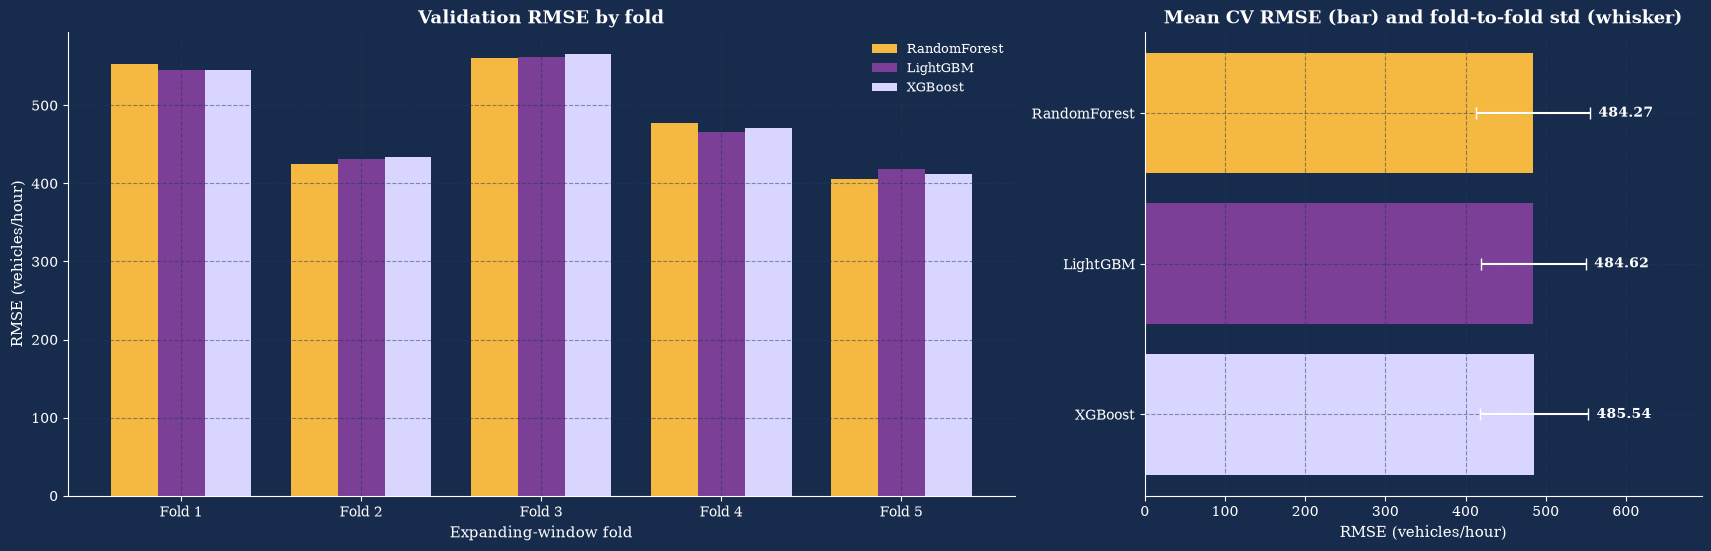

In [184]:

cv = TimeSeriesSplit(n_splits=5)  # The same 5 expanding-window folds used by Optuna in Section 9.2

windows = []
for k, (tr_idx, va_idx) in enumerate(cv.split(X_train), 1):
    windows.append({
        "fold": k,
        "train rows": len(tr_idx),
        "validation rows": len(va_idx),
        "validation start": X_train.index[va_idx[0]].date(),
        "validation end": X_train.index[va_idx[-1]].date(),
    })
display(pd.DataFrame(windows).set_index("fold"))

# Scoring each fold requires 15 additional model fits. Scores are computed and saved once,
# then loaded from the file on subsequent runs.
# The cache is accepted only if each column's mean matches the best Optuna score from Section 9.2
# (to prevent using an outdated file).
cv_path = f"{evalaution_path}/cv_folds.csv"

def _cache_is_valid(table):
    return all(name in table.columns and abs(table[name].mean() - BEST_CV_RMSE[name]) < 1e-3 for name in CANDIDATES)

cv_folds = pd.read_csv(cv_path, index_col=0) if os.path.exists(cv_path) else None
if cv_folds is not None and _cache_is_valid(cv_folds):
    print("Fold scores loaded from the saved file:", cv_path)
else:
    fold_rmse = {}
    for name in CANDIDATES:
        scores = cross_val_score(clone(tuned_pipes[name]), X_train, y_train, cv=cv,
                                 scoring="neg_root_mean_squared_error", n_jobs=-1)
        fold_rmse[name] = -scores
    cv_folds = pd.DataFrame(fold_rmse, index=[f"Fold {k}" for k in range(1, 6)])
    os.makedirs(evalaution_path, exist_ok=True)
    cv_folds.to_csv(cv_path)
    print("Fold scores computed and saved to:", cv_path)
cv_folds = cv_folds[CANDIDATES]

cv_summary = pd.DataFrame({
    "mean CV RMSE": cv_folds.mean(),
    "std across folds": cv_folds.std(),
    "best fold": cv_folds.min(),
    "worst fold": cv_folds.max(),
    "folds won": cv_folds.eq(cv_folds.min(axis=1), axis=0).sum(),
}).sort_values("mean CV RMSE")

print("Cross-validation RMSE for each fold (vehicles per hour):")
display(cv_folds.round(2))
print("\nFold summary:")
display(cv_summary.round(2))

# The mean fold score must match the best Optuna score from Section 9.2
for name in CANDIDATES:
    print(f"{name:13s} Mean CV RMSE here: {cv_folds[name].mean():.4f} | Best Optuna score: {BEST_CV_RMSE[name]:.4f}")

# ---- Selection based only on cross-validation (the test set is not used in this decision) ----
FINAL_MODEL_NAME = cv_summary.index[0]
runner_up = cv_summary.index[1]
gap = cv_summary.loc[runner_up, "mean CV RMSE"] - cv_summary.loc[FINAL_MODEL_NAME, "mean CV RMSE"]
gap_pct = 100 * gap / cv_summary.loc[FINAL_MODEL_NAME, "mean CV RMSE"]
spread = cv_summary.loc[FINAL_MODEL_NAME, "std across folds"]
print(f"\nModel selected by the lowest mean CV RMSE: {FINAL_MODEL_NAME}")
print(f"Gap to runner-up ({runner_up}): {gap:.2f} RMSE units ({gap_pct:.2f}%) | "
      f"Standard deviation of {FINAL_MODEL_NAME} RMSE across folds: {spread:.1f}")

# ---- Fold-by-fold RMSE differences between the selected model and each competitor
# (negative values mean the selected model performs better) ----
paired = pd.DataFrame({f"{FINAL_MODEL_NAME} - {other}": cv_folds[FINAL_MODEL_NAME] - cv_folds[other]
                       for other in CANDIDATES if other != FINAL_MODEL_NAME})
paired_summary = pd.DataFrame({
    "mean difference": paired.mean(),
    "std of difference": paired.std(),
    "folds where the selected model is better": (paired < 0).sum(),
})
print("\nFold-by-fold RMSE differences:")
display(paired.round(2))
display(paired_summary.round(2))

# ---- Plot ----
colors = {"RandomForest": THEME_ACCENT, "LightGBM": THEME_PURPLE, "XGBoost": THEME_LAVENDER}
fig, axes = plt.subplots(1, 2, figsize=(17, 5.4), facecolor=THEME_BG, constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.7, 1]})

x = np.arange(len(cv_folds))
width = 0.26
for j, name in enumerate(CANDIDATES):
    axes[0].bar(x + (j - 1) * width, cv_folds[name], width=width, color=colors[name], label=name)
axes[0].set_xticks(x)
axes[0].set_xticklabels(cv_folds.index)
style_axes(axes[0], title="Validation RMSE by fold", xlabel="Expanding-window fold", ylabel="RMSE (vehicles/hour)")
style_legend(axes[0])

order = cv_summary.index.tolist()
axes[1].barh(order, cv_summary["mean CV RMSE"], xerr=cv_summary["std across folds"],
             color=[colors[n] for n in order], ecolor="white", capsize=4)
axes[1].invert_yaxis()
axes[1].set_xlim(0, (cv_summary["mean CV RMSE"] + cv_summary["std across folds"]).max() * 1.25)
for i, name in enumerate(order):
    axes[1].text(cv_summary.loc[name, "mean CV RMSE"] + cv_summary.loc[name, "std across folds"] + 10, i,
                 f"{cv_summary.loc[name, 'mean CV RMSE']:.2f}", va="center", color="white",
                 fontfamily="serif", fontweight="bold")
style_axes(axes[1], title="Mean CV RMSE (bar) and fold-to-fold std (whisker)", xlabel="RMSE (vehicles/hour)")
plt.show()



<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.1 — Model Comparison</div>

<h4 style="margin:0 0 10px 0;">CV Results and Model Selection</h4>

<ul>
<li>RandomForest achieved the lowest mean CV RMSE (<b>484.27 vehicles/hour</b>), marginally outperforming LightGBM (484.62) and XGBoost (485.54).</li>

<li>RandomForest performed best in <b>3 out of 5 folds</b>; LightGBM and XGBoost each performed best in 1 fold.</li>

<li>The mean CV RMSE improvement was small: approximately <b>0.07% over LightGBM</b> and <b>0.26% over XGBoost</b>. Therefore, RandomForest is selected based on the predefined criterion of the lowest mean CV RMSE, but its advantage should not be overstated.</li>

<li>Test-set results were directionally consistent: RandomForest achieved the lowest test RMSE (<b>463.81</b>) and MAE (<b>263.50</b>), with a test R² of <b>0.9446</b>. Its test RMSE was approximately 0.59% lower than LightGBM's and 0.61% lower than XGBoost's; its MAE was nearly identical to LightGBM's and about 1.10% lower than XGBoost's.</li>

<li><b>Conclusion:</b> RandomForest is the preferred model based on mean cross-validation RMSE. However, the small performance gaps indicate that its superiority over LightGBM and XGBoost is marginal rather than decisive.</li>
</ul>

</div>


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.2 — Naive Baseline: Historical Mean by Weekday × Hour</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 0 0;"><b>Purpose:</b> a model is only worth its complexity if it beats the simplest sensible forecast. The baseline predicts, for every hour of the test period, the average training traffic of the same weekday and hour (168 numbers in total). It uses no weather, no month and no year.</p>
</div>

,R2,RMSE,MAE,WAPE (%),MAPE (%)
Naive baseline (weekday x hour mean),0.9361,497.8237,277.1612,8.3746,11.9817


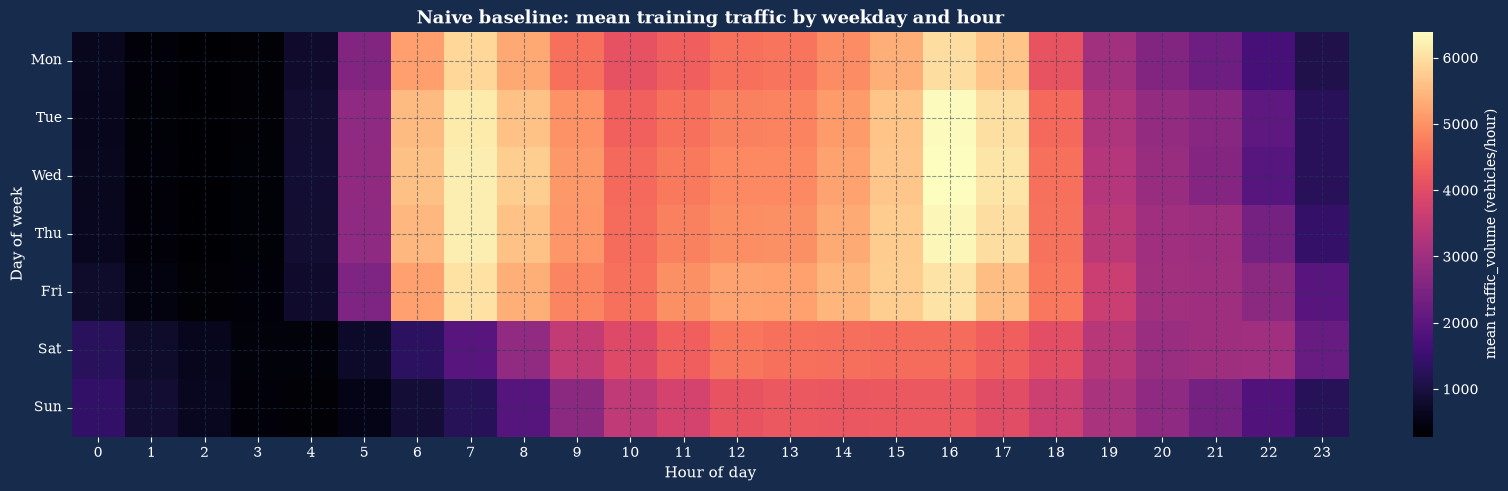

In [174]:
# The baseline is learned on the training part only: for every (day of week, hour) pair the mean traffic.
naive_table = train.groupby(["day_of_week", "hour"])[TARGET].mean()
assert len(naive_table) == 7 * 24, "168 weekday x hour combinations expected"

naive_pred = test.join(naive_table.rename("naive"), on=["day_of_week", "hour"])["naive"]
assert naive_pred.notna().all()

naive_metrics = full_metrics(test[TARGET], naive_pred)
display(pd.DataFrame([naive_metrics], index=["Naive baseline (weekday x hour mean)"]).round(4))

# ---- the 168 numbers behind the baseline ----
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
grid = naive_table.unstack("hour")
grid.index = day_names

fig, ax = plt.subplots(figsize=(15, 4.8), facecolor=THEME_BG, constrained_layout=True)
sns.heatmap(grid, cmap="magma", ax=ax, cbar_kws={"label": "mean traffic_volume (vehicles/hour)"})
style_axes(ax, title="Naive baseline: mean training traffic by weekday and hour",
           xlabel="Hour of day", ylabel="Day of week")
ax.tick_params(axis="y", rotation=0)
ax.figure.axes[-1].yaxis.label.set_color("white")
ax.figure.axes[-1].tick_params(colors="white")
plt.show()

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #cbd5e1; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; font-family:'Segoe UI',sans-serif; color:#1f2937; line-height:1.55;">

**Baseline Comparison**

| Model | R² | RMSE | MAE |
|:--|--:|--:|--:|
| Naive Baseline | 0.9361 | 497.8237 | 277.1612 |
| **Random Forest** | **0.9446** | **463.8105** | **263.4981** |
| LightGBM | 0.9439 | 466.5627 | 263.7058 |
| XGBoost | 0.9439 | 466.6683 | 266.4213 |

- **Best model:** Random Forest achieves the highest R² and lowest RMSE and MAE.

</div>

<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.3 — Final Model and Final Test Report</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

**Purpose:** Random Forest was selected as the final model. This section reports its performance on the training and test sets and interprets prediction error relative to average test-period traffic volume.

</div>

In [190]:
# The tuned models from Section 9.2 were fitted on the training set only and are loaded from disk. No models are refitted here.
# Test predictions were generated in Section 10.0 (tuned_preds).

report_rows = []

for name in CANDIDATES:
    report_rows.append({
        "model": name,
        "mean CV RMSE": BEST_CV_RMSE[name],
        **{f"test {k}": v for k, v in full_metrics(test[TARGET], tuned_preds[name]).items()}
    })

tuned_report = pd.DataFrame(report_rows).set_index("model").loc[CANDIDATES]

print("Tuned models (should match the results in Section 9.2):")
display(tuned_report.round(4))


# The final model was selected through cross-validation in Section 10.1.
final_pipe = tuned_pipes[FINAL_MODEL_NAME]
final_pred = tuned_preds[FINAL_MODEL_NAME]

final_report = pd.DataFrame({
    "train": full_metrics(y_train, final_pipe.predict(X_train)),
    "test": full_metrics(test[TARGET], final_pred),
}).T

final_report.index.name = FINAL_MODEL_NAME

print(
    f"\nFinal model: {FINAL_MODEL_NAME} | "
    f"Number of input features after encoding: "
    f"{len(final_pipe.named_steps['prep'].get_feature_names_out())}"
)
display(final_report.round(4))


mean_test_traffic = test[TARGET].mean()

print(
    f"\nMean traffic during the test period: "
    f"{mean_test_traffic:,.0f} vehicles per hour"
)

print(
    f"Typical prediction error (MAE): "
    f"{final_report.loc['test', 'MAE']:.0f} vehicles per hour = "
    f"{100 * final_report.loc['test', 'MAE'] / mean_test_traffic:.1f}% "
    f"of the mean traffic volume"
)

Tuned models (should match the results in Section 9.2):


,mean CV RMSE,test R2,test RMSE,test MAE,test WAPE (%),test MAPE (%)
model,,,,,,
RandomForest,484.2659,0.9446,463.8105,263.4981,7.9617,12.5800
LightGBM,484.6184,0.9439,466.5627,263.7058,7.9680,13.3677
XGBoost,485.5363,0.9439,466.6683,266.4213,8.0500,13.5670



Final model: RandomForest | Number of input features after encoding: 25


,R2,RMSE,MAE,WAPE (%),MAPE (%)
RandomForest,,,,,
train,0.9618,388.8719,217.4360,6.6172,83.9129
test,0.9446,463.8105,263.4981,7.9617,12.5800



Mean traffic during the test period: 3,310 vehicles per hour
Typical prediction error (MAE): 263 vehicles per hour = 8.0% of the mean traffic volume


In [191]:
# Inspect training rows with the largest absolute percentage errors
train_pred = final_pipe.predict(X_train)

train_error_check = pd.DataFrame({
    "actual": np.asarray(y_train),
    "predicted": train_pred
}, index=X_train.index)

train_error_check["absolute_error"] = (train_error_check["actual"] - train_error_check["predicted"]).abs()
train_error_check["absolute_percentage_error"] = np.where(
    train_error_check["actual"] != 0,
    100 * train_error_check["absolute_error"] / train_error_check["actual"],
    np.nan
)

display(train_error_check.sort_values("absolute_percentage_error", ascending=False).head(10).round(2))

# ---- Low-volume rows (qa_low_volume) in the training and test sets ----
group_stats = train.groupby("qa_low_volume")[TARGET].agg(["size", "min", "median", "mean", "max"])
group_stats.index = ["qa_low_volume = 0", "qa_low_volume = 1"]
display(group_stats.round(2))

low_train = train["qa_low_volume"] == 1
low_hours = train.index[low_train]
print(f"Training low-volume rows: {int(low_train.sum())} rows across {pd.Index(low_hours.date).nunique()} calendar days "
      f"(from {low_hours.min().date()} to {low_hours.max().date()}) | "
      f"{int(((low_hours.hour >= 6) & (low_hours.hour <= 20)).sum())} rows between 06:00 and 20:00")

check_table = pd.DataFrame({
    "train": [int(low_train.sum()), int((train[TARGET] <= 10).sum()), int(train[TARGET].min())],
    "test": [int((test["qa_low_volume"] == 1).sum()), int((test[TARGET] <= 10).sum()), int(test[TARGET].min())],
}, index=["rows with qa_low_volume = 1", "rows with traffic <= 10", "minimum actual traffic"])
display(check_table)

# ---- Contribution of these rows to training MAPE ----
mape_train_all = full_metrics(y_train, train_pred)["MAPE (%)"]
mape_train_without_low = full_metrics(
    y_train[~low_train.to_numpy()],
    train_pred[~low_train.to_numpy()]
)["MAPE (%)"]
mape_test = full_metrics(test[TARGET], final_pred)["MAPE (%)"]

print(f"Training MAPE with all rows: {mape_train_all:.2f}% | "
      f"without {int(low_train.sum())} low-volume rows: {mape_train_without_low:.2f}% | "
      f"Test MAPE: {mape_test:.2f}%")

,actual,predicted,absolute_error,absolute_percentage_error
date_time,,,,
2016-07-23 19:00:00,1,2774.94,2773.94,277393.90
2015-07-25 09:00:00,1,2735.38,2734.38,273438.22
2015-07-25 08:00:00,1,2231.61,2230.61,223060.91
2016-07-23 22:00:00,1,2221.75,2220.75,222074.82
2016-07-09 23:00:00,1,1882.15,1881.15,188114.51
2016-07-23 14:00:00,2,3105.39,3103.39,155169.56
2016-09-07 23:00:00,1,1190.54,1189.54,118953.91
2016-07-23 12:00:00,2,2326.72,2324.72,116235.77
2016-07-23 15:00:00,3,3350.77,3347.77,111592.39


,size,min,median,mean,max
qa_low_volume = 0,32414,100,3422.0,3290.57,7280
qa_low_volume = 1,46,0,5.0,11.37,97


Training low-volume rows: 46 rows across 10 calendar days (from 2015-07-24 to 2016-09-08) | 18 rows between 06:00 and 20:00


,train,test
rows with qa_low_volume = 1,46,0
rows with traffic <= 10,36,0
minimum actual traffic,0,151


Training MAPE with all rows: 83.91% | without 46 low-volume rows: 9.81% | Test MAPE: 12.58%


 <div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.3 — Final Model and Error Analysis</div>

<h4 style="margin:0 0 10px 0;">Model Evaluation and High Training MAPE Investigation</h4>

<ul>
<li><b>Model selection:</b> RandomForest was selected based on cross-validation, achieving the lowest mean CV RMSE (484.27) and the best test RMSE (463.81) among the three tuned models. Its test R² was 0.9446.</li>
<li><b>Test performance:</b> The model's MAE was 263.50 vehicles/hour, equivalent to approximately 8.0% of the mean test traffic volume (3,310 vehicles/hour).</li>
<li><b>High training MAPE:</b> Training MAPE was 83.91%, compared with 12.58% on the test set. The training data contained 46 low-volume observations (<code>qa_low_volume = 1</code>), with traffic ranging from 0 to 97 vehicles/hour.</li>
<li><b>Largest percentage errors:</b> Several training observations had actual traffic of only 1–3 vehicles/hour, while predictions reached thousands of vehicles/hour. Dividing large absolute errors by very small actual values produced extremely high percentage errors.</li>
<li><b>Train–test difference:</b> The training set contained 36 observations with traffic ≤ 10, whereas the test set contained none. Excluding the 46 flagged low-volume training rows reduced training MAPE from 83.91% to 9.81%.</li>
</ul>

<table style="width:100%; border-collapse:collapse; margin:10px 0 14px 0; font-size:13px;">
<thead>
<tr style="background:#dbe4ee;">
<th style="border:1px solid #b8c2cc; padding:8px; text-align:left;">Metric</th>
<th style="border:1px solid #b8c2cc; padding:8px; text-align:right;">Training</th>
<th style="border:1px solid #b8c2cc; padding:8px; text-align:right;">Test</th>
</tr>
</thead>
<tbody>
<tr><td style="border:1px solid #b8c2cc; padding:8px;">R²</td><td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">0.9618</td><td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">0.9446</td></tr>
<tr><td style="border:1px solid #b8c2cc; padding:8px;">RMSE</td><td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">388.87</td><td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">463.81</td></tr>
<tr><td style="border:1px solid #b8c2cc; padding:8px;">MAE</td><td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">217.44</td><td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">263.50</td></tr>
<tr><td style="border:1px solid #b8c2cc; padding:8px;">WAPE (%)</td><td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">6.62</td><td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">7.96</td></tr>
<tr><td style="border:1px solid #b8c2cc; padding:8px;">MAPE (%)</td><td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">83.91</td><td style="border:1px solid #b8c2cc; padding:8px; text-align:right;">12.58</td></tr>
</tbody>
</table>

<p><b>Conclusion:</b> RandomForest demonstrated strong overall test performance. The unusually high training MAPE was strongly influenced by very low actual traffic values. Since these observations were absent from the test set, test MAPE was substantially lower. MAPE should therefore be interpreted cautiously when actual values approach zero; the low-volume records were retained, and the model and test evaluation were left unchanged.</p>

</div> 

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Final test report (RandomForest, trained on 32,460 observations):</b></p>
<ul style="margin:0; padding-left:20px;">
<li style="margin-bottom:4px;">On 8,115 unseen test observations, the model achieved R² <b>0.9446</b>, RMSE <b>463.81</b>, MAE <b>263.50</b> vehicles/hour, WAPE <b>7.96%</b>, and MAPE <b>12.58%</b>.</li>
<li style="margin-bottom:4px;">The test MAE represents approximately <b>8.0%</b> of the mean test traffic volume of 3,310 vehicles/hour.</li>
<li style="margin-bottom:4px;"><b>Metric interpretation:</b> MAPE is sensitive to very small actual traffic values. Training MAPE was <b>83.91%</b>, but decreased to <b>9.81%</b> when the 46 low-volume training observations were excluded. The test set contained no flagged low-volume observations.</li>
<li style="margin-bottom:4px;">Training RMSE was <b>388.87</b> and training R² was <b>0.9618</b>, compared with test RMSE of <b>463.81</b> and test R² of <b>0.9446</b>. This gap suggests some overfitting, but does not by itself establish that it is excessive.</li>
</ul>
</div>

<b>Sanity check of the feature pipeline.</b> <code>build_features</code> rebuilds the 23 model inputs from five raw values (timestamp, temperature, rain, snow, cloud cover) exactly as in section 4, and <code>predict_traffic</code> turns them into a forecast. The check below confirms that 300 random test hours rebuilt this way give <b>identical predictions</b> to the pipeline above.


In [192]:
def build_features(timestamp, temp_c, rain_1h=0.0, snow_1h=0.0, clouds_all=0):
    # 23 ورودی مدل را از پنج مقدار خام می‌سازد، دقیقاً مثل بخش 4 (مهندسی ویژگی).
    ts = pd.Timestamp(timestamp)
    month, dow, hour = ts.month, ts.dayofweek, ts.hour
    season = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}[month]
    row = {
        "rain_1h": rain_1h, "snow_1h": snow_1h, "clouds_all": clouds_all,
        "year": ts.year, "month": month, "hour": hour, "temp_c": temp_c,
        "day_of_week": dow, "is_weekend": int(dow >= 5), "season": season,
        "hour_sin": np.sin(2 * np.pi * hour / 24), "hour_cos": np.cos(2 * np.pi * hour / 24),
        "dow_sin": np.sin(2 * np.pi * dow / 7), "dow_cos": np.cos(2 * np.pi * dow / 7),
        "month_sin": np.sin(2 * np.pi * (month - 1) / 12), "month_cos": np.cos(2 * np.pi * (month - 1) / 12),
        "is_rush_hour": int(dow < 5 and hour in RUSH_HOURS),
        "is_freezing": int(temp_c < 0), "is_raining": int(rain_1h > 0), "is_snowing": int(snow_1h > 0),
        "precipitation_flag": int(rain_1h > 0 or snow_1h > 0),
        "rain_1h_log1p": np.log1p(rain_1h), "snow_1h_log1p": np.log1p(snow_1h),
    }
    return pd.DataFrame([row], index=[ts])[FEATURES]


def predict_traffic(timestamp, temp_c, rain_1h=0.0, snow_1h=0.0, clouds_all=0):
    # پیش‌بینی ترافیک (خودرو در ساعت) برای یک ساعت، فقط از مقدارهای خام
    return float(final_pipe.predict(build_features(timestamp, temp_c, rain_1h, snow_1h, clouds_all))[0])


# ---- بررسی سلامت: 300 ساعت تصادفی آزمون که از مقدارهای خام بازسازی شوند باید دقیقاً همان پیش‌بینی را بدهند ----
sample = test.sample(300, random_state=42)
rebuilt = pd.concat([
    build_features(ts, r.temp_c, r.rain_1h, r.snow_1h, r.clouds_all) for ts, r in sample.iterrows()
])
assert np.allclose(rebuilt[NUM_COLS].astype(float).to_numpy(), sample[NUM_COLS].astype(float).to_numpy())
assert (rebuilt["season"].astype(str).to_numpy() == sample["season"].astype(str).to_numpy()).all()
assert np.allclose(final_pipe.predict(rebuilt), final_pred.loc[sample.index].to_numpy())
print("بررسی سلامت موفق بود: ویژگی‌های بازسازی‌شده از مقدارهای خام برای 300 ساعت آزمون دقیقاً همان پیش‌بینی را می‌دهند.\n")

# ---- سه نمونهٔ پیش‌بینی. هر سه ساعت در دورهٔ آزمون (2017-10-26 تا 2018-09-30) قرار دارند؛
#      اگر آن ساعت در دادهٔ پاک‌شده وجود داشته باشد، مقدار واقعی هم نمایش داده می‌شود. ----
examples = [
    ("Tuesday 17:00, mild and dry", "2018-05-15 17:00", 18.0),
    ("Saturday 12:00, mild and dry", "2018-05-19 12:00", 18.0),
    ("Wednesday 03:00, cold night", "2018-01-17 03:00", -8.0),
]
example_rows = []
for label, stamp, temp in examples:
    ts = pd.Timestamp(stamp)
    actual = float(test.loc[ts, TARGET]) if ts in test.index else np.nan
    example_rows.append({"scenario": label, "timestamp": stamp, "input temp_c": temp,
                         "in test period": ts in test.index,
                         "predicted": round(predict_traffic(stamp, temp)),
                         "actual in data (if present)": actual})
example_table = pd.DataFrame(example_rows).set_index("scenario")
display(example_table)

بررسی سلامت موفق بود: ویژگی‌های بازسازی‌شده از مقدارهای خام برای 300 ساعت آزمون دقیقاً همان پیش‌بینی را می‌دهند.



,timestamp,input temp_c,in test period,predicted,actual in data (if present)
scenario,,,,,
"Tuesday 17:00, mild and dry",2018-05-15 17:00,18.0,True,6177,6548.0
"Saturday 12:00, mild and dry",2018-05-19 12:00,18.0,True,4731,4259.0
"Wednesday 03:00, cold night",2018-01-17 03:00,-8.0,True,403,346.0



<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<h3 style="margin:0 0 10px 0; color:#1e3a5f;">Feature Pipeline Sanity Check</h3>

<p><b>Purpose:</b> Validate feature reconstruction and prediction consistency in the final pipeline.</p>

<ul>
<li>Reconstructed features and predictions matched the original results within numerical tolerance for 300 randomly sampled test observations.</li>
<li><b>Example forecasts:</b> Three scenarios were selected to illustrate different traffic conditions: weekday rush hour (Tuesday, 17:00 — 6,177), weekend midday (Saturday, 12:00 — 4,731), and a cold night (Wednesday, 03:00 — 403 vehicles/hour). Actual traffic values were available for comparison in the test data.</li>
<li><b>Validation scope: Successful.</b> The sanity check confirmed consistency between feature reconstruction and model predictions. The example forecasts provide illustrative comparisons, not an independent assessment of overall model accuracy.</li>
</ul>

</div>


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.4 — Final Comparison of All Models</h3></div>

,R2,RMSE,MAE,WAPE (%),MAPE (%),RMSE vs naive baseline (%)
Random Forest tuned with Optuna (9),0.945,463.811,263.498,7.962,12.580,-6.832
LightGBM tuned with Optuna (9),0.944,466.563,263.706,7.968,13.368,-6.280
XGBoost tuned with Optuna (9),0.944,466.668,266.421,8.050,13.567,-6.258
LightGBM baseline (8),0.943,470.897,269.214,8.134,13.038,-5.409
XGBoost baseline (8),0.942,475.451,273.783,8.272,12.753,-4.494
Random Forest tuned by CV (7),0.942,476.296,270.062,8.160,12.337,-4.324
Random Forest baseline (7),0.937,493.966,286.556,8.658,13.047,-0.775
Naive baseline (weekday x hour mean),0.936,497.824,277.161,8.375,11.982,0.000
Linear regression V4 (5),0.906,603.882,425.975,12.871,23.751,21.304
Linear regression A (5),0.857,744.872,559.248,16.898,37.362,49.626



Final model vs. Naive baseline (weekday x hour mean)    : RMSE   6.8% lower | MAE   4.9% lower
Final model vs. Linear regression A (5)                 : RMSE  37.7% lower | MAE  52.9% lower
Final model vs. Linear regression V4 (5)                : RMSE  23.2% lower | MAE  38.1% lower


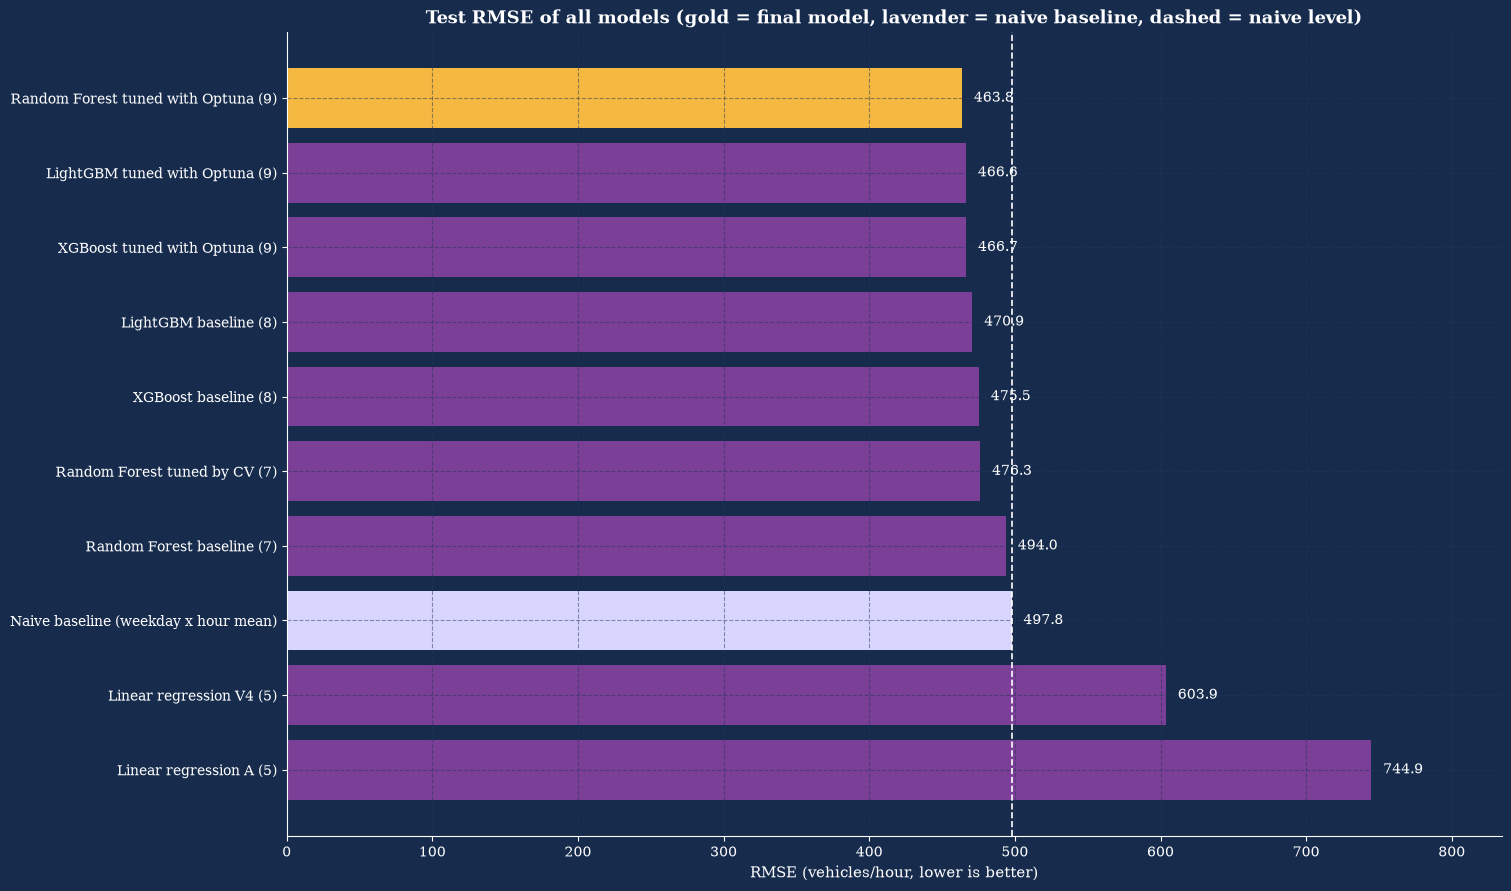

In [195]:

# All notebook models are evaluated on the same test period using the same five metrics.
# Predictions from earlier models are retrieved from memory. If the session has been restarted,
# they are loaded from the file saved after Section 9.2.
legacy_names = ["res_a", "res_v4", "res_rf_base", "res_rf_tuned", "xgb_baseline", "lgbm_baseline"]
if all(name in globals() for name in legacy_names):
    legacy = pd.DataFrame({
        "Linear regression A (5)": np.asarray(res_a["yhat_te"]),
        "Linear regression V4 (5)": np.asarray(res_v4["yhat_te"]),
        "Random Forest baseline (7)": np.asarray(res_rf_base["yhat_te"]),
        "Random Forest tuned by CV (7)": np.asarray(res_rf_tuned["yhat_te"]),
        "XGBoost baseline (8)": np.asarray(xgb_baseline["predictions"]),
        "LightGBM baseline (8)": np.asarray(lgbm_baseline["predictions"]),
    }, index=test.index)
else:
    legacy = pd.read_csv(f"{evalaution_path}/legacy_predictions.csv", index_col=0, parse_dates=True)
    assert legacy.index.equals(test.index), "legacy_predictions.csv does not match the current test period"

all_preds = {
    "Naive baseline (weekday x hour mean)": naive_pred,
    "Linear regression A (5)": legacy["Linear regression A (5)"],
    "Linear regression V4 (5)": legacy["Linear regression V4 (5)"],
    "Random Forest baseline (7)": legacy["Random Forest baseline (7)"],
    "Random Forest tuned by CV (7)": legacy["Random Forest tuned by CV (7)"],
    "XGBoost baseline (8)": legacy["XGBoost baseline (8)"],
    "LightGBM baseline (8)": legacy["LightGBM baseline (8)"],
    "XGBoost tuned with Optuna (9)": tuned_preds["XGBoost"],
    "LightGBM tuned with Optuna (9)": tuned_preds["LightGBM"],
    "Random Forest tuned with Optuna (9)": tuned_preds["RandomForest"],
}

final_label = {"RandomForest": "Random Forest", "LightGBM": "LightGBM", "XGBoost": "XGBoost"}[FINAL_MODEL_NAME] + " tuned with Optuna (9)"
naive_label = "Naive baseline (weekday x hour mean)"

final_comparison_table = pd.DataFrame(
    {label: full_metrics(test[TARGET], pred) for label, pred in all_preds.items()}
).T
final_comparison_table["RMSE vs naive baseline (%)"] = (
    100 * (final_comparison_table["RMSE"] / final_comparison_table.loc[naive_label, "RMSE"] - 1)
)
final_comparison_table = final_comparison_table.sort_values("RMSE")
display(final_comparison_table.round(3))

best_rmse = final_comparison_table.loc[final_label, "RMSE"]
best_mae = final_comparison_table.loc[final_label, "MAE"]
print()
for ref in [naive_label, "Linear regression A (5)", "Linear regression V4 (5)"]:
    print(f"Final model vs. {ref:40s}: RMSE {100 * (1 - best_rmse / final_comparison_table.loc[ref, 'RMSE']):5.1f}% lower | "
          f"MAE {100 * (1 - best_mae / final_comparison_table.loc[ref, 'MAE']):5.1f}% lower")

# ---- Plot ----
plot_table = final_comparison_table.sort_values("RMSE", ascending=False)
bar_colors = [THEME_ACCENT if label == final_label else THEME_LAVENDER if label == naive_label else THEME_PURPLE
              for label in plot_table.index]

fig, ax = plt.subplots(figsize=(15, 0.62 * len(plot_table) + 2.6), facecolor=THEME_BG, constrained_layout=True)
ax.barh(plot_table.index, plot_table["RMSE"], color=bar_colors)
ax.axvline(final_comparison_table.loc[naive_label, "RMSE"], color="white", linestyle="--", lw=1.2)
for i, value in enumerate(plot_table["RMSE"]):
    ax.text(value + 8, i, f"{value:.1f}", va="center", color="white", fontfamily="serif")
ax.set_xlim(0, plot_table["RMSE"].max() * 1.12)
style_axes(ax, title="Test RMSE of all models (gold = final model, lavender = naive baseline, dashed = naive level)",
           xlabel="RMSE (vehicles/hour, lower is better)", title_size=13)
plt.show()



<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<h3 style="margin:0 0 10px 0; color:#1e3a5f;">Final Model Comparison and Selection</h3>

<p><b>Purpose:</b> Compare all models on the same test set using five evaluation metrics and select the best-performing model.</p>

<ul>
<li style="font-weight:bold; color:#d4a000;">
Best model: Random Forest tuned with Optuna achieved the lowest RMSE (463.811) and MAE (263.498), with R² = 0.945 and WAPE = 7.962%.
</li>
<li><b>Comparison:</b> The final model reduced RMSE by 6.83% compared with the naive baseline. Tuned LightGBM and XGBoost achieved similar results.</li>
<li><b>Validation scope: Successful.</b> The final model performed best by RMSE and MAE on the test set. However, its MAPE (12.580%) was slightly higher than the naive baseline (11.982%), so model selection should consider multiple metrics.</li>
</ul>

</div>


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.5 — SHAP: What Drives the Predictions</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>What SHAP does:</b> for every single prediction it splits the forecast into contributions, one per feature, measured in vehicles per hour. The contributions plus the average prediction (the base value) add up exactly to the forecast of that hour. This goes beyond the permutation importance of 7.4 and 8.5: it also shows the <b>direction</b> of each effect and explains <b>individual hours</b>.</p>
<p style="margin:0 0 0 0;"><b>How it is computed here:</b> <code>TreeExplainer</code> on the final model, using a random sample of 1,500 test hours (all 8,115 would be slow). The first run may take a few minutes. <code>hour</code>, <code>hour_sin</code>, <code>hour_cos</code> and <code>is_rush_hour</code> describe the same thing and share their credit, so the contributions are also summed by feature family.</p>
</div>

In [197]:

if shap is None:
    raise ImportError("The SHAP package is required for section 10.5: pip install shap")

# Feature groups (same groups used in permutation analysis, section 7.4)
RF_FEATURE_GROUPS = {
    "Hour and commute": ["hour", "hour_sin", "hour_cos", "is_rush_hour"],
    "Weekday and weekend": ["day_of_week", "dow_sin", "dow_cos", "is_weekend"],
    "Month and season": ["month", "month_sin", "month_cos", "season"],
    "Long-term year": ["year"],
    "Temperature and freezing": ["temp_c", "is_freezing"],
    "Precipitation": ["rain_1h", "snow_1h", "is_raining", "is_snowing",
                      "precipitation_flag", "rain_1h_log1p", "snow_1h_log1p"],
    "Cloud cover": ["clouds_all"],
}
assert sorted(c for cols in RF_FEATURE_GROUPS.values() for c in cols) == sorted(FEATURES), \
    "The groups must cover every input feature exactly once."

prep = final_pipe.named_steps["prep"]
model = final_pipe.named_steps["model"]
encoded_names = list(prep.get_feature_names_out())

X_test_encoded = pd.DataFrame(
    prep.transform(test[FEATURES]),
    columns=encoded_names,
    index=test.index
)

# Compute SHAP values on a random sample of test hours (running on all 8,115 rows is slow)
rng = np.random.default_rng(42)
sample_pos = np.sort(
    rng.choice(len(X_test_encoded), size=min(1500, len(X_test_encoded)), replace=False)
)
X_shap = X_test_encoded.iloc[sample_pos]

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_shap, check_additivity=False)
base_value = float(np.ravel(explainer.expected_value)[0])

# The base value plus the sum of SHAP values should match the model prediction
reconstructed = base_value + shap_values.sum(axis=1)
model_pred = model.predict(X_shap)

print(
    f"SHAP values calculated for {len(X_shap):,} test hours | "
    f"Base value (mean prediction): {base_value:,.0f} vehicles/hour"
)
print(
    f"Maximum difference between (base value + sum of SHAP values) "
    f"and model predictions: {np.abs(reconstructed - model_pred).max():.4f} vehicles/hour"
)

# ---- Individual feature importance ----
mean_abs_shap = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=encoded_names
).sort_values(ascending=False)


def family_of(encoded_name):
    for family, members in RF_FEATURE_GROUPS.items():
        if encoded_name in members or (
            encoded_name.startswith("season_") and "season" in members
        ):
            return family
    raise KeyError(encoded_name)


feature_family = pd.Series({
    name: family_of(name) for name in encoded_names
})

# ---- Feature family importance ----
# Primary metric: sum of the mean absolute SHAP values of the group's features
# (the same method used earlier in the notebook).
# Secondary comparison metric: sum each group's feature contributions per hour,
# then calculate the mean absolute value. This also accounts for cancellation
# between positive and negative contributions within the same feature group.
family_shap = pd.DataFrame(
    {
        family: shap_values[:, (feature_family == family).to_numpy()].sum(axis=1)
        for family in RF_FEATURE_GROUPS
    },
    index=X_shap.index,
)

assert np.allclose(family_shap.sum(axis=1), shap_values.sum(axis=1)), \
    "The sum of feature family contributions must equal the sum of individual feature contributions."

family_importance = mean_abs_shap.groupby(feature_family).sum().sort_values(ascending=False)  # Primary metric
family_importance_summed_first = family_shap.abs().mean()  # Secondary metric


def dark_shap_figure(fig, title=None):
    # Apply the notebook's dark theme to a figure created by the SHAP library.
    fig.patch.set_facecolor(THEME_BG)
    for ax in fig.axes:
        ax.set_facecolor(THEME_BG)
        ax.tick_params(colors="white", labelsize=10)
        ax.xaxis.label.set_color("white")
        ax.yaxis.label.set_color("white")
        ax.title.set_color("white")
        for spine in ax.spines.values():
            spine.set_color("white")
        for text in ax.texts:
            text.set_color("white")
    if title:
        fig.suptitle(
            title,
            color="white",
            fontsize=14,
            fontweight="bold",
            fontfamily="serif"
        )
    return fig


SHAP values calculated for 1,500 test hours | Base value (mean prediction): 3,286 vehicles/hour
Maximum difference between (base value + sum of SHAP values) and model predictions: 0.0000 vehicles/hour


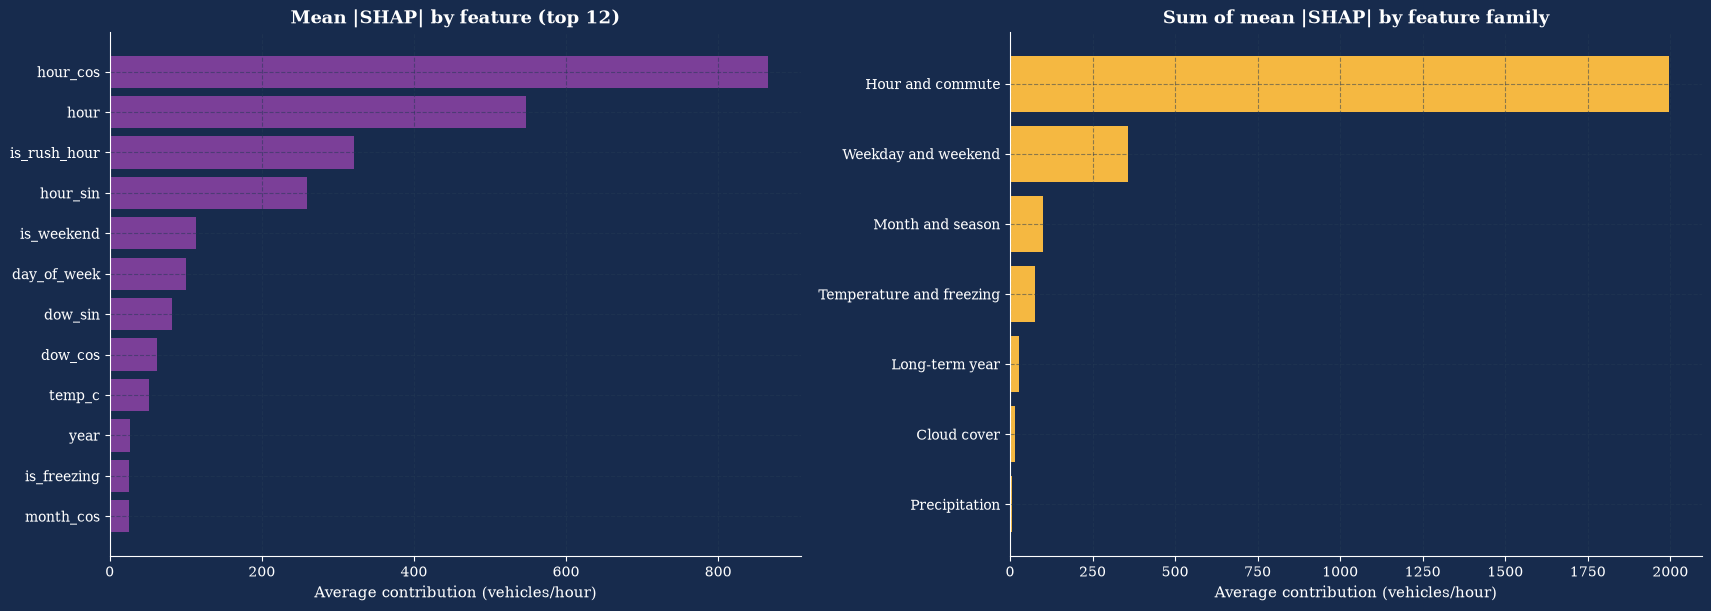

In [198]:
# ---- 1) Global importance: individual features and feature families ----
fig, axes = plt.subplots(1, 2, figsize=(17, 6), facecolor=THEME_BG, constrained_layout=True)

top = mean_abs_shap.head(12).sort_values()
axes[0].barh(top.index, top.values, color=THEME_PURPLE)
style_axes(axes[0], title="Mean |SHAP| by feature (top 12)", xlabel="Average contribution (vehicles/hour)")

fam = family_importance.sort_values()
axes[1].barh(fam.index, fam.values, color=THEME_ACCENT)
style_axes(axes[1], title="Sum of mean |SHAP| by feature family", xlabel="Average contribution (vehicles/hour)")
plt.show()

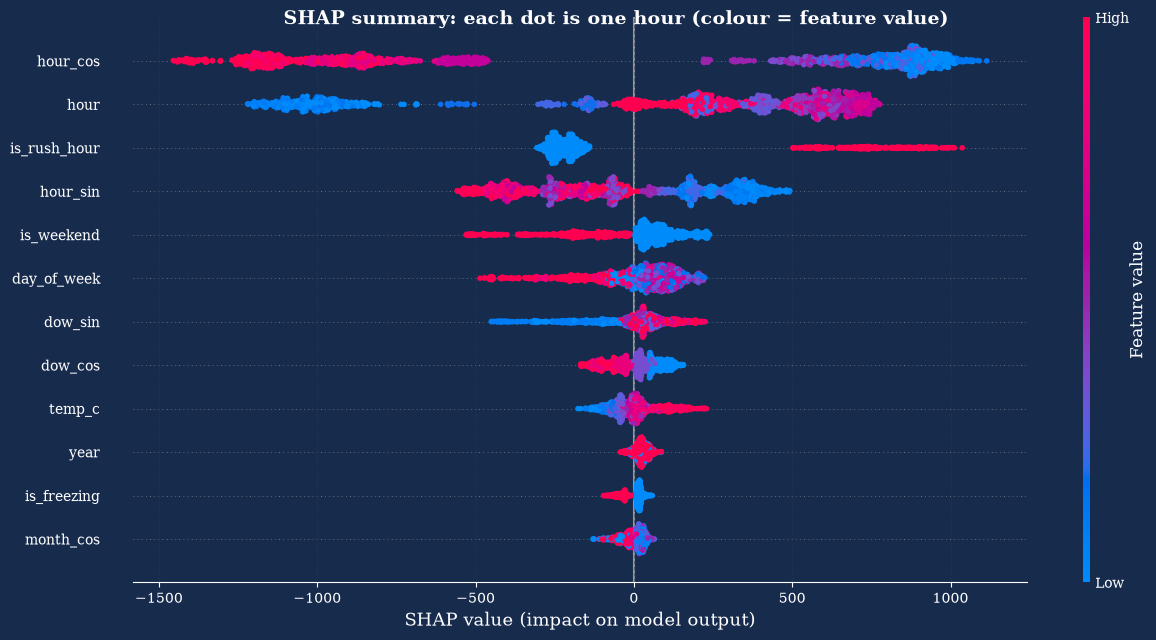

In [199]:
# ---- 2) SHAP beeswarm plot: feature effect direction ----
shap.summary_plot(shap_values, X_shap, max_display=12, show=False, plot_size=(13, 6.5))
dark_shap_figure(plt.gcf(), "SHAP summary: each dot is one hour (colour = feature value)")
plt.show()

In [200]:
# ---- Individual feature importance table ----
feature_shap_table = pd.DataFrame({
    "Feature": mean_abs_shap.index,
    "Feature family": feature_family[mean_abs_shap.index].to_numpy(),
    "Mean absolute SHAP (vehicles/hour)": mean_abs_shap.to_numpy(),
})
feature_shap_table["Share of total (%)"] = (
    100 * feature_shap_table["Mean absolute SHAP (vehicles/hour)"]
    / feature_shap_table["Mean absolute SHAP (vehicles/hour)"].sum()
)
feature_shap_table.index = feature_shap_table.index + 1
display(feature_shap_table.round(2))

# ---- Feature family importance table ----
family_shap_table = pd.DataFrame({
    "Feature family": family_importance.index,
    "Sum of mean |SHAP| (vehicles/hour)": family_importance.to_numpy(),
    "Share of total (%)": 100 * family_importance.to_numpy() / family_importance.sum(),
    "Mean |sum of member SHAP| (for comparison)": family_importance_summed_first[family_importance.index].to_numpy(),
})
family_shap_table.index = family_shap_table.index + 1
display(family_shap_table.round(2))

,Feature,Feature family,Mean absolute SHAP (vehicles/hour),Share of total (%)
1,hour_cos,Hour and commute,866.05,33.62
2,hour,Hour and commute,547.86,21.27
3,is_rush_hour,Hour and commute,321.28,12.47
4,hour_sin,Hour and commute,259.90,10.09
5,is_weekend,Weekday and weekend,113.72,4.41
6,day_of_week,Weekday and weekend,100.10,3.89
7,dow_sin,Weekday and weekend,82.23,3.19
8,dow_cos,Weekday and weekend,62.44,2.42
9,temp_c,Temperature and freezing,51.56,2.00
10,year,Long-term year,26.95,1.05


,Feature family,Sum of mean |SHAP| (vehicles/hour),Share of total (%),Mean |sum of member SHAP| (for comparison)
1,Hour and commute,1995.09,77.45,1581.26
2,Weekday and weekend,358.49,13.92,323.79
3,Month and season,98.63,3.83,80.30
4,Temperature and freezing,76.72,2.98,72.11
5,Long-term year,26.95,1.05,26.95
6,Cloud cover,14.76,0.57,14.76
7,Precipitation,5.44,0.21,5.44



<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.5 — SHAP Analysis</div>

SHAP analysis shows that **time-of-day and commuting patterns dominate the model's predictions**, accounting for **77.45%** of the grouped mean absolute SHAP importance, followed by weekday/weekend patterns at **13.92%**.

Weather-related features have a relatively small contribution to overall importance: temperature and freezing account for **2.98%**, cloud cover for **0.57%**, and precipitation for **0.21%**. Overall, the results indicate that **temporal patterns are the main drivers of the model's predictions**, while weather-related features contribute comparatively less.

</div>


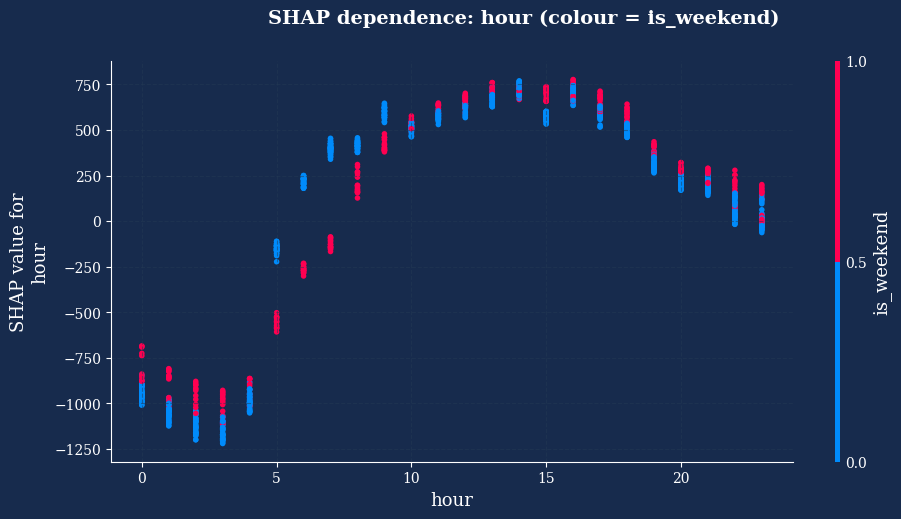

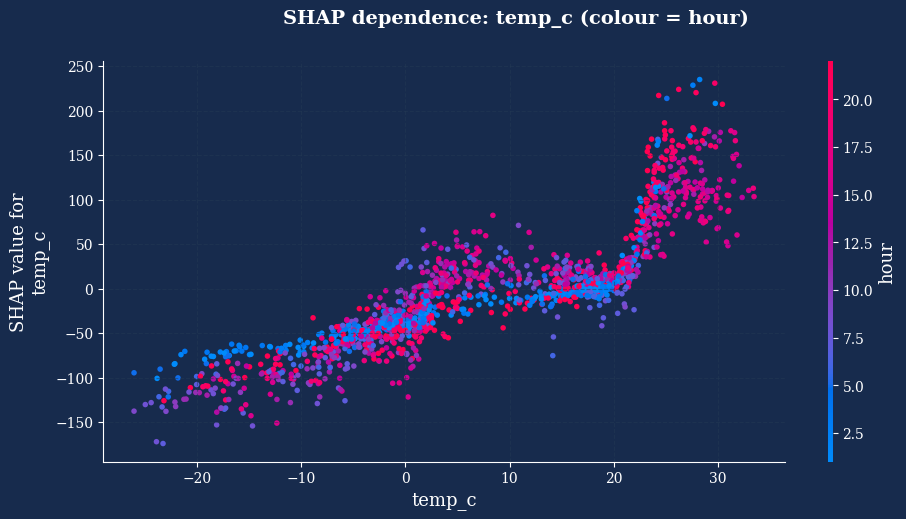

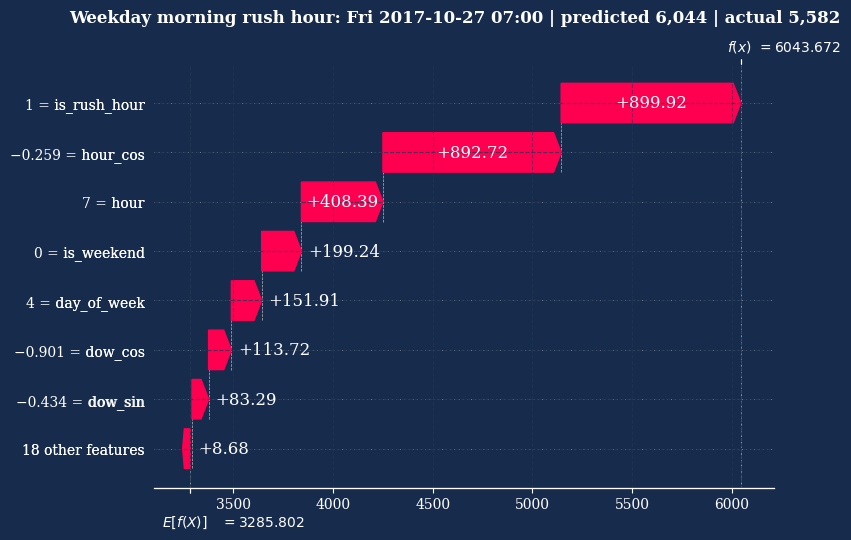

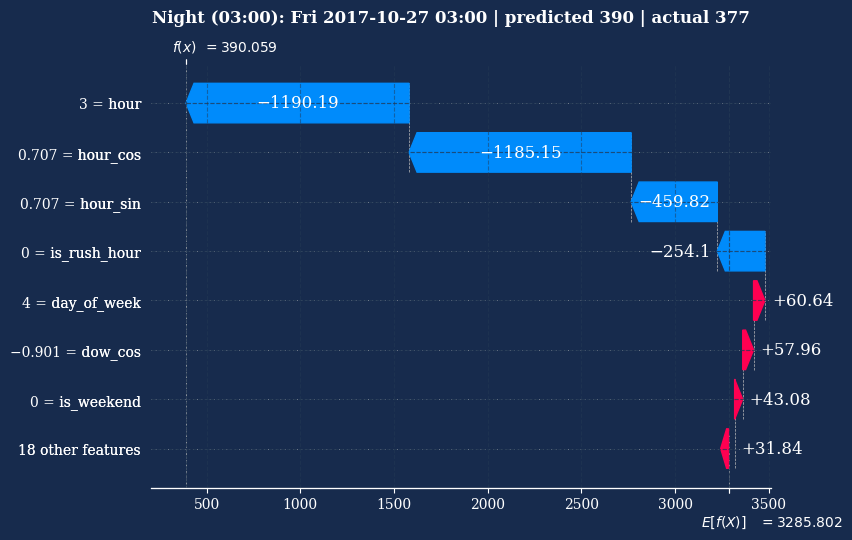

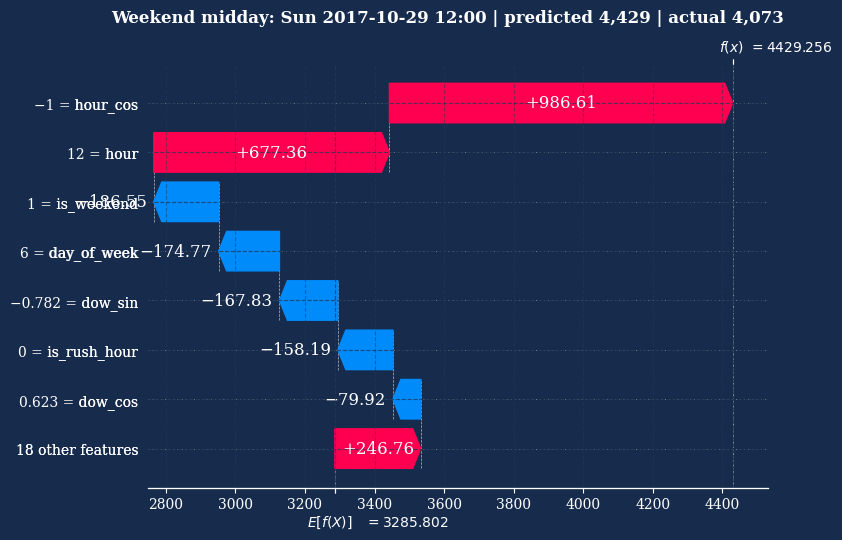

In [ ]:
# ---- 3) dependence plots: how the contribution of one feature changes with its value ----
for feature, colour_by in [("hour", "is_weekend"), ("temp_c", "hour")]:
    shap.dependence_plot(feature, shap_values, X_shap, interaction_index=colour_by, show=False)
    dark_shap_figure(plt.gcf(), f"SHAP dependence: {feature} (colour = {colour_by})")
    plt.gcf().set_size_inches(11, 5.2)
    plt.show()

# ---- 4) three single hours explained one by one ----
def first_position(mask):
    return int(np.flatnonzero(mask)[0])

picked = {
    "Weekday morning rush hour": first_position((X_shap["is_weekend"] == 0) & (X_shap["hour"] == 7)),
    "Night (03:00)": first_position(X_shap["hour"] == 3),
    "Weekend midday": first_position((X_shap["is_weekend"] == 1) & (X_shap["hour"] == 12)),
}

for label, pos in picked.items():
    explanation = shap.Explanation(values=shap_values[pos], base_values=base_value,
                                   data=X_shap.iloc[pos].to_numpy(), feature_names=encoded_names)
    shap.plots.waterfall(explanation, max_display=8, show=False)
    dark_shap_figure(plt.gcf())
    actual = test.loc[X_shap.index[pos], TARGET]
    plt.gcf().suptitle(f"{label}: {X_shap.index[pos]:%a %Y-%m-%d %H:%M} | predicted {model_pred[pos]:,.0f} | actual {actual:,.0f}",
                       color="white", fontsize=12, fontweight="bold", fontfamily="serif")
    plt.show()

In [201]:
# ---- Numerical interpretation of dependence plots (mean contributions across the 1,500-hour sample) ----

# 1) Hour and commute family contribution by hour and day type
hour_effect = (
    family_shap["Hour and commute"]
    .groupby([
        X_shap["hour"].astype(int),
        X_shap["is_weekend"].astype(int)
    ])
    .mean()
    .unstack("is_weekend")
    .rename(columns={0: "weekday", 1: "weekend"})
)
hour_effect.index.name = "hour"
display(hour_effect.round(0).T)

# 2) Temperature family contribution by temperature range
temp_bins = pd.cut(
    test.loc[X_shap.index, "temp_c"],
    [-np.inf, 0, 10, 20, 25, np.inf],
    right=False,
    labels=["< 0 C", "0 to 10 C", "10 to 20 C", "20 to 25 C", ">= 25 C"]
)
temp_effect = (
    family_shap["Temperature and freezing"]
    .groupby(temp_bins, observed=True)
    .agg(hours="size", mean_shap="mean")
)
display(temp_effect.round(1))

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
is_weekend,,,,,,,,,,,,,,,,,,,,,
weekday,-2621.0,-2905.0,-3007.0,-2995.0,-2601.0,-980.0,1588.0,2179.0,1826.0,1244.0,...,1583.0,2049.0,2558.0,2267.0,935.0,-123.0,-542.0,-672.0,-1152.0,-1901.0
weekend,-1919.0,-2232.0,-2407.0,-2521.0,-2365.0,-1662.0,-814.0,-432.0,98.0,707.0,...,1590.0,1551.0,1563.0,1374.0,1073.0,175.0,-180.0,-367.0,-657.0,-1361.0


,hours,mean_shap
temp_c,,
< 0 C,494,-107.0
0 to 10 C,312,8.9
10 to 20 C,316,19.3
20 to 25 C,230,74.7
>= 25 C,148,145.3



<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-right:5px solid #1e3a5f; border-radius:8px; padding:14px 18px 14px 24px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Vazirmatn','Tahoma','Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.9; overflow-wrap:break-word;">

<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.5 — Interpreting SHAP Plots</div>

<ul style="margin:0 0 8px 0; padding-left:22px; padding-right:0;">
<li style="margin-bottom:6px;"><b>Beeswarm and dependence plots:</b> Rush-hour, weekend, hour, and temperature features show different contributions depending on their values and interactions.</li>
<li style="margin-bottom:6px;"><b>Waterfall plots:</b> Explain individual predictions for a weekday commute hour, 03:00, and a weekend midday hour, comparing predicted and actual traffic.</li>
</ul>

<div style="font-weight:700; color:#1f2937; background:#ffeb7a; padding:5px 8px; border-radius:4px; margin:8px 0;">Key finding: Temporal patterns dominate the model's predictions, consistent with the permutation analysis in Section 7.4 and feature analysis in Section 8.5.</div>

<p style="margin:0;">The ranking of less influential feature groups differs across sections because the analyses use different models and methods; these differences do not change the main conclusion.</p>

</div>


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.6 — Error Analysis</h3></div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">
<p style="margin:0 0 8px 0;"><b>Method:</b> every test hour gets one row with the actual value, the prediction and the error (<code>residual = actual − prediction</code>, so a negative value means the model predicted too much). The errors are then grouped by hour, weekday, season, month, <b>federal holiday</b>, <b>weather group</b> and traffic level, and the 20 largest errors are listed.</p>
<p style="margin:0 0 0 0;"><b>Important:</b> holiday and weather information is attached <b>only to group the errors</b>. It is not a model input, so the question answered here is: how much does the model lose by not knowing about holidays and weather?</p>
</div>

Test hours: 8,115 | Holiday hours: 216 across 9 days | qa_low_volume hours during the test period: 0
Overall: MAE 263.5 | RMSE 463.8 | Bias -10.6


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
hour,,,,,,
0,339,831.8,130.5,180.9,-60.6,15.7
1,339,506.0,89.9,127.7,-54.0,17.8
2,325,379.3,82.8,110.1,-61.8,21.8
3,336,373.1,53.7,76.3,-41.2,14.4
4,338,726.5,72.5,108.4,-11.4,10.0
5,338,2184.0,221.8,353.5,65.4,10.2
6,338,4119.2,328.6,682.5,-62.0,8.0
7,337,4723.5,455.3,801.6,-5.8,9.6
8,338,4556.1,417.9,721.1,-80.5,9.2


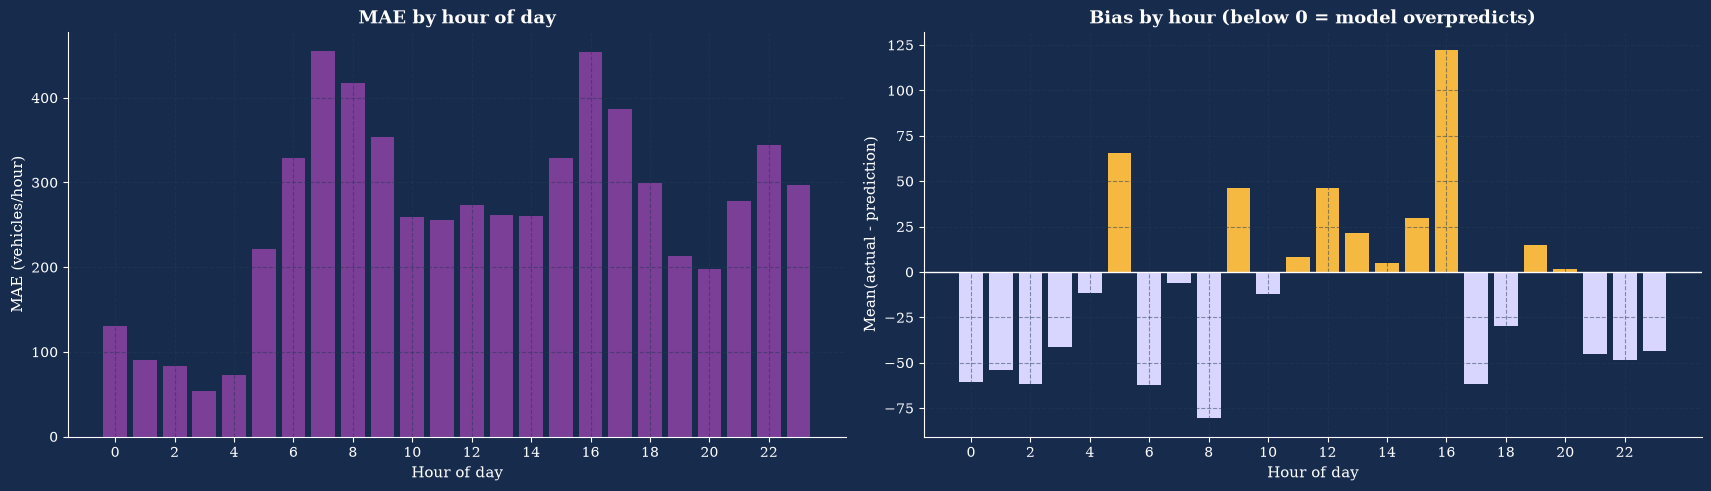

In [203]:

# For each test hour, store the actual value, model prediction, and error,
# along with contextual columns used only for error grouping.
# Holiday information and weather conditions are not model inputs;
# they are added here only to investigate where the model makes mistakes.
err = pd.DataFrame({"actual": test[TARGET], "prediction": final_pred})
err["residual"] = err["actual"] - err["prediction"]  # Positive = the model underpredicts
err["abs_error"] = err["residual"].abs()
err["hour"] = test["hour"]
err["day_of_week"] = test["day_of_week"]
err["is_weekend"] = test["is_weekend"]
err["season"] = test["season"]

if "weather_group" in df.columns:
    err["weather_group"] = df.loc[test.index, "weather_group"]  # Groups from Section 6
else:
    err["weather_group"] = pd.read_csv(
        f"{evalaution_path}/weather_group.csv",
        index_col=0,
        parse_dates=True
    )["weather_group"].reindex(test.index)

assert err["weather_group"].notna().all(), \
    "Weather groups must be available for every test hour."

err["qa_low_volume"] = test["qa_low_volume"]

holiday_names = USFederalHolidayCalendar().holidays(
    test.index.min().normalize(),
    test.index.max().normalize(),
    return_name=True
)
err["holiday"] = err.index.normalize().map(holiday_names).fillna("Not holiday")
err["is_holiday"] = err["holiday"] != "Not holiday"

DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


def error_table(frame, by):
    # Summarize errors by group.
    # residual = actual - prediction, so bias < 0 means the model overpredicts.
    grouped = frame.groupby(by, observed=True)
    table = grouped.agg(
        hours=("actual", "size"),
        mean_traffic=("actual", "mean"),
        MAE=("abs_error", "mean"),
        bias=("residual", "mean")
    )
    table["RMSE"] = grouped["residual"].apply(lambda r: np.sqrt((r ** 2).mean()))
    table["WAPE (%)"] = 100 * grouped["abs_error"].sum() / grouped["actual"].sum()
    return table[["hours", "mean_traffic", "MAE", "RMSE", "bias", "WAPE (%)"]].round(1)


print(
    f"Test hours: {len(err):,} | "
    f"Holiday hours: {int(err.is_holiday.sum())} across "
    f"{err.index[err.is_holiday].normalize().nunique()} days | "
    f"qa_low_volume hours during the test period: {int(err.qa_low_volume.sum())}"
)
print(
    f"Overall: MAE {err.abs_error.mean():.1f} | "
    f"RMSE {np.sqrt((err.residual ** 2).mean()):.1f} | "
    f"Bias {err.residual.mean():.1f}"
)

# ---- 1) Error analysis by hour of day ----
by_hour = error_table(err, "hour")
display(by_hour)

fig, axes = plt.subplots(
    1, 2, figsize=(17, 4.8), facecolor=THEME_BG, constrained_layout=True
)
axes[0].bar(by_hour.index, by_hour["MAE"], color=THEME_PURPLE)
style_axes(
    axes[0],
    title="MAE by hour of day",
    xlabel="Hour of day",
    ylabel="MAE (vehicles/hour)"
)
axes[1].bar(
    by_hour.index,
    by_hour["bias"],
    color=np.where(by_hour["bias"] >= 0, THEME_ACCENT, THEME_LAVENDER)
)
axes[1].axhline(0, color="white", lw=1)
style_axes(
    axes[1],
    title="Bias by hour (below 0 = model overpredicts)",
    xlabel="Hour of day",
    ylabel="Mean(actual - prediction)"
)
for ax in axes:
    ax.set_xticks(range(0, 24, 2))
plt.show()



<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.6 — Error Analysis by Hour</div>

The model achieved an overall **MAE of 263.5**, **RMSE of 463.8**, and **bias of −10.6 vehicles/hour**. Absolute errors were highest during morning and afternoon traffic peaks, while relative errors were greatest during low-traffic nighttime hours, reaching **21.8% WAPE at 02:00**.

</div>


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
day,,,,,,
Mon,1152,3269.7,356.4,678.9,-78.8,10.9
Tue,1146,3525.7,240.3,390.0,-11.8,6.8
Wed,1149,3630.3,214.5,427.5,17.3,5.9
Thu,1153,3683.8,251.5,453.5,-9.5,6.8
Fri,1175,3731.9,221.9,356.8,39.3,5.9
Sat,1165,2895.2,304.4,488.1,-4.9,10.5
Sun,1175,2445.4,255.8,376.1,-26.8,10.5


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
day_type,,,,,,
Weekday,5775,3569.0,256.8,474.8,-8.5,7.2
Weekend,2340,2669.4,280.0,435.5,-15.9,10.5


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
season,,,,,,
Winter,2154,3163.0,327.6,537.9,-3.4,10.4
Spring,2196,3380.1,261.8,476.2,-62.6,7.7
Summer,2203,3369.8,195.7,341.6,-3.8,5.8
Fall,1562,3327.6,273.1,485.1,42.9,8.2


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
month_label,,,,,,
2017-10,126,3313.7,236.9,349.6,100.7,7.2
2017-11,716,3368.5,336.6,587.2,114.0,10.0
2017-12,740,3125.3,374.2,582.8,39.7,12.0
2018-01,742,3111.8,344.6,595.5,-39.2,11.1
2018-02,672,3261.2,257.6,402.1,-11.1,7.9
2018-03,733,3446.9,217.2,387.9,-24.7,6.3
2018-04,720,3297.2,322.5,583.5,-104.7,9.8
2018-05,743,3394.5,246.9,437.8,-59.4,7.3
2018-06,719,3422.5,181.1,250.4,-7.0,5.3


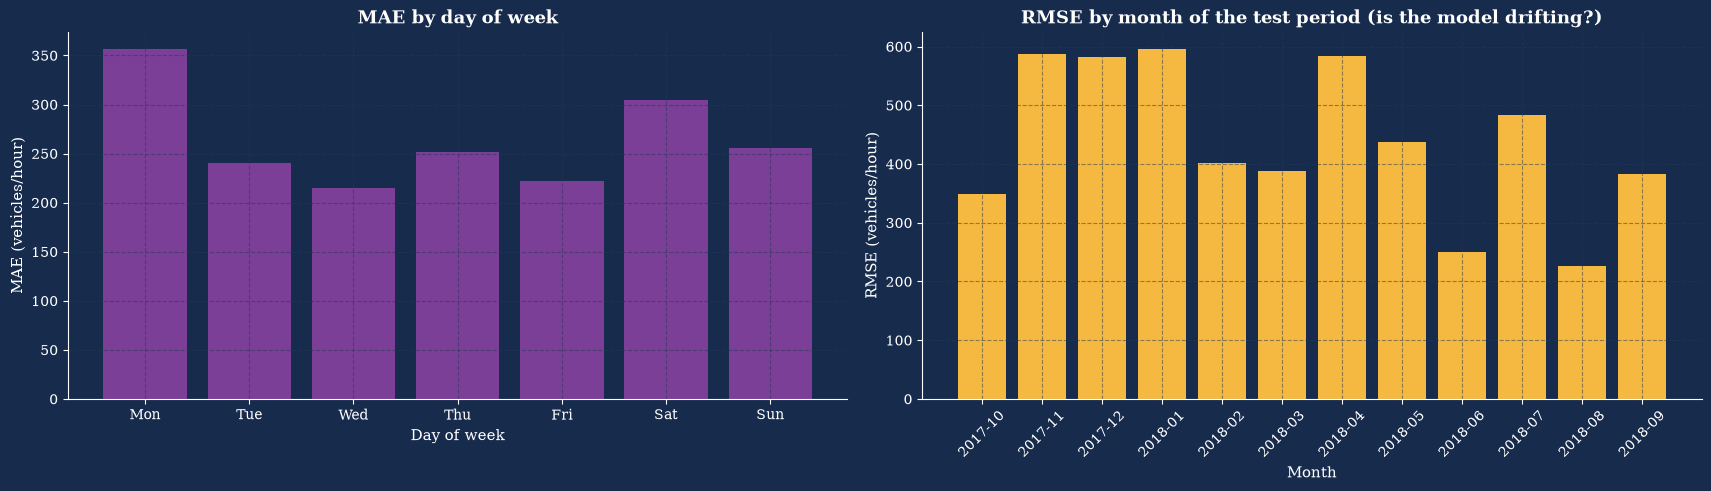

In [205]:
#2
#---2)by day of week and by weekend ----
by_day = error_table(err.assign(day=err["day_of_week"].map(dict(enumerate(DAY_NAMES)))), "day").reindex(DAY_NAMES)
by_weekend = error_table(err.assign(day_type=np.where(err["is_weekend"] == 1, "Weekend", "Weekday")), "day_type")
display(by_day)
display(by_weekend)

# ---- 3) by season and by month ----
by_season = error_table(err, "season").reindex(["Winter", "Spring", "Summer", "Fall"])
display(by_season)

err["month_label"] = err.index.to_period("M").astype(str)
by_month = error_table(err, "month_label")
display(by_month)

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), facecolor=THEME_BG, constrained_layout=True)
axes[0].bar(by_day.index, by_day["MAE"], color=THEME_PURPLE)
style_axes(axes[0], title="MAE by day of week", xlabel="Day of week", ylabel="MAE (vehicles/hour)")
axes[1].bar(by_month.index, by_month["RMSE"], color=THEME_ACCENT)
axes[1].tick_params(axis="x", rotation=45)
style_axes(axes[1], title="RMSE by month of the test period (is the model drifting?)", xlabel="Month",
           ylabel="RMSE (vehicles/hour)")
plt.show()


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<h3>Key Findings from Error Analysis</h3>

<ul>
<li><b>Days of the week:</b> <b>Wednesday</b> has the lowest MAE (214.5), while <b>Wednesday and Friday</b> have the lowest WAPE (5.9%). <b>Monday</b> has the highest MAE (326.9) and WAPE (10.9%).</li>
<li><b>Weekdays vs. weekends:</b> <b>Weekdays</b> have lower MAE (256.8) and WAPE (7.2%) than weekends (280.0 and 10.5%), indicating better predictive accuracy on weekdays.</li>
<li><b>Seasons:</b> <b>Summer</b> has the lowest MAE (195.7) and WAPE (5.8%), while <b>winter</b> has the highest MAE (327.6) and WAPE (10.4%).</li>
<li><b>Months:</b> <b>August 2018</b> has the lowest MAE (165.3) and WAPE (4.8%). <b>December 2017</b> has the highest MAE (374.2) and WAPE (12.0%).</li>
</ul>

</div>



,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
day_type,,,,,,
Federal holiday,216,2323.2,1089.5,1603.8,-954.2,46.9
Other days,7899,3336.5,240.9,388.2,15.2,7.2


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
holiday,,,,,,
Independence Day,24,1917.3,1775.9,2275.7,-1693.9,92.6
Thanksgiving Day,24,2053.0,1559.8,2101.4,-1481.0,76.0
New Year's Day,24,1749.3,1455.9,1874.1,-1222.9,83.2
Christmas Day,24,1889.8,1375.5,1803.6,-1189.1,72.8
Memorial Day,24,2135.6,1243.3,1778.3,-1229.6,58.2
Labor Day,24,2323.8,980.3,1468.0,-917.2,42.2
Washington's Birthday,24,2456.1,784.6,1009.8,-781.0,31.9
"Birthday of Martin Luther King, Jr.",24,2677.2,342.8,548.8,-337.3,12.8
Veterans Day,24,3706.9,287.6,387.1,264.3,7.8


Holiday hours account for 2.7% of test hours but contribute 11.0% of the total absolute error.
RMSE for the full test period: 463.8 | RMSE excluding holiday hours: 388.2


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
weather_group,,,,,,
Clear_Cloudy,5392,3383.8,246.6,422.3,27.2,7.3
Reduced_Visibility,1386,2889.8,346.0,643.5,-156.3,12.0
Light_Rain_Drizzle,745,3489.6,222.4,378.1,-37.4,6.4
Heavy_Rain,162,3494.9,227.5,335.8,-24.5,6.5
Snow_Ice,354,3304.9,310.5,462.5,51.0,9.4
Severe_Storm,76,3562.0,221.7,352.0,-35.5,6.2


,hours,mean_traffic,MAE,RMSE,bias,WAPE (%)
traffic_level,,,,,,
"< 1,000",1784,543.4,123.6,371.4,-96.9,22.7
"1,000 - 3,000",1667,2122.4,343.5,636.4,-179.6,16.2
"3,000 - 5,000",2756,4134.8,289.0,447.7,2.4,7.0
">= 5,000",1908,5741.1,287.6,377.7,198.8,5.0


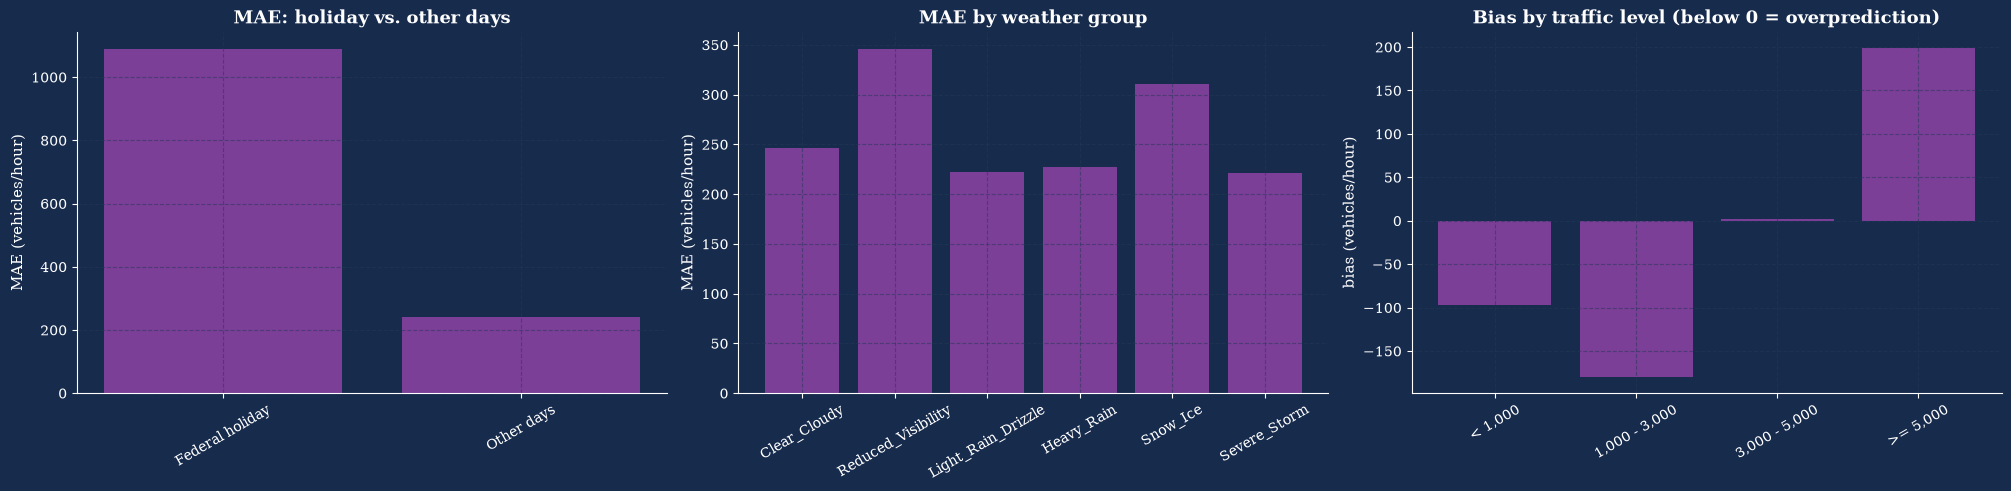

In [206]:

# ---- 4) Holidays (U.S. federal holiday calendar; not a model input) ----
by_holiday = error_table(err.assign(day_type=np.where(err["is_holiday"], "Federal holiday", "Other days")), "day_type")
display(by_holiday)
holiday_days = error_table(err[err["is_holiday"]], "holiday").sort_values("MAE", ascending=False)
display(holiday_days)

holiday_hours_share = 100 * err["is_holiday"].mean()
holiday_error_share = 100 * err.loc[err["is_holiday"], "abs_error"].sum() / err["abs_error"].sum()
rmse_all = np.sqrt((err["residual"] ** 2).mean())
rmse_without_holidays = np.sqrt((err.loc[~err["is_holiday"], "residual"] ** 2).mean())
print(f"Holiday hours account for {holiday_hours_share:.1f}% of test hours but contribute {holiday_error_share:.1f}% of the total absolute error.")
print(f"RMSE for the full test period: {rmse_all:.1f} | RMSE excluding holiday hours: {rmse_without_holidays:.1f}")

# ---- 5) Weather groups (groups from Section 6; not model inputs) ----
by_weather = error_table(err, "weather_group")
display(by_weather)

# ---- 6) Traffic levels (left-inclusive, right-exclusive bins, consistent with the labels) ----
err["traffic_level"] = pd.cut(err["actual"], bins=[0, 1000, 3000, 5000, np.inf], right=False,
                              labels=["< 1,000", "1,000 - 3,000", "3,000 - 5,000", ">= 5,000"])
by_level = error_table(err, "traffic_level")
display(by_level)

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8), facecolor=THEME_BG, constrained_layout=True)
for ax, (table, title) in zip(axes, [(by_holiday, "MAE: holiday vs. other days"),
                                     (by_weather, "MAE by weather group"),
                                     (by_level, "Bias by traffic level (below 0 = overprediction)")]):
    column = "bias" if "Bias" in title else "MAE"
    ax.bar(table.index.astype(str), table[column], color=THEME_PURPLE)
    ax.tick_params(axis="x", rotation=30)
    style_axes(ax, title=title, ylabel=f"{column} (vehicles/hour)")
plt.show()



<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<h3>Key Findings from Error Analysis</h3>

<ul>
<li><b>Holidays:</b> Although holiday hours represent only <b>2.7%</b> of the test data, they account for <b>11.0%</b> of total absolute error. Independence Day has the highest holiday MAE (1,775.9).</li>
<li><b>Weather conditions:</b> <b>Reduced visibility</b> has the highest MAE (346.0) and WAPE (12.0%), while light rain, heavy rain, and severe storms show lower errors in this test set.</li>
<li><b>Traffic levels:</b> <b>Low-traffic hours</b> have the highest relative error (WAPE 22.7%), whereas hours with traffic of at least 5,000 vehicles have the lowest WAPE (5.0%).</li>
<li><b>Overall impact:</b> RMSE decreases from 463.8 to 388.2 when holiday hours are excluded, indicating that holiday periods contribute disproportionately to prediction errors.</li>
</ul>

</div>



,weekday,hour,actual,prediction,error,holiday,weather group
date_time,,,,,,,
2018-07-04 07:00:00,Wed,7,1128,5890.0,-4762.0,Independence Day,Clear_Cloudy
2017-11-23 07:00:00,Thu,7,991,5694.0,-4703.0,Thanksgiving Day,Clear_Cloudy
2017-11-23 06:00:00,Thu,6,834,5214.0,-4380.0,Thanksgiving Day,Clear_Cloudy
2018-05-28 07:00:00,Mon,7,989,5336.0,-4347.0,Memorial Day,Clear_Cloudy
2018-07-04 06:00:00,Wed,6,1141,5465.0,-4324.0,Independence Day,Clear_Cloudy
2018-07-04 08:00:00,Wed,8,1275,5491.0,-4216.0,Independence Day,Clear_Cloudy
2018-01-01 07:00:00,Mon,7,677,4879.0,-4202.0,New Year's Day,Clear_Cloudy
2018-01-01 06:00:00,Mon,6,686,4814.0,-4128.0,New Year's Day,Clear_Cloudy
2018-05-28 06:00:00,Mon,6,882,4955.0,-4073.0,Memorial Day,Clear_Cloudy


Calendar dates with more than one of the 20 largest errors:
date_time
2018-07-04    3
2017-11-23    3
2018-05-28    3
2018-01-01    3
2017-12-25    2
2018-01-22    2
2018-09-03    2

20 of the 20 cases are overpredictions (actual traffic is lower than predicted), and 0 are underpredictions.
16 of the 20 cases fall on federal holidays; these cases occur between 6 and 8. The remaining 4 cases occur on non-holiday days.


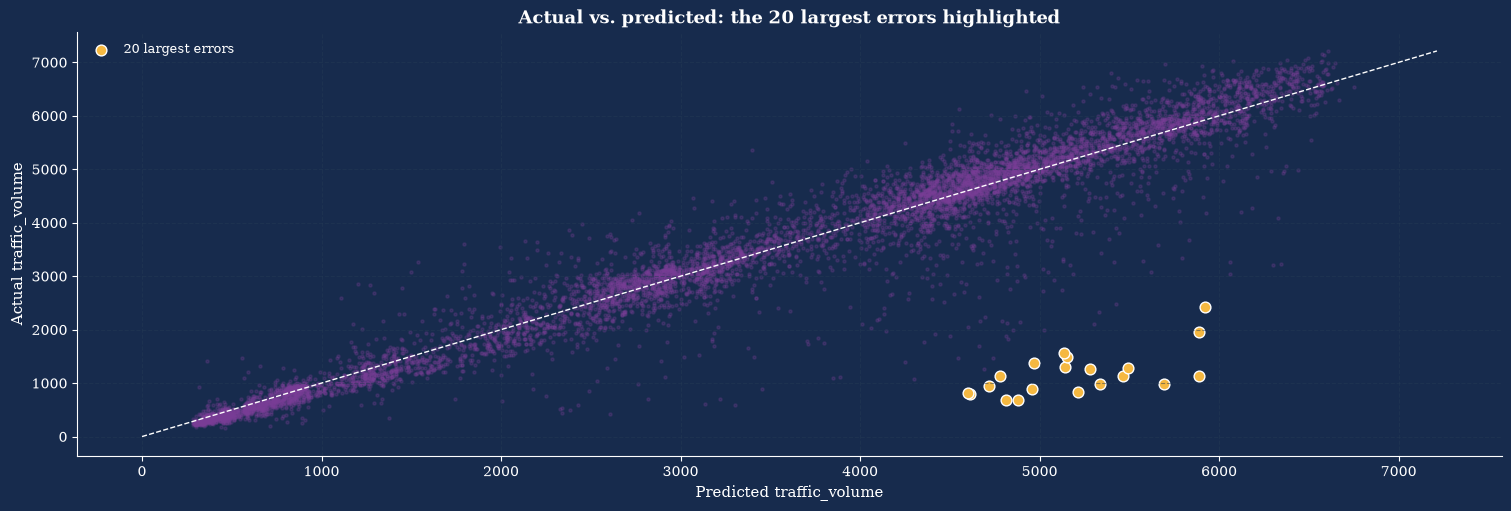

In [207]:

# ---- 7) The 20 largest errors ----
worst = err.reindex(err["abs_error"].sort_values(ascending=False).index).head(20)
worst_table = pd.DataFrame({
    "weekday": worst["day_of_week"].map(dict(enumerate(DAY_NAMES))),
    "hour": worst["hour"],
    "actual": worst["actual"],
    "prediction": worst["prediction"].round(0),
    "error": worst["residual"].round(0),
    "holiday": worst["holiday"],
    "weather group": worst["weather_group"].astype(str),
})
display(worst_table)

days = worst.index.normalize().value_counts()
print("Calendar dates with more than one of the 20 largest errors:")
print(days[days > 1].to_string() if (days > 1).any() else "None")
print(f"\n{int((worst['residual'] < 0).sum())} of the 20 cases are overpredictions (actual traffic is lower than predicted), "
      f"and {int((worst['residual'] > 0).sum())} are underpredictions.")
worst_holiday = worst[worst["is_holiday"]]
print(f"{len(worst_holiday)} of the 20 cases fall on federal holidays; these cases occur between "
      f"{int(worst_holiday['hour'].min())} and {int(worst_holiday['hour'].max())}. "
      f"The remaining {int((~worst['is_holiday']).sum())} cases occur on non-holiday days.")

# ---- Plot: largest errors highlighted among all test hours ----
fig, ax = plt.subplots(figsize=(15, 5), facecolor=THEME_BG, constrained_layout=True)
ax.scatter(err["prediction"], err["actual"], s=5, alpha=0.25, color=THEME_PURPLE)
ax.scatter(worst["prediction"], worst["actual"], s=60, color=THEME_ACCENT, edgecolor="white", label="20 largest errors")
limit = [0, max(err["actual"].max(), err["prediction"].max())]
ax.plot(limit, limit, color="white", lw=1, linestyle="--")
style_axes(ax, title="Actual vs. predicted: the 20 largest errors highlighted",
           xlabel="Predicted traffic_volume", ylabel="Actual traffic_volume")
style_legend(ax)
plt.show()



<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<h3>Key Findings from the 20 Largest Errors</h3>

<ul>
<li><b>Overprediction:</b> All 20 largest errors were overpredictions, meaning actual traffic was lower than predicted.</li>
<li><b>Holiday impact:</b> <b>16 of the 20 largest errors</b> occurred on federal holidays, mainly between 06:00 and 08:00, when normal morning traffic patterns did not apply.</li>
<li><b>Recurring patterns:</b> Multiple large errors occurred on the same dates, particularly Independence Day, Thanksgiving, Memorial Day, and New Year's Day.</li>
</ul>

<p><b style="background:#ffeb7a;">The largest errors suggest that the model struggles to capture unusually low morning traffic during holidays.</b></p>

</div>



<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<h3>Conclusion</h3>

The final Random Forest model achieves an <b>R² of 0.9446, MAE of 263.5, RMSE of 463.8, and WAPE of 8.0%</b> on the test set. Error analysis reveals that performance varies across traffic conditions, with particularly large errors during holidays and low-volume nighttime hours.

<table style="width:100%; border-collapse:collapse; margin:10px 0; font-size:14px;">
<thead><tr style="background:#dbe4ef;"><th style="border:1px solid #b8c2cc; padding:7px; text-align:left;">Area</th><th style="border:1px solid #b8c2cc; padding:7px; text-align:left;">Key finding</th></tr></thead>
<tbody>
<tr><td style="border:1px solid #b8c2cc; padding:7px;"><b>Federal holidays</b></td><td style="border:1px solid #b8c2cc; padding:7px;">Holiday hours account for 2.7% of test hours but contribute 11.0% of total absolute error; holiday WAPE is 46.9%, compared with 7.2% on other days.</td></tr>
<tr><td style="border:1px solid #b8c2cc; padding:7px;"><b>Largest errors</b></td><td style="border:1px solid #b8c2cc; padding:7px;">All 20 largest errors are overpredictions, and 16 occur on federal holidays, mainly between 06:00 and 08:00.</td></tr>
<tr><td style="border:1px solid #b8c2cc; padding:7px;"><b>Time of day</b></td><td style="border:1px solid #b8c2cc; padding:7px;">Absolute errors peak at 07:00 and 16:00, while relative error is highest at 02:00 (WAPE 21.8%).</td></tr>
<tr><td style="border:1px solid #b8c2cc; padding:7px;"><b>Weekdays and seasons</b></td><td style="border:1px solid #b8c2cc; padding:7px;">Weekdays have lower WAPE than weekends (7.2% vs. 10.5%). Summer has the lowest seasonal error (WAPE 5.8%), while winter has the highest (10.4%).</td></tr>
<tr><td style="border:1px solid #b8c2cc; padding:7px;"><b>Weather</b></td><td style="border:1px solid #b8c2cc; padding:7px;">Reduced visibility has the highest error among weather groups, with MAE 346.0 and WAPE 12.0%.</td></tr>
<tr><td style="border:1px solid #b8c2cc; padding:7px;"><b>Traffic volume</b></td><td style="border:1px solid #b8c2cc; padding:7px;">Relative error is highest below 1,000 vehicles (WAPE 22.7%). The model tends to overpredict low traffic and underpredict traffic of 5,000 vehicles or more.</td></tr>
</tbody>
</table>

<p><b style="background:#ffeb7a;">Overall, the model performs well under typical conditions, but holiday traffic patterns are its clearest weakness.</b> Further evaluation of holiday-specific features and unusual traffic patterns using time-based validation could help determine whether these errors can be reduced.</p>

</div>


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.7 — Interpretation for a Non-Technical Reader</h3></div>


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.7 — Interpretation for a Non-Technical Reader</div>

<ul style="margin:0; padding-left:20px;">
<li style="margin-bottom:7px;"><b>How accurate is it?</b> On unseen test data, the final Random Forest model has an average absolute error of about <b>263.5 vehicles per hour</b>, with a WAPE of approximately <b>8.0%</b> and an R² of <b>0.9446</b>. Its predictions are generally close to observed traffic, although accuracy varies across conditions.</li>

<li style="margin-bottom:7px;"><b>What does it learn?</b> Traffic volume follows strong daily and weekly patterns. Time-of-day and commuting features account for <b>77.45%</b> of grouped mean absolute SHAP importance, followed by weekday and weekend patterns at <b>13.92%</b>. Weather-related features have a comparatively smaller contribution to the model's predictions.</li>

<li style="margin-bottom:7px;"><b>How does it compare with other models?</b> The final Random Forest achieves an RMSE of <b>463.8</b>, compared with <b>497.8</b> for the weekday-and-hour average baseline, a reduction of approximately <b>6.8%</b>. Compared with the best linear regression model (V4), it reduces RMSE by approximately <b>23.2%</b> and MAE by <b>38.1%</b>, indicating a substantial improvement in prediction accuracy.</li>

<li style="margin-bottom:7px;"><b>When should its predictions be treated cautiously?</b> Federal holidays are the clearest weakness: holiday hours account for <b>2.7%</b> of test hours but contribute <b>11.0%</b> of total absolute error. All 20 largest errors are overpredictions, and 16 occur on federal holidays, mainly between 06:00 and 08:00. Relative errors are also higher during low-traffic hours (WAPE <b>22.7%</b> below 1,000 vehicles) and under reduced visibility (WAPE <b>12.0%</b>).</li>
</ul>

<p style="margin:10px 0 0 0;"><b style="background:#ffeb7a;">Overall, the model captures routine traffic patterns well, but holiday-related traffic changes remain a major challenge.</b> Further investigation of holiday-specific patterns and unusual traffic conditions, using time-based validation, could help determine whether these errors can be reduced.</p>

</div>



<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.8 — Limitations</h3></div>


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.8 — Limitations</div>

<ul style="margin:0; padding-left:20px;">
<li style="margin-bottom:4px;"><b>Missing hours:</b> Approximately 22.8% of the expected hours are missing, including a gap of about 10 months. No lag features were used, so the model cannot directly use traffic from previous hours.</li>

<li style="margin-bottom:4px;"><b>Single, outdated location:</b> The data cover one counting station and direction and end in September 2018. Results may not generalize to other locations or current traffic patterns.</li>

<li style="margin-bottom:4px;"><b>Limited test coverage:</b> The test period spans about 11 months, with few examples of some holidays and severe weather conditions. Results for these groups should therefore be interpreted cautiously.</li>

<li style="margin-bottom:4px;"><b>Holiday-label quality:</b> Holiday labels need to be reviewed and corrected to ensure that holidays are accurately identified. Incorrect or incomplete labels can affect error analysis and limit the model's ability to learn holiday-specific traffic patterns.</li>

<li style="margin-bottom:4px;"><b>Long-term changes:</b> Tree-based models cannot reliably extrapolate long-term traffic trends beyond the patterns represented in the training data.</li>

<li style="margin-bottom:4px;"><b>Excluded inputs and unexpected events:</b> Holiday information and detailed weather labels were not used as model inputs. Accidents, road closures and other unexpected events were not explicitly represented, making it difficult for the model to account for unusual traffic conditions.</li>

<li style="margin-bottom:4px;"><b>Sensor failures and sudden drops:</b> A sudden drop in recorded traffic could indicate a sensor malfunction rather than a genuine change in traffic volume. A dedicated sensor-failure flag would have been more reliable than inferring possible road closures or other explanations without supporting evidence. However, distinguishing sensor failures from genuine traffic changes requires appropriate detection rules or external validation.</li>

<li style="margin-bottom:4px;"><b>Test-set reuse:</b> Although the data were split chronologically, test-set results were examined across multiple models and analyses. Therefore, the test metrics should not be treated as a fully independent final estimate of performance. A stronger final evaluation would use a separate holdout period that was not used for model selection or repeated comparisons.</li>
</ul>

</div>


<div style="text-align: center; background: linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding: 10px 15px; border-radius: 10px; box-shadow: 0 5px 15px rgba(20, 25, 70, 0.35); font-family: 'Segoe UI', sans-serif; margin: 26px 0 12px 0;"><h3 style="color: #D8D6FF; font-family: 'Georgia', serif; font-weight: bold; margin: 0; letter-spacing: 1px;">10.9 — Recommendations and Next Steps</h3></div>


<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.9 — Recommendations and Next Steps</div>

<ul style="margin:0; padding-left:20px;">
<li style="margin-bottom:7px;"><b>Improve data quality and holiday labels:</b> Review and correct holiday labels, then evaluate a holiday indicator as an additional model feature. Holidays account for 2.7% of test hours but approximately 11% of total absolute error.</li>

<li style="margin-bottom:7px;"><b>Detect sensor anomalies and unexpected events:</b> Develop rules to flag suspicious sudden drops in recorded traffic and distinguish potential sensor failures from genuine traffic changes. Avoid attributing anomalies to road closures or other events without supporting evidence.</li>

<li style="margin-bottom:7px;"><b>Explore temporal features:</b> Test lag features, such as traffic one hour and 24 hours earlier, where continuous historical observations are available and the features can be generated without using future information.</li>

<li style="margin-bottom:7px;"><b>Investigate difficult prediction conditions:</b> Evaluate model performance separately for holidays, low-volume hours, reduced visibility and winter conditions. Test additional weather features with tree-based models to determine whether they improve performance on these subsets.</li>

<li style="margin-bottom:7px;"><b>Improve uncertainty assessment:</b> Estimate prediction intervals so that users can understand when predictions are less reliable, particularly during holidays and unusual traffic conditions.</li>

<li style="margin-bottom:7px;"><b>Strengthen validation:</b> Use a separate, untouched holdout period and, if data are available, additional counting stations to evaluate performance over time and across locations.</li>
</ul>

</div>


<div style="text-align:center; background:linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding:10px 15px; border-radius:10px; box-shadow:0 5px 15px rgba(20,25,70,0.35); font-family:'Segoe UI',sans-serif; margin:26px 0 12px 0;"><h3 style="color:#D8D6FF; font-family:'Georgia',serif; font-weight:bold; margin:0; letter-spacing:1px;">10.10 — Final Conclusion</h3></div>




<div style="text-align:center; background:linear-gradient(90deg, #0B1F3A, #243B73, #4B3F8F); padding:10px 15px; border-radius:10px; box-shadow:0 5px 15px rgba(20,25,70,0.35); font-family:'Segoe UI',sans-serif; margin:26px 0 12px 0;">
<h3 style="color:#D8D6FF; font-family:'Georgia',serif; font-weight:bold; margin:0; letter-spacing:1px;">10.10 — Final Conclusion</h3>
</div>

<div style="box-sizing:border-box; width:98%; background:#eef2f7; border:1px solid #b8c2cc; border-left:5px solid #1e3a5f; border-radius:8px; padding:14px 24px 14px 18px; margin:10px 0 16px 0; box-shadow:0 2px 6px rgba(0,0,0,0.08); font-family:'Segoe UI',sans-serif; color:#1f2937; direction:ltr; text-align:left; line-height:1.55; overflow-wrap:break-word;">

<div style="font-size:1.12em; font-weight:700; color:#1e3a5f; margin-bottom:10px;">10.10 — Final Conclusion</div>

<p style="margin:0 0 8px 0;"><b>Summary:</b> An hourly traffic forecasting model was developed for the Metro Interstate (I-94) dataset using <b>25 features</b> and a chronological split of <b>32,460 training hours</b> and <b>8,115 test hours</b>. Random Forest, XGBoost and LightGBM were tuned and compared using time-series cross-validation. <b>Random Forest was selected as the final model</b> because it achieved the lowest cross-validation RMSE, although the differences between the three models were small.</p>

<p style="margin:0 0 8px 0;"><b>Performance:</b> On the held-out test set, Random Forest achieved an <b>R² of <span style="background:#ffeb7a;">0.9446</span></b>, an <b>RMSE of <span style="background:#ffeb7a;">463.8</span></b> vehicles per hour, an <b>MAE of <span style="background:#ffeb7a;">263.5</span></b> vehicles per hour and a <b>WAPE of <span style="background:#ffeb7a;">8.0%</span></b>. These results indicate strong predictive performance on the test set. Its RMSE was approximately <b>6.8% lower</b> than that of the weekday-and-hour average baseline and <b>23.2% lower</b> than that of the best linear regression model (V4). Its MAE was also approximately <b>38.1% lower</b> than V4.</p>

<p style="margin:0 0 8px 0;"><b>Main findings:</b> Time-related features dominate the model's predictions, accounting for approximately <b>77.45%</b> of grouped mean absolute SHAP importance, followed by weekday and weekend features at <b>13.92%</b>. Federal holidays account for approximately <b>2.7% of test hours but 11% of total absolute error</b>. All 20 largest errors were overpredictions, with 16 occurring on federal holidays, mainly between 06:00 and 08:00. Low-volume periods and reduced visibility also present challenges, with WAPE values of <b>22.7%</b> below 1,000 vehicles and <b>12.0%</b> under reduced visibility.</p>

<p style="margin:10px 0 0 0;"><b>Conclusion:</b> <b style="background:#ffeb7a;">The model captures routine traffic patterns well, but its predictions are less reliable when traffic deviates from typical patterns.</b> Improving holiday labels, identifying potential sensor failures, and evaluating additional temporal features are practical next steps. Further validation on an independent time period would help establish how reliably the model generalizes to unseen traffic conditions.</p>

</div>
